# CSCI 7090 — V3.4.7 Phase B on Google Colab
### Automated extraction of data tables from vertical bar charts (Benetech "Making Graphs Accessible")

**What this notebook is.** The successor to `V3_4_6_CSCI7090_T4_Recovery_and_Matched_Comparison.ipynb`, which ran
Phase A (model selection) on the university's Windows T4 machine. Phase A chose **MatCha** over DePlot
(strict Benetech score 0.915 vs 0.697 on 64 validation charts). V3.4.6 is kept unchanged as the record of that work.

**What this notebook adds (Phase B, promised at the midterm):**
1. Answers to the professor's five midterm comments (zero-shot reference, second seed, zero-score analysis,
   content leakage check, real charts as the deciding evidence).
2. Full MatCha training on a professor-approved 3,500-chart subset, with early stopping.
3. An OpenCV + Tesseract OCR baseline.
4. One final run on the held-out test set (525 charts), generated and real charts reported separately.

**Why Colab.** The university VM disconnects after 10–15 idle minutes and its D: drive is temporary.
Colab runs on Google's GPUs, and everything that must survive is written straight to Google Drive.

**How to run it.** Run the cells top to bottom. If Colab disconnects, reconnect and run again from the top.
Every step checks what is already done and skips or resumes it, so nothing is lost or repeated.
Every step's printed output (and any error) is also appended to a run report file on Google Drive.

## Step 1 — Colab setup: Drive, packages, code, data, GPU and self-tests

This step builds the whole working environment from scratch, because a Colab machine starts empty every session.
It has six parts:

| Part | What it does | Why |
|---|---|---|
| 1a | Connect Google Drive and set every path | One place to change paths; nothing else in the notebook hard-codes a path |
| 1b | Install Tesseract, pytesseract, imagehash and the library versions from the midterm | Same software as Phase A, plus the tools the OCR baseline and leakage check need |
| 1c | Copy the V3.4.6 code and prove it is unchanged | The pipeline code that produced the midterm results is reused, byte for byte |
| 1d | Copy the dataset to the Colab disk and verify it | Reading 1 GB from local disk is much faster than reading thousands of files from Drive |
| 1e | Check the GPU | Training must not start on a machine without a working GPU |
| 1f | Run the 100 self-tests | Proves the scoring and pipeline code still behave exactly as at the midterm |

### 1a — Connect Google Drive and set the paths

**What happens.** Colab asks for permission to read your Google Drive, then the Drive appears as a folder at
`/content/drive/MyDrive`. The cell then defines every path the notebook uses.

**Two kinds of storage:**
* **Google Drive** (`DRIVE_ROOT`) is permanent. The original data stays here untouched, and all results,
  checkpoints and the run report are saved to `V3_4_7_work` here so they survive a disconnect.
* **Colab local disk** (`LOCAL_ROOT = /content/csci7090`) is fast but is erased when the session ends.
  It holds working copies of the code and data only.

**Expected output:** the list of paths and `Drive folder found`.

**Output banners.** Every code cell starts its output with an orange **▶ OUTPUT · step** line, so results are easy to tell apart from code (defined here as `output_banner`).

In [6]:
!nvidia-smi

Sat Nov  7 05:43:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
print(1)

1


In [1]:
# Output banner: a large bold line at the top of every code cell's output, so results never look like code
from IPython.display import HTML, display
def output_banner(title):
    display(HTML('<div style="border-top:3px solid #e67e22; margin:6px 0 10px; padding-top:6px; '
                 'font-size:20px; font-weight:bold; color:#e67e22;">&#9654; OUTPUT &middot; ' + title + '</div>'))

output_banner("1a Drive and paths")

from pathlib import Path
import os, sys, json, time

RELEASE     = "3.4.7"
RELEASE_TAG = "V3_4_7"

from google.colab import drive
drive.mount("/content/drive")

# ---- Google Drive (permanent). Edit paths here only. ----
DRIVE_ROOT   = Path("/content/drive/MyDrive/Working-Final Presentation and report")
DATA_DRIVE   = DRIVE_ROOT / "BenetechData"
KAGGLE_ZIP_DRIVE = DATA_DRIVE / "benetech-making-graphs-accessible.zip"
SPLITS_DRIVE = DATA_DRIVE / "Project Vertical Bar Graphs"            # frozen splits from V3.3.2 (seed 42)
PILOT_BUNDLE_DRIVE = SPLITS_DRIVE / "V3.3.2_pilot_model_selection" / "2026-10-12_20-21-23" / "V3.3.2_pilot_bundle.zip"
CODE_ZIP_NAME = "V3_4_6-Code.zip"                                    # midterm code release, reused unchanged

WORK_DRIVE   = DRIVE_ROOT / f"{RELEASE_TAG}_work"                    # everything this notebook produces
RESULTS_DIR  = WORK_DRIVE / "results"
CKPT_DIR     = WORK_DRIVE / "checkpoints"
REPORT_FILE  = RESULTS_DIR / f"run_report_{RELEASE_TAG}.txt"

# ---- Colab local disk (fast, erased at the end of each session) ----
LOCAL_ROOT   = Path("/content/csci7090")
LOCAL_CODE   = LOCAL_ROOT / "code" / "V3_4_6"
LOCAL_DATA   = LOCAL_ROOT / "data"
KAGGLE_ZIP   = LOCAL_DATA / KAGGLE_ZIP_DRIVE.name
PILOT_BUNDLE = LOCAL_DATA / PILOT_BUNDLE_DRIVE.name
SPLIT_FILES  = {s: LOCAL_DATA / f"{s}_vertical.csv" for s in ("train", "validation", "test")}
HF_CACHE_DIR = LOCAL_ROOT / "cache" / "hf"                           # model downloads; re-downloadable

assert DRIVE_ROOT.is_dir(), f"Drive folder not found: {DRIVE_ROOT}"
for p in (RESULTS_DIR, CKPT_DIR, LOCAL_CODE, LOCAL_DATA, HF_CACHE_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Drive folder found:", DRIVE_ROOT)
for name in ("KAGGLE_ZIP_DRIVE", "SPLITS_DRIVE", "PILOT_BUNDLE_DRIVE", "WORK_DRIVE", "LOCAL_ROOT"):
    print(f"  {name:20s} {globals()[name]}")

Mounted at /content/drive
Drive folder found: /content/drive/MyDrive/Working-Final Presentation and report
  KAGGLE_ZIP_DRIVE     /content/drive/MyDrive/Working-Final Presentation and report/BenetechData/benetech-making-graphs-accessible.zip
  SPLITS_DRIVE         /content/drive/MyDrive/Working-Final Presentation and report/BenetechData/Project Vertical Bar Graphs
  PILOT_BUNDLE_DRIVE   /content/drive/MyDrive/Working-Final Presentation and report/BenetechData/Project Vertical Bar Graphs/V3.3.2_pilot_model_selection/2026-10-12_20-21-23/V3.3.2_pilot_bundle.zip
  WORK_DRIVE           /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work
  LOCAL_ROOT           /content/csci7090


### 1b — Install packages and pin the midterm library versions

**What happens.**
* **Tesseract** is the OCR engine for the baseline (reads axis numbers and bar labels). It is a system program,
  so it is installed with `apt`; `pytesseract` is the Python wrapper.
* **imagehash** computes perceptual hashes (a short fingerprint of how an image looks) for the leakage check in Step 2.
* **OpenCV** (bar detection for the baseline) and **matplotlib** come preinstalled on Colab.
* `transformers`, `accelerate` and `tokenizers` are pinned to the exact versions used for the midterm results,
  so MatCha's tokenizer and generation behave the same way.

**Why PyTorch is not pinned.** Colab's PyTorch is built for Colab's GPU drivers; replacing it can break the GPU.
Its version is recorded in 1e instead. This is one reason the seed-42 pilot is re-run on Colab (Step 4):
it gives a same-platform reference for the seed-100 comparison.

**Expected output:** the installed versions and `Package setup OK`. If it says *restart the runtime*,
use Runtime → Restart session, then run the notebook again from the top (the second run skips the installs).

In [9]:
output_banner("1b packages")

import subprocess, importlib.metadata as im

PINNED = {"transformers": "5.18.0", "accelerate": "1.15.0", "tokenizers": "0.23.3"}
EXTRA  = ["pytesseract", "imagehash"]

def _version(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return None

# Tesseract (system program, needed by the OCR baseline)
if subprocess.run(["which", "tesseract"], capture_output=True).returncode != 0:
    subprocess.run(["apt-get", "-qq", "install", "-y", "tesseract-ocr"], check=True)

to_install = [f"{p}=={v}" for p, v in PINNED.items() if _version(p) != v]
to_install += [p for p in EXTRA if _version(p) is None]
if to_install:
    print("Installing:", " ".join(to_install))
    # keep Colab's own PyTorch: a constraint file stops pip from replacing it as a dependency
    Path("/content/keep_torch.txt").write_text(f"torch=={_version('torch')}\n")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-c", "/content/keep_torch.txt", *to_install], check=True)

need_restart = bool(to_install) and "transformers" in sys.modules
versions = {p: _version(p) for p in ["torch", *PINNED, *EXTRA, "opencv-python", "opencv-python-headless", "matplotlib"]}
versions["tesseract"] = subprocess.run(["tesseract", "--version"], capture_output=True, text=True).stdout.splitlines()[0]
for k, v in versions.items():
    print(f"  {k:24s} {v}")

wrong = {p: _version(p) for p, v in PINNED.items() if _version(p) != v}
assert not wrong, f"Pinned versions not installed: {wrong}"
if need_restart:
    print("\nRESTART THE RUNTIME NOW (Runtime -> Restart session), then run from the top.")
else:
    print("\nPackage setup OK")

Installing: transformers==5.18.0 pytesseract imagehash
  torch                    2.14.1+cu130
  transformers             5.18.0
  accelerate               1.15.0
  tokenizers               0.23.3
  pytesseract              0.3.13
  imagehash                4.3.2
  opencv-python            5.0.0.93
  opencv-python-headless   5.0.0.93
  matplotlib               3.10.0
  tesseract                tesseract 5.3.4

Package setup OK


### 1c — Copy the V3.4.6 code and prove it is unchanged

**What happens.** The cell finds `V3_4_6-Code.zip` (the code submitted for the midterm) in the Drive folder,
unpacks it to the Colab disk, and compares every Python file with the SHA-256 checksums recorded when the
release was made. A checksum is a 64-character fingerprint of a file's bytes: if even one character changed,
the fingerprint would not match.

**Files reused:**
* `chart_eval.py` — parses predicted tables and computes the Benetech score.
* `t4_pipeline.py` — loading data, training, generation, checkpoints, run report.
* `test_chart_eval.py`, `test_t4_pipeline_cpu.py`, `_v332_metric_original.py` — the self-tests run in 1f.

The Windows launcher (`.bat`) is not used on Colab.

**Expected output:** `Code release intact: 5 Python files match SHA256SUMS.txt`.

In [10]:
output_banner("1c code checksum")

import zipfile, shutil

code_zips = sorted(DRIVE_ROOT.rglob(CODE_ZIP_NAME))
assert code_zips, (f"{CODE_ZIP_NAME} not found under {DRIVE_ROOT}. "
                   f"Upload it to that folder (any subfolder works) and re-run this cell.")
print("Code zip:", code_zips[0])

if not (LOCAL_CODE / "t4_pipeline.py").is_file():
    with zipfile.ZipFile(code_zips[0]) as z:
        z.extractall(LOCAL_CODE)
    # the zip may hold the files in a subfolder; move them up one level if so
    inner = [p for p in LOCAL_CODE.rglob("t4_pipeline.py")]
    if inner and inner[0].parent != LOCAL_CODE:
        for f in inner[0].parent.iterdir():
            shutil.move(str(f), LOCAL_CODE / f.name)

if str(LOCAL_CODE) not in sys.path:
    sys.path.insert(0, str(LOCAL_CODE))
import t4_pipeline as tp

problems = tp.verify_release_checksums(LOCAL_CODE, only_suffixes=[".py"])
assert not problems, f"Code release check FAILED: {problems}"
n_py = len(list(LOCAL_CODE.glob("*.py")))
print(f"Code release intact: {n_py} Python files match SHA256SUMS.txt")
tp.configure_environment(str(HF_CACHE_DIR))

Code zip: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_6-Code.zip
Code release intact: 5 Python files match SHA256SUMS.txt


{'HF_HOME': '/content/csci7090/cache/hf'}

### 1d — Copy the dataset to the Colab disk and verify it

**What happens.**
1. Copies three things from Drive to the Colab disk: the full Kaggle zip (1.03 GB, about 1–3 minutes),
   the three frozen split files, and the 386-chart pilot bundle from Phase A. If a file is already there
   with the right size, it is not copied again.
2. **Checks that the splits are the frozen ones.** Each split file's checksum must match the value recorded on
   Nov 5, 2026. This proves the train/validation/test assignment is the same as at the midterm (made in V3.3.2
   with seed 42), so no test chart can have moved into training.
3. **Counts the charts.** Train 13,432 (320 real), validation 2,878 (68 real), test 2,879 (69 real).
   "Real" means `source = extracted`: charts taken from real documents, as opposed to computer-generated ones.
   All 457 real charts are kept in the 3,500-chart subset (Step 3).
4. **Checks the splits do not overlap** (no chart ID in two splits) and that every image and annotation file
   the splits name is actually inside the Kaggle zip.

**Expected output:** a table of charts per split, `Splits are the frozen V3.3.2 splits`, and `Dataset verified`.

In [11]:
output_banner("1d dataset")

import pandas as pd

FROZEN_SPLITS = {   # SHA-256 of the split files, recorded Nov 5 2026 (V3.3.2 split, seed 42)
    "train":      "6a258116eeff5f9ae43ee0abbfce2b51b37a4f4cbffdb894f173f6ce9b6b944f",
    "validation": "340934edb1cd842347bb6c12573199d17ad232a1fd1779e744f3fa180e05e26d",
    "test":       "c55b6e8933614a6dce1e76cb1df75cd41b50c464a221a932a9e27533604910cf",
}
EXPECTED = {"train": (13432, 320), "validation": (2878, 68), "test": (2879, 69)}   # (charts, real charts)

def copy_if_needed(src, dst):
    if dst.is_file() and dst.stat().st_size == src.stat().st_size:
        return "already on local disk"
    t0 = time.time()
    shutil.copy2(src, dst)
    return f"copied in {time.time() - t0:.0f} s"

with tp.step_log(REPORT_FILE, "Step 1d - copy and verify the dataset"):
    print("Kaggle zip  :", copy_if_needed(KAGGLE_ZIP_DRIVE, KAGGLE_ZIP))
    print("Pilot bundle:", copy_if_needed(PILOT_BUNDLE_DRIVE, PILOT_BUNDLE))
    for s, dst in SPLIT_FILES.items():
        copy_if_needed(SPLITS_DRIVE / dst.name, dst)

    # 1. frozen splits
    changed = [s for s, f in SPLIT_FILES.items() if tp.file_sha256(f) != FROZEN_SPLITS[s]]
    assert not changed, f"Split files differ from the frozen splits: {changed}"
    print("Splits are the frozen V3.3.2 splits (checksums match)")

    # 2. counts
    splits = {s: pd.read_csv(f) for s, f in SPLIT_FILES.items()}
    rows = []
    for s, df in splits.items():
        n, n_real = len(df), int((df["source"] == "extracted").sum())
        rows.append({"split": s, "charts": n, "generated": n - n_real, "real (extracted)": n_real})
        assert (n, n_real) == EXPECTED[s], f"{s}: expected {EXPECTED[s]}, found {(n, n_real)}"
    summary = pd.DataFrame(rows)
    summary.loc[len(summary)] = ["total", summary.charts.sum(), summary.generated.sum(), summary["real (extracted)"].sum()]
    display(summary)

    # 3. no overlap, and every file is in the zip
    ids = {s: set(df["chart_id"]) for s, df in splits.items()}
    for a, b in (("train", "validation"), ("train", "test"), ("validation", "test")):
        assert not ids[a] & ids[b], f"{len(ids[a] & ids[b])} chart IDs are in both {a} and {b}"
    print("No chart ID appears in two splits")
    with zipfile.ZipFile(KAGGLE_ZIP) as z:
        members = set(z.namelist())
    needed = set(pd.concat(splits.values())[["image_member", "annotation_member"]].values.ravel())
    missing = sorted(needed - members)
    assert not missing, f"{len(missing)} files missing from the Kaggle zip, e.g. {missing[:3]}"
    print(f"All {len(needed):,} image and annotation files are in the Kaggle zip")
    print("Dataset verified")

Kaggle zip  : copied in 34 s
Pilot bundle: copied in 3 s
Splits are the frozen V3.3.2 splits (checksums match)


,split,charts,generated,real (extracted)
0,train,13432,13112,320
1,validation,2878,2810,68
2,test,2879,2810,69
3,total,19189,18732,457


No chart ID appears in two splits
All 38,378 image and annotation files are in the Kaggle zip
Dataset verified


### 1e — Check the GPU

**What happens.** Confirms PyTorch can see a GPU, records which GPU Colab assigned (T4, L4 or A100 depending on
availability), how much memory is free, and runs a real matrix multiplication on the GPU in full and half
precision, checked against the same calculation on the CPU. Training uses half precision (fp16), so it must be accurate.

**Expected output:** the GPU name and memory, `fp16_ok True`, and `GPU READY`. If Colab gave you a CPU-only
machine, choose Runtime → Change runtime type → GPU and run again from the top. Steps 2 and 3 do not need a GPU.

In [7]:
output_banner("1e GPU")

with tp.step_log(REPORT_FILE, "Step 1e - GPU check"):
    env = tp.environment_report(RESULTS_DIR / "environment_report.json")
    for k in ("python", "torch", "torch_cuda_build", "transformers", "accelerate", "tokenizers",
              "gpu_name", "gpu_total_GiB", "gpu_free_GiB_now", "fp16_ok", "bf16_supported"):
        print(f"  {k:20s} {env.get(k)}")
    print("\nGPU READY" if env.get("READY_FOR_GPU_WORK") else
          "\nNO WORKING GPU: Steps 2-3 can run; switch to a GPU runtime before Step 4.")

  python               3.13.16
  torch                2.11.0+cu130
  torch_cuda_build     13.0
  transformers         5.18.0
  accelerate           1.15.0
  tokenizers           0.23.3
  gpu_name             Tesla T4
  gpu_total_GiB        14.56
  gpu_free_GiB_now     14.46
  fp16_ok              True
  bf16_supported       True

GPU READY


### 1f — Run the 100 self-tests

**What happens.** Runs the same 100 automated tests that passed on the university T4 before the midterm results
were produced. They check, among other things, that:
* tables written with the `<0x0A>` row separator (how MatCha and DePlot output a new row) are parsed correctly,
* the Benetech score gives 0 when the row count is wrong and matches the official formula otherwise,
* the pilot manifests are the right size, have no overlapping charts, and every file exists.

Five of the tests read the real pilot bundle, so the cell points them at it. Every test must pass with none skipped.

**Expected output:** `Ran 100 tests ... OK` and `Self-tests passed: 100 run, 0 skipped`.

In [8]:
output_banner("1f self-tests")

import unittest, importlib

with tp.step_log(REPORT_FILE, "Step 1f - self-tests"):
    os.environ["CSCI7090_BUNDLE"] = str(PILOT_BUNDLE)        # the 5 real-data tests read the pilot bundle
    import _v332_metric_original, test_chart_eval, test_t4_pipeline_cpu
    for m in (_v332_metric_original, test_chart_eval, test_t4_pipeline_cpu):
        importlib.reload(m)
    suite = unittest.TestSuite()
    for m in (test_chart_eval, test_t4_pipeline_cpu):
        suite.addTests(unittest.defaultTestLoader.loadTestsFromModule(m))
    res = unittest.TextTestRunner(stream=sys.stdout, verbosity=1).run(suite)
    ok = res.wasSuccessful() and not res.skipped
    tp.write_gate(RESULTS_DIR, "self_tests", ok, tests_run=res.testsRun, failures=len(res.failures),
                  errors=len(res.errors), skipped=len(res.skipped))
    assert res.wasSuccessful(), "Self-tests failed - do not continue until fixed."
    assert not res.skipped, "Some tests were skipped - the pilot bundle path is wrong."
    print(f"Self-tests passed: {res.testsRun} run, 0 skipped")

.............................................................
[label inventory] charts with newline or '|' in a label (all reconstructed exactly):
   train      train/annotations/3a4e040cc3e4.json  newline-labels=3 pipe-labels=0
   diagnostic train/annotations/c78cdc509d76.json  newline-labels=1 pipe-labels=0
   diagnostic train/annotations/0aa21c0d8302.json  newline-labels=12 pipe-labels=0
......No checkpoint-* folders found in /tmp/tmptmvcuq6i/r
..Manifests verified: sizes, source counts, uniqueness, disjointness, members present.
  train                  n= 256  {'generated': 250, 'extracted': 6}
  validation             n=  64  {'generated': 62, 'extracted': 2}
  extracted_diagnostic   n=  66  {'extracted': 66}
.Manifests verified: sizes, source counts, uniqueness, disjointness, members present.
  train                  n= 256  {'generated': 250, 'extracted': 6}
  validation             n=  64  {'generated': 62, 'extracted': 2}
  extracted_diagnostic   n=  66  {'extracted': 66}
...

**Step 1 done.** At this point the Colab machine has the same code as the midterm (checksums match), the frozen
splits (checksums match), the full dataset on fast local disk, a working GPU, and all 100 self-tests passing.
Results and the run report are on Google Drive in `V3_4_7_work`.

## Step 2 — Content leakage check (professor's comment #3)

**The professor's comment:** *"Replace the ID-overlap leakage check with a content check (duplicate tables,
same-source real charts)."*

**Why it matters.** Leakage means the model has, in effect, already seen a test chart during training.
The midterm check only proved that no chart **ID** is in two splits. But two charts with different IDs can still
hold the same data table, or be the same picture saved twice, or come from the same original document.
If one is in training and the other in test, the test score would be too optimistic.

**What we keep and what we add.** The ID check stays (it is cheap and still true), and four content checks are added.
All of them run on the **full** frozen splits (19,189 charts), before the 3,500-chart subset is drawn in Step 3,
so anything removed here can never end up in the subset.

| Check | What counts as a match | Charts compared |
|---|---|---|
| 1. Chart ID | same `chart_id` | all |
| 2. Duplicate tables | same x labels and same y values (rounded to 6 significant digits) | all |
| 3. Near-duplicate images | perceptual hashes differ in at most 4 of 64 bits | all |
| 4. Same-source real charts | same chart title, or same x labels and axis titles, or images within 4 bits (pairs within 10 bits are shown for review) | the 457 real charts |

**Decision rule, fixed before looking at the results.** A pair of charts in **different** splits is a leak if
checks 1 or 2 match, or if check 3 matches **and** the two charts also share their x labels (so two different charts
that merely look alike are not removed). Real pairs (check 4) are leaks if they share a title, share their x labels and axis titles,
or their images are within 4 bits. Real pairs that only look somewhat alike (5–10 bits) are shown for review but
not removed, because many unrelated bar charts look broadly similar at that level. For every leaking pair, the chart in the **earlier** split is removed
(train before validation before test), so the test set stays as it is. Every flagged pair is shown as images so
you can see what was found.

CPU only; no GPU time is used. The first run reads all 19,189 images (about 5–10 minutes) and saves the
fingerprints to Drive, so later runs take seconds.

### 2a — Fingerprint every chart (table, text and image)

**What happens.** For each of the 19,189 charts the cell reads its annotation file and its image from the Kaggle zip
and stores:
* **table fingerprint**: a SHA-256 hash of the x labels and y values. Two charts get the same fingerprint only if
  their tables are identical (values rounded to 6 significant digits so that 3.0 and 3.0000001 count as equal);
* **text**: the chart title, the axis titles and the list of x labels, written in lower case with spaces tidied;
* **perceptual hash (pHash)**: a 64-bit fingerprint of how the image *looks* (function `phash_int`, which calls
  `imagehash.phash`). Only the **image** check uses this; the title, labels, axes and values are text and numbers from
  the annotation file and are never shrunk. Every chart's image goes through the same six steps, once, here in 2a:
  1. **Grayscale.** Colour is dropped; one brightness channel is kept.
  2. **Resize to 32 × 32 pixels** (Lanczos / antialiased resampling). The aspect ratio is not kept: a wide chart is
     squeezed into a square.
  3. **2-D discrete cosine transform (DCT)**, the transform JPEG uses: the 32 × 32 pixels become frequency components.
  4. **Keep the 8 × 8 lowest frequencies**: the coarse layout (where the large dark and light areas are). Fine detail
     such as text and thin lines lives in the high frequencies and is discarded.
  5. **Threshold at the median**: each of the 64 values becomes 1 if it is above their median, else 0 → the 64-bit pHash.
  6. **Distance** between two charts = the number of the 64 bits that differ (the *Hamming distance*):
     0 = identical, a few bits = near copy, about 32 = unrelated (half the bits differ by chance).

  *Why this design:* dropping colour, size and fine detail makes the fingerprint robust to re-scanning, JPEG
  compression and resizing, so a copy of the same chart stays within a few bits. *The cost:* it cannot read words,
  and a crop or an added title band changes the coarse layout, so the same chart can drift past 20 bits. That is why
  it is combined with the text checks and a visual check (2e).
  *Note:* this shrinking is only for the leakage check. The images MatCha trains on are not processed this way.

Progress is saved to Drive every 2,000 charts, so a disconnect does not lose the work.

**Expected output:** `Fingerprints ready for 19,189 charts` and a few example rows.

In [9]:
output_banner("2a fingerprints")

import hashlib, io, zipfile, numpy as np, pandas as pd, imagehash
from PIL import Image

FP_FILE = RESULTS_DIR / "step2_fingerprints.csv"

def _norm_text(s):
    return " ".join(str(s).lower().split())

def _sig6(v):
    try:
        v = float(v)
    except (TypeError, ValueError):
        return "nan"
    return "nan" if v != v else f"{v:.6g}"

def fingerprint_annotation(raw):
    ann = json.loads(raw)
    points = ann.get("data-series", [])
    xs = [_norm_text(p.get("x", "")) for p in points]
    ys = [_sig6(p.get("y")) for p in points]
    table_key = "\n".join(f"{x}|{y}" for x, y in zip(xs, ys))
    roles = {}
    for t in ann.get("text", []):
        roles.setdefault(t.get("role", ""), []).append(_norm_text(t.get("text", "")))
    return {
        "table_hash": hashlib.sha256(table_key.encode()).hexdigest()[:16],
        "x_labels": " ; ".join(xs),
        "n_points": len(xs),
        "title": " ".join(roles.get("chart_title", [])),
        "axis_titles": " ; ".join(sorted(roles.get("axis_title", []))),
    }

def phash_int(img_bytes):
    im = Image.open(io.BytesIO(img_bytes))
    im.draft("L", (128, 128))            # fast JPEG decode at reduced size; pHash only needs 32x32
    return int(str(imagehash.phash(im.convert("L"))), 16)

all_charts = pd.concat([df.assign(split=s) for s, df in splits.items()], ignore_index=True)

with tp.step_log(REPORT_FILE, "Step 2a - fingerprints"):
    # keep_default_na=False: an empty title must stay "" when read back (not NaN, which would match every other NaN)
    done = (pd.read_csv(FP_FILE, dtype=str, keep_default_na=False).astype({"n_points": int})
            if FP_FILE.is_file() else pd.DataFrame())
    have = set(done["chart_id"]) if len(done) else set()
    todo = all_charts[~all_charts["chart_id"].isin(have)]
    print(f"Already fingerprinted: {len(have):,}   to do: {len(todo):,}")
    rows, t0 = [], time.time()
    with zipfile.ZipFile(KAGGLE_ZIP) as z:
        for i, r in enumerate(todo.itertuples(index=False), 1):
            fp = fingerprint_annotation(z.read(r.annotation_member))
            fp.update(chart_id=r.chart_id, phash=f"{phash_int(z.read(r.image_member)):016x}")
            rows.append(fp)
            if i % 2000 == 0 or i == len(todo):
                done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
                done.to_csv(FP_FILE, index=False)
                rows = []
                print(f"  {i:,}/{len(todo):,} charts  ({time.time() - t0:.0f} s)")
    fps = all_charts[["chart_id", "split", "source"]].merge(done, on="chart_id", how="left", validate="one_to_one")
    assert fps["phash"].notna().all(), "some charts have no fingerprint"
    fps["phash_u64"] = fps["phash"].map(lambda h: int(h, 16)).astype(np.uint64)
    print(f"Fingerprints ready for {len(fps):,} charts")
    display(fps[["chart_id", "split", "source", "table_hash", "phash", "title", "x_labels"]].head(5))

Already fingerprinted: 19,189   to do: 0
Fingerprints ready for 19,189 charts


,chart_id,split,source,table_hash,phash,title,x_labels
0,59cd14e5014a,train,generated,5defe76e1c65947d,d1c61184abf47a3e,"sex ratio by age (50 years olds) (unwoo, 2017)...",new caledonia ; new zealand ; nicaragua ; nige...
1,f6ce0ef433e4,train,generated,29b603c21a947aac,a2289d796ba3864f,urban population (%) long-run with 2050 projec...,sri lanka ; sub-saharan africa ; sudan ; surin...
2,d4916b97b1d0,train,generated,7bd2314c7fe9c666,813f5ac0d1a53faa,deaths - malaria - sex: both - age: 5-14 years...,1990 ; 1991 ; 1992 ; 1993 ; 1994 ; 1995 ; 1996...
3,ab380c5620e6,train,generated,b4440cb5aa6e640b,af2bea78668586d0,"sex ratio by age (30 year olds) (unwpp, 2017) ...",taiwan ; tajikistan ; tanzania ; thailand ; ti...
4,526d593ee40c,train,generated,45e69bf9b9ee98d8,be29a16b7e9a804b,"sex ratio by age (20 year olds) (unwpp, 2017) ...",grenada ; guadeloupe... ; guam ; guatemala ; g...


### 2b — Run the four checks

**What happens.** Every chart is compared with every chart in the *other* splits.

* **Check 1 (ID)** and **check 2 (tables)** group charts by ID or by table fingerprint and keep the groups that
  span two splits.
* **Check 3 (images)** compares pHashes: about 87 million cross-split pairs. The XOR of two hashes has a 1 bit
  wherever they differ, and counting those bits gives the Hamming distance. This is done in blocks so it fits in memory.
* **Check 4 (same source)** compares only the 457 real charts with each other: same title, or same x labels and
  axis titles, or image distance up to 4 bits counts as same source. Pairs at 5–10 bits are listed for review only.

**Expected output:** a summary table with the number of cross-split pairs each check found, and how many of them
are leaks under the decision rule.

In [10]:
output_banner("2b leakage checks")

from itertools import combinations

SPLIT_ORDER  = {"train": 0, "validation": 1, "test": 2}
NEAR_IMAGE   = 4     # bits out of 64: near-duplicate image (check 3)
SAME_SOURCE_IMAGE = 10   # bits out of 64: looser threshold for real charts (check 4)

def hamming(a, b):
    # number of differing bits between 64-bit pHashes (works for single values and arrays)
    return np.bitwise_count(np.bitwise_xor(np.asarray(a, dtype=np.uint64), np.asarray(b, dtype=np.uint64)))

def cross_split_groups(col):
    # pairs of charts in different splits that share the same value of `col`
    out = []
    for _, g in fps[fps[col].astype(str).str.len() > 0].groupby(col):
        if g["split"].nunique() > 1:
            for (i, a), (j, b) in combinations(g.iterrows(), 2):
                if a["split"] != b["split"]:
                    out.append((i, j))
    return out

with tp.step_log(REPORT_FILE, "Step 2b - leakage checks"):
    pairs = []
    # Check 1 - ID
    for i, j in cross_split_groups("chart_id"):
        pairs.append((i, j, "1 chart ID", 0, True))
    # Check 2 - identical tables
    for i, j in cross_split_groups("table_hash"):
        pairs.append((i, j, "2 duplicate table", int(hamming(fps.at[i, "phash_u64"], fps.at[j, "phash_u64"])), True))
    # Check 3 - near-duplicate images, every cross-split pair, in blocks
    idx = {s: fps.index[fps["split"] == s].to_numpy() for s in SPLIT_ORDER}
    for sa, sb in (("train", "validation"), ("train", "test"), ("validation", "test")):
        hb = fps.loc[idx[sb], "phash_u64"].to_numpy()
        for start in range(0, len(idx[sa]), 1024):
            block = idx[sa][start:start + 1024]
            d = hamming(fps.loc[block, "phash_u64"].to_numpy()[:, None], hb[None, :])
            for r, c in zip(*np.nonzero(d <= NEAR_IMAGE)):
                bi, bj = block[r], idx[sb][c]
                same_x = fps.at[bi, "x_labels"] == fps.at[bj, "x_labels"]     # also the same chart, not a look-alike
                pairs.append((bi, bj, "3 near-duplicate image", int(d[r, c]), bool(same_x)))
    # Check 4 - same-source real charts
    real = fps[fps["source"] == "extracted"]
    for (i, a), (j, b) in combinations(real.iterrows(), 2):
        if a["split"] == b["split"]:
            continue
        d = int(hamming(a["phash_u64"], b["phash_u64"]))
        same_title = bool(a["title"]) and a["title"] == b["title"]
        same_axes  = bool(a["x_labels"]) and a["x_labels"] == b["x_labels"] and a["axis_titles"] == b["axis_titles"]
        if same_title or same_axes or d <= SAME_SOURCE_IMAGE:
            why = " + ".join(w for w, ok in (("title", same_title), ("labels+axes", same_axes),
                                             (f"image {d} bits", d <= SAME_SOURCE_IMAGE)) if ok)
            pairs.append((i, j, f"4 same-source real ({why})", d, same_title or same_axes or d <= NEAR_IMAGE))

    found = pd.DataFrame(pairs, columns=["i", "j", "check", "image_bits", "leak"])
    for side in ("i", "j"):
        for col in ("chart_id", "split", "source", "x_labels", "table_hash"):
            found[f"{col}_{side}"] = fps.loc[found[side], col].to_numpy()

    summary2 = (found.assign(check_no=found["check"].str[0])
                     .groupby("check_no").agg(pairs_found=("leak", "size"), leaks=("leak", "sum"))
                     .reindex(list("1234"), fill_value=0))
    summary2.index = ["1 chart ID", "2 duplicate tables", "3 near-duplicate images", "4 same-source real charts"]
    display(summary2)
    print(f"Cross-split pairs flagged: {len(found)}   leaks under the decision rule: {int(found['leak'].sum())}")

,pairs_found,leaks
1 chart ID,0,0
2 duplicate tables,10,10
3 near-duplicate images,2726,914
4 same-source real charts,105,78


Cross-split pairs flagged: 2841   leaks under the decision rule: 1002


### 2c — Look at what was found

**What happens.** Shows each flagged pair side by side (up to 12, leaks first), with both chart IDs, their splits,
whether they are real or generated, the image distance in bits, and whether the tables are identical.
This is the visual evidence for the professor: you can see whether a flagged pair really is the same chart.

**Expected output:** a grid of image pairs, or `No cross-split pairs found` if every check came back empty.

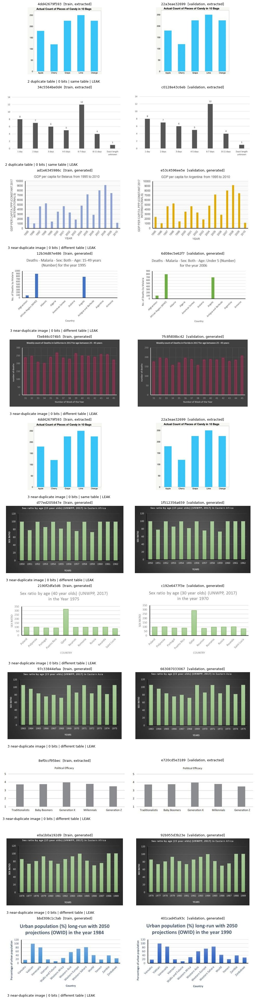

In [11]:
output_banner("2c what was found")

import matplotlib.pyplot as plt

def show_pairs(df, max_pairs=12):
    if df.empty:
        print("No cross-split pairs found - nothing to show.")
        return
    df = df.sort_values(["leak", "image_bits"], ascending=[False, True]).head(max_pairs)
    fig, axes = plt.subplots(len(df), 2, figsize=(10, 3.2 * len(df)), squeeze=False)
    with zipfile.ZipFile(KAGGLE_ZIP) as z:
        for row_axes, (_, r) in zip(axes, df.iterrows()):
            for ax, side in zip(row_axes, ("i", "j")):
                member = fps.loc[r[side], "chart_id"]
                img_member = all_charts.loc[all_charts["chart_id"] == member, "image_member"].iloc[0]
                ax.imshow(Image.open(io.BytesIO(z.read(img_member))))
                ax.set_title(f"{member}  [{r['split_' + side]}, {r['source_' + side]}]", fontsize=9)
                ax.axis("off")
            same_table = "same table" if r["table_hash_i"] == r["table_hash_j"] else "different table"
            row_axes[0].text(0, -0.12, f"{r['check']} | {r['image_bits']} bits | {same_table} | "
                             f"{'LEAK' if r['leak'] else 'not a leak'}", transform=row_axes[0].transAxes, fontsize=9)
    plt.tight_layout()
    plt.show()

show_pairs(found)

### 2d — Decide and save the exclusion list

**What happens.** Applies the decision rule from the top of Step 2: for every leaking pair, the chart in the earlier
split is excluded (train before validation before test). The list is saved to Drive as
`step2_leakage_exclusions.csv`, together with every flagged pair (`step2_flagged_pairs.csv`) and a summary
(`step2_leakage_report.json`). **Step 3 reads the exclusion list** and leaves those charts out before drawing
the 3,500-chart subset.

**Expected output:** the number of charts excluded per split (and how many of them are real), then
`Step 2 complete`. If nothing leaked, the list is empty and Step 3 draws from the full frozen splits.

In [12]:
output_banner("2d exclusion list")

with tp.step_log(REPORT_FILE, "Step 2d - exclusions"):
    excl = []
    for _, r in found[found["leak"]].iterrows():
        drop = "i" if SPLIT_ORDER[r["split_i"]] < SPLIT_ORDER[r["split_j"]] else "j"
        keep = "j" if drop == "i" else "i"
        excl.append({"chart_id": r[f"chart_id_{drop}"], "split": r[f"split_{drop}"], "source": r[f"source_{drop}"],
                     "reason": r["check"], "matches": r[f"chart_id_{keep}"], "matches_split": r[f"split_{keep}"]})
    exclusions = (pd.DataFrame(excl, columns=["chart_id", "split", "source", "reason", "matches", "matches_split"])
                    .drop_duplicates("chart_id"))
    # Step 2 results are written once and then preserved: a re-run must reproduce them exactly
    for name, df in (("step2_leakage_exclusions.csv", exclusions), ("step2_flagged_pairs.csv", found.drop(columns=["i", "j"]))):
        f = RESULTS_DIR / name
        if f.is_file():
            assert pd.read_csv(f)["chart_id" if "exclusions" in name else "chart_id_i"].tolist() == \
                   df["chart_id" if "exclusions" in name else "chart_id_i"].tolist(), f"{name} differs from the saved original"
        else:
            df.to_csv(f, index=False)

    per_split = {s: {"excluded": int((exclusions["split"] == s).sum()),
                     "excluded_real": int(((exclusions["split"] == s) & (exclusions["source"] == "extracted")).sum())}
                 for s in SPLIT_ORDER}
    report = {"charts_checked": len(fps), "pairs_flagged": len(found), "leaking_pairs": int(found["leak"].sum()),
              "thresholds_bits": {"near_duplicate_image": NEAR_IMAGE, "same_source_real": SAME_SOURCE_IMAGE},
              "pairs_by_check": summary2.to_dict(), "excluded_by_split": per_split}
    if not (RESULTS_DIR / "step2_leakage_report.json").is_file():
        tp.save_json(report, RESULTS_DIR / "step2_leakage_report.json")
    display(pd.DataFrame(per_split).T)
    if exclusions.empty:
        print("No leaks: Step 3 draws from the full frozen splits.")
    else:
        display(exclusions)
    print("Step 2 complete. Saved to", RESULTS_DIR)

,excluded,excluded_real
train,699,53
validation,94,6
test,0,0


,chart_id,split,source,reason,matches,matches_split
0,b0922f33e48f,train,extracted,2 duplicate table,f89032064933,test
2,a45ae3b0714b,train,extracted,2 duplicate table,f89032064933,test
4,4dd42679f593,train,extracted,2 duplicate table,22a3eae32699,validation
5,d3953f6dc2b6,train,extracted,2 duplicate table,e8d078662348,validation
6,fd16f4c0f8dd,train,extracted,2 duplicate table,e8d078662348,validation
...,...,...,...,...,...,...
994,8e6adab396d9,train,extracted,4 same-source real (title),cfa0f91c0430,validation
996,56a67c742efe,validation,extracted,4 same-source real (title),861629cc110a,test
998,37713629ecd9,validation,extracted,4 same-source real (labels+axes),fff5ca7bd414,test
999,271ec06d6cb3,validation,extracted,4 same-source real (labels+axes),fff5ca7bd414,test


Step 2 complete. Saved to /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/results


### 2e — Visual review of the 59 real charts flagged for exclusion

**Why this review.** Real (extracted) charts are scarce and matter most for the final evaluation, so none should be
discarded without evidence. Step 2's same-source rule is deliberately cautious: two charts that share a title or the
labels "1990 … 1999" are not necessarily from the same document. This part checks every flagged real chart by eye
and by its data before anything is removed.

**What it shows for each flagged real chart, and every chart it matched in another split:**
chart IDs and splits, both images, the rule that flagged the pair, whether the data tables are identical, how many
values agree, titles and axis titles, and the image distance (pHash bits; 0 = identical, about 32 = unrelated).

**Evidence categories** (a chart takes the strongest category among its matches). A shared title or shared
labels alone never puts a pair in category 1 or 2:

| Category | Rule | Proposed decision |
|---|---|---|
| 1 Confirmed duplicate | identical table, or near-identical image (≤ 4 bits) with the same x labels | exclude |
| 2 Strong evidence of common source | at least half the values agree (same label, within 1 %), or same title and similar image (≤ 10 bits) | exclude |
| 3 Ambiguous | some resemblance (image ≤ 16 bits) but values differ | your call (default: keep) |
| 4 Likely false positive | images clearly different (> 16 bits) and values differ: only a generic title or labels in common | keep |

**Why only one copy is removed, and why the earlier one.** A duplicate is only a problem when the same chart is on
both sides of the line between what the model learns from and what it is graded on. Removing either copy fixes that,
so exactly one is removed. It is always the copy in the earlier split (train before validation, validation before
test), for three reasons. The test set is the final exam and must stay exactly as frozen, so all 69 real test charts stay.
Validation is what early stopping and model choices are judged on, so it is protected next. Train is the largest split,
so losing one chart there costs the least.

**How to read the captions on the 2e images.** Each row shows one flagged real chart on the left and up to 3 charts it
matched in a later split on the right. The left chart's title shows `proposed` (from the category rules) and `final`
(after `OVERRIDES`); red = excluded, green = kept. The caption above each matched chart has three lines:

* **Line 1**, e.g. `7af20a460068 [validation]`: the matched chart's ID and split.
* **Line 2**, e.g. `same-source real (title + image 8 bits)`: which checks flagged the pair. Each check is a separate
  yes/no, and **one yes is enough** to flag a pair. The words list every check that said yes:

| Words | Meaning |
|---|---|
| `duplicate table` | the two annotation tables are identical: same labels, same values |
| `near-duplicate image` | the pictures are ≤ 4 bits apart |
| `title` | the chart titles are the same (ignoring capitals and spacing) |
| `labels+axes` | the bar names (x labels, in order) **and** the axis titles are the same |
| `image N bits` | the pictures are N bits apart (listed when N ≤ 10) |

  So `title + image 8 bits` means: the titles matched and the pictures are 8 bits apart, but the bar names did not match.
* **Line 3**, e.g. `8 bits | table different | values agree 43%`: three measurements, shown for every pair.
  * **Bits (image distance):** how many of the 64 pHash bits differ (how the pHash is made: see 2a). 0 = identical,
    about 32 = unrelated. It sees the whole picture, including the title band and borders, but cannot read words, so a
    cropped copy or an added title can push the same chart past 20 bits.
  * **Table:** `IDENTICAL` if the two annotation tables match exactly, otherwise `different`.
  * **Values agree:** a bar-by-bar comparison (bar 1 with bar 1, bar 2 with bar 2, …). A bar agrees when its label is
    the same and its value is within 1 %. Share = agreeing bars ÷ bars in the larger chart; for example 3 of 7 bars
    agree → 43 %. The values come from the annotations, which people typed in, not from the pictures, so two copies of
    the same chart can score well below 100 % (see 2e+ and 2e-i).
* **Below each row:** both charts' titles and axis titles, and the IDs of every chart it matched.

**Nothing from Step 2 is overwritten.** Results go to new files: `step2e_real_review_pairs.csv` (every pair) and
`step2e_real_decisions.csv` (one row per chart, with the proposed and final decision).

**To change a decision** after looking at the images, add the chart ID to `OVERRIDES` in the next code cell
(for example `{"c7bd58975106": "exclude"}`) and re-run it. Every override is recorded in the CSV.

**Expected output:** a count of charts per category, then the images grouped by category.

In [21]:
output_banner("2e review summary")

import chart_eval as ce

OVERRIDES = {   # chart_id -> "keep" or "exclude", set after looking at the images (AT, Nov 5 2026)
    "d18ea652ebfe": "exclude",   # 2 bits from validation a36dd45a2c82: same picture, labels spelled differently
    "6dd91099b5f4": "exclude",   # 6 bits from validation 2698ec7e0c88: same graduates chart, annotations disagree
    "80e636956c4a": "exclude",   # 6 bits from validation dedc6679f3ba: same visibility chart, annotations disagree
    "8b745c0ece6d": "exclude",   # 2e-ii #4: same "people aged over 60" chart as test 1292ecd150f4 (14 bits, crop differs)
}

step2_excl = pd.read_csv(RESULTS_DIR / "step2_leakage_exclusions.csv")          # read only
real_excl  = step2_excl[step2_excl["source"] == "extracted"]["chart_id"].tolist()
member_of  = all_charts.set_index("chart_id")
fp_of      = fps.set_index("chart_id")

def read_table(cid):
    with zipfile.ZipFile(KAGGLE_ZIP) as z:
        return ce.ground_truth_from_annotation(z.read(member_of.at[cid, "annotation_member"]))

def value_agreement(a, b):
    # share of rows where the x label is the same AND the y value is within 1 % (rows matched by position)
    (xa, ya), (xb, yb) = read_table(a), read_table(b)
    n = max(len(xa), len(xb))
    same = sum(1 for k in range(min(len(xa), len(xb)))
               if " ".join(xa[k].lower().split()) == " ".join(xb[k].lower().split())
               and abs(ya[k] - yb[k]) <= 0.01 * max(abs(ya[k]), abs(yb[k]), 1e-9))
    return same / n if n else 0.0

def category(r):
    if r["identical_table"] or (r["image_bits"] <= 4 and r["same_x_labels"]):
        return 1
    if r["values_agree"] >= 0.5 or (r["same_title"] and r["image_bits"] <= 10):
        return 2
    if r["image_bits"] <= 16:
        return 3
    return 4

CAT_NAME = {1: "1 Confirmed duplicate", 2: "2 Strong evidence of common source",
            3: "3 Ambiguous", 4: "4 Likely false positive"}

with tp.step_log(REPORT_FILE, "Step 2e - visual review of flagged real charts"):
    rev = []
    leaks = found[found["leak"]]
    for cid in real_excl:
        rows = leaks[(leaks["chart_id_i"] == cid) | (leaks["chart_id_j"] == cid)]
        for _, p in rows.iterrows():
            other = p["chart_id_j"] if p["chart_id_i"] == cid else p["chart_id_i"]
            a, b = fp_of.loc[cid], fp_of.loc[other]
            rev.append({"chart_id": cid, "split": a["split"], "matched_id": other, "matched_split": b["split"],
                        "matched_source": b["source"], "rule": p["check"], "image_bits": int(p["image_bits"]),
                        "identical_table": a["table_hash"] == b["table_hash"],
                        "same_x_labels": a["x_labels"] == b["x_labels"],
                        "same_title": bool(a["title"]) and a["title"] == b["title"],
                        "values_agree": round(value_agreement(cid, other), 2),
                        "title": a["title"], "matched_title": b["title"],
                        "axis_titles": a["axis_titles"], "matched_axis_titles": b["axis_titles"],
                        "x_labels": a["x_labels"][:120]})
    review_pairs = pd.DataFrame(rev).drop_duplicates(["chart_id", "matched_id", "rule"])
    review_pairs["category"] = review_pairs.apply(category, axis=1)
    review_pairs.to_csv(RESULTS_DIR / "step2e_real_review_pairs.csv", index=False)

    dec = review_pairs.groupby(["chart_id", "split"], as_index=False).agg(
        category=("category", "min"), matches=("matched_id", lambda s: " ; ".join(sorted(set(s)))),
        n_matches=("matched_id", "nunique"))
    dec["category_name"] = dec["category"].map(CAT_NAME)
    dec["proposed"] = np.where(dec["category"] <= 2, "exclude", "keep")
    dec["override"] = dec["chart_id"].map(OVERRIDES).fillna("")
    dec["final"] = np.where(dec["override"] != "", dec["override"], dec["proposed"])
    dec.to_csv(RESULTS_DIR / "step2e_real_decisions.csv", index=False)

    print(f"Real charts flagged by Step 2: {len(real_excl)}   reviewed: {len(dec)}   pairs: {len(review_pairs)}")
    display(dec.groupby("category_name").agg(charts=("chart_id", "size"),
                                             exclude=("final", lambda s: int((s == "exclude").sum())),
                                             keep=("final", lambda s: int((s == "keep").sum()))))
    if OVERRIDES:
        print("Overrides applied:", OVERRIDES)

Real charts flagged by Step 2: 59   reviewed: 59   pairs: 127


,charts,exclude,keep
category_name,,,
1 Confirmed duplicate,23,23,0
2 Strong evidence of common source,5,5,0
3 Ambiguous,15,4,11
4 Likely false positive,16,0,16


Overrides applied: {'d18ea652ebfe': 'exclude', '6dd91099b5f4': 'exclude', '80e636956c4a': 'exclude', '8b745c0ece6d': 'exclude'}


**The images.** One row per flagged real chart: the chart itself on the left (its split is where it would be removed
from), then every chart it matched in a later split. Under each pair: the rule, the image distance, whether the
tables are identical, and the share of values that agree. Charts are grouped by category, strongest evidence first.


=== 1 Confirmed duplicate: 23 charts ===


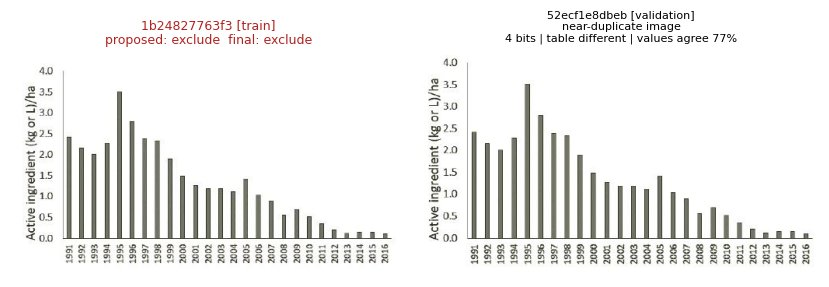

  title: '' vs ''   axis titles: 'active ingredient (kg or l)/ha' vs 'active ingredient (kg or l)/ha'   matches: 52ecf1e8dbeb


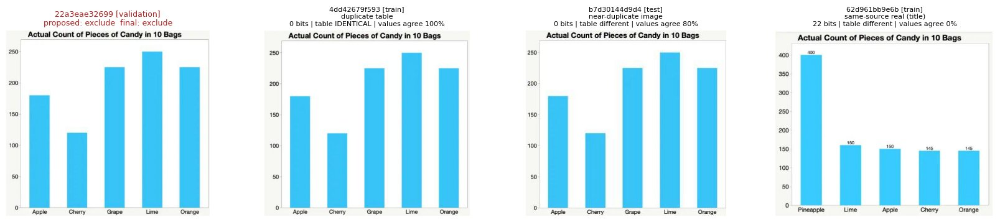

  title: 'actual count of pieces of candy in 10 bags' vs 'actual count of pieces of candy in 10 bags'   axis titles: '' vs ''   matches: 4dd42679f593 ; 62d961bb9e6b ; b7d30144d9d4


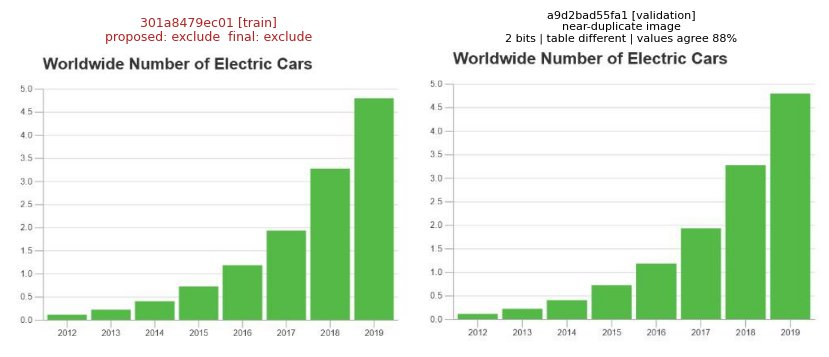

  title: 'worldwide number of electric cars' vs 'worldwide number of electric cars'   axis titles: '' vs ''   matches: a9d2bad55fa1


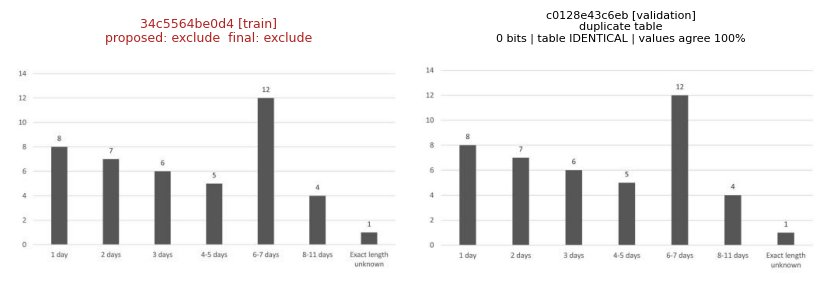

  title: '' vs ''   axis titles: '' vs ''   matches: c0128e43c6eb


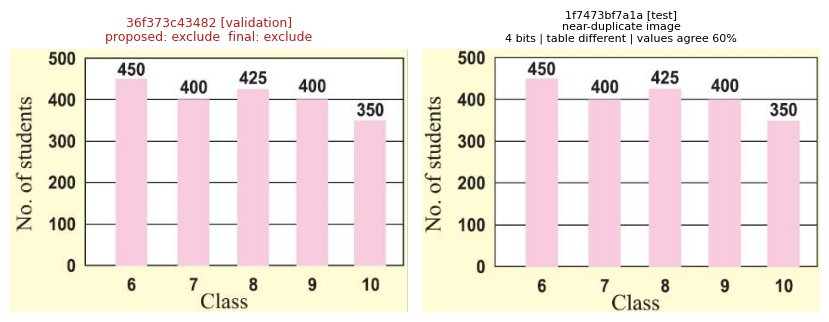

  title: '' vs ''   axis titles: 'class ; no. of students' vs 'class ; no. of students'   matches: 1f7473bf7a1a


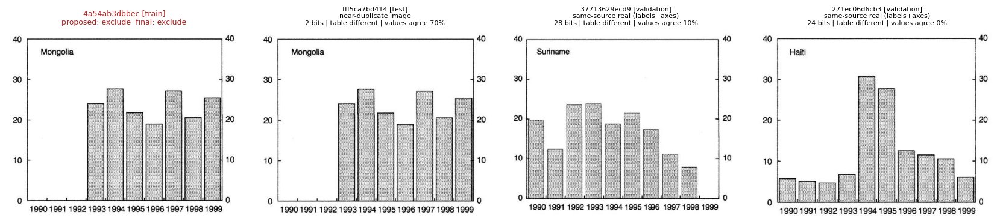

  title: 'mongolia' vs ''   axis titles: '' vs ''   matches: 271ec06d6cb3 ; 37713629ecd9 ; fff5ca7bd414


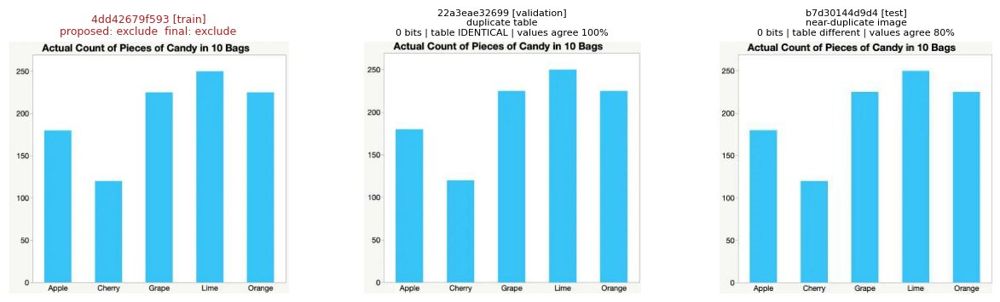

  title: 'actual count of pieces of candy in 10 bags' vs 'actual count of pieces of candy in 10 bags'   axis titles: '' vs ''   matches: 22a3eae32699 ; b7d30144d9d4


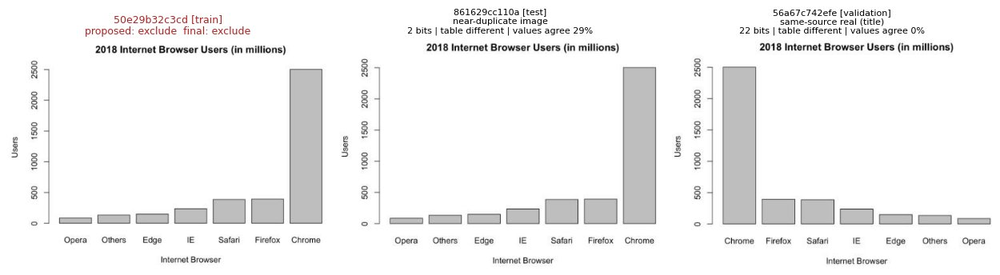

  title: '2018 internet browser users (in millions)' vs '2018 internet browser users (in millions)'   axis titles: 'internet browser ; users' vs 'internet browser ; users'   matches: 56a67c742efe ; 861629cc110a


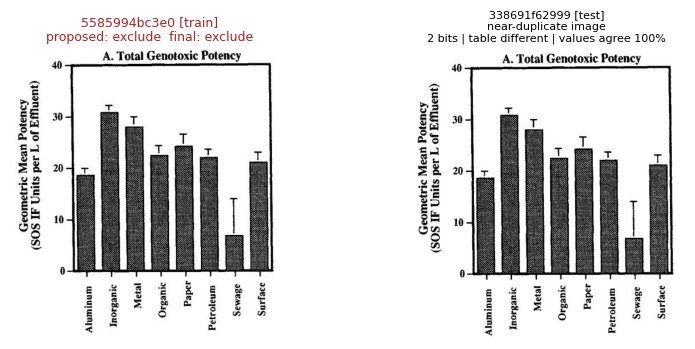

  title: 'a. total genotoxic potency' vs 'a. total genotoxic potency'   axis titles: 'geometric mean potency (sos if units per l of effluent)' vs 'geometric mean potency (sos if units per l of effluent)'   matches: 338691f62999


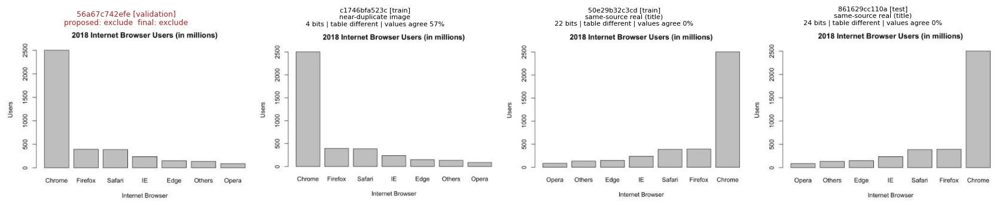

  title: '2018 internet browser users (in millions)' vs '2018 internet browser users (in millions)'   axis titles: 'internet browser ; users' vs 'internet browser ; users'   matches: 50e29b32c3cd ; 861629cc110a ; c1746bfa523c


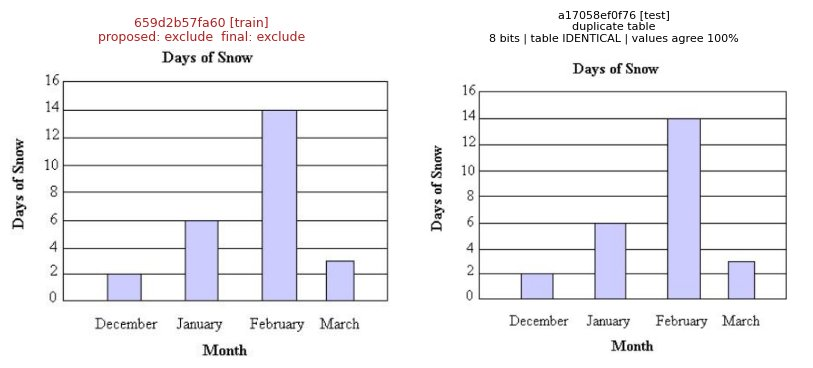

  title: 'days of snow' vs 'days of snow'   axis titles: 'days of snow ; month' vs 'days of snow ; month'   matches: a17058ef0f76


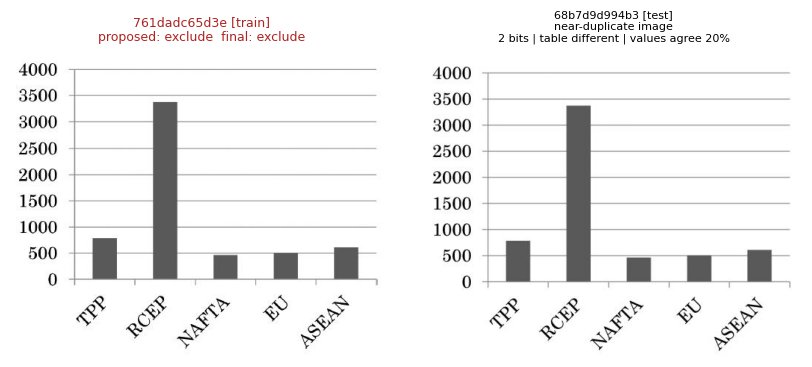

  title: '' vs ''   axis titles: '' vs ''   matches: 68b7d9d994b3


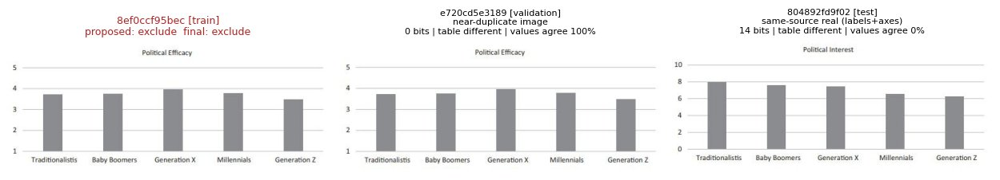

  title: 'political efficacy' vs 'political efficacy'   axis titles: '' vs ''   matches: 804892fd9f02 ; e720cd5e3189


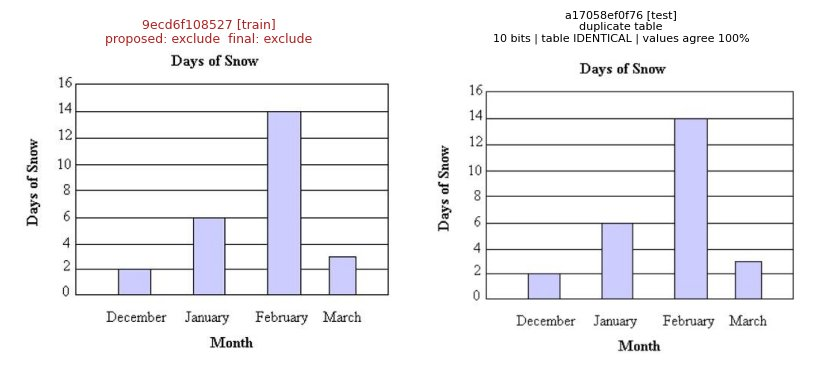

  title: 'days of snow' vs 'days of snow'   axis titles: 'days of snow ; month' vs 'days of snow ; month'   matches: a17058ef0f76


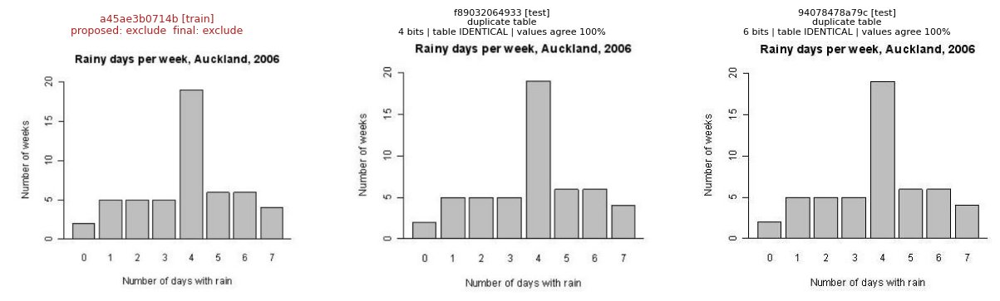

  title: 'rainy days per week, auckland, 2006' vs 'raniy days per week, auckland, 2006'   axis titles: 'number of days with rain ; number of weeks' vs 'number of days with rain ; number of weeks'   matches: 94078478a79c ; f89032064933


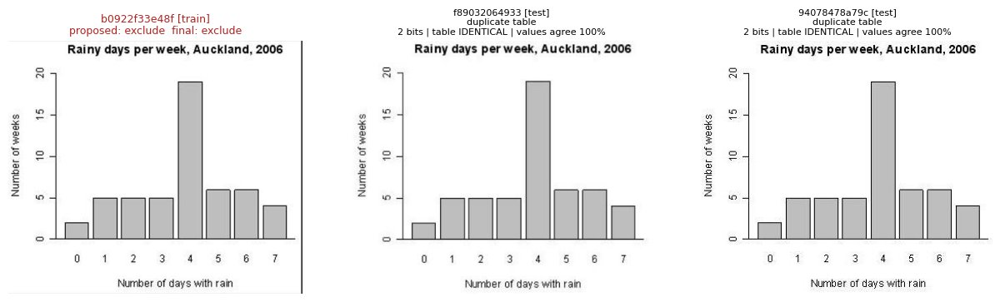

  title: 'rainy days per week, auckland, 2006' vs 'raniy days per week, auckland, 2006'   axis titles: 'number of days with rain ; number of weeks' vs 'number of days with rain ; number of weeks'   matches: 94078478a79c ; f89032064933


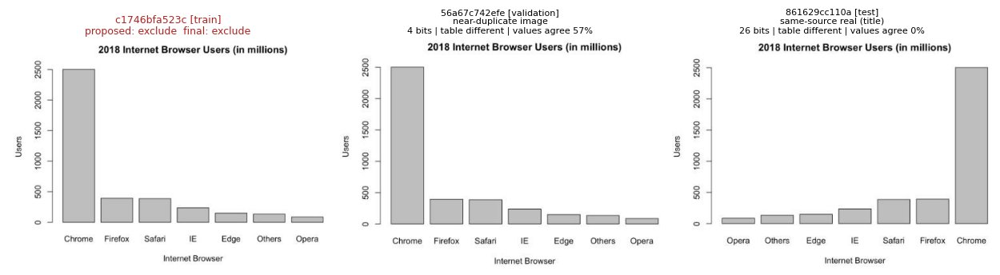

  title: '2018 internet browser users (in millions)' vs '2018 internet browser users (in millions)'   axis titles: 'internet browser ; users' vs 'internet browser ; users'   matches: 56a67c742efe ; 861629cc110a


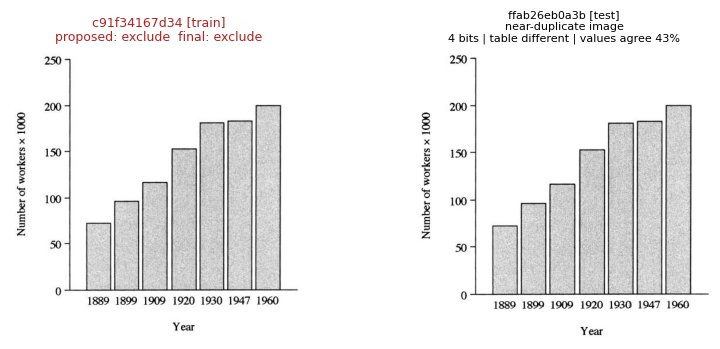

  title: '' vs ''   axis titles: 'number of workers * 1000 ; year' vs 'number of workers x 1000 ; year'   matches: ffab26eb0a3b


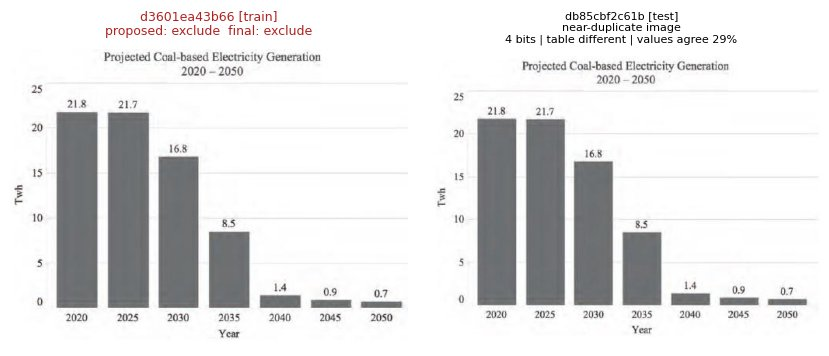

  title: 'projected coal-based electricity generation 2020-2050' vs 'projected coal-based electricity generation 2020 - 2050'   axis titles: 'twh ; year' vs 'twh ; year'   matches: db85cbf2c61b


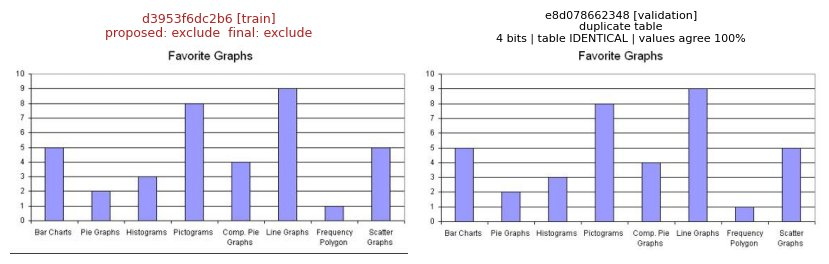

  title: 'favorite graphs' vs 'favorite graphs'   axis titles: '' vs ''   matches: e8d078662348


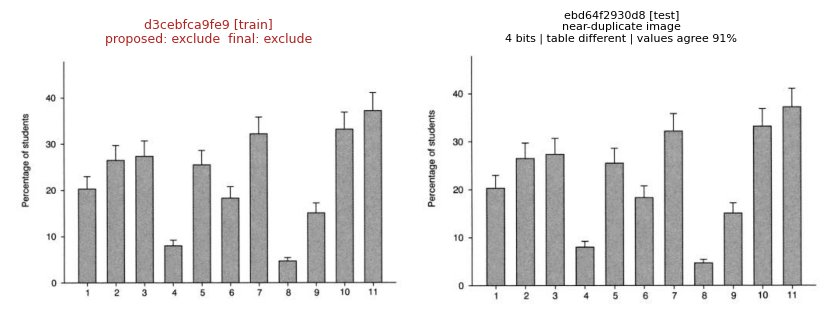

  title: '' vs ''   axis titles: 'percentage students' vs 'percentage of students'   matches: ebd64f2930d8


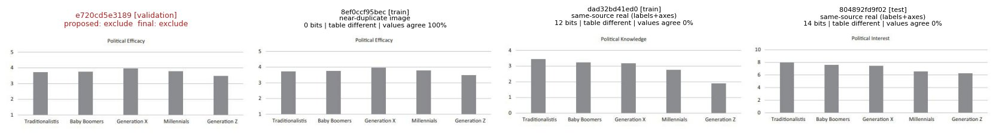

  title: 'political efficacy' vs 'political efficacy'   axis titles: '' vs ''   matches: 804892fd9f02 ; 8ef0ccf95bec ; dad32bd41ed0


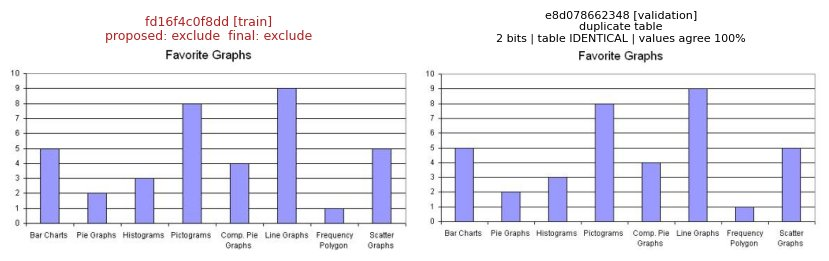

  title: 'favorite graphs' vs 'favorite graphs'   axis titles: '' vs ''   matches: e8d078662348

=== 2 Strong evidence of common source: 5 charts ===


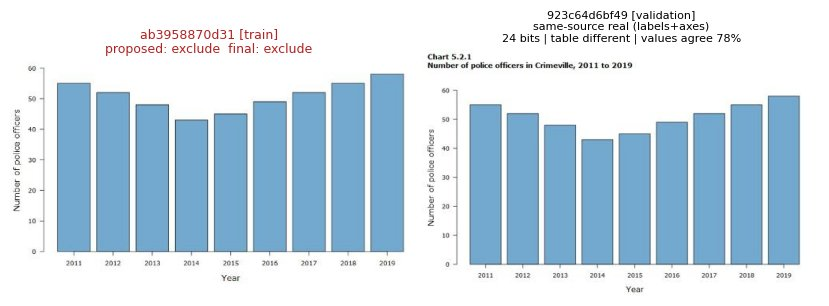

  title: '' vs 'chart 5.2.1 number of police officers in crimeville, 2011 to 2019'   axis titles: 'number of police officers ; year' vs 'number of police officers ; year'   matches: 923c64d6bf49


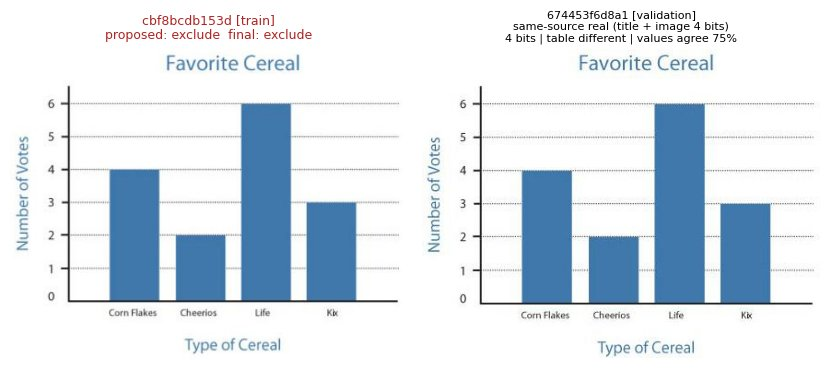

  title: 'favorite cereal' vs 'favorite cereal'   axis titles: 'number of votes ; type of cereal' vs 'number of votes ; type of cereal'   matches: 674453f6d8a1


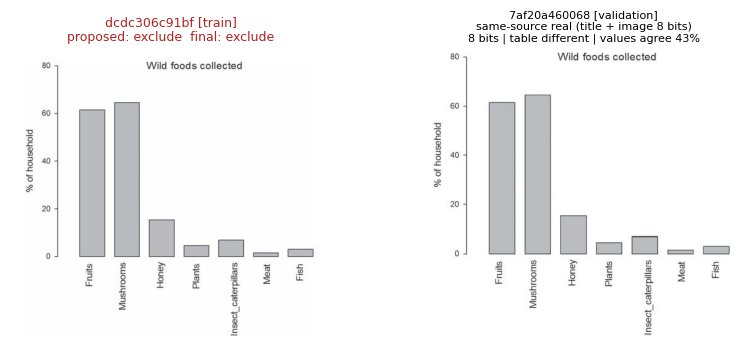

  title: 'wild foods collected' vs 'wild foods collected'   axis titles: '% of householdd' vs '% of household'   matches: 7af20a460068


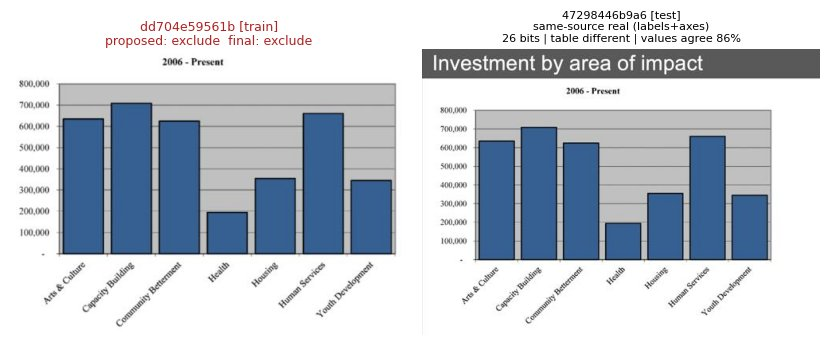

  title: '2006 - present' vs 'investment by area of impact'   axis titles: '' vs ''   matches: 47298446b9a6


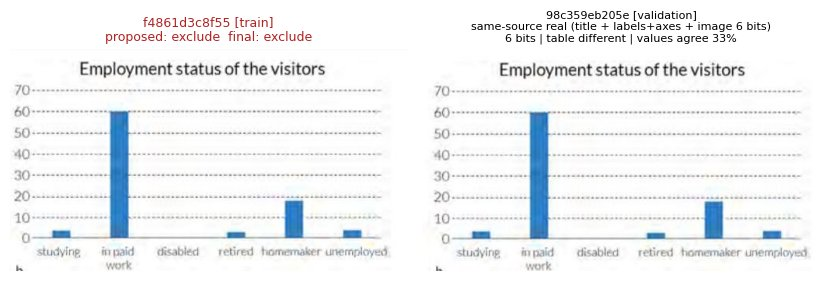

  title: 'employment status of the visitors' vs 'employment status of the visitors'   axis titles: '' vs ''   matches: 98c359eb205e

=== 3 Ambiguous: 15 charts ===


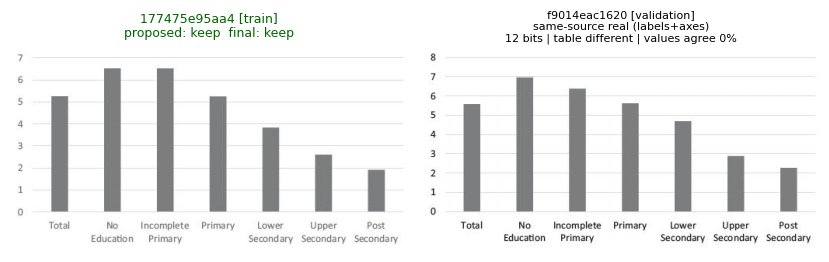

  title: '' vs ''   axis titles: '' vs ''   matches: f9014eac1620


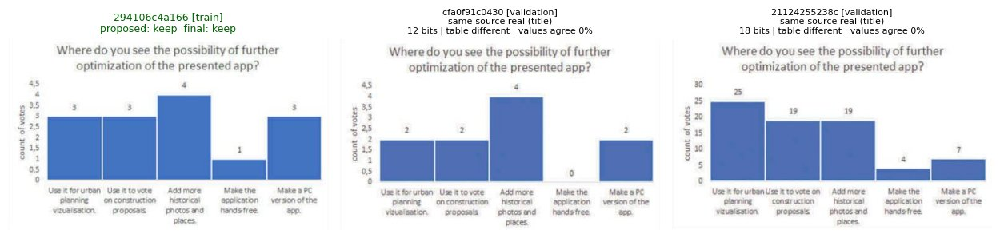

  title: 'where do you see the possibility of further optimization of the presented app?' vs 'where do you see the possibility of further optimization of the presented app?'   axis titles: 'count of votes' vs 'count of votes'   matches: 21124255238c ; cfa0f91c0430


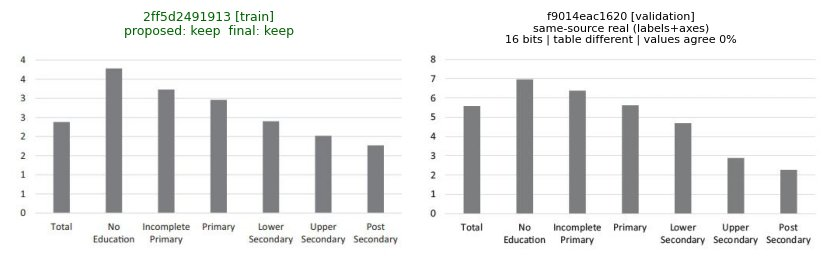

  title: '' vs ''   axis titles: '' vs ''   matches: f9014eac1620


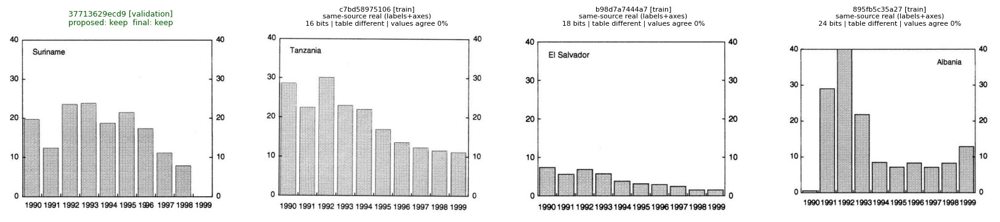

  title: '' vs ''   axis titles: '' vs ''   matches: 4a54ab3dbbec ; 895fb5c35a27 ; b98d7a7444a7 ; c7bd58975106 ; fff5ca7bd414


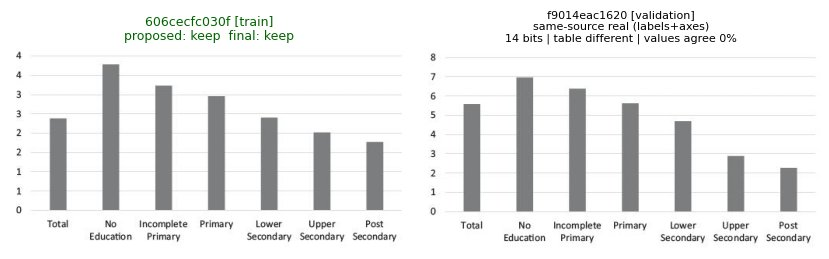

  title: '' vs ''   axis titles: '' vs ''   matches: f9014eac1620


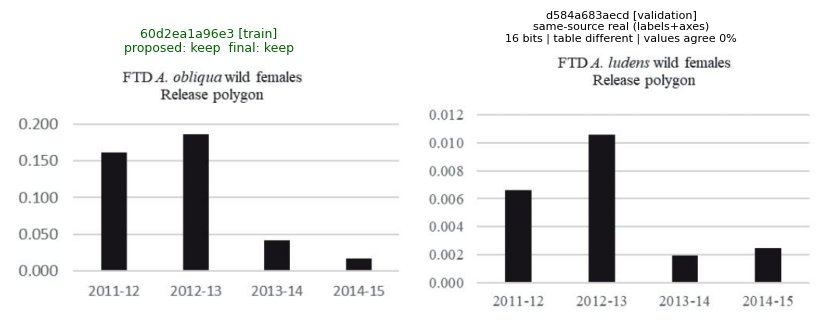

  title: 'ftd a. obliqua wild females release polygon' vs 'ftd a. ludens wild females release polygon'   axis titles: '' vs ''   matches: d584a683aecd


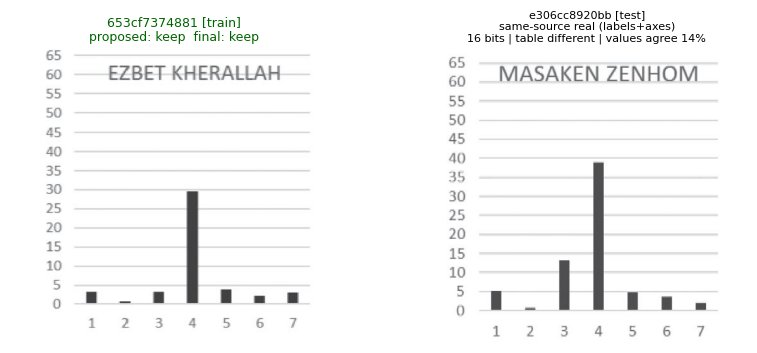

  title: 'ezbet kherallah' vs 'masaken zenhom'   axis titles: '' vs ''   matches: e306cc8920bb


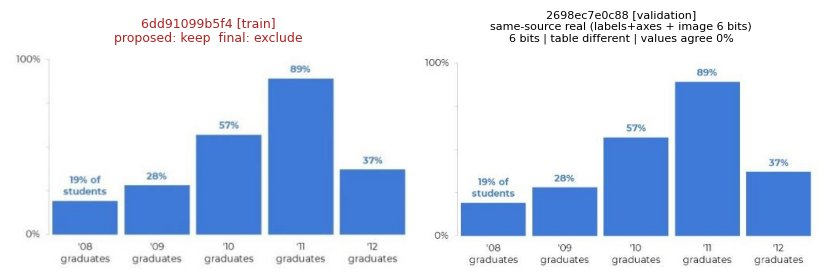

  title: '' vs ''   axis titles: '' vs ''   matches: 2698ec7e0c88


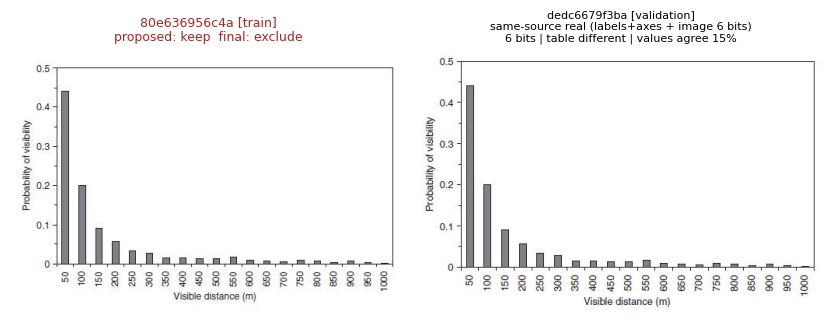

  title: '' vs ''   axis titles: 'probability of visibility ; visible distance (m)' vs 'probability of visibility ; visible distance (m)'   matches: dedc6679f3ba


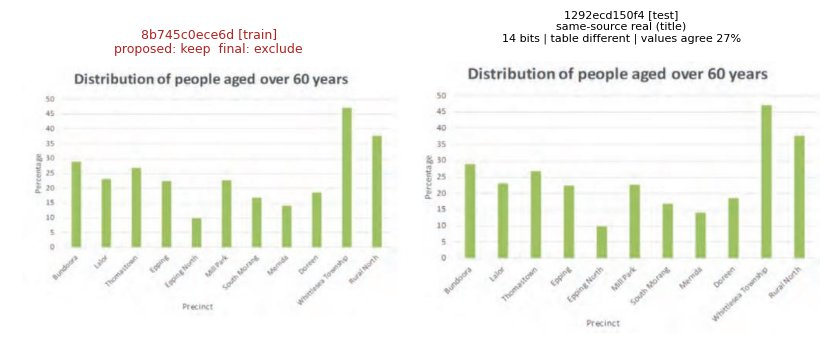

  title: 'distribution of people aged over 60 years' vs 'distribution of people aged over 60 years'   axis titles: 'percentage ; precinct' vs 'percentage ; precinct'   matches: 1292ecd150f4


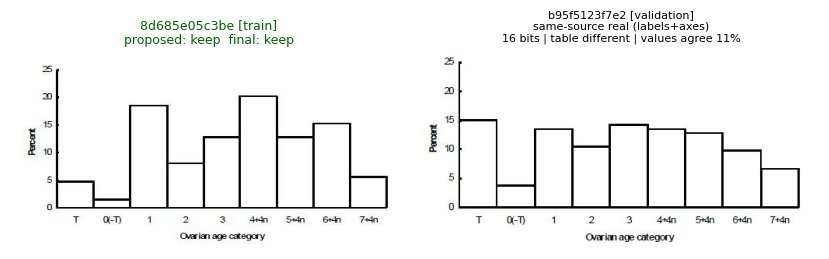

  title: '' vs ''   axis titles: 'ovarian age category ; percent' vs 'ovarian age category ; percent'   matches: b95f5123f7e2


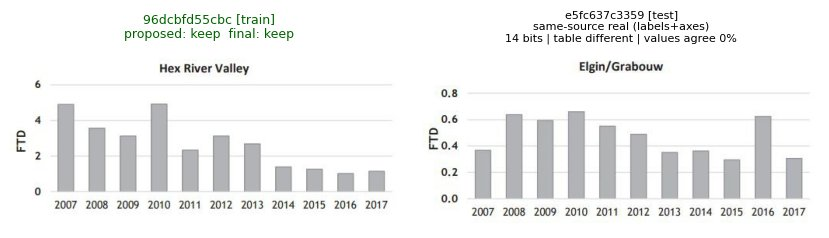

  title: 'hex river valley' vs 'elgin/grabouw'   axis titles: 'ftd' vs 'ftd'   matches: e5fc637c3359


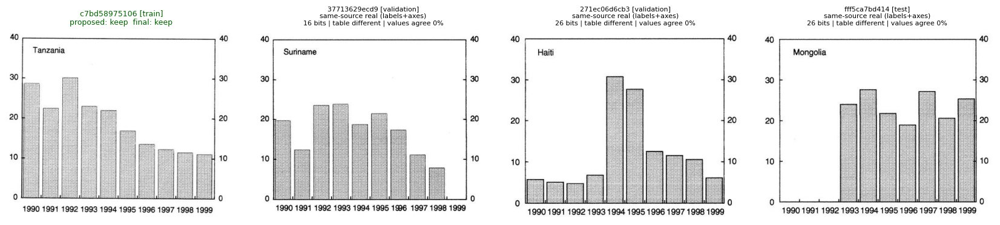

  title: '' vs ''   axis titles: '' vs ''   matches: 271ec06d6cb3 ; 37713629ecd9 ; fff5ca7bd414


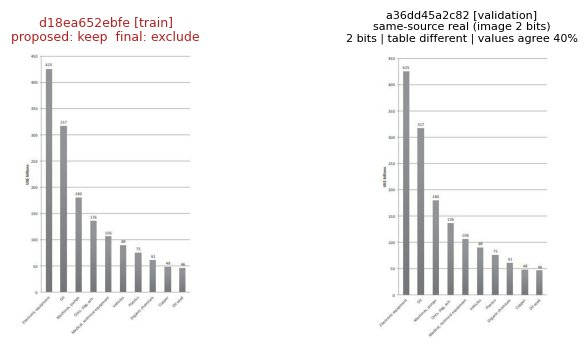

  title: '' vs ''   axis titles: 'us$ millenes' vs 'us$ billions'   matches: a36dd45a2c82


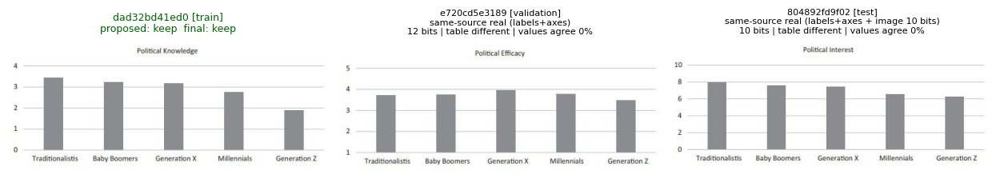

  title: 'political knowledge' vs 'political efficacy'   axis titles: '' vs ''   matches: 804892fd9f02 ; e720cd5e3189

=== 4 Likely false positive: 16 charts ===


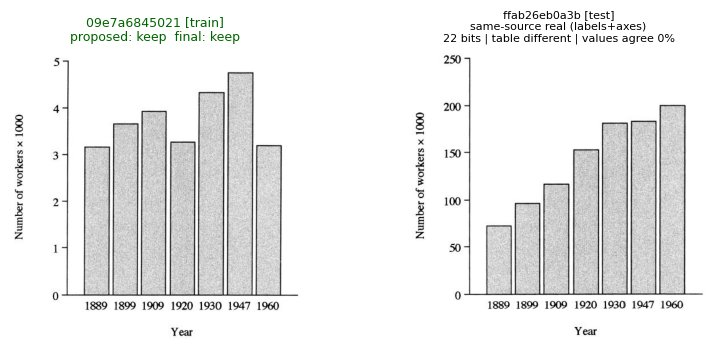

  title: '' vs ''   axis titles: 'number of workers x 1000 ; year' vs 'number of workers x 1000 ; year'   matches: ffab26eb0a3b


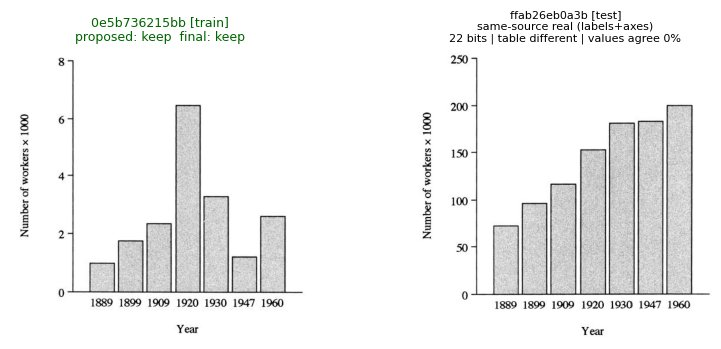

  title: '' vs ''   axis titles: 'number of workers x 1000 ; year' vs 'number of workers x 1000 ; year'   matches: ffab26eb0a3b


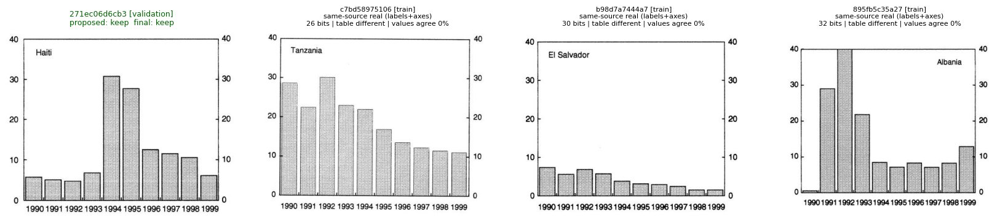

  title: '' vs ''   axis titles: '' vs ''   matches: 4a54ab3dbbec ; 895fb5c35a27 ; b98d7a7444a7 ; c7bd58975106 ; fff5ca7bd414


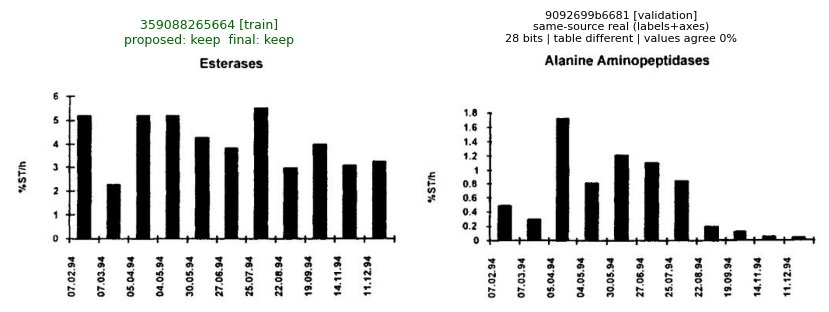

  title: 'esterases' vs 'alanine aminopeptidases'   axis titles: '%st/h' vs '%st/h'   matches: 9092699b6681


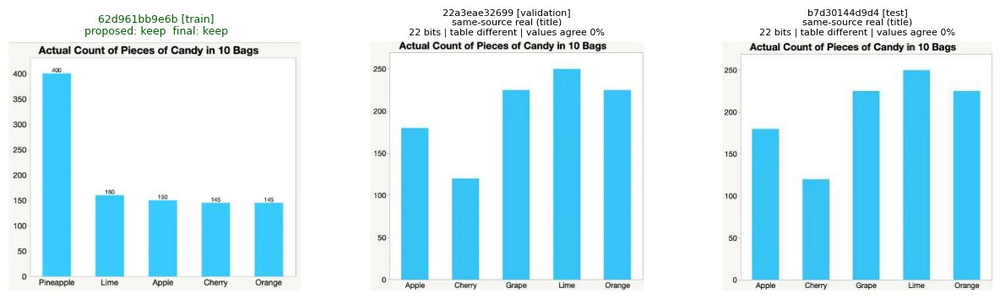

  title: 'actual count of pieces of candy in 10 bags' vs 'actual count of pieces of candy in 10 bags'   axis titles: '' vs ''   matches: 22a3eae32699 ; b7d30144d9d4


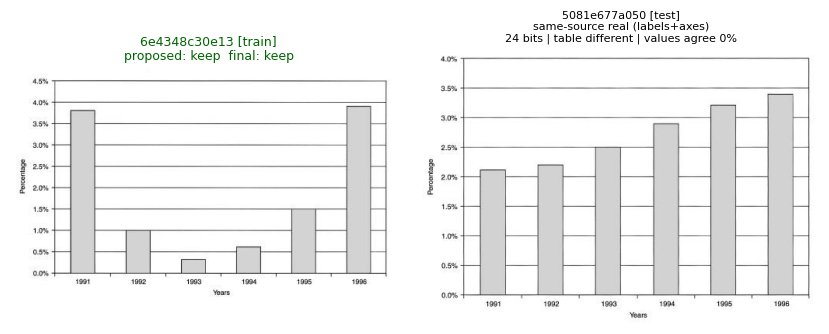

  title: '' vs ''   axis titles: 'percentage ; years' vs 'percentage ; years'   matches: 5081e677a050


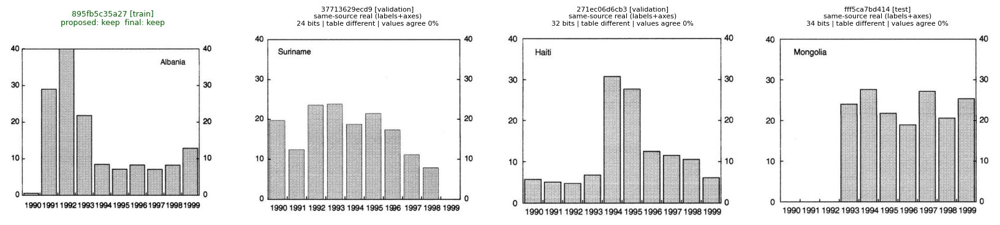

  title: '' vs ''   axis titles: '' vs ''   matches: 271ec06d6cb3 ; 37713629ecd9 ; fff5ca7bd414


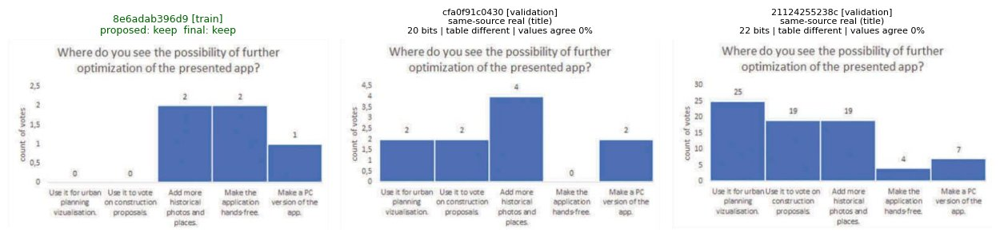

  title: 'where do you see the possibility of further optimization of the presented app?' vs 'where do you see the possibility of further optimization of the presented app?'   axis titles: 'count of votes' vs 'count of votes'   matches: 21124255238c ; cfa0f91c0430


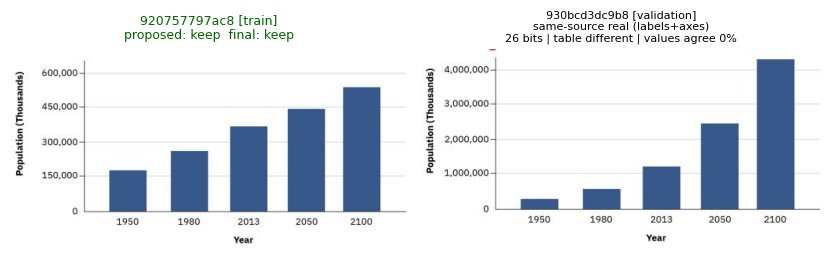

  title: '' vs ''   axis titles: 'population (thousands) ; year' vs 'population (thousands) ; year'   matches: 930bcd3dc9b8


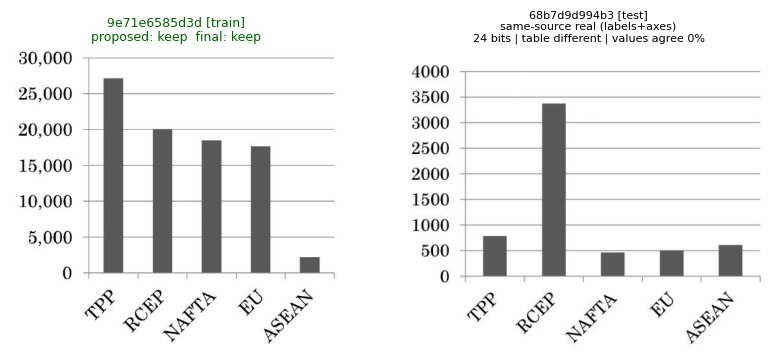

  title: '' vs ''   axis titles: '' vs ''   matches: 68b7d9d994b3


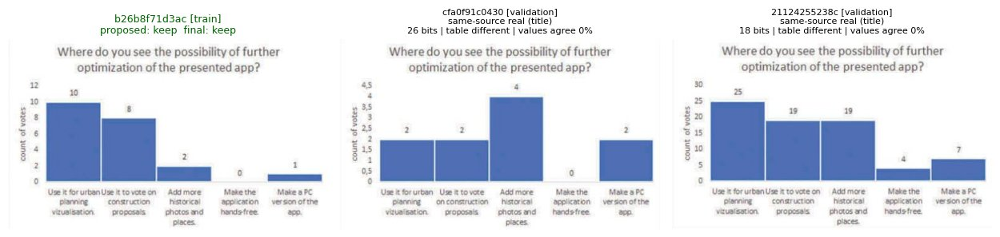

  title: 'where do you see the possibility of further optimization of the presented app?' vs 'where do you see the possibility of further optimization of the presented app?'   axis titles: 'count of votes' vs 'count of votes'   matches: 21124255238c ; cfa0f91c0430


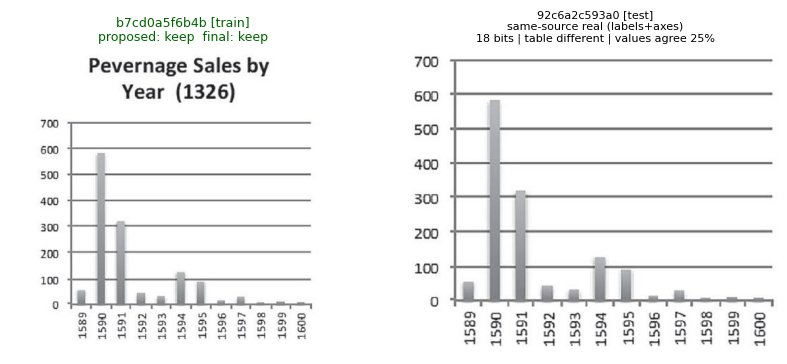

  title: 'pevernage sales by year (1326)' vs ''   axis titles: '' vs ''   matches: 92c6a2c593a0


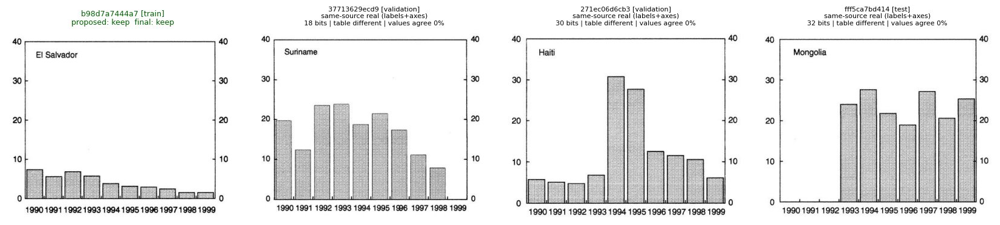

  title: 'el salvador' vs ''   axis titles: '' vs ''   matches: 271ec06d6cb3 ; 37713629ecd9 ; fff5ca7bd414


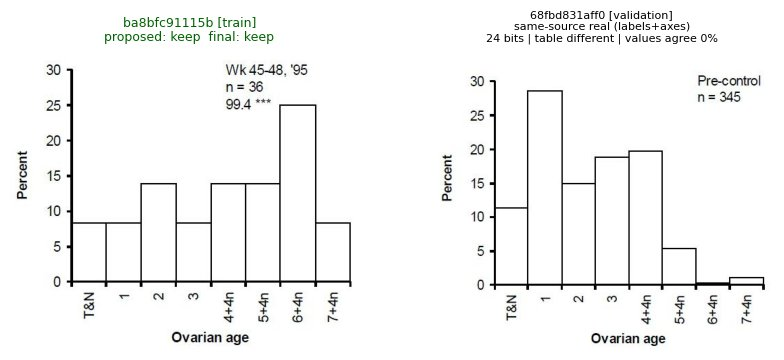

  title: '' vs ''   axis titles: 'ovarian age ; percent' vs 'ovarian age ; percent'   matches: 68fbd831aff0


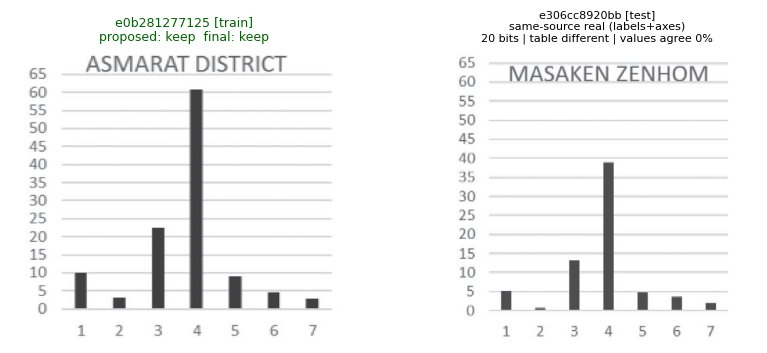

  title: 'asmarat district' vs 'masaken zenhom'   axis titles: '' vs ''   matches: e306cc8920bb


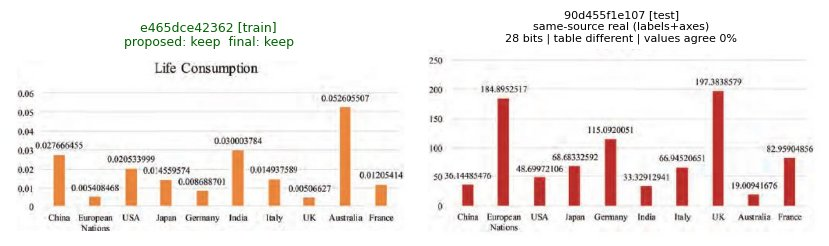

  title: 'life consumption' vs ''   axis titles: '' vs ''   matches: 90d455f1e107


In [22]:
output_banner("2e images by category")

def show_review(cat, max_matches=3):
    sub = dec[dec["category"] == cat]
    print(f"\n=== {CAT_NAME[cat]}: {len(sub)} charts ===")
    if sub.empty:
        return
    with zipfile.ZipFile(KAGGLE_ZIP) as z:
        img = lambda c: Image.open(io.BytesIO(z.read(member_of.at[c, "image_member"])))
        for _, d in sub.iterrows():
            ps = review_pairs[review_pairs["chart_id"] == d["chart_id"]].drop_duplicates("matched_id").head(max_matches)
            fig, axes = plt.subplots(1, 1 + len(ps), figsize=(4.2 * (1 + len(ps)), 3.6), squeeze=False)
            axes = axes[0]
            axes[0].imshow(img(d["chart_id"]))
            axes[0].set_title(f"{d['chart_id']} [{d['split']}]\nproposed: {d['proposed']}  final: {d['final']}",
                              fontsize=9, color="firebrick" if d["final"] == "exclude" else "darkgreen")
            for ax, (_, p) in zip(axes[1:], ps.iterrows()):
                ax.imshow(img(p["matched_id"]))
                ax.set_title(f"{p['matched_id']} [{p['matched_split']}]\n{p['rule'][2:]}\n"
                             f"{p['image_bits']} bits | table {'IDENTICAL' if p['identical_table'] else 'different'}"
                             f" | values agree {p['values_agree']:.0%}", fontsize=8)
            for ax in axes:
                ax.axis("off")
            plt.tight_layout()
            plt.show()
            t = review_pairs[review_pairs["chart_id"] == d["chart_id"]].iloc[0]
            print(f"  title: '{t['title']}' vs '{t['matched_title']}'   axis titles: '{t['axis_titles']}' vs "
                  f"'{t['matched_axis_titles']}'   matches: {d['matches']}")

for c in (1, 2, 3, 4):
    show_review(c)

### 2e-i — Why "values agree" is not enough: three examples

**The idea we tested.** For each ambiguous pair, 2e measures how many bar values agree (same label, value within 1 %).
A low share looked like proof that two charts hold different data.

**What we found.** These three real charts each have a near-identical twin in a later split (2–6 bits apart),
yet only 0 %, 15 % and 40 % of their values agree. Look at the pictures: they are the **same chart**. The printed
numbers match (the graduates chart even has 19 %, 28 %, 57 %, 89 %, 37 % written on the bars). The values disagree
because two people annotated the two copies differently (the annotation noise measured in 2e+), not because the data differ.

**Decision.** A low share of agreeing values does **not** prove two charts are different. These three earlier-split copies
are excluded (`OVERRIDES` in 2e), and every remaining ambiguous pair is checked by eye in 2e-ii.

**Expected output:** three image pairs, each with its two annotation tables side by side.

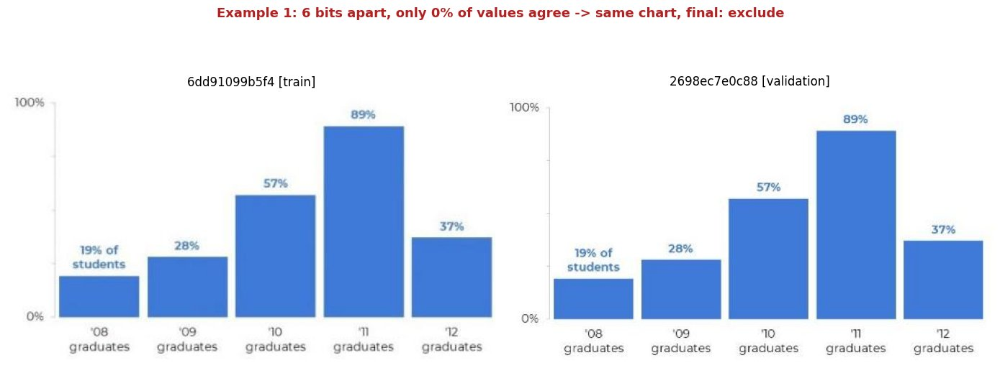

,bar,label 6dd91099b5f4,value 6dd91099b5f4,label 2698ec7e0c88,value 2698ec7e0c88,% diff
0,1,'08 graduates,20.0,'08 graduates,19.0,-5.00
1,2,'09 graduates,29.0,'09 graduates,27.0,-6.90
2,3,'10 graduates,57.0,'10 graduates,56.0,-1.75
3,4,'11 graduates,90.0,'11 graduates,87.0,-3.33
4,5,'12 graduates,38.0,'12 graduates,36.0,-5.26


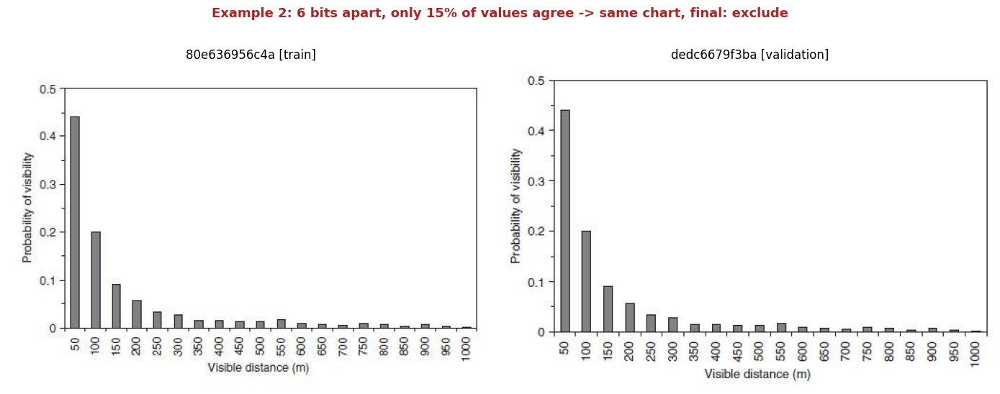

,bar,label 80e636956c4a,value 80e636956c4a,label dedc6679f3ba,value dedc6679f3ba,% diff
0,1,50,0.441632,50,0.443343,0.39
1,2,100,0.203568,100,0.203494,-0.04
2,3,150,0.095357,150,0.093957,-1.47
3,4,200,0.061910,200,0.060592,-2.13
4,5,250,0.038300,250,0.036670,-4.26
5,6,300,0.031742,300,0.031634,-0.34
6,7,350,0.021249,350,0.017784,-16.31
7,8,400,0.022560,400,0.017784,-21.17
8,9,450,0.018625,450,0.016525,-11.28
9,10,500,0.018625,500,0.019043,2.24


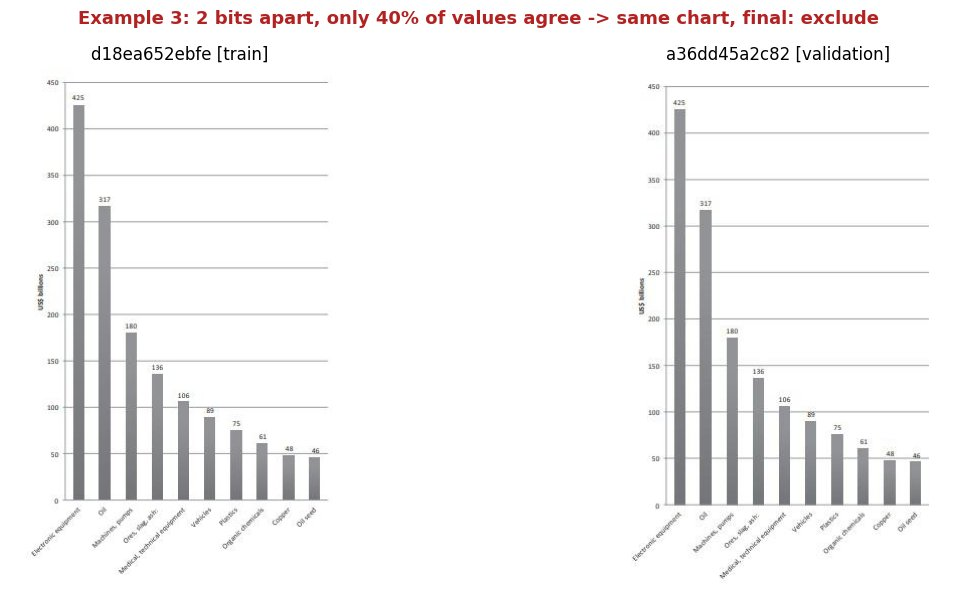

,bar,label d18ea652ebfe,value d18ea652ebfe,label a36dd45a2c82,value a36dd45a2c82,% diff
0,1,Electronic equipment,427.0,Electronic equipment,424.0,-0.70
1,2,Oil,319.0,Oil,317.0,-0.63
2,3,"Mchines, pumps",182.0,"Machines, pumps",181.0,-0.55
3,4,"Ores, sing, ash:",137.0,"Ores, slag, ashs",138.0,0.73
4,5,"Medical, techinical equipment",108.0,"Medical, technical equipment",108.0,0.00
5,6,Vehicles,91.0,Vehicles,92.0,1.10
6,7,Plastics,77.0,Plastics,78.0,1.30
7,8,Organic chemicals,63.0,Organic chemicals,63.0,0.00
8,9,Copper,50.0,Copper,50.0,0.00
9,10,Oil seed,47.0,Oil seed,49.0,4.26


In [23]:
output_banner("2e-i three examples: same chart, values disagree")

EXAMPLES = ["6dd91099b5f4", "80e636956c4a", "d18ea652ebfe"]    # the three example charts (also excluded in OVERRIDES)

def annotation_pair(a, b):
    (xa, ya), (xb, yb) = read_table(a), read_table(b)
    n = max(len(xa), len(xb))
    pad = lambda v, k: v[k] if k < len(v) else None
    t = pd.DataFrame({"bar": range(1, n + 1),
                      f"label {a}": [pad(xa, k) for k in range(n)], f"value {a}": [pad(ya, k) for k in range(n)],
                      f"label {b}": [pad(xb, k) for k in range(n)], f"value {b}": [pad(yb, k) for k in range(n)]})
    t["% diff"] = ((t[f"value {b}"] - t[f"value {a}"]) / t[f"value {a}"].abs().clip(lower=1e-9) * 100).round(2)
    return t

def show_pair(cid, mid, title, colour, z):
    img = lambda c: Image.open(io.BytesIO(z.read(member_of.at[c, "image_member"])))
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, c in ((axes[0], cid), (axes[1], mid)):
        ax.imshow(img(c)); ax.axis("off"); ax.set_title(f"{c} [{member_of.at[c, 'split']}]", fontsize=12)
    fig.suptitle(title, fontsize=13, fontweight="bold", color=colour)
    plt.tight_layout(); plt.show()

closest = (review_pairs.sort_values("image_bits").groupby("chart_id", as_index=False).first()
           .set_index("chart_id"))                                  # closest match (fewest bits) per chart
with zipfile.ZipFile(KAGGLE_ZIP) as z:
    for k, cid in enumerate(EXAMPLES, 1):
        r = closest.loc[cid]
        show_pair(cid, r["matched_id"], f"Example {k}: {r['image_bits']} bits apart, only {r['values_agree']:.0%} of values "
                  f"agree -> same chart, final: {dec.set_index('chart_id').at[cid, 'final']}", "firebrick", z)
        display(annotation_pair(cid, r["matched_id"]))

### 2e-ii — Visual check of the remaining ambiguous charts

**What happens.** Because values cannot clear a pair (2e-i), every remaining "Ambiguous" chart is shown large next to its
closest match in a later split, numbered, with the image distance and share of agreeing values for reference only.

**Rule:** if the two charts look alike, the earlier-split copy is excluded. To exclude one, add its ID (the left chart)
to `OVERRIDES` in 2e and re-run 2e, 2e-i, 2e-ii and 2f. The list with every final decision is saved as
`step2e_visual_check.csv`.

**Expected output:** a numbered list, then one image pair per chart.

,no,chart_id,split,matched_id,matched_split,image_bits,values_agree,title,matched_title,final
0,1,dad32bd41ed0,train,804892fd9f02,test,10,0.00,political knowledge,political interest,keep
1,2,177475e95aa4,train,f9014eac1620,validation,12,0.00,,,keep
2,3,294106c4a166,train,cfa0f91c0430,validation,12,0.00,where do you see the possibility of further op...,where do you see the possibility of further op...,keep
3,4,8b745c0ece6d,train,1292ecd150f4,test,14,0.27,distribution of people aged over 60 years,distribution of people aged over 60 years,exclude
4,5,96dcbfd55cbc,train,e5fc637c3359,test,14,0.00,hex river valley,elgin/grabouw,keep
5,6,606cecfc030f,train,f9014eac1620,validation,14,0.00,,,keep
6,7,37713629ecd9,validation,c7bd58975106,train,16,0.00,,,keep
7,8,2ff5d2491913,train,f9014eac1620,validation,16,0.00,,,keep
8,9,653cf7374881,train,e306cc8920bb,test,16,0.14,ezbet kherallah,masaken zenhom,keep
9,10,60d2ea1a96e3,train,d584a683aecd,validation,16,0.00,ftd a. obliqua wild females release polygon,ftd a. ludens wild females release polygon,keep


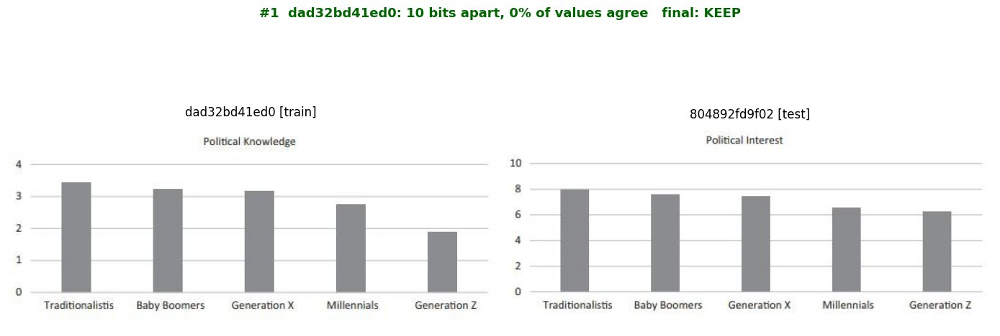

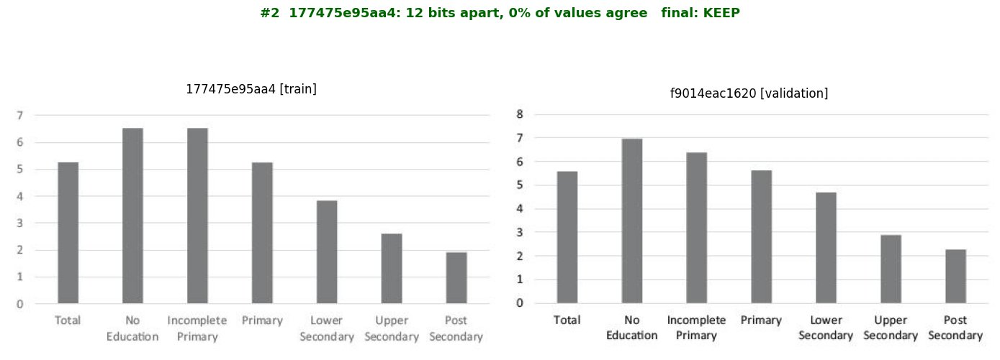

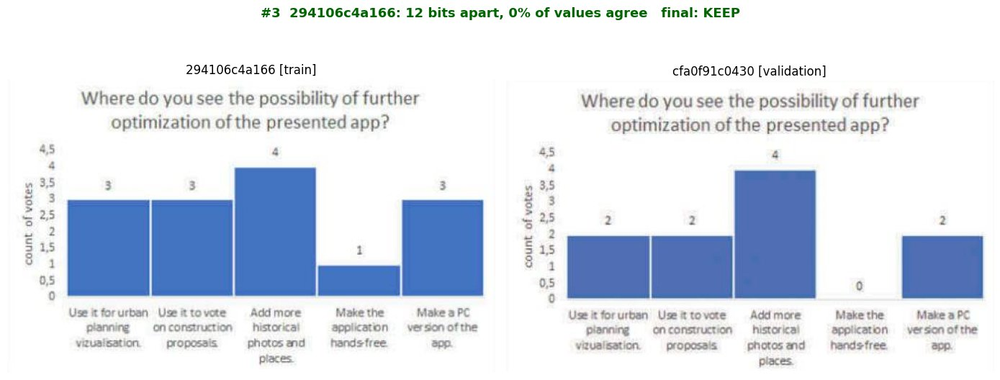

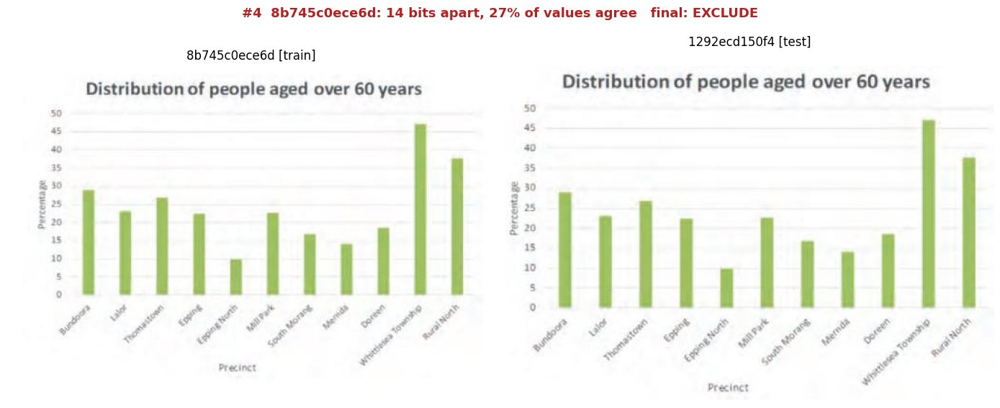

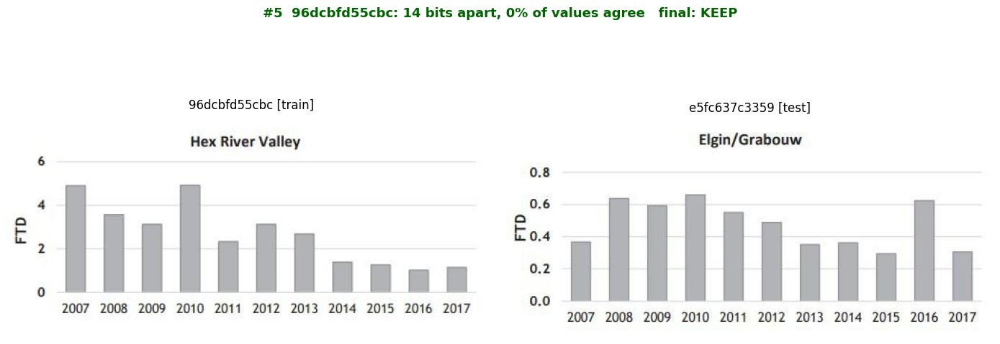

...

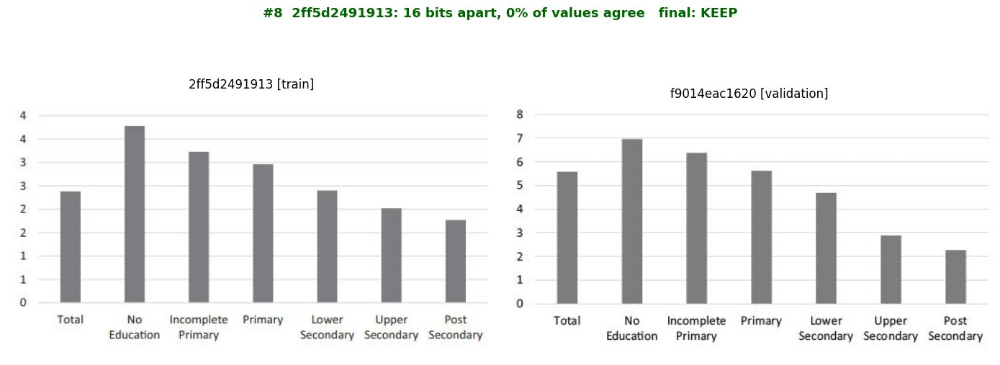

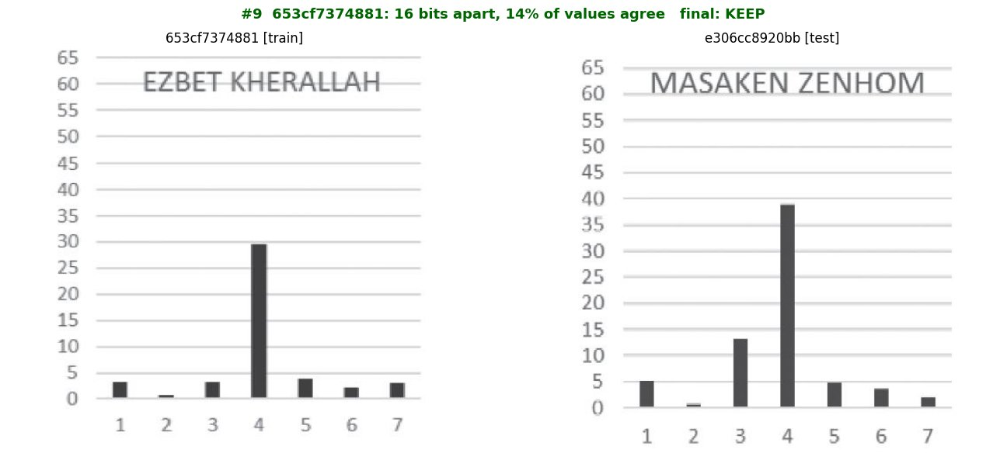

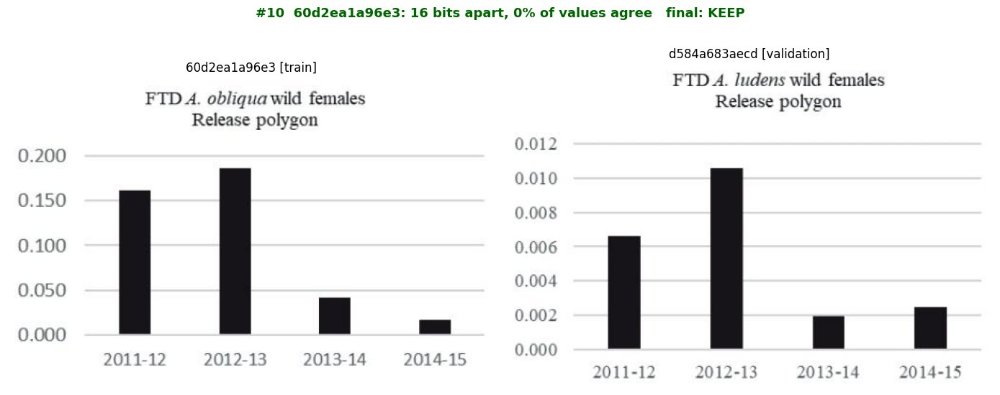

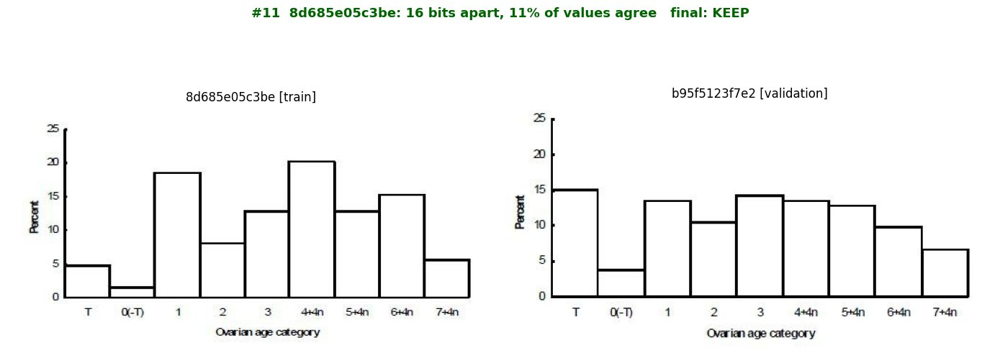

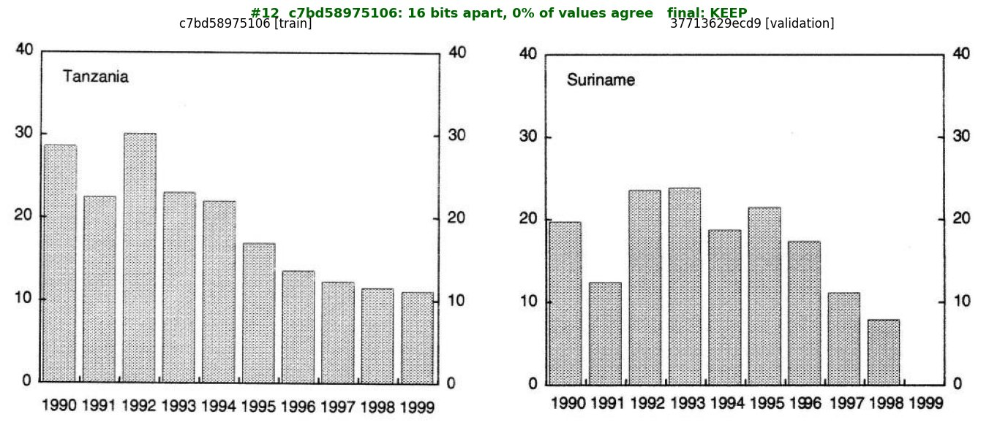

Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/results/step2e_visual_check.csv


In [24]:
output_banner("2e-ii visual check of the remaining ambiguous charts")

amb = dec[(dec["category"] == 3) & ~dec["chart_id"].isin(EXAMPLES)]["chart_id"]
check = (closest.loc[amb, ["split", "matched_id", "matched_split", "image_bits", "values_agree", "title", "matched_title"]]
         .sort_values("image_bits").reset_index())
check.insert(0, "no", range(1, len(check) + 1))
check["final"] = check["chart_id"].map(dec.set_index("chart_id")["final"])
check.to_csv(RESULTS_DIR / "step2e_visual_check.csv", index=False)
display(check)

with zipfile.ZipFile(KAGGLE_ZIP) as z:
    for _, r in check.iterrows():
        colour = "firebrick" if r["final"] == "exclude" else "darkgreen"
        show_pair(r["chart_id"], r["matched_id"], f"#{r['no']}  {r['chart_id']}: {r['image_bits']} bits apart, "
                  f"{r['values_agree']:.0%} of values agree   final: {r['final'].upper()}", colour, z)
print("Saved:", RESULTS_DIR / "step2e_visual_check.csv")

### 2e-iii — Visual check of real near-matches that Step 2 never flagged

**Why this cell exists.** Step 2 flags a real pair for exclusion only if the titles match, the labels and axes match,
or the pictures are ≤ 4 bits apart. Real pairs **6–10 bits apart with different titles and labels** were marked
"review only", and 2e reviews only flagged charts, so these pairs were never shown to anyone. 2e-i showed that two
copies of the same chart can carry different annotations, so different labels do not prove two charts are different
(for example "probability" vs "probablity", or "no e" vs "no education").

**What happens.** Every such pair whose charts are both still in the data is shown large, numbered, with both label
lists, earlier split on the left. **Rule (same as 2e-ii):** if the two charts look alike, add the left chart's ID to
`EXTRA_EXCLUDE` below with a short reason, and re-run this cell and 2f. 2f adds these charts to the final exclusion
list. Saved as `step2e_unflagged_real_check.csv`.

**Expected output:** a numbered list, then one image pair per row with its labels.

Real pairs 6-10 bits apart, never flagged, both charts still in the data: 27


,no,chart_id,split,matched_id,matched_split,image_bits,labels,matched_labels,final
0,1,e36f82f3bebc,train,2c1f66f6774a,test,6,japan ; hungary ; finland ; netherlands ; norw...,usa ; hong kong ; china ; ireland ; netherland...,keep
1,2,7933768500a5,train,dbb5678f99e8,test,6,msal ; msa2a ; msa2b ; howieson's poort/stillb...,msa1 ; msaa ; msa2b ; howieson's poort/stillba...,exclude
2,3,bc1c8f0c0b99,train,945a1a3d3856,validation,8,3-and 4-star general and flag officers ; all g...,venezuela ; saudi ; canada ; iran ; russia ; u...,keep
3,4,fa0caaf5cfbb,train,dedc6679f3ba,validation,8,radio ; twitter ; cricket media ; tv ; newspap...,50 ; 100 ; 150 ; 200 ; 250 ; 300 ; 350 ; 400 ;...,keep
4,5,920757797ac8,train,365d8d120764,test,8,1950 ; 1980 ; 2013 ; 2050 ; 2100,2001 ; 2001 ; 2002 ; 2003,keep
5,6,2f49ff73cf58,train,f9014eac1620,validation,8,total ; no e ; incomplete primary ; primary ; ...,total ; no education ; incomplete primary ; pr...,exclude
6,7,cb8167bade97,train,dedc6679f3ba,validation,8,0 ; 2 ; 3 ; 4 ; 6 ; 7 ; 9 ; 10 ; 11 ; 13,50 ; 100 ; 150 ; 200 ; 250 ; 300 ; 350 ; 400 ;...,keep
7,8,06c7b52ddf30,train,8ad89a001e54,test,8,dark ; milk ; caramel ; almonds,1981 ; 1990 ; 1999 ; 2015,keep
8,9,930bcd3dc9b8,validation,8c8b0d0ede0a,test,8,1950 ; 1980 ; 2013 ; 2050 ; 2100,"30-99 ; 100-299 ; 300-399 ; 1,000-4,999 ; more...",keep
9,10,06c7b52ddf30,train,d0776256aaa9,test,10,dark ; milk ; caramel ; almonds,1981 ; 1990 ; 1999 ; 2015,keep


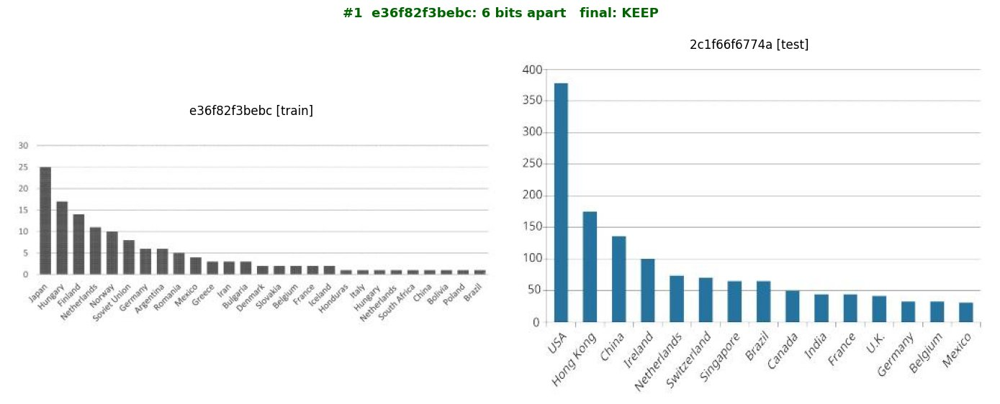

  labels  e36f82f3bebc: japan ; hungary ; finland ; netherlands ; norway ; soviet union ; germany ; argentina ; romania ; mexico ; greece ; iran ; bulgaria ; denmark ; slovak
  labels  2c1f66f6774a: usa ; hong kong ; china ; ireland ; netherlands ; switzerland ; singapore ; brazil ; canada ; india ; france ; u.k. ; germany ; belgium ; mexico


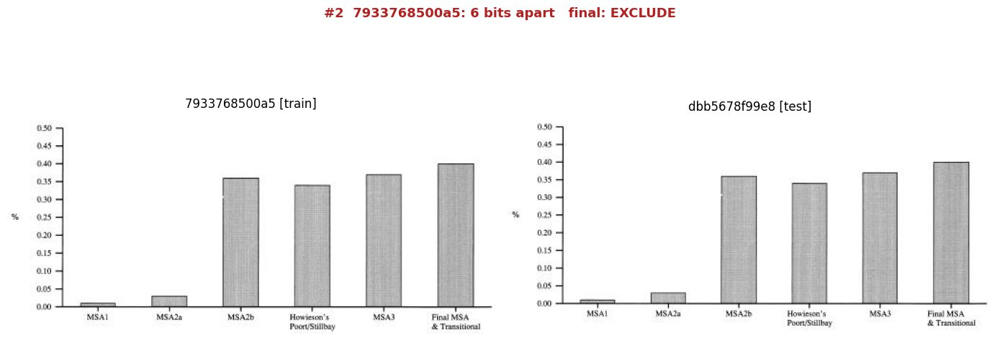

  labels  7933768500a5: msal ; msa2a ; msa2b ; howieson's poort/stillbay ; msa3 ; final msa & transitional
  labels  dbb5678f99e8: msa1 ; msaa ; msa2b ; howieson's poort/stillbay ; msa3 ; final msa & transitional


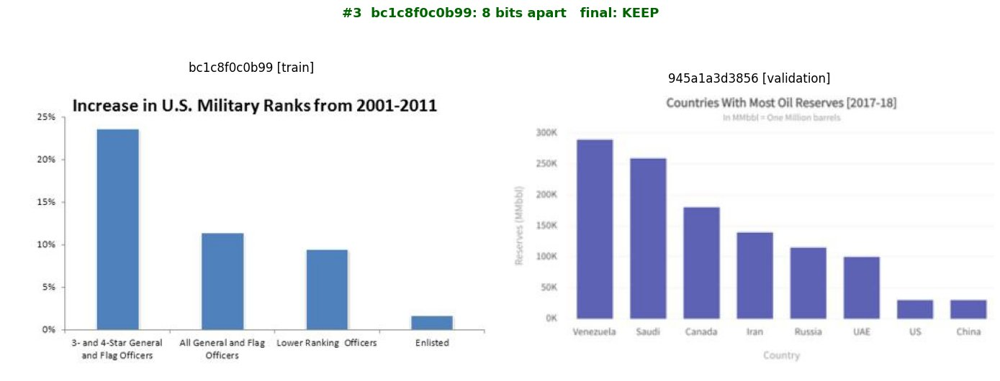

  labels  bc1c8f0c0b99: 3-and 4-star general and flag officers ; all general and flag officers ; lower ranking officers ; enlisted
  labels  945a1a3d3856: venezuela ; saudi ; canada ; iran ; russia ; uae ; us ; china


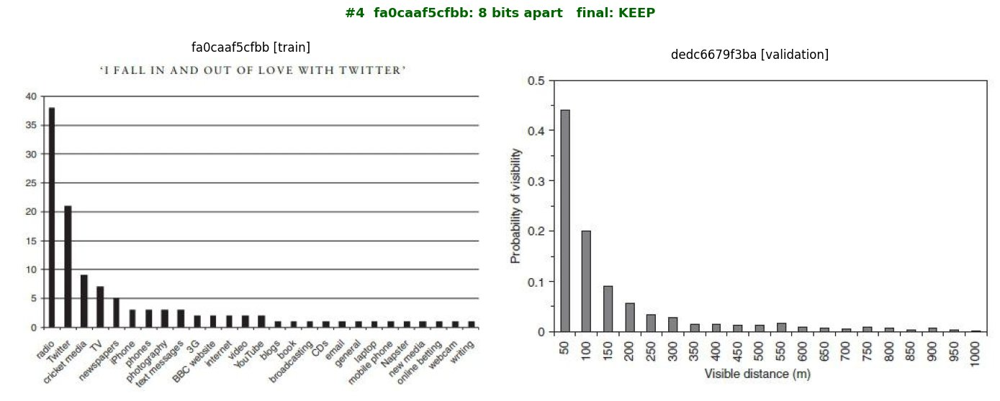

  labels  fa0caaf5cfbb: radio ; twitter ; cricket media ; tv ; newspapers ; iphone ; phones ; photography ; text messages ; 3g ; bbc website ; internet ; video ; youtube ; bl
  labels  dedc6679f3ba: 50 ; 100 ; 150 ; 200 ; 250 ; 300 ; 350 ; 400 ; 450 ; 500 ; 550 ; 600 ; 650 ; 700 ; 750 ; 800 ; 850 ; 900 ; 950 ; 1000


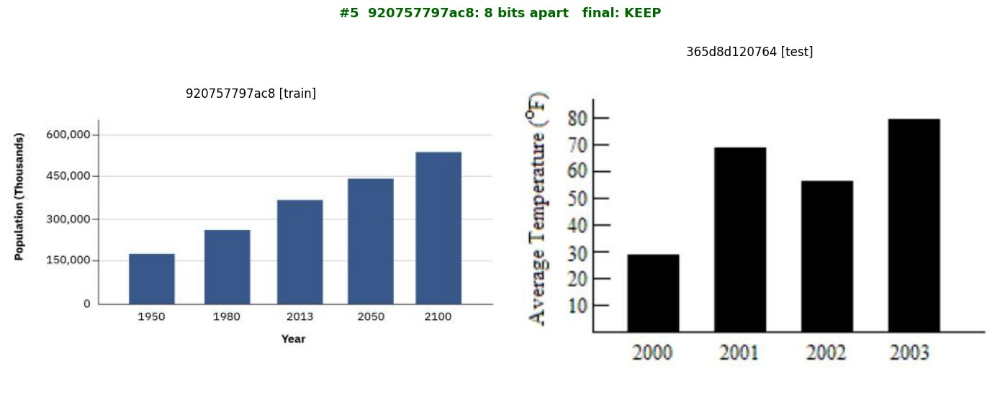

  labels  920757797ac8: 1950 ; 1980 ; 2013 ; 2050 ; 2100
  labels  365d8d120764: 2001 ; 2001 ; 2002 ; 2003


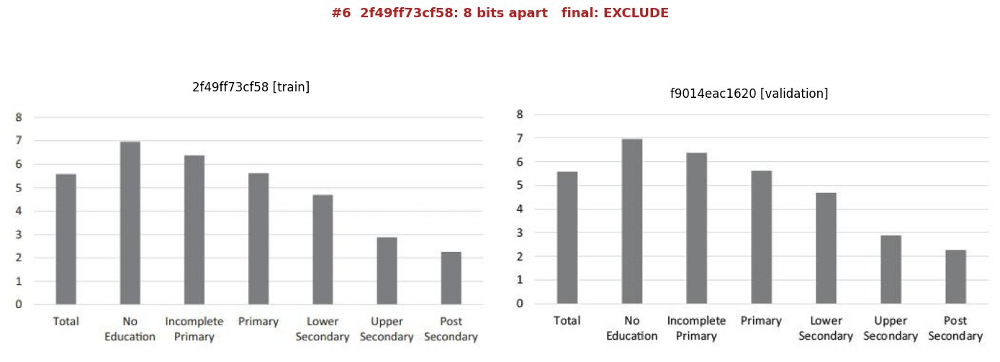

  labels  2f49ff73cf58: total ; no e ; incomplete primary ; primary ; lower secondary ; upper secondary ; post secondary
  labels  f9014eac1620: total ; no education ; incomplete primary ; primary ; lower secondary ; upper secondary ; post secondary


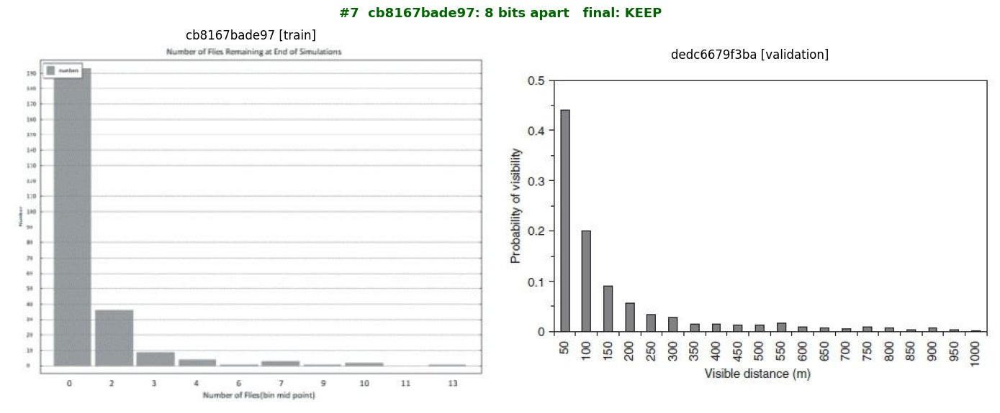

  labels  cb8167bade97: 0 ; 2 ; 3 ; 4 ; 6 ; 7 ; 9 ; 10 ; 11 ; 13
  labels  dedc6679f3ba: 50 ; 100 ; 150 ; 200 ; 250 ; 300 ; 350 ; 400 ; 450 ; 500 ; 550 ; 600 ; 650 ; 700 ; 750 ; 800 ; 850 ; 900 ; 950 ; 1000


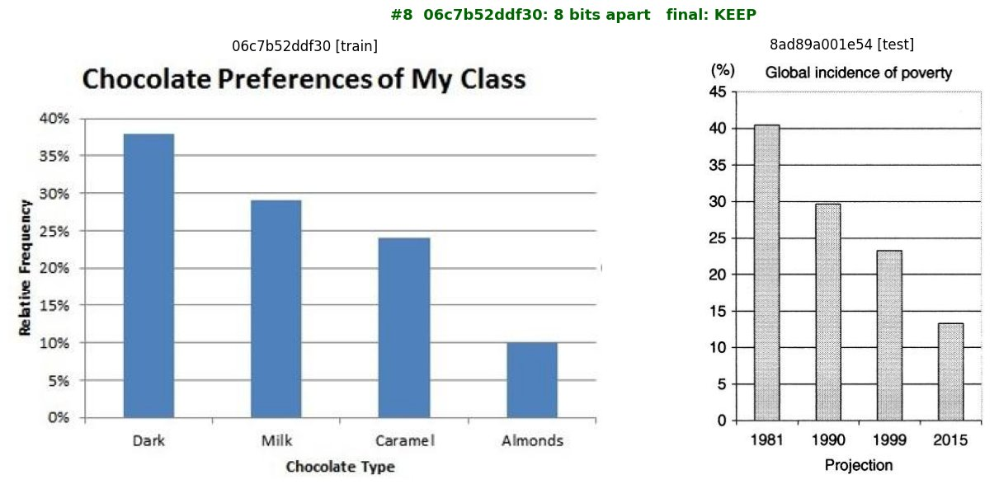

  labels  06c7b52ddf30: dark ; milk ; caramel ; almonds
  labels  8ad89a001e54: 1981 ; 1990 ; 1999 ; 2015


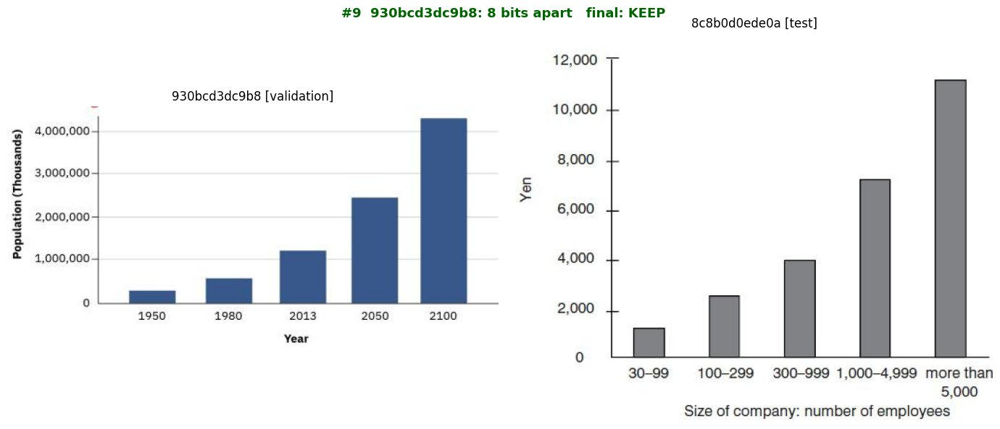

  labels  930bcd3dc9b8: 1950 ; 1980 ; 2013 ; 2050 ; 2100
  labels  8c8b0d0ede0a: 30-99 ; 100-299 ; 300-399 ; 1,000-4,999 ; more than 5,000


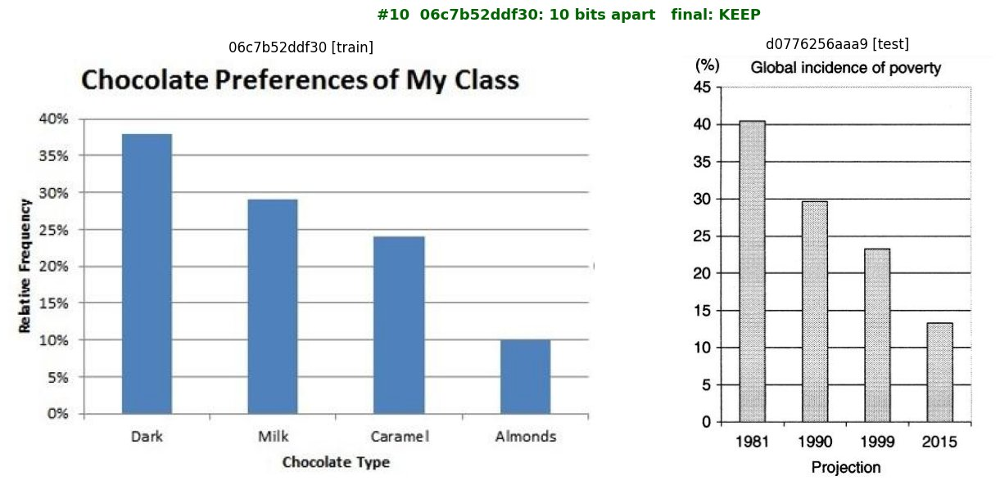

  labels  06c7b52ddf30: dark ; milk ; caramel ; almonds
  labels  d0776256aaa9: 1981 ; 1990 ; 1999 ; 2015


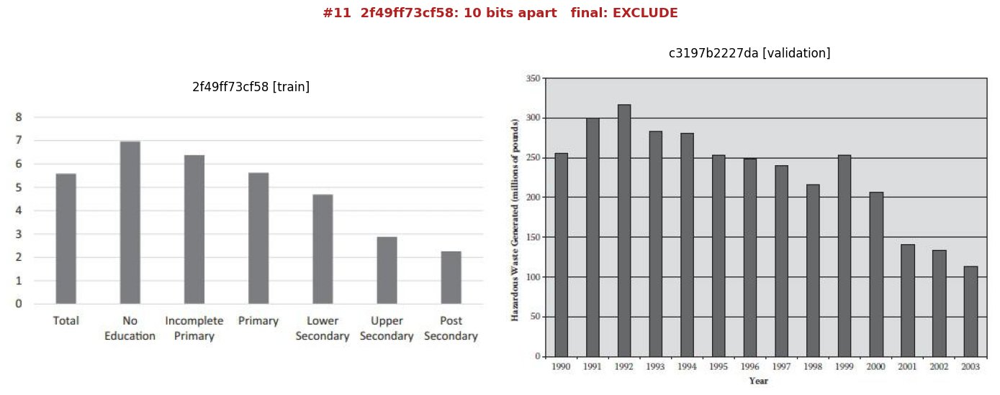

  labels  2f49ff73cf58: total ; no e ; incomplete primary ; primary ; lower secondary ; upper secondary ; post secondary
  labels  c3197b2227da: 1990 ; 1991 ; 1992 ; 1993 ; 1994 ; 1995 ; 1996 ; 1997 ; 1998 ; 1999 ; 2000 ; 2001 ; 2002 ; 2003


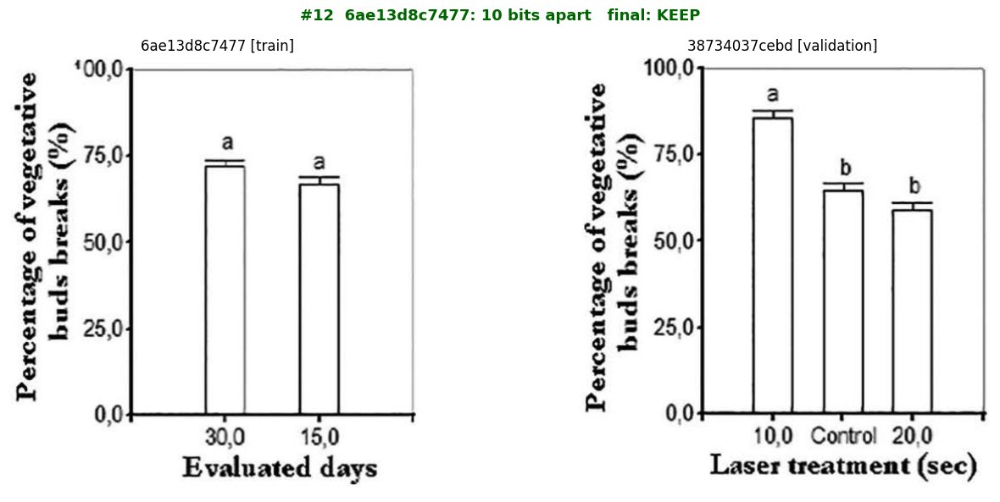

  labels  6ae13d8c7477: 30,0 ; 15,0
  labels  38734037cebd: 10,0 ; control ; 20,0


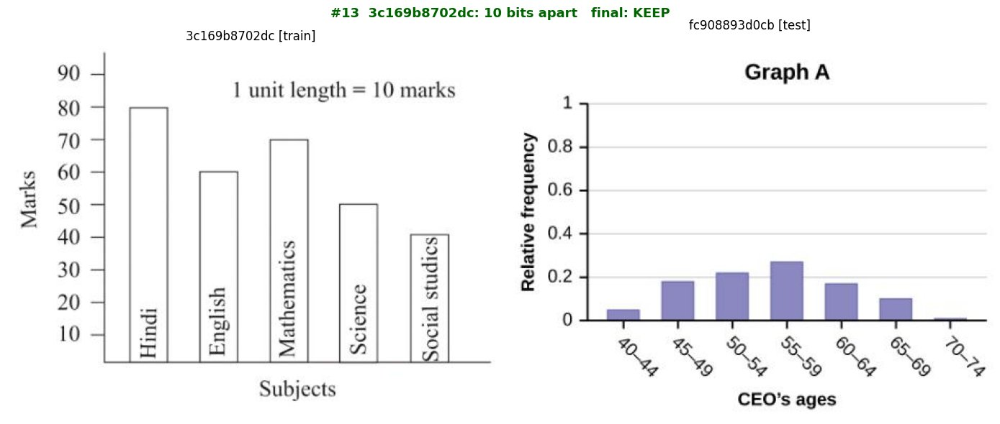

  labels  3c169b8702dc: hindi ; english ; mathematics ; science ; social studies
  labels  fc908893d0cb: 40-44 ; 45-49 ; 50-54 ; 55-59 ; 60-64 ; 65-69 ; 70-74


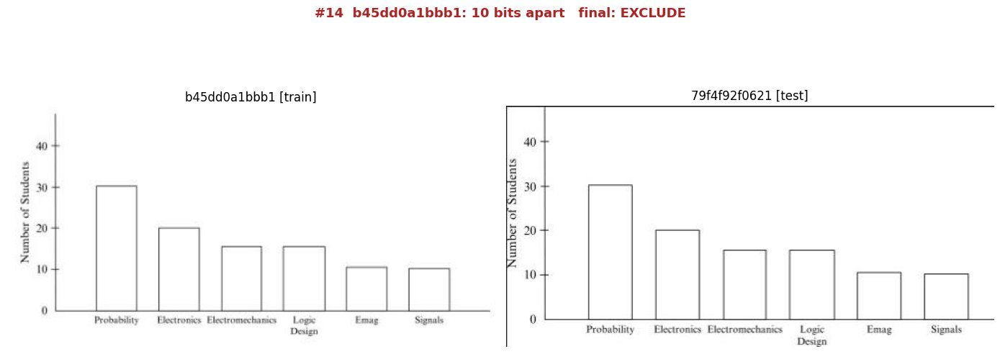

  labels  b45dd0a1bbb1: probability ; electronics ; electromechanics ; logic design ; emag ; signals
  labels  79f4f92f0621: probablity ; electronics ; electromechanics ; logic design ; emag ; signals


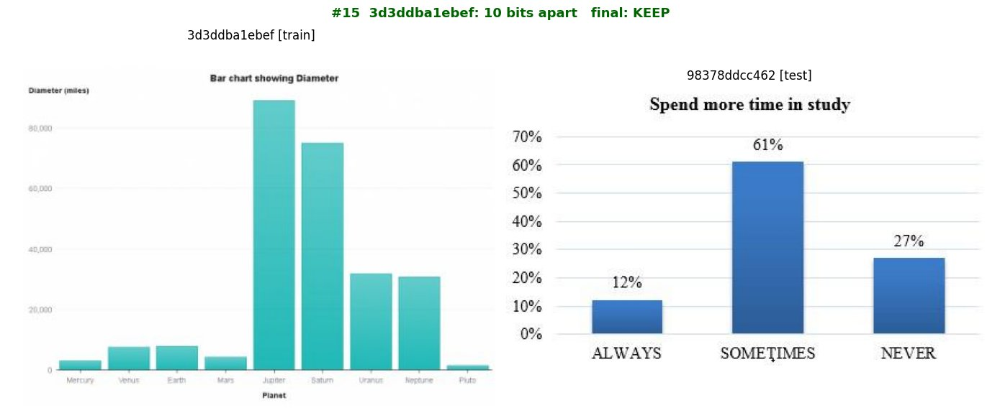

  labels  3d3ddba1ebef: mercury ; verus ; earth ; mars ; jupiter ; saturn ; uranus ; neptune ; pluto
  labels  98378ddcc462: always ; sometimes ; never


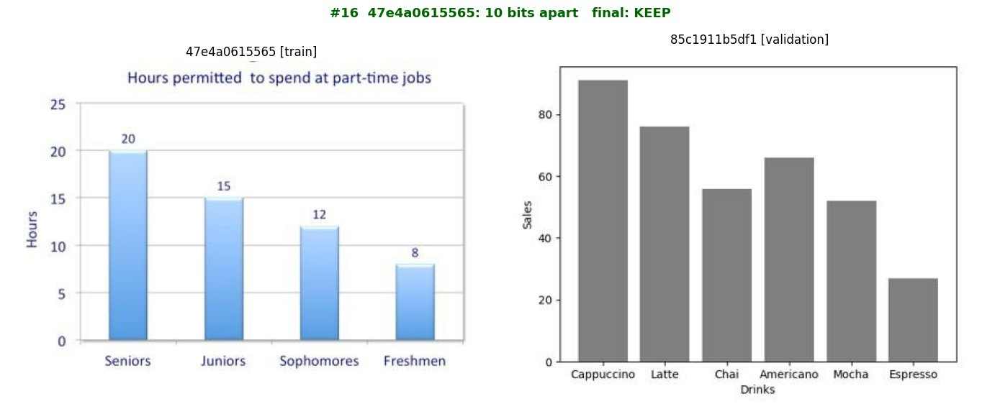

  labels  47e4a0615565: seniors ; juniors ; sophomores ; freshmen
  labels  85c1911b5df1: cappuccino ; latte ; chai ; americano ; mocha ; espresso


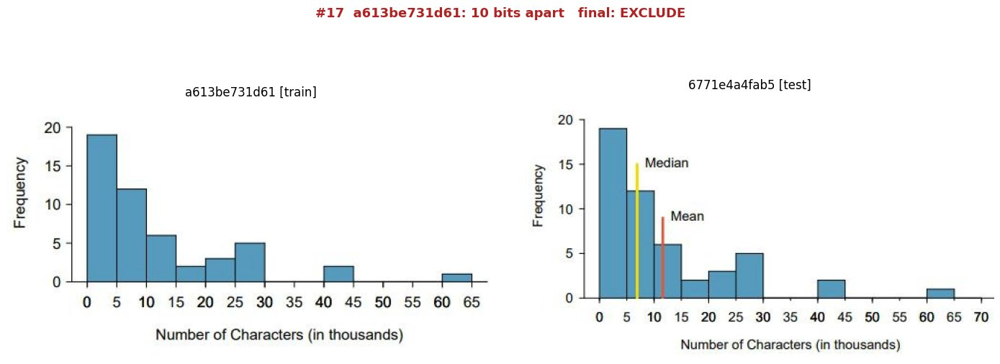

  labels  a613be731d61: 0 ; 5 ; 10 ; 15 ; 20 ; 25 ; 30 ; 35 ; 40 ; 45 ; 50 ; 55 ; 60 ; 65
  labels  6771e4a4fab5: 0 ; 5 ; 10 ; 15 ; 20 ; 25 ; 30 ; 35 ; 40 ; 45 ; 50 ; 55 ; 60 ; 65 ; 70


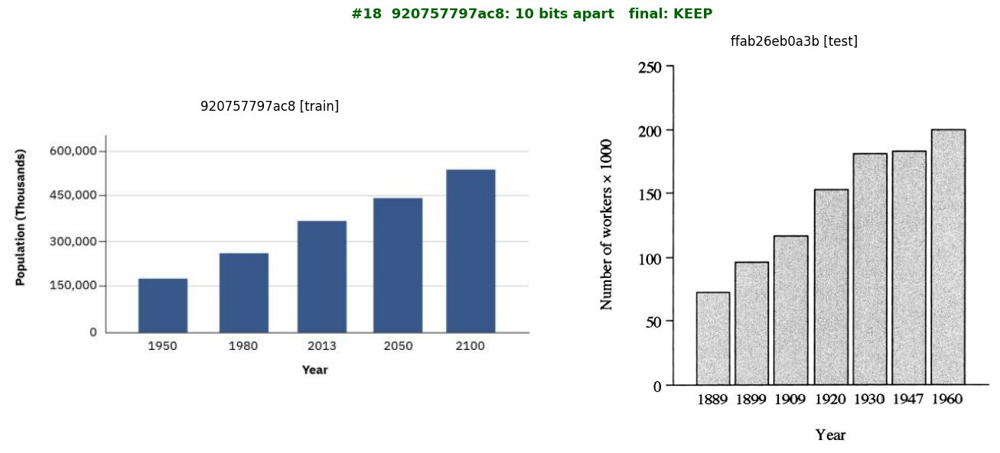

  labels  920757797ac8: 1950 ; 1980 ; 2013 ; 2050 ; 2100
  labels  ffab26eb0a3b: 1889 ; 1899 ; 1909 ; 1920 ; 1930 ; 1947 ; 1960


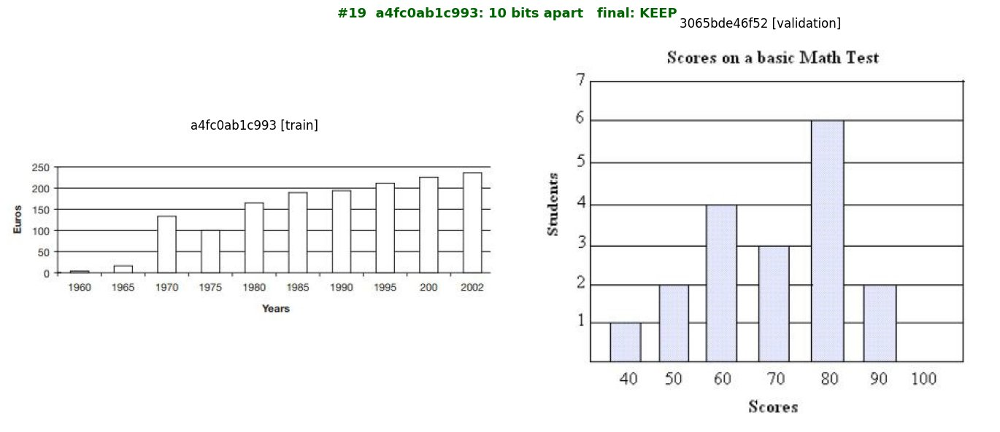

  labels  a4fc0ab1c993: 1960 ; 1965 ; 1970 ; 1975 ; 1980 ; 1985 ; 1990 ; 1995 ; 2000 ; 2002
  labels  3065bde46f52: 40 ; 50 ; 60 ; 70 ; 80 ; 90 ; 100


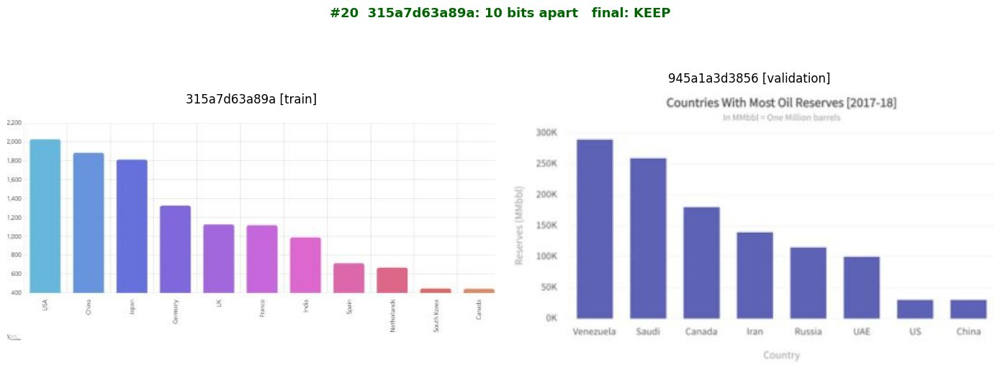

  labels  315a7d63a89a: usa ; china ; japan ; germany ; uk ; france ; india ; spain ; netherlands ; south korea ; canada
  labels  945a1a3d3856: venezuela ; saudi ; canada ; iran ; russia ; uae ; us ; china


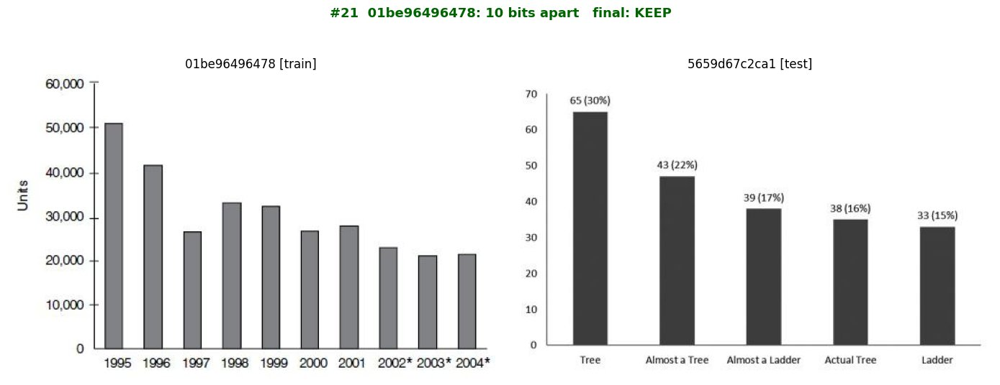

  labels  01be96496478: 1995 ; 1996 ; 1997 ; 1998 ; 1999 ; 2000 ; 2001 ; 2002* ; 2003* ; 2004*
  labels  5659d67c2ca1: tree ; almost a tree ; almost a ladder ; actual tree ; ladder


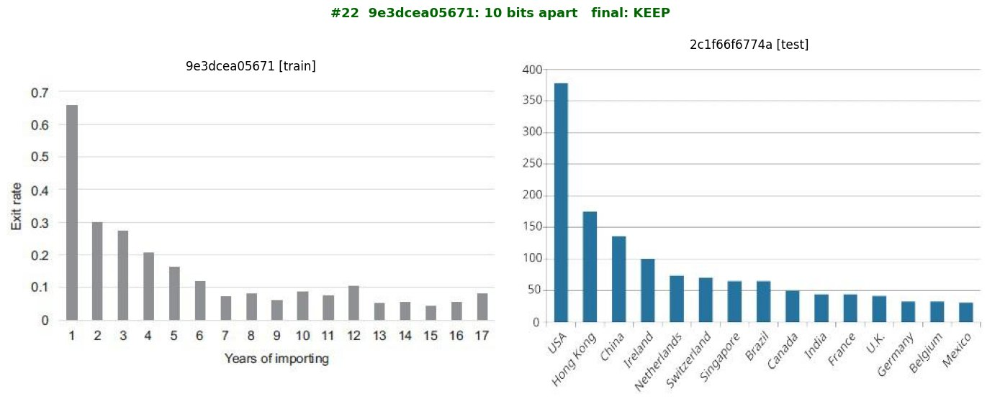

  labels  9e3dcea05671: 1 ; 2 ; 3 ; 4 ; 5 ; 6 ; 7 ; 8 ; 9 ; 10 ; 11 ; 12 ; 13 ; 14 ; 15 ; 16 ; 17
  labels  2c1f66f6774a: usa ; hong kong ; china ; ireland ; netherlands ; switzerland ; singapore ; brazil ; canada ; india ; france ; u.k. ; germany ; belgium ; mexico


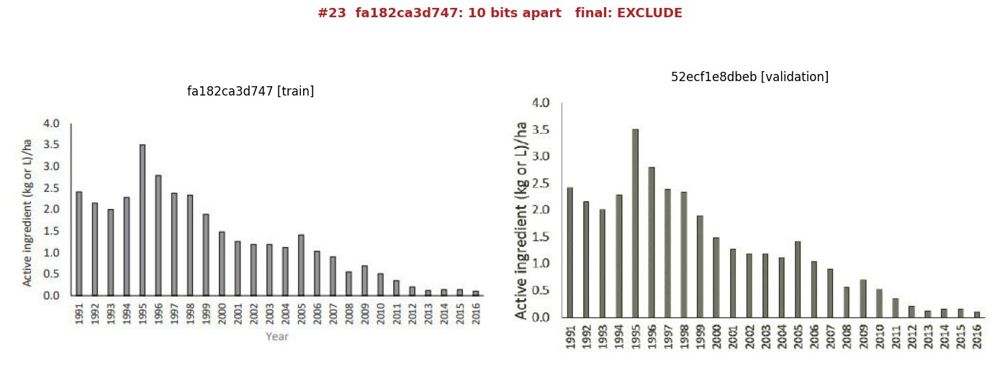

  labels  fa182ca3d747: 1991 ; 1992 ; 1993 ; 1994 ; 1995 ; 1996 ; 1997 ; 1998 ; 1999 ; 2000 ; 2001 ; 2002 ; 2003 ; 2004 ; 2005 ; 2006 ; 2007 ; 2008 ; 2009 ; 2010 ; 2011 ; 201
  labels  52ecf1e8dbeb: 1991 ; 1992 ; 1993 ; 1994 ; 1995 ; 1996 ; 1997 ; 1998 ; 1999 ; 2000 ; 2001 ; 2002 ; 2003 ; 2004 ; 2005 ; 2006 ; 2007 ; 2008 ; 2009 ; 2010 ; 2011 ; 201


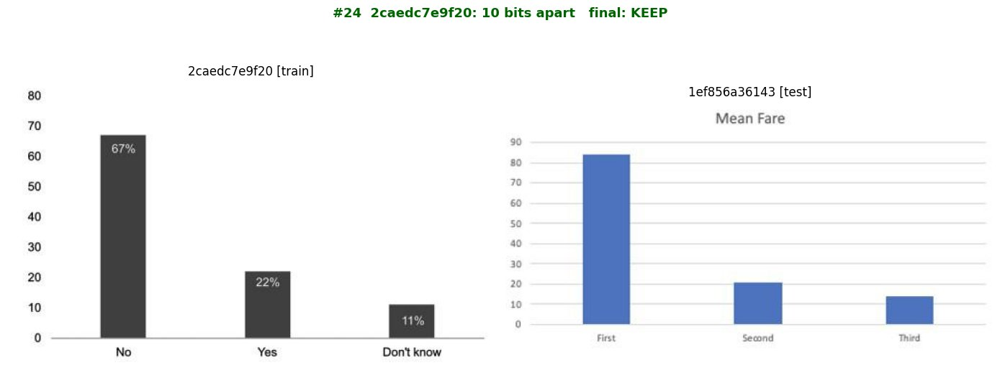

  labels  2caedc7e9f20: no ; yes ; don't know
  labels  1ef856a36143: first ; second ; third


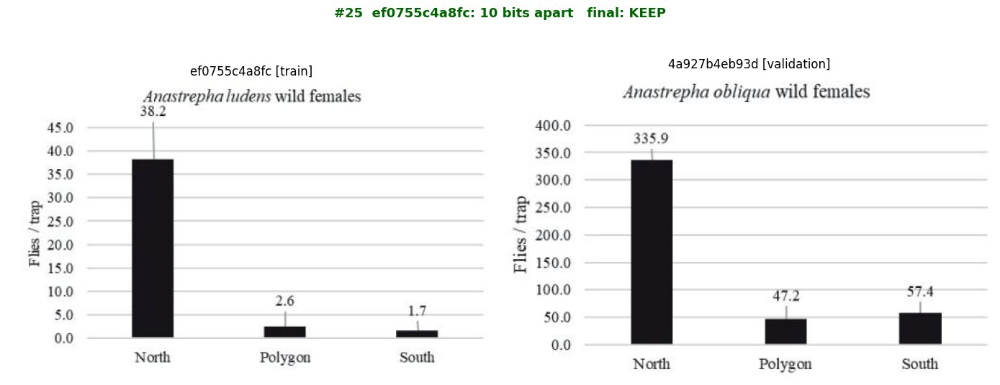

  labels  ef0755c4a8fc: north ; polygon ; south
  labels  4a927b4eb93d: north ; polygon ; south


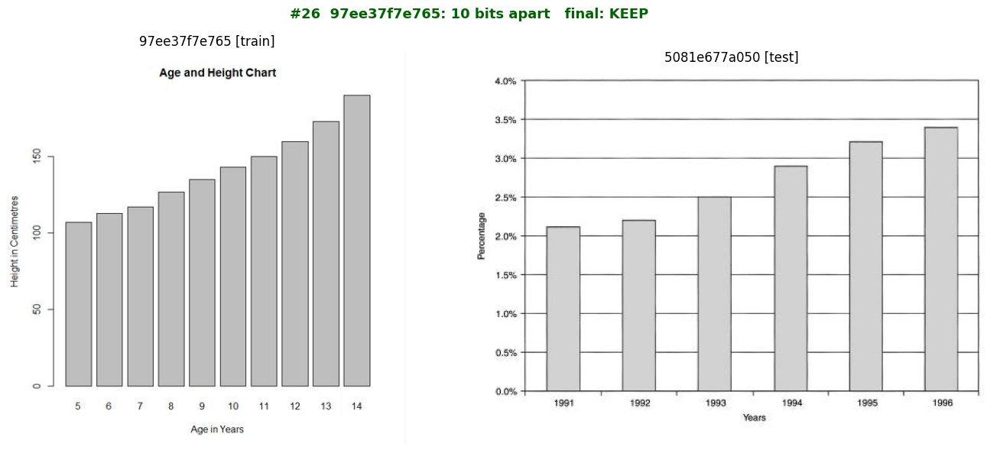

  labels  97ee37f7e765: 5 ; 6 ; 7 ; 8 ; 9 ; 10 ; 11 ; 12 ; 13 ; 14
  labels  5081e677a050: 1991 ; 1992 ; 1993 ; 1994 ; 1995 ; 1996


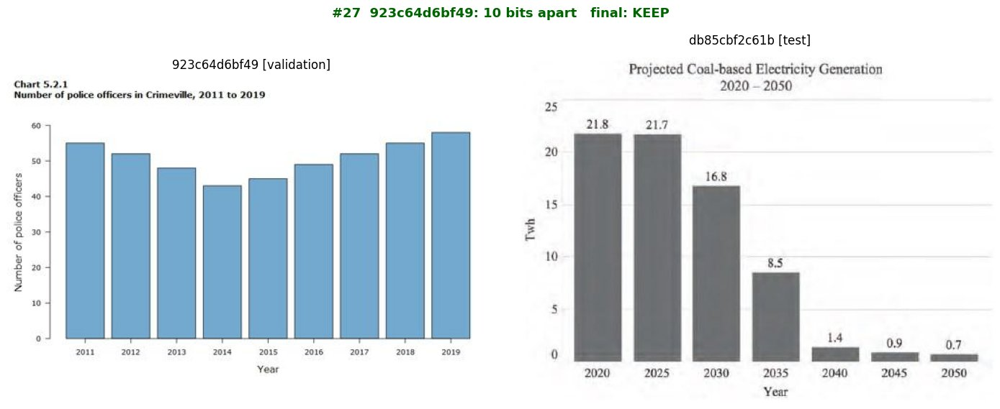

  labels  923c64d6bf49: 2011 ; 2012 ; 2013 ; 2014 ; 2015 ; 2016 ; 2017 ; 2018 ; 2019
  labels  db85cbf2c61b: 2020 ; 2025 ; 2030 ; 2035 ; 2040 ; 2045 ; 2050
Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/results/step2e_unflagged_real_check.csv


In [26]:
output_banner("2e-iii visual check of real near-matches never flagged")

EXTRA_EXCLUDE = {   # chart_id (left, earlier split) -> reason; filled in by AT after looking at the images (Nov 5 2026)
    "7933768500a5": "#2: same chart as test dbb5678f99e8 (6 bits); labels typed msal/msa2a vs msa1/msaa",
    "2f49ff73cf58": "#6: same chart as validation f9014eac1620 (8 bits); label 'no e' vs 'no education'",
    "b45dd0a1bbb1": "#14: same chart as test 79f4f92f0621 (10 bits); label 'probability' vs 'probablity'",
    "a613be731d61": "#17: same chart as test 6771e4a4fab5 (10 bits); 14 vs 15 bars annotated",
    "fa182ca3d747": "#23: same chart as validation 52ecf1e8dbeb (10 bits); same years, different axis titles",
}

out_now = set(step2_excl["chart_id"]) - set(dec.loc[dec["final"] == "keep", "chart_id"])   # same rule as 2f
cand = found[(found["leak"] == False) & found["check"].str.startswith("4")
             & ~found["chart_id_i"].isin(out_now) & ~found["chart_id_j"].isin(out_now)].copy()
swap = cand["split_i"].map(SPLIT_ORDER) > cand["split_j"].map(SPLIT_ORDER)     # earlier split on the left
for a, b in (("chart_id_i", "chart_id_j"), ("split_i", "split_j"), ("x_labels_i", "x_labels_j")):
    cand.loc[swap, [a, b]] = cand.loc[swap, [b, a]].to_numpy()
unflagged = (cand.sort_values("image_bits")
             .rename(columns={"chart_id_i": "chart_id", "split_i": "split", "chart_id_j": "matched_id",
                              "split_j": "matched_split", "x_labels_i": "labels", "x_labels_j": "matched_labels"})
             [["chart_id", "split", "matched_id", "matched_split", "image_bits", "labels", "matched_labels"]]
             .reset_index(drop=True))
unflagged.insert(0, "no", range(1, len(unflagged) + 1))
unflagged["final"] = np.where(unflagged["chart_id"].isin(EXTRA_EXCLUDE), "exclude", "keep")
unflagged["reason"] = unflagged["chart_id"].map(EXTRA_EXCLUDE).fillna("")
unflagged.to_csv(RESULTS_DIR / "step2e_unflagged_real_check.csv", index=False)
print(f"Real pairs 6-10 bits apart, never flagged, both charts still in the data: {len(unflagged)}")
display(unflagged.drop(columns=["reason"]))

with zipfile.ZipFile(KAGGLE_ZIP) as z:
    for _, r in unflagged.iterrows():
        colour = "firebrick" if r["final"] == "exclude" else "darkgreen"
        show_pair(r["chart_id"], r["matched_id"], f"#{r['no']}  {r['chart_id']}: {r['image_bits']} bits apart   "
                  f"final: {r['final'].upper()}", colour, z)
        print(f"  labels  {r['chart_id']}: {r['labels'][:150]}")
        print(f"  labels  {r['matched_id']}: {r['matched_labels'][:150]}")
print("Saved:", RESULTS_DIR / "step2e_unflagged_real_check.csv")

### 2e+ — Why two identical-looking charts disagree: annotation differences

**The question.** Some flagged pairs are the *same picture* (image distance 0–4 bits) yet their data tables are
"different". For example, the candy chart appears in train (4dd42679f593), validation (22a3eae32699) and test
(b7d30144d9d4) with the same image, but only 80 % of the values agree between the validation and test copies.
The table comes from each chart's **annotation file** in the Kaggle dataset (the answer key Benetech supplied),
not from anything we compute, so the difference must be in the annotations themselves.

**What this cell does.**
1. Shows the three candy pictures next to each other, each titled with its annotated values and its score
   against the train annotation. Then prints the three annotations side by side: every bar's label and value, the difference and the
   percentage difference, so you can see exactly which bar the annotators read differently.
2. Scores one annotation **against the other** with the same Benetech metric we use for the models. This measures
   how much the answer key's own disagreement would cost a model that reproduced one annotation perfectly.
3. Does the same for **every** real pair with near-identical pictures (≤ 4 bits), as a summary table.

**How to read it.** A score of 1.0 means the two annotations are identical. Just below 1.0 means a small
reading difference, which is noise in the answer key. A model is scored against one of these annotations,
so this is the ceiling a perfect reader could reach on that chart. It applies equally to every model.

**Expected output:** the candy tables, then a summary table of all near-identical real pairs with their
agreement and the score of one annotation against the other.

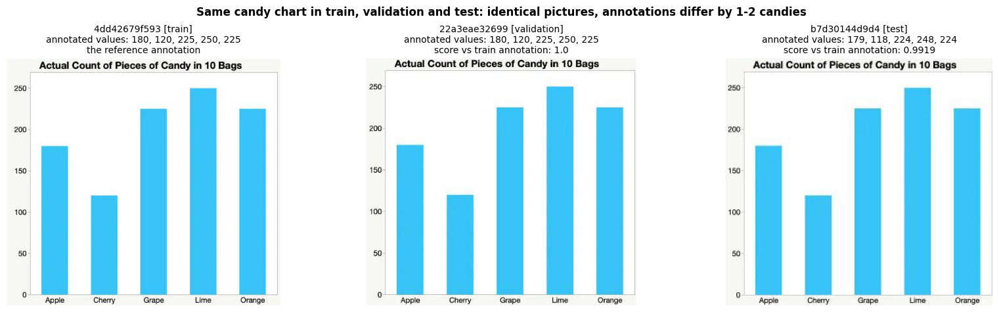

Candy chart ('Actual Count of Pieces of Candy in 10 Bags'): the three annotations side by side


,bar,label 4dd42679f593 [train],value 4dd42679f593,label 22a3eae32699 [validation],value 22a3eae32699,label b7d30144d9d4 [test],value b7d30144d9d4,diff 22a3eae32699 - 4dd42679f593,% diff 22a3eae32699,diff b7d30144d9d4 - 4dd42679f593,% diff b7d30144d9d4
0,1,Apple,180.0,Apple,180.0,Apple,179.0,0.0,0.0,-1.0,-0.56
1,2,Cherry,120.0,Cherry,120.0,Cherry,118.0,0.0,0.0,-2.0,-1.67
2,3,Grape,225.0,Grape,225.0,Grape,224.0,0.0,0.0,-1.0,-0.44
3,4,Lime,250.0,Lime,250.0,Lime,248.0,0.0,0.0,-2.0,-0.80
4,5,Orange,225.0,Orange,225.0,Orange,224.0,0.0,0.0,-1.0,-0.44


  22a3eae32699 scored against 4dd42679f593 as if it were a model's prediction: 1.0
  b7d30144d9d4 scored against 4dd42679f593 as if it were a model's prediction: 0.9919

All real pairs with near-identical pictures (<= 4 bits): 26


,chart,split,matched,matched_split,image_bits,bars,values_agree,bars_off_>1%,largest_%_diff,score_one_vs_other
21,36f373c43482,validation,1f7473bf7a1a,test,4,5 vs 5,0.60,2,1.49,0.9733
18,d3601ea43b66,train,db85cbf2c61b,test,4,7 vs 7,0.29,5,91.09,0.9860
23,d18ea652ebfe,train,a36dd45a2c82,validation,2,10 vs 10,0.40,3,4.26,0.9873
22,cbf8bcdb153d,train,674453f6d8a1,validation,4,4 vs 4,0.75,0,0.00,0.9907
4,4dd42679f593,train,b7d30144d9d4,test,0,5 vs 5,0.80,1,1.67,0.9919
12,c91f34167d34,train,ffab26eb0a3b,test,4,7 vs 7,0.43,4,1.32,0.9919
20,22a3eae32699,validation,b7d30144d9d4,test,0,5 vs 5,0.80,1,1.67,0.9919
8,8ef0ccf95bec,train,e720cd5e3189,validation,0,5 vs 5,1.00,0,0.12,0.9938
25,e720cd5e3189,validation,8ef0ccf95bec,train,0,5 vs 5,1.00,0,0.12,0.9938
14,5585994bc3e0,train,338691f62999,test,2,8 vs 8,1.00,0,0.72,0.9959


Annotations identical (score 1.0): 8 of 26 pairs; lowest score of one annotation against the other: 0.9733


In [28]:
output_banner("2e+ annotation differences")

def side_by_side(ids):
    tables = {c: read_table(c) for c in ids}
    n = max(len(t[0]) for t in tables.values())
    rows = []
    for k in range(n):
        row = {"bar": k + 1}
        for c in ids:
            xs, ys = tables[c]
            row[f"label {c} [{member_of.at[c, 'split']}]"] = xs[k] if k < len(xs) else "-"
            row[f"value {c}"] = ys[k] if k < len(ys) else np.nan
        rows.append(row)
    df = pd.DataFrame(rows)
    ref = ids[0]
    for c in ids[1:]:
        df[f"diff {c} - {ref}"] = df[f"value {c}"] - df[f"value {ref}"]
        df[f"% diff {c}"] = (100 * df[f"diff {c} - {ref}"] / df[f"value {ref}"].abs()).round(2)
    return df, tables

def annotation_vs_annotation(a, b):
    (xa, ya), (xb, yb) = read_table(a), read_table(b)
    return round(ce.benetech_strict_score(xa, ya, xb, yb), 4)

with tp.step_log(REPORT_FILE, "Step 2e+ - annotation differences on identical-looking charts"):
    CANDY = ["4dd42679f593", "22a3eae32699", "b7d30144d9d4"]      # train, validation, test copies
    candy = [c for c in CANDY if c in member_of.index]
    if len(candy) >= 2:
        # the candy pictures: same image in every split, but each copy has its own human annotation
        with zipfile.ZipFile(KAGGLE_ZIP) as z:
            fig, axes = plt.subplots(1, len(candy), figsize=(5.5 * len(candy), 4.8))
            for ax, c in zip(axes, candy):
                ax.imshow(Image.open(io.BytesIO(z.read(member_of.at[c, "image_member"])))); ax.axis("off")
                ys = read_table(c)[1]
                sub = "the reference annotation" if c == candy[0] else \
                      f"score vs train annotation: {annotation_vs_annotation(candy[0], c)}"
                ax.set_title(f"{c} [{member_of.at[c, 'split']}]\nannotated values: "
                             f"{', '.join(f'{v:g}' for v in ys)}\n{sub}", fontsize=10)
            fig.suptitle("Same candy chart in train, validation and test: identical pictures, annotations differ by 1-2 candies",
                         fontsize=12, fontweight="bold")
            plt.tight_layout(); plt.show()
        print("Candy chart ('Actual Count of Pieces of Candy in 10 Bags'): the three annotations side by side")
        df_candy, _ = side_by_side(candy)
        display(df_candy)
        for c in candy[1:]:
            print(f"  {c} scored against {candy[0]} as if it were a model's prediction: "
                  f"{annotation_vs_annotation(candy[0], c)}")

    near = review_pairs[review_pairs["image_bits"] <= NEAR_IMAGE].drop_duplicates(["chart_id", "matched_id"])
    summary_rows = []
    for _, p in near.iterrows():
        (xa, ya), (xb, yb) = read_table(p["chart_id"]), read_table(p["matched_id"])
        same_len = len(ya) == len(yb)
        pct = (np.abs(yb - ya) / np.maximum(np.abs(ya), 1e-9) * 100) if same_len else np.array([np.nan])
        summary_rows.append({"chart": p["chart_id"], "split": p["split"], "matched": p["matched_id"],
                             "matched_split": p["matched_split"], "image_bits": p["image_bits"],
                             "bars": f"{len(ya)} vs {len(yb)}", "values_agree": p["values_agree"],
                             "bars_off_>1%": int(np.nansum(pct > 1)) if same_len else "row count differs",
                             "largest_%_diff": round(float(np.nanmax(pct)), 2) if same_len else np.nan,
                             "score_one_vs_other": annotation_vs_annotation(p["chart_id"], p["matched_id"])})
    annot_summary = pd.DataFrame(summary_rows).sort_values("score_one_vs_other")
    annot_summary.to_csv(RESULTS_DIR / "step2e_annotation_differences.csv", index=False)
    print(f"\nAll real pairs with near-identical pictures (<= {NEAR_IMAGE} bits): {len(annot_summary)}")
    display(annot_summary)
    exact = int((annot_summary["score_one_vs_other"] >= 0.9999).sum())
    print(f"Annotations identical (score 1.0): {exact} of {len(annot_summary)} pairs; "
          f"lowest score of one annotation against the other: {annot_summary['score_one_vs_other'].min()}")

### 2f — Final exclusion list and re-check for remaining overlap

**What happens.** Builds the final exclusion list from: every generated chart Step 2 excluded (unchanged; these are
look-alikes and we have plenty to spare) **plus** only the real charts whose final decision in 2e is `exclude`, **plus** the charts added to
`EXTRA_EXCLUDE` in 2e-iii.
Then it re-runs the content checks on what is left: it lists every cross-split pair that still exists between
remaining charts and confirms that none is an identical table or a near-identical image with the same labels
(category 1). Remaining pairs are only the ones the review judged not to be leaks.

Saved as a **new** file, `step2f_final_exclusions.csv`. Step 3 reads this file, not the Step 2 one.

The pairs that remain are broken down by kind, so every one is accounted for.

**Expected output:** real charts per split after the review, `Identical tables left across splits: 0`,
`Near-identical images with same labels left: 0`, and the proposed 3,500-chart distribution.

In [30]:
output_banner("2f final exclusions and re-check")

with tp.step_log(REPORT_FILE, "Step 2f - final exclusions after review"):
    keep_real = set(dec.loc[dec["final"] == "keep", "chart_id"])
    final_excl = step2_excl[~step2_excl["chart_id"].isin(keep_real)].copy()
    final_excl["decided_by"] = np.where(final_excl["source"] == "extracted", "step2e review", "step2 rule")
    extra = pd.DataFrame([{"chart_id": cid, "split": member_of.at[cid, "split"], "source": "extracted",
                           "reason": why, "matches": "", "matches_split": "", "decided_by": "step2e-iii visual check"}
                          for cid, why in EXTRA_EXCLUDE.items()], columns=final_excl.columns)
    final_excl = pd.concat([final_excl, extra], ignore_index=True)
    print(f"Excluded: {len(final_excl)} = Step 2 {len(step2_excl)} - kept after 2e review {len(keep_real)}"
          f" + added in 2e-iii {len(extra)}")
    final_excl.to_csv(RESULTS_DIR / "step2f_final_exclusions.csv", index=False)

    out = set(final_excl["chart_id"])
    left = found[~found["chart_id_i"].isin(out) & ~found["chart_id_j"].isin(out)]
    ident = left[left["table_hash_i"] == left["table_hash_j"]]
    near  = left[(left["image_bits"] <= NEAR_IMAGE) & (left["x_labels_i"] == left["x_labels_j"])]
    real_left = left["source_i"].eq("extracted") & left["source_j"].eq("extracted")
    print(f"Cross-split pairs left among remaining charts: {len(left)}")
    print(f"  generated look-alikes (<= 4 bits, different labels): {int((~real_left).sum())}")
    print(f"  real pairs reviewed in 2e and kept:                  {int((real_left & (left['leak'] == True)).sum())}")
    print(f"  real pairs checked by eye in 2e-iii and kept:        {int((real_left & (left['leak'] == False)).sum())}")
    print(f"Identical tables left across splits: {len(ident)}")
    print(f"Near-identical images with same labels left: {len(near)}")
    assert ident.empty and near.empty, "A confirmed duplicate is still in the data - check the overrides."

    rows = []
    for s in ("train", "validation", "test"):
        pool = splits[s][~splits[s]["chart_id"].isin(out)]
        n_real = int((pool["source"] == "extracted").sum())
        target = {"train": 2450, "validation": 525, "test": 525}[s]
        rows.append({"split": s, "excluded": int(splits[s]["chart_id"].isin(out).sum()),
                     "real left": n_real, "real kept vs Step 2": n_real - int(((splits[s]["source"] == "extracted")
                                                                             & ~splits[s]["chart_id"].isin(step2_excl["chart_id"])).sum()),
                     "generated to draw": target - n_real, "subset total": target})
    plan3 = pd.DataFrame(rows)
    plan3.loc[len(plan3)] = ["total", *plan3.iloc[:, 1:].sum()]
    display(plan3)
    print("Saved:", RESULTS_DIR / "step2f_final_exclusions.csv")

Excluded: 771 = Step 2 793 - kept after 2e review 27 + added in 2e-iii 5
Cross-split pairs left among remaining charts: 1284
  generated look-alikes (<= 4 bits, different labels): 1227
  real pairs reviewed in 2e and kept:                  36
  real pairs checked by eye in 2e-iii and kept:        21
Identical tables left across splits: 0
Near-identical images with same labels left: 0


,split,excluded,real left,real kept vs Step 2,generated to draw,subset total
0,train,679,287,20,2163,2450
1,validation,92,64,2,461,525
2,test,0,69,0,456,525
3,total,771,420,22,3080,3500


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/results/step2f_final_exclusions.csv


## Step 3 — Draw the 3,500-chart subset (professor-approved)

**Why a subset.** Training MatCha on all 13,432 training charts would take 70–95 minutes per epoch on a T4.
The professor approved 3,500 vertical bar charts instead, which brings an epoch down to about 15–18 minutes and
leaves room for early stopping with up to 100 epochs.

**How the charts are chosen.**
1. Start from the frozen V3.3.2 splits and **remove every chart on the final exclusion list** from 2f
   (Step 2's generated look-alikes plus the real charts the 2e review confirmed as leaks).
2. **Keep every remaining real chart** (`source = extracted`). Real charts are scarce and are the deciding evidence
   (professor's comment #4), so none are sampled away. All 69 real test charts are always kept.
3. **Fill the rest with generated charts**, sampled at random with seed 42, so each split reaches its target:
   2,450 train, 525 validation, 525 test (70 / 15 / 15 %, the same proportions as the full split).
4. Each chart stays in the split it was already in. Nothing is reshuffled, so no test chart can move into training.

**Checks.** Totals must be exactly 2,450 / 525 / 525 = 3,500; every real chart left after Step 2 must be present;
no chart ID in two splits; no excluded chart in the subset. The three lists are saved to Drive, and every later
step reads them from there, so all runs use exactly the same charts.

**Expected output:** a table of the subset (generated and real per split) and `Subset saved`.

In [31]:
output_banner("Step 3 draw the 3,500 charts")

STEP3_APPROVED = True   # set to True only after you have reviewed 2e/2f and approved the exclusions
assert STEP3_APPROVED, "Step 3 is locked until the 2e review is approved (set STEP3_APPROVED = True)."

SUBSET_SEED  = 42
SUBSET_SIZES = {"train": 2450, "validation": 525, "test": 525}
SUBSET_DIR   = RESULTS_DIR / "subset_3500"
SUBSET_DIR.mkdir(parents=True, exist_ok=True)

with tp.step_log(REPORT_FILE, "Step 3 - draw the 3,500-chart subset"):
    excluded = set(pd.read_csv(RESULTS_DIR / "step2f_final_exclusions.csv")["chart_id"])
    rng = np.random.default_rng(SUBSET_SEED)
    subset, rows = {}, []
    for s in ("train", "validation", "test"):                      # fixed order -> reproducible draws
        pool = splits[s][~splits[s]["chart_id"].isin(excluded)]
        real = pool[pool["source"] == "extracted"]
        gen  = pool[pool["source"] == "generated"].sort_values("chart_id")   # sort first: draw does not depend on file order
        n_gen = SUBSET_SIZES[s] - len(real)
        assert 0 < n_gen <= len(gen), f"{s}: cannot draw {n_gen} generated charts from {len(gen)}"
        pick = gen.iloc[np.sort(rng.choice(len(gen), size=n_gen, replace=False))]
        subset[s] = pd.concat([real, pick]).sort_values("chart_id").reset_index(drop=True)
        rows.append({"split": s, "excluded (2f)": int(splits[s]["chart_id"].isin(excluded).sum()),
                     "real kept": len(real), "generated drawn": n_gen, "subset total": len(subset[s])})

    # checks
    for s, df in subset.items():
        assert len(df) == SUBSET_SIZES[s] and df["chart_id"].is_unique
        assert not set(df["chart_id"]) & excluded, f"{s}: excluded chart in subset"
    all_ids = [set(df["chart_id"]) for df in subset.values()]
    assert not (all_ids[0] & all_ids[1] or all_ids[0] & all_ids[2] or all_ids[1] & all_ids[2]), "overlap"
    table3 = pd.DataFrame(rows)
    table3.loc[len(table3)] = ["total", *table3.iloc[:, 1:].sum()]
    display(table3)

    # save (re-running gives the identical subset; a different subset on Drive is an error, never overwritten)
    for s, df in subset.items():
        f = SUBSET_DIR / f"{s}_subset3500.csv"
        if f.is_file():
            old = pd.read_csv(f)
            assert old["chart_id"].tolist() == df["chart_id"].tolist(), f"{f.name} on Drive differs from this draw"
        else:
            df.to_csv(f, index=False)
    tp.save_json({"seed": SUBSET_SEED, "sizes": SUBSET_SIZES, "excluded_final_2f": len(excluded),
                  "real_per_split": {s: int((df["source"] == "extracted").sum()) for s, df in subset.items()},
                  "sha256": {s: tp.file_sha256(SUBSET_DIR / f"{s}_subset3500.csv") for s in subset}},
                 SUBSET_DIR / "subset_manifest.json")
    print("Subset saved to", SUBSET_DIR)

,split,excluded (2f),real kept,generated drawn,subset total
0,train,679,287,2163,2450
1,validation,92,64,461,525
2,test,0,69,456,525
3,total,771,420,3080,3500


Subset saved to /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/results/subset_3500


## Step 4 — Re-train the seed-42 pilot on Colab (same-platform reference)

**Why this step.** The midterm pilot compared DePlot and MatCha after the same short training: 256 training
charts, 2 epochs, seed 42, AdamW 2e-5, effective batch 4. It ran on a Windows T4 VM, and its checkpoints were not
backed up. Phase B runs on Colab, so we re-train both pilot models here with **the same code (V3.4.6, checksum-verified
in 1c), the same charts and the same settings**. This gives:

1. **A reproducibility check.** If Colab gives about the same validation loss and score as the midterm, the platform
   change did not change the results, and every later comparison is like for like.
2. **The models later steps need.** Step 6 (explaining DePlot's zero-score charts and re-generating them) and
   Step 7 (the seed-100 re-run, professor's comment #1) are compared against these seed-42 models.

**Runtime.** This step needs the **T4 GPU**. Switch the runtime to T4, re-run 1a to 1d (a new runtime is a new
machine), then run Step 4. Steps 2 and 3 do not need to be re-run: their results are read from Drive.

**What to expect.** GPU training is not bit-for-bit repeatable (the order of floating-point additions on the GPU
varies), so the numbers will be close to the midterm, not identical. The final table puts both side by side.

**Time.** About 5 min setup, about 4 min training per model, and about 1.5 hours of table generation for both models
on the 64 validation and 66 real charts (DePlot is slower because it often falls into digit loops). Every cell can be
re-run after a disconnect: finished training is not repeated, and generation continues where it stopped.

### 4a — Load the pilot charts and fix the target format

**What happens.**
1. Opens the V3.3.2 pilot bundle (copied to the Colab disk in 1d) and checks its three chart lists: 256 training charts
   (250 generated + 6 real), 64 validation charts (62 + 2) and 66 real charts used as a separate diagnostic set.
   Sizes, sources, no duplicates, no chart in two lists, and every file present.
2. Repeats the midterm tokenizer check. At the midterm we found that the tokenizer turns the newline between table rows
   into the token `<0x0A>` (branch **B_NEWLINE_LOST**), so the training targets are written with that separator.
   This cell confirms the same branch on Colab and sets `ROW_SEPARATOR`.
3. Sets the generation cap from the **training** targets only (1.5 × the longest, rounded up to 32): 864 tokens at
   the midterm. The same cap is used for both models.

**Expected output:** `Manifests verified` with 256 / 64 / 66 charts, `==> B_NEWLINE_LOST; row separator '<0x0A>'`
and `Generation cap: 864`.

In [17]:
output_banner("4a pilot charts and target format")

import torch
assert torch.cuda.is_available(), ("No GPU: switch the runtime to T4 (Colab extension: change runtime), "
                                   "re-run 1a-1d, then run Step 4.")

PILOT_DIR      = WORK_DRIVE / "pilot_seed42"          # on Drive: survives a disconnect
PILOT_PRED_DIR = PILOT_DIR / "predictions"
PILOT_CKPT_DRIVE = CKPT_DIR / "pilot_seed42"          # selected checkpoint of each model, copied to Drive
PILOT_LOCAL    = LOCAL_ROOT / "checkpoints" / "pilot_seed42"   # training writes here first (fast disk)
for p in (PILOT_DIR, PILOT_PRED_DIR, PILOT_CKPT_DRIVE, PILOT_LOCAL):
    p.mkdir(parents=True, exist_ok=True)

with tp.step_log(REPORT_FILE, "Step 4a - pilot charts and target format"):
    pilot = tp.load_and_verify_manifests(PILOT_BUNDLE)

    PROCESSORS = {name: tp.load_processor(tp.MODEL_CONFIGS[name]) for name in ("DePlot", "MatCha")}
    all_targets = [t for s in ("train", "validation", "extracted_diagnostic")
                   for t in tp.read_targets(PILOT_BUNDLE, pilot[s])]
    diag = {name: tp.tokenizer_diagnostic(proc, all_targets) for name, proc in PROCESSORS.items()}
    BRANCH = diag["DePlot"]["BRANCH"]
    assert BRANCH == diag["MatCha"]["BRANCH"], "Tokenizers disagree - stop and inspect."
    ROW_SEPARATOR = "\n" if BRANCH.startswith("A") else "<0x0A>"
    print(f"\n==> {BRANCH}; row separator {ROW_SEPARATOR!r} (midterm: B_NEWLINE_LOST, '<0x0A>')")

    lens = {s: tp.target_token_lengths(PROCESSORS["DePlot"], tp.read_targets(PILOT_BUNDLE, pilot[s]))
            for s in ("train", "validation", "extracted_diagnostic")}
    GEN_CAP = tp.choose_generation_cap(lens["train"], {s: lens[s] for s in ("validation", "extracted_diagnostic")})
    print("Generation cap:", GEN_CAP["max_new_tokens"], "|", GEN_CAP["rule"], "(midterm: 864)")
    tp.save_json({"branch": BRANCH, "row_separator": ROW_SEPARATOR, "generation_cap": GEN_CAP,
                  "sizes": {k: len(v) for k, v in pilot.items()},
                  "bundle_sha256": tp.file_sha256(PILOT_BUNDLE)}, PILOT_DIR / "step4a_pilot_setup.json")

AssertionError: No GPU: switch the runtime to T4 (Colab extension: change runtime), re-run 1a-1d, then run Step 4.

### 4b — Train DePlot and MatCha (2 epochs each, seed 42)

**What happens.**
1. **Memory check** (about 1 min): one training step of MatCha on the two longest targets, to confirm a batch of 2
   fits on the T4 without gradient checkpointing, as at the midterm.
2. **Training**, one model after the other, with the midterm function `tp.build_matched_trainer` unchanged:
   256 charts, 2 epochs = 128 optimizer steps, AdamW 2e-5, batch 2 × accumulation 2, fp16, seed 42, and the
   100-epoch learning-rate schedule of V3.3.2 (stopped after 2 epochs, so the learning rate follows the same path).
   Validation loss is measured on the 64 validation charts after each epoch.
3. **Checkpoint choice** by lowest validation loss (no test data, no score), then the chosen checkpoint is copied to
   Drive (`V3_4_7_work/checkpoints/pilot_seed42/`), so later steps can use it after the Colab machine is gone.

If a model's checkpoint is already on Drive, its training is skipped, so re-running this cell is safe.

**Expected output:** for each model, a table of epochs 1–2 with training and validation loss, the chosen checkpoint
(`checkpoint-128`, epoch 2 at the midterm) and `copied to Drive`. Midterm validation loss at epoch 2:
DePlot 1.2452, MatCha 1.2533.

In [7]:
output_banner("4b train the seed-42 pilot models")

import gc, shutil

PILOT_EPOCHS = tp.V332_COMPLETED_EPOCHS        # 2, as in the midterm matched pilot
SELECTED = {}                                  # name -> checkpoint folder on Drive

def drive_copy_of(name):
    found = sorted(c for c in PILOT_CKPT_DRIVE.glob(f"{name.lower()}/checkpoint-*") if c.name.split("-")[-1].isdigit())
    ok = [c for c in found if (c / "model.safetensors").is_file()
          and tp.safetensors_integrity(c / "model.safetensors")["ok"]]
    return ok[0] if ok else None

with tp.step_log(REPORT_FILE, "Step 4b - train the seed-42 pilot (DePlot and MatCha)"):
    mem = tp.memory_fit_test(tp.MODEL_CONFIGS["MatCha"], PROCESSORS["MatCha"], pilot["train"], PILOT_BUNDLE,
                             batch_size=2)
    print("Memory check:", {k: mem.get(k) for k in ("passed", "free_GiB_before", "peak_reserved_GiB", "headroom_GiB")})
    USE_GC = not (mem["passed"] and mem.get("headroom_GiB", 0) >= 0.75)
    print("Gradient checkpointing:", USE_GC, "(midterm: False)")
    tp.save_json(mem, PILOT_DIR / "step4b_memory_fit_test.json")

    for name in ("DePlot", "MatCha"):
        print("\n" + "=" * 30, name, "=" * 30)
        existing = drive_copy_of(name)
        if existing:
            print(f"{name}: already trained, checkpoint on Drive: {existing} (training skipped)")
            SELECTED[name] = existing
            continue
        run_dir = PILOT_LOCAL / name.lower()
        if run_dir.exists():
            shutil.rmtree(run_dir)             # an unfinished local run is restarted (it only takes ~4 min)
        trainer, timer = tp.build_matched_trainer(
            tp.MODEL_CONFIGS[name], PROCESSORS[name], pilot["train"], pilot["validation"], PILOT_BUNDLE, run_dir,
            n_epochs=PILOT_EPOCHS, max_minutes=45, row_separator=ROW_SEPARATOR,
            sanitize_labels=False, gradient_checkpointing=USE_GC)
        out = trainer.train()
        hist = pd.DataFrame(trainer.state.log_history)
        hist.to_csv(PILOT_DIR / f"{name.lower()}_pilot_seed42_training_history.csv", index=False)
        display(hist.groupby("epoch")[["loss", "eval_loss"]].first().reset_index())
        del trainer; gc.collect(); torch.cuda.empty_cache()

        sel = tp.select_checkpoint_by_eval_loss(run_dir)
        print(f"Chosen: {sel['checkpoint']} (epoch {sel['epoch']}, validation loss {sel['eval_loss']:.4f})")
        dst = PILOT_CKPT_DRIVE / name.lower() / sel["checkpoint"]
        tmp = dst.with_name(dst.name + ".partial")
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)
        for f in ("config.json", "generation_config.json", "model.safetensors", "trainer_state.json"):
            if (Path(sel["path"]) / f).is_file():
                shutil.copy2(Path(sel["path"]) / f, tmp / f)
        if dst.exists():
            shutil.rmtree(dst)                 # an incomplete earlier copy
        tmp.rename(dst)                        # the Drive folder appears only once the copy is complete
        assert tp.safetensors_integrity(dst / "model.safetensors")["ok"], "Drive copy incomplete"
        print("Copied to Drive:", dst)
        SELECTED[name] = dst
        tp.register(PILOT_DIR, f"{name.lower()}_pilot_seed42_training", status="complete",
                    epochs_completed=PILOT_EPOCHS, epoch_minutes=timer.epoch_minutes,
                    train_runtime_s=out.metrics.get("train_runtime"), seed=42, row_separator=ROW_SEPARATOR,
                    gradient_checkpointing=USE_GC, selected=sel["checkpoint"], eval_loss=sel["eval_loss"],
                    drive_copy=str(dst))
print("\nSelected checkpoints:", {k: str(v) for k, v in SELECTED.items()})

Arial.TTF:   0%|          | 0.00/276k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.13GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.13GB            

model.safetensors: downloading bytes:           |  0.00B            

Memory check: {'passed': True, 'free_GiB_before': 14.46, 'peak_reserved_GiB': 9.57, 'headroom_GiB': 4.89}
Gradient checkpointing: False (midterm: False)

============================== DePlot ==============================
DePlot: already trained, checkpoint on Drive: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_seed42/deplot/checkpoint-128 (training skipped)

============================== MatCha ==============================
MatCha: already trained, checkpoint on Drive: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_seed42/matcha/checkpoint-128 (training skipped)

Selected checkpoints: {'DePlot': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_seed42/deplot/checkpoint-128', 'MatCha': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_seed42/matcha/checkpoint-128'}


### 4c — Generate the tables, score them, and compare with the midterm

**What happens.** Each model writes a table for each of the 64 validation charts and the 66 real (diagnostic)
charts, with greedy decoding, batches of 8, fp16 and the 864-token cap, exactly as at the midterm. As at the midterm, both models do the 64 validation charts first (about 45 min: DePlot 32, MatCha 11 at the midterm), then the 66 real charts (about 48 min: DePlot 32, MatCha 16). Predictions are saved to Drive after every batch of 8, so a
disconnect loses at most one batch: re-run the cell and it continues. Each split is then scored with the midterm
scorer (`chart_eval`, the strict Benetech-style score: a chart scores 0 if the number of rows is wrong).

**The comparison table** shows, for each model and chart set, the Colab result next to the midterm result
(from the midterm report `results_table.csv`, Oct 17 2026) and the difference.

**How to read it.** GPU training is not bit-for-bit repeatable, so the scores will not match the midterm exactly. The reproducibility check is whether the conclusion holds: (1) MatCha is still ahead of DePlot, and (2) the main failure is still the digit loop that runs to the token cap, which Step 6 explains.

**Expected output:** a progress line per batch, the scores of each run, and the comparison table.

In [8]:
output_banner("4c generate, score and compare with the midterm")

MIDTERM = {   # strict score and hit-the-cap rate, from the midterm report results_table.csv (V3.4.6, Oct 17 2026)
    ("DePlot", "validation"):           {"strict": 0.6965, "row_acc": 0.7500, "hit_cap": 0.1875},
    ("MatCha", "validation"):           {"strict": 0.9146, "row_acc": 0.9531, "hit_cap": 0.0156},
    ("DePlot", "extracted_diagnostic"): {"strict": 0.3909, "row_acc": 0.4697, "hit_cap": 0.2727},
    ("MatCha", "extracted_diagnostic"): {"strict": 0.6831, "row_acc": 0.7424, "hit_cap": 0.0909},
}
PILOT_EVAL_SPLITS = ["validation", "extracted_diagnostic"]

rows = []
with tp.step_log(REPORT_FILE, "Step 4c - generate and score the seed-42 pilot"):
    for split in PILOT_EVAL_SPLITS:            # midterm order: validation for both models first, then the 66 real charts
        for name in ("DePlot", "MatCha"):
            model = tp.load_model(SELECTED[name])
            try:
                exp = f"{name.lower()}_pilot_seed42__{split}"
                pred_csv = PILOT_PRED_DIR / f"{exp}.csv"
                status = tp.generate_predictions(model, PROCESSORS[name], pilot[split], PILOT_BUNDLE, pred_csv, exp,
                                                 max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=8,
                                                 max_minutes=90)
                s = tp.score_predictions(pred_csv, pilot[split], PILOT_BUNDLE, header_mode="none",
                                         out_prefix=PILOT_DIR / exp)["summary"]
                tp.register(PILOT_DIR, exp, model=str(SELECTED[name]), max_new_tokens=GEN_CAP["max_new_tokens"],
                            **status)
                o, m = s["overall"], MIDTERM[(name, split)]
                rows.append({"model": name, "charts": f"{split} (n={s['n_expected']})",
                             "complete": s["complete"],
                             "strict score (Colab)": o.get("strict_benetech_score"), "strict score (midterm)": m["strict"],
                             "row count right (Colab)": o.get("row_count_accuracy"), "row count right (midterm)": m["row_acc"],
                             "hit the cap (Colab)": o.get("hit_token_limit_rate"), "hit the cap (midterm)": m["hit_cap"]})
                if not s["complete"]:
                    print(f"{exp} is PARTIAL ({s['n_scored']}/{s['n_expected']}): re-run this cell to continue.")
            finally:
                del model; gc.collect(); torch.cuda.empty_cache()

    comp = pd.DataFrame(rows)
    comp["difference"] = comp["strict score (Colab)"] - comp["strict score (midterm)"]
    comp.to_csv(PILOT_DIR / "step4c_colab_vs_midterm.csv", index=False)
    display(comp.round(4))
    print("Saved:", PILOT_DIR / "step4c_colab_vs_midterm.csv")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_pilot_seed42__validation] 64 charts already done, 0 to generate (max_new_tokens=864, batch=8, fp16=True)


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[matcha_pilot_seed42__validation] 64 charts already done, 0 to generate (max_new_tokens=864, batch=8, fp16=True)


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_pilot_seed42__extracted_diagnostic] 66 charts already done, 0 to generate (max_new_tokens=864, batch=8, fp16=True)


... (4 outputs left out)

[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  done in 14.4 min


,model,charts,complete,strict score (Colab),strict score (midterm),row count right (Colab),row count right (midterm),hit the cap (Colab),hit the cap (midterm),difference
0,DePlot,validation (n=64),True,0.5328,0.6965,0.5781,0.7500,0.2031,0.1875,-0.1637
1,MatCha,validation (n=64),True,0.7804,0.9146,0.8125,0.9531,0.1719,0.0156,-0.1342
2,DePlot,extracted_diagnostic (n=66),True,0.4735,0.3909,0.5455,0.4697,0.1515,0.2727,0.0826
3,MatCha,extracted_diagnostic (n=66),True,0.5409,0.6831,0.5909,0.7424,0.2576,0.0909,-0.1422


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/pilot_seed42/step4c_colab_vs_midterm.csv


**What Step 4 showed (Colab run, Nov 6 2026).**

| | Validation (64) Colab | Midterm | Real charts (66) Colab | Midterm |
|---|---|---|---|---|
| DePlot | 0.533 | 0.697 | 0.474 | 0.391 |
| MatCha | 0.780 | 0.915 | 0.541 | 0.683 |
| MatCha ahead by | 0.25 | 0.22 | 0.07 | 0.29 |

* **Training reproduced.** Validation loss after epoch 2: DePlot 1.2459 (midterm 1.2452), MatCha 1.2556 (midterm 1.2533),
  and both runs chose checkpoint-128 again.
* **The scores did not.** The generated tables differ on almost every chart, and the scores moved by 0.08 to 0.16,
  up for DePlot on the real charts and down everywhere else. Most of the extra zeros are digit loops (for example
  `92.3333333…` until the 864-token cap): MatCha looped on 11 of 64 validation charts here against 1 at the midterm.
* **Why.** Training twice never gives exactly the same weights (the GPU adds numbers in a different order). The loss
  averages over thousands of tokens and hides this, but greedy generation on targets with long repeating decimals can
  tip into a loop or not on a tiny difference.
* **What it means.** MatCha is ahead on both chart sets, so the midterm choice stands, but the size of the gap is not
  stable after a 2-epoch pilot (0.07 to 0.29 across the two runs and chart sets). This is the professor's comment #1
  in numbers, and it is why Step 6 (the loops) and Step 7 (a second seed) follow.
* **Caveat.** The midterm checkpoints were not saved, so a difference between the Windows VM and Colab in generation
  cannot be ruled out completely.

## Step 5 — Zero-shot reference: how good is DePlot before any training? (professor's comment #1)

**The professor's comment:** the pilot is small, so add a zero-shot reference. "Zero-shot" means the model exactly as
downloaded from Hugging Face, with **no training on our charts**. Comparing it with the trained pilot from Step 4 shows
how much the 2 epochs of training added.

**DePlot** was already trained by Google to turn plots into tables, so it can be scored as it is. It writes its tables in
its own format (a `TITLE | ...` line first), so the scorer reads it with `header_mode="deplot_native"`, which drops
that line. Everything else is the same as in 4c: the same 64 validation and 66 real charts, greedy decoding, batches
of 8, and the 864-token cap.

**MatCha** (`matcha-base`) is a pre-training checkpoint: Google trained it to understand charts, not to write tables. It is scored on exactly the same charts and settings as DePlot (5b), and 5c shows what it actually writes.

**Not a "baseline".** In this project the baseline is the OpenCV + OCR method (Step 10). Zero-shot DePlot is a
*reference point* for the trained models.

**Time:** about 30 to 60 minutes for DePlot (it may loop on charts it does not handle), 15 to 25 minutes per chart set for MatCha.
Re-running continues where it stopped.

### 5a — Zero-shot DePlot on the 64 validation and 66 real charts

**What happens.** Loads `google/deplot` unchanged, writes a table for every chart, saves the predictions to Drive after
each batch, and scores them with the midterm scorer.

**Expected output:** the score of each run, three example predictions next to the true table, and a table comparing
zero-shot DePlot with the trained DePlot and MatCha from 4c.

In [9]:
output_banner("5a zero-shot DePlot")

import gc, torch
ZS_DIR = WORK_DRIVE / "zero_shot"
ZS_PRED_DIR = ZS_DIR / "predictions"
ZS_PRED_DIR.mkdir(parents=True, exist_ok=True)

zs_rows = []
with tp.step_log(REPORT_FILE, "Step 5a - zero-shot DePlot"):
    model = tp.load_model(tp.MODEL_CONFIGS["DePlot"])          # google/deplot, no training
    try:
        for split in ("validation", "extracted_diagnostic"):
            exp = f"deplot_zeroshot__{split}"
            pred_csv = ZS_PRED_DIR / f"{exp}.csv"
            status = tp.generate_predictions(model, PROCESSORS["DePlot"], pilot[split], PILOT_BUNDLE, pred_csv, exp,
                                             max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=8, max_minutes=90)
            s = tp.score_predictions(pred_csv, pilot[split], PILOT_BUNDLE, header_mode="deplot_native",
                                     out_prefix=ZS_DIR / exp)["summary"]
            tp.register(ZS_DIR, exp, model=tp.MODEL_CONFIGS["DePlot"], header_mode="deplot_native",
                        max_new_tokens=GEN_CAP["max_new_tokens"], **status)
            o = s["overall"]
            print(f"{exp}: strict {o.get('strict_benetech_score'):.4f}, row count right {o.get('row_count_accuracy'):.3f}, "
                  f"hit the cap {o.get('hit_token_limit_rate'):.3f} ({s['n_scored']}/{s['n_expected']} charts)")
            tp.show_examples(pred_csv, pilot[split], PILOT_BUNDLE, "deplot_native", k=3)
            zs_rows.append({"split": split, "complete": s["complete"], "zero-shot DePlot": o.get("strict_benetech_score")})
            if not s["complete"]:
                print(f"{exp} is PARTIAL: re-run this cell to continue.")
    finally:
        del model; gc.collect(); torch.cuda.empty_cache()

    # side by side with the trained pilot from 4c
    c4 = pd.read_csv(PILOT_DIR / "step4c_colab_vs_midterm.csv")
    c4["split"] = c4["charts"].str.split(" ").str[0]
    trained = c4.pivot(index="split", columns="model", values="strict score (Colab)")
    zs = pd.DataFrame(zs_rows).set_index("split")
    ref = zs.join(trained.rename(columns={"DePlot": "DePlot trained (4c)", "MatCha": "MatCha trained (4c)"}))
    ref["gain from training (DePlot)"] = ref["DePlot trained (4c)"] - ref["zero-shot DePlot"]
    ref.to_csv(ZS_DIR / "step5a_zero_shot_vs_trained.csv")
    display(ref.round(4))
    print("Saved:", ZS_DIR / "step5a_zero_shot_vs_trained.csv")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.13GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_zeroshot__validation] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 37.6 s -> projected total ~5.0 min for 64 charts (upper bound if later batches stop earlier at EOS)


... (4 outputs left out)

[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 14.2 min
deplot_zeroshot__extracted_diagnostic: strict 0.6264, row count right 0.712, hit the cap 0.045 (66/66 charts)
chart 56a67c742efe  rows true=7 pred=7  strict=0.9944  [debug label_sim=1.000 value_sim=0.989]
REFERENCE : Chrome | 2473 ⏎ Firefox | 400 ⏎ Safari | 393 ⏎ IE | 250 ⏎ Edge | 168 ⏎ Others | 155 ⏎ Opera | 107
PREDICTION: TITLE | 2018 Internet Browser Users (in millions)<0x0A>Internet Browser | Users<0x0A>Chrome | 2500<0x0A>Firefox | 400<0x0A>Safari | 400<0x0A>IE | 250<0x0A>Edge | 170<0x0A>Others | 130<0x0A>Opera | 80
chart 22a3eae32699  rows true=5 pred=4  strict=0.0000  [debug label_sim=0.518 value_sim=0.437]
REFERENCE : Apple | 180 ⏎ Cherry | 120 ⏎ Grape | 225 ⏎ Lime | 250 ⏎ Orange | 225
PREDICTION: TITLE | Actual Count of Pieces of Candy in 10 Bags<0x0A>Apple | Actual Count of Pieces of Candy in 10 Bags<0x0A>Cherry | 120<0x0A>Grape | 225<0x0A>Lime | 250<0x0A>Orange | 225
chart 7a077b31fca5  rows true=7 pred=7  strict=0.9487  [debug label_sim=0.900 value_sim=0.

,complete,zero-shot DePlot,DePlot trained (4c),MatCha trained (4c),gain from training (DePlot)
split,,,,,
validation,True,0.7733,0.5328,0.7804,-0.2406
extracted_diagnostic,True,0.6264,0.4735,0.5409,-0.1530


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/zero_shot/step5a_zero_shot_vs_trained.csv


### 5b — Zero-shot MatCha scored on the same charts (apples to apples)

**What happens.** Runs untrained `google/matcha-base` on the same 64 validation and 66 real charts as zero-shot DePlot,
with the same settings (greedy decoding, batches of 8, fp16, the 864-token cap) and the same scorer with the same
header handling (`deplot_native`, which drops a leading `TITLE | ...` line). The result is the complete table:
both models, untrained and after 2 epochs, on both chart sets.

**What to expect.** A score near 0 for MatCha, because it writes plotting code, not tables. That is the point of the
row: MatCha cannot do the task without fine-tuning, while DePlot was already trained for it by Google.
Because code rarely stops before the cap, this takes longer than the 8-chart check: about 15 to 25 minutes per chart set.

**Expected output:** the score of each run and one table with all four models on both chart sets.

In [11]:
output_banner("5b zero-shot MatCha on the same charts")

with tp.step_log(REPORT_FILE, "Step 5b - zero-shot MatCha, full score"):
    m = tp.load_model(tp.MODEL_CONFIGS["MatCha"])          # google/matcha-base, no training
    mc_rows = []
    try:
        for split in ("validation", "extracted_diagnostic"):
            exp = f"matcha_zeroshot__{split}"
            pred_csv = ZS_PRED_DIR / f"{exp}.csv"
            status = tp.generate_predictions(m, PROCESSORS["MatCha"], pilot[split], PILOT_BUNDLE, pred_csv, exp,
                                             max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=8, max_minutes=90)
            s = tp.score_predictions(pred_csv, pilot[split], PILOT_BUNDLE, header_mode="deplot_native",
                                     out_prefix=ZS_DIR / exp)["summary"]
            tp.register(ZS_DIR, exp, model=tp.MODEL_CONFIGS["MatCha"], header_mode="deplot_native",
                        max_new_tokens=GEN_CAP["max_new_tokens"], **status)
            o = s["overall"]
            print(f"{exp}: strict {o.get('strict_benetech_score'):.4f}, "
                  f"row count right {o.get('row_count_accuracy'):.3f} ({s['n_scored']}/{s['n_expected']} charts)")
            mc_rows.append({"split": split, "zero-shot MatCha": o.get("strict_benetech_score")})
            if not s["complete"]:
                print(f"{exp} is PARTIAL: re-run this cell to continue.")
    finally:
        del m; gc.collect(); torch.cuda.empty_cache()

    ref = pd.read_csv(ZS_DIR / "step5a_zero_shot_vs_trained.csv", index_col="split")
    full = pd.DataFrame(mc_rows).set_index("split").join(ref)[
        ["zero-shot DePlot", "zero-shot MatCha", "DePlot trained (4c)", "MatCha trained (4c)"]]
    full.to_csv(ZS_DIR / "step5c_all_models.csv")
    display(full.round(4))
    print("Saved:", ZS_DIR / "step5c_all_models.csv")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[matcha_zeroshot__validation] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 264.5 s -> projected total ~35.3 min for 64 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 35.3 min
matcha_zeroshot__validation: strict 0.0962, parse success 0.266, row count right 0.109 (64/64 charts)
[matcha_zeroshot__extracted_diagnostic] 0 charts already done, 66 to generate (max_new_tokens=864, batch=8, fp16=True)


... (2 outputs left out)

[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 36.4 min
matcha_zeroshot__extracted_diagnostic: strict 0.1652, parse success 0.258, row count right 0.182 (66/66 charts)


,zero-shot DePlot,zero-shot MatCha,DePlot trained (4c),MatCha trained (4c)
split,,,,
validation,0.7733,0.0962,0.5328,0.7804
extracted_diagnostic,0.6264,0.1652,0.4735,0.5409


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/zero_shot/step5c_all_models.csv


### 5c — What untrained MatCha writes: 8 examples

**What happens.** No new generation. Reads the predictions saved in 5a and 5b and prints, for the first 8 validation
charts, the true table, what untrained DePlot wrote and what untrained MatCha wrote.

**Why.** 5b gives MatCha's zero-shot score; this shows *why* it is near 0. Untrained MatCha writes Python plotting code
(`plt.bar(...)`, `sns.barplot(...)`), not a table, because it was never trained for this task. DePlot, which is MatCha
with Google's extra plot-to-table training, already writes a table.

**Expected output:** 8 blocks, each with the true table, DePlot's output and MatCha's output.

In [ ]:
output_banner("5c what untrained MatCha writes")

sample = pilot["validation"].head(8)
truth = dict(zip(sample["chart_id"], tp.read_targets(PILOT_BUNDLE, sample, row_separator="\n")))
read = lambda f: pd.read_csv(ZS_PRED_DIR / f, keep_default_na=False).set_index("chart_id")["prediction_text"]
dp, mc = read("deplot_zeroshot__validation.csv"), read("matcha_zeroshot__validation.csv")
for cid in sample["chart_id"]:
    print("=" * 100, f"\nchart {cid}")
    print("TRUE TABLE        :", truth[cid].replace("\n", " ⏎ ")[:300])
    print("DePlot zero-shot  :", str(dp.get(cid, "(not generated)")).replace("<0x0A>", " ⏎ ")[:300])
    print("MatCha zero-shot  :", str(mc.get(cid, "(not generated)")).replace("<0x0A>", " ⏎ ")[:300])

## Step 6 — Why the trained models score zero: the looping ablation

**The problem.** After 2 epochs, both models sometimes repeat digits until they hit the 864-token cap. On the 64
validation charts this happened on 11 charts for MatCha and 13 for DePlot. A looping chart usually ends with the
wrong number of rows, so it scores 0. The scores also moved a lot between two runs set up the same way (Step 4c).

**What this step tests** (decided Nov 6, after an outside review):

| | Training targets | Decoding |
|---|---|---|
| **A** | original, full precision | greedy (as in 4c) |
| **B** | original, full precision | greedy + repetition penalty 1.05 |
| **C** | non-integers rounded to 4 significant digits, exact integers kept | greedy (no penalty) |
| **D** | non-integers rounded to 4 significant digits, exact integers kept | greedy + repetition penalty 1.05 |

* Both DePlot and MatCha. Same 256 training, 64 validation and 66 real charts, seed 42, 2 epochs and scorer as Step 4.
* **Every score is against the original full-precision answers.** Only the training targets change in C and D.
* The penalty is **fixed at 1.05 in advance** (decided Nov 6). It is not tuned on any chart set. If 1.05 does not help,
  that is reported as the finding; the penalty is not raised.
* The approach is chosen on validation results, with the **66 real charts as the main evidence**. The test set is not used.
* The original annotations and all Step 4 and 5 files are never changed. Step 6 writes only to `V3_4_7_work/ablation_loops/`.

**Cells:** 6 setup → 6a reproducibility check → 6b repetition penalty → 6c rounded targets → 6d score C and D → 6e comparison.

### 6 setup — folders and helpers (CPU, seconds)

**What happens.** Creates the Step 6 folders on Drive, finds the Step 4 checkpoints on Drive (so Step 6 also works
after a Colab restart), and defines three helpers used by every Step 6 cell:

* `run_split(...)`: generates one model on one chart set (resumes if interrupted) and scores it.
* `metrics(...)`: the five numbers reported for every run: strict score, zero-score charts, charts that hit the cap
  (loops), row-count accuracy, and mean and longest output length in tokens.
* `with_penalty(model, p)`: makes the model's `generate` use `repetition_penalty=p` without changing
  `t4_pipeline.py`. `p=None` means plain greedy, exactly as in 4c.

**Expected output:** the two checkpoint folders and `Step 6 folders ready`.

In [18]:
output_banner("6 setup - folders and helpers")

import gc, functools, shutil, hashlib, platform
import numpy as np

ABL_DIR      = WORK_DRIVE / "ablation_loops"
ABL_PRED_DIR = ABL_DIR / "predictions"
ABL_SCORE_DIR = ABL_DIR / "scores"
ABL_CKPT_DRIVE = CKPT_DIR / "pilot_round4_seed42"          # 6c checkpoints (rounded targets)
ABL_LOCAL    = LOCAL_ROOT / "checkpoints" / "pilot_round4_seed42"
for p in (ABL_DIR, ABL_PRED_DIR, ABL_SCORE_DIR, ABL_CKPT_DRIVE, ABL_LOCAL):
    p.mkdir(parents=True, exist_ok=True)
EVAL_SPLITS = ["validation", "extracted_diagnostic"]        # 64 validation, 66 real charts

def drive_checkpoint(root, name):
    # the complete checkpoint folder of one model on Drive, or None
    found = sorted(c for c in (root / name.lower()).glob("checkpoint-*") if c.name.split("-")[-1].isdigit())
    ok = [c for c in found if (c / "model.safetensors").is_file()
          and tp.safetensors_integrity(c / "model.safetensors")["ok"]]
    return ok[0] if ok else None

FULL_CKPT = {name: drive_checkpoint(PILOT_CKPT_DRIVE, name) for name in ("DePlot", "MatCha")}
print("Step 4 checkpoints (full-precision targets):")
for k, v in FULL_CKPT.items():
    print(f"  {k}: {v}")
assert all(FULL_CKPT.values()), "A Step 4 checkpoint is missing on Drive: re-run 4b first."

def with_penalty(model, penalty):
    # greedy decoding plus repetition_penalty; penalty None = plain greedy (4c)
    if "generate" in model.__dict__:
        del model.generate                                   # remove an earlier wrapper
    if penalty is not None:
        model.generate = functools.partial(model.generate, repetition_penalty=penalty)
    return model

def metrics(pred_csv, per_chart):
    preds = pd.read_csv(pred_csv, keep_default_na=False).drop_duplicates("chart_id", keep="last")
    toks = preds.set_index("chart_id")["n_generated_tokens"].reindex(per_chart["chart_id"])
    return {"charts": len(per_chart),
            "strict score": per_chart["strict_score"].mean(),
            "zero-score charts": int((per_chart["strict_score"] == 0).sum()),
            "hit the cap (loops)": int(per_chart["hit_token_limit"].sum()),
            "row count right": per_chart["row_count_match"].mean(),
            "mean tokens": toks.mean(),
            "longest output (tokens)": int(toks.max())}

def score_file(pred_csv, split, tag):
    out = tp.score_predictions(pred_csv, pilot[split], PILOT_BUNDLE, header_mode="none",
                               out_prefix=ABL_SCORE_DIR / tag)
    s = out["summary"]
    if not s["complete"]:
        print(f"  {tag} is PARTIAL ({s['n_scored']}/{s['n_expected']}): re-run the cell to continue.")
    return {"complete": s["complete"], **metrics(pred_csv, out["per_chart"])}

def run_split(model, name, split, tag, penalty=None, batch_size=8, df=None, max_minutes=90):
    # generate (resumable) and score one model on one chart set; files are named <model>_<tag>__<split>
    df = pilot[split] if df is None else df
    exp = f"{name.lower()}_{tag}__{split}"
    pred_csv = ABL_PRED_DIR / f"{exp}.csv"
    with_penalty(model, penalty)
    status = tp.generate_predictions(model, PROCESSORS[name], df, PILOT_BUNDLE, pred_csv, exp,
                                     max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=batch_size,
                                     max_minutes=max_minutes)
    with_penalty(model, None)
    tp.register(ABL_DIR, exp, repetition_penalty=penalty, batch_size=batch_size,
                max_new_tokens=GEN_CAP["max_new_tokens"], **status)
    return pred_csv

print("Step 6 folders ready:", ABL_DIR)

Step 4 checkpoints (full-precision targets):
  DePlot: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_seed42/deplot/checkpoint-128
  MatCha: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_seed42/matcha/checkpoint-128
Step 6 folders ready: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/ablation_loops


### 6a-i — Reproducibility: were the midterm run and the Colab run set up the same way? (CPU, under a minute)

**What happens.**

1. A side-by-side table of the midterm run (from its saved records in `V3_4_7_work/midterm_reference/`, copied from the
   midterm report) and this Colab run (read live from this session).
2. **Scorer check:** the midterm's saved predictions are re-scored with this notebook's scorer. If we get the midterm's
   numbers back (0.6965 and 0.9146 on validation), the scoring is identical and is not the cause of the gap.
3. **Why the real-chart ceiling is 0.99242, not 1.0:** each true table is scored against itself. The one chart below 1.0
   (c25da96d5aaf) has a **missing value (NaN)** for one bar in its annotation, so its values can't be scored and it gets 0.5.

**What this cannot do.** The midterm checkpoints were not kept (they stayed on the VM's D: drive), so the midterm
models cannot be re-run here. We can't fully separate "different machine" from "different training run".

**Expected output:** the comparison table (every row should say `same` except the operating system), the re-scored
midterm numbers, and one real chart with a missing value.

In [ ]:
output_banner("6a-i reproducibility: setup, scorer and ceiling checks")

import torch, transformers, accelerate, tokenizers
MID = WORK_DRIVE / "midterm_reference"
mid_env = json.loads((MID / "environment_report.json").read_text())
mid_reg = json.loads((MID / "experiment_registry.json").read_text())
mid_prov = json.loads((MID / "manifest_provenance.json").read_text())
col_reg = json.loads((PILOT_DIR / "experiment_registry.json").read_text())

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

def gen_batch(pred_csv):
    # generation batch size, read from the saved predictions (charts sharing one batch time)
    d = pd.read_csv(pred_csv, keep_default_na=False)
    return int(d.groupby("batch_seconds").size().max())

mt = {n: mid_reg[f"{n.lower()}_v346_matched_selection"] for n in ("DePlot", "MatCha")}
ct = {n: col_reg[f"{n.lower()}_pilot_seed42_training"] for n in ("DePlot", "MatCha")}
rows = [
    ("GPU", mid_env["gpu_name"], torch.cuda.get_device_name(0)),
    ("Operating system", mid_env["platform"], platform.platform()),
    ("torch", mid_env["torch"], torch.__version__),
    ("transformers", mid_env["transformers"], transformers.__version__),
    ("accelerate", mid_env["accelerate"], accelerate.__version__),
    ("tokenizers", mid_env["tokenizers"], tokenizers.__version__),
    ("Pilot bundle SHA-256", mid_prov["bundle_sha256"][:16], sha256(PILOT_BUNDLE)[:16]),
    ("Scorer (chart_eval)", "3.4.6", tp.ce.__version__),
    ("Row separator", mid_reg["deplot_v346_matched_training"]["row_separator"], ROW_SEPARATOR),
    ("Epochs / seed", "2 / 42", f"{PILOT_EPOCHS if 'PILOT_EPOCHS' in globals() else tp.V332_COMPLETED_EPOCHS} / {tp.V332['SEED']}"),
    ("Checkpoint rule", mt["DePlot"]["rule"],
     "lowest teacher-forced validation loss on the 64-chart primary validation set"),   # same tp function in 4b
    ("Chosen checkpoint", f"{mt['DePlot']['checkpoint']} / {mt['MatCha']['checkpoint']}",
     f"{ct['DePlot']['selected']} / {ct['MatCha']['selected']}"),
    ("Validation loss, DePlot / MatCha", f"{mt['DePlot']['eval_loss']:.4f} / {mt['MatCha']['eval_loss']:.4f}",
     f"{ct['DePlot']['eval_loss']:.4f} / {ct['MatCha']['eval_loss']:.4f}"),
    ("Generation cap / decoding", f"{mid_reg['matcha_v346_matched_checkpoint-128__validation']['max_new_tokens']} / greedy",
     f"{GEN_CAP['max_new_tokens']} / greedy"),
    ("Generation batch size", gen_batch(MID / "matcha_v346_matched_checkpoint-128__validation.csv"),
     gen_batch(PILOT_PRED_DIR / "matcha_pilot_seed42__validation.csv")),
]
setup = pd.DataFrame(rows, columns=["item", "midterm (Windows VM, Oct 2026)", "Colab (this run)"])
setup["match"] = np.where(setup.iloc[:, 1].astype(str) == setup.iloc[:, 2].astype(str), "same", "DIFFERENT")
setup.to_csv(ABL_DIR / "step6a_setup_comparison.csv", index=False)
display(setup)
print("Validation losses are compared by eye: they differ in the 3rd or 4th decimal, which GPU arithmetic explains.")

print("\nScorer check: the midterm's own predictions, re-scored here")
chk = []
for name in ("DePlot", "MatCha"):
    for split in EVAL_SPLITS:
        f = MID / f"{name.lower()}_v346_matched_checkpoint-128__{split}.csv"
        s = tp.score_predictions(f, pilot[split], PILOT_BUNDLE, header_mode="none")["summary"]
        chk.append({"model": name, "charts": split, "re-scored here": s["overall"]["strict_benetech_score"],
                    "complete": s["complete"]})
chk = pd.DataFrame(chk)
chk["midterm report"] = [0.6965, 0.3909, 0.9146, 0.6831]
display(chk.round(4))

print("\nCeiling check: each true table scored against itself (66 real charts)")
truth = tp.read_targets(PILOT_BUNDLE, pilot["extracted_diagnostic"], row_separator="\n")
gt = tp.read_ground_truth(PILOT_BUNDLE, pilot["extracted_diagnostic"])
self_scores = []
for cid, t in zip(pilot["extracted_diagnostic"]["chart_id"], truth):
    x, y = gt[cid]
    self_scores.append((cid, tp.ce.evaluate_chart(x, y, t, header_mode="none").strict_score, x, y))
print(f"mean {np.mean([s for _, s, _, _ in self_scores]):.5f}")
for cid, s, x, y in self_scores:
    if s < 1:
        missing = [str(lab) for lab, v in zip(x, y) if not np.isfinite(float(v))]
        print(f"  chart {cid}: {s:.3f}. Bars with a missing value (NaN) in the annotation: {missing}")

,item,"midterm (Windows VM, Oct 2026)",Colab (this run),match
0,GPU,Tesla T4,Tesla T4,same
1,Operating system,Windows-10-10.0.26200-SP0,Linux-6.6.159+-x86_64-with-glibc2.39,DIFFERENT
2,torch,2.11.0+cu130,2.11.0+cu130,same
3,transformers,5.18.0,5.18.0,same
4,accelerate,1.15.0,1.15.0,same
5,tokenizers,0.23.3,0.23.3,same
6,Pilot bundle SHA-256,a2eb4c8f32ef5d85,a2eb4c8f32ef5d85,same
7,Scorer (chart_eval),3.4.6,3.4.6,same
8,Row separator,<0x0A>,<0x0A>,same
9,Epochs / seed,2 / 42,2 / 42,same


Validation losses are compared by eye: they differ in the 3rd or 4th decimal, which GPU arithmetic explains.

Scorer check: the midterm's own predictions, re-scored here


,model,charts,re-scored here,complete,midterm report
0,DePlot,validation,0.6965,True,0.6965
1,DePlot,extracted_diagnostic,0.3909,True,0.3909
2,MatCha,validation,0.9146,True,0.9146
3,MatCha,extracted_diagnostic,0.6831,True,0.6831



Ceiling check: each true table scored against itself (66 real charts)
mean 0.99242
  chart c25da96d5aaf: 0.500. Bars with a missing value (NaN) in the annotation: ['6']


### 6a-ii — Same checkpoint, generated again (GPU, about 45 minutes)

**What happens.** Loads the Step 4 checkpoint of each model and generates the 64 validation charts **again**, with
exactly the 4c settings (greedy, batch 8, 864 tokens). Then it compares text with the 4c predictions, chart by chart.

* **Almost all charts identical** → generation is repeatable on Colab, so the gap with the midterm comes from training
  (tiny GPU differences in the weights), not from generation.
* **Many charts different** → generation itself is unstable on this GPU, and single runs can't be trusted.

**Batch check.** The charts that changed or looped are generated once more **one at a time** (batch 1). With padding
in a batch, the arithmetic can differ slightly. If batch 1 changes the output, batching is part of the instability.

**Expected output:** for each model, `identical text: N / 64`, the two scores, a table of the charts that changed, and
`step6a_text_differences.csv` with both texts side by side for every changed chart.

In [10]:
output_banner("6a-ii same checkpoint, generated again")

rep_rows, changed_all = [], []
with tp.step_log(REPORT_FILE, "Step 6a-ii - repeat generation from the Step 4 checkpoints"):
    for name in ("DePlot", "MatCha"):
        model = tp.load_model(FULL_CKPT[name])
        try:
            new_csv = run_split(model, name, "validation", "repeat")
            old_csv = PILOT_PRED_DIR / f"{name.lower()}_pilot_seed42__validation.csv"
            old = pd.read_csv(old_csv, keep_default_na=False).drop_duplicates("chart_id", keep="last").set_index("chart_id")
            new = pd.read_csv(new_csv, keep_default_na=False).drop_duplicates("chart_id", keep="last").set_index("chart_id")
            ids = [c for c in pilot["validation"]["chart_id"] if c in new.index]
            same = [c for c in ids if old.at[c, "prediction_text"] == new.at[c, "prediction_text"]]
            changed = [c for c in ids if c not in same]
            a = score_file(old_csv, "validation", f"{name.lower()}_A_4c__validation")
            b = score_file(new_csv, "validation", f"{name.lower()}_repeat__validation")
            print(f"{name}: identical text {len(same)} / {len(ids)}; strict 4c {a['strict score']:.4f}, "
                  f"repeat {b['strict score']:.4f}; loops 4c {a['hit the cap (loops)']}, repeat {b['hit the cap (loops)']}")
            rep_rows.append({"model": name, "identical text": f"{len(same)} / {len(ids)}",
                             "strict 4c": a["strict score"], "strict repeat": b["strict score"],
                             "loops 4c": a["hit the cap (loops)"], "loops repeat": b["hit the cap (loops)"]})

            # batch check: changed or looping charts, one at a time
            loops = set(old.index[old["hit_token_limit"].astype(str).isin(["True", "true", "1"])])
            sub_ids = sorted(set(changed) | (loops & set(ids)))
            if sub_ids:
                sub = pilot["validation"][pilot["validation"]["chart_id"].isin(sub_ids)]
                b1_csv = run_split(model, name, "validation", "repeat_batch1", batch_size=1, df=sub)
                b1 = pd.read_csv(b1_csv, keep_default_na=False).drop_duplicates("chart_id", keep="last").set_index("chart_id")
                for c in sub_ids:
                    changed_all.append({"model": name, "chart_id": c,
                                        "4c = repeat": old.at[c, "prediction_text"] == new.at[c, "prediction_text"],
                                        "repeat = batch 1": new.at[c, "prediction_text"] == b1.at[c, "prediction_text"],
                                        "looped 4c": c in loops,
                                        "looped repeat": str(new.at[c, "hit_token_limit"]) in ("True", "true", "1"),
                                        "looped batch 1": str(b1.at[c, "hit_token_limit"]) in ("True", "true", "1")})
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()

    rep = pd.DataFrame(rep_rows); rep.to_csv(ABL_DIR / "step6a_repeat_summary.csv", index=False)
    display(rep.round(4))
    ch = pd.DataFrame(changed_all); ch.to_csv(ABL_DIR / "step6a_changed_or_looping_charts.csv", index=False)
    diffs = []
    for name in ("DePlot", "MatCha"):
        o = pd.read_csv(PILOT_PRED_DIR / f"{name.lower()}_pilot_seed42__validation.csv", keep_default_na=False).drop_duplicates("chart_id", keep="last").set_index("chart_id")
        n = pd.read_csv(ABL_PRED_DIR / f"{name.lower()}_repeat__validation.csv", keep_default_na=False).drop_duplicates("chart_id", keep="last").set_index("chart_id")
        a = pd.read_csv(ABL_SCORE_DIR / f"{name.lower()}_A_4c__validation_per_chart.csv").set_index("chart_id")["strict_score"]
        b = pd.read_csv(ABL_SCORE_DIR / f"{name.lower()}_repeat__validation_per_chart.csv").set_index("chart_id")["strict_score"]
        for c in n.index:
            if c in o.index and o.at[c, "prediction_text"] != n.at[c, "prediction_text"]:
                t1, t2 = o.at[c, "prediction_text"], n.at[c, "prediction_text"]
                k = next((i for i, (p, q) in enumerate(zip(t1, t2)) if p != q), min(len(t1), len(t2)))
                diffs.append({"model": name, "chart_id": c, "score 4c": a.get(c), "score repeat": b.get(c),
                              "first difference at character": k, "4c text from there": t1[k:k + 60],
                              "repeat text from there": t2[k:k + 60]})
    diffs = pd.DataFrame(diffs); diffs.to_csv(ABL_DIR / "step6a_text_differences.csv", index=False)
    print(f"\nText differences (first point where the two texts part): {len(diffs)} charts")
    if not diffs.empty:
        display(diffs.round(4))
    if not ch.empty:
        display(ch)
    print("Saved:", ABL_DIR / "step6a_repeat_summary.csv")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_repeat__validation] 64 charts already done, 0 to generate (max_new_tokens=864, batch=8, fp16=True)
DePlot: identical text 56 / 64; strict 4c 0.5328, repeat 0.5328; loops 4c 13, repeat 13
[deplot_repeat_batch1__validation] 21 charts already done, 0 to generate (max_new_tokens=864, batch=1, fp16=True)


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[matcha_repeat__validation] 64 charts already done, 0 to generate (max_new_tokens=864, batch=8, fp16=True)
MatCha: identical text 61 / 64; strict 4c 0.7804, repeat 0.7949; loops 4c 11, repeat 10
[matcha_repeat_batch1__validation] 13 charts already done, 0 to generate (max_new_tokens=864, batch=1, fp16=True)


,model,identical text,strict 4c,strict repeat,loops 4c,loops repeat
0,DePlot,56 / 64,0.5328,0.5328,13,13
1,MatCha,61 / 64,0.7804,0.7949,11,10



Text differences (first point where the two texts part): 11 charts


,model,chart_id,score 4c,score repeat,first difference at character,4c text from there,repeat text from there
0,DePlot,701dc17d56d6,0.9959,0.9959,24,8100722<0x0A>Southeast Asia | 50.9418499810072...,66161616<0x0A>Southeast Asia | 50.999999999999...
1,DePlot,01dbd1dd1e19,0.9945,0.9945,47,868141<0x0A>Ireland | 747.226818868141<0x0A>Is...,4817878<0x0A>Ireland | 747.2268184817878<0x0A>...
2,DePlot,aa1b827c3a51,0.9189,0.9189,360,0<0x0A>Southern Africa | 94.4510000000000,<0x0A>Southern Africa | 94.4510000000000
3,DePlot,2eadb9013fa4,0.9883,0.9884,315,7.020108030808,2.5020820208208
4,DePlot,609fa551a5a0,0.9921,0.9964,14,0000000000000<0x0A>Brunei | 130.00000000000000...,525252525252<0x0A>Brunei | 132.9025252525252<0...
5,DePlot,9fcf2159e75c,0.0000,0.0000,59,633333333<0x0A>Lower middle-income... | 103.01...,333333333<0x0A>Lower middle-income... | 103.01...
6,DePlot,5b3725315b17,0.9570,0.9566,182,522222222<0x0A>Mongolia | 708.2420522222222<0x...,222222222<0x0A>Mongolia | 708.2420222222222<0x...
7,DePlot,46917f74f7e7,0.0000,0.0000,191,027222222222<0x0A>Dominican... | 77.3027222222...,1222222222222<0x0A>Dominican... | 77.312222222...
8,MatCha,6e25afd586d4,0.4870,0.4870,14,00000.00000000<0x0A>Henrico | 34800000.0000000...,50000.00000000<0x0A>Henrico | 34880000.0000000...
9,MatCha,19faf3b27c12,0.0000,0.9260,16,9999.99999999999999999999999999999999999999999...,5990.1975990197599019<0x0A>More developed regi...


,model,chart_id,4c = repeat,repeat = batch 1,looped 4c,looped repeat,looped batch 1
0,DePlot,01dbd1dd1e19,False,True,False,False,False
1,DePlot,020248d73863,True,True,True,True,True
2,DePlot,0e7710eb14c9,True,True,True,True,True
3,DePlot,19faf3b27c12,True,True,True,True,True
4,DePlot,1a30760698b8,True,True,True,True,True
5,DePlot,246b3771c20f,True,True,True,True,True
6,DePlot,2b2db25cb37f,True,True,True,True,True
7,DePlot,2eadb9013fa4,False,False,False,False,False
8,DePlot,327c90a9732e,True,True,True,True,True
9,DePlot,46917f74f7e7,False,False,False,False,False


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/ablation_loops/step6a_repeat_summary.csv


### 6b — Approach B: repetition penalty 1.05 on the Step 4 checkpoints (GPU, about 2 hours)

**What happens.** No new training. The Step 4 models generate again with `repetition_penalty` **1.05**, on the 64
validation and 66 real charts. Everything else stays as in 4c: full-precision targets, greedy decoding,
batch 8, 864-token cap. That's 4 runs. Each one saves after every batch, so re-running the cell continues where it
stopped.

**What the penalty does, and its risk.** At each step it makes every token that has already appeared in the output
less likely. That can break a digit loop. But a table repeats digits, `|` and the row break on every row, so the
penalty can also change correct values (for example `100` written as `109`). That's why we look at the scores, not
only the loops.

**Approach A** (greedy, no penalty) is the 4c predictions, re-scored here with the same helper, so all four
approaches are measured the same way.

**Why only 1.05, fixed in advance (decided Nov 6).** Choosing the strength on the same charts that decide the winner
would flatter B and D, and a second strength costs about 2 more GPU hours. D uses the same 1.05. If 1.05 does not help,
that is the finding: the penalty is not raised afterwards.

**Expected output:** one table per chart set with A and B for both models.

In [ ]:
output_banner("6b approach B - repetition penalty")

PENALTY = 1.05                                   # fixed in advance (AT, Nov 6); not tuned on any chart set
D_PENALTY = PENALTY
res = []
with tp.step_log(REPORT_FILE, "Step 6b - repetition penalty on the Step 4 checkpoints"):
    for name in ("DePlot", "MatCha"):
        for split in EVAL_SPLITS:                        # approach A = the 4c predictions
            a_csv = PILOT_PRED_DIR / f"{name.lower()}_pilot_seed42__{split}.csv"
            res.append({"approach": "A", "penalty": None, "model": name, "split": split,
                        **score_file(a_csv, split, f"{name.lower()}_A__{split}")})
        model = tp.load_model(FULL_CKPT[name])
        try:
            for p in (PENALTY,):
                for split in EVAL_SPLITS:
                    tag = f"B_rp{p:.2f}".replace(".", "")
                    csv_ = run_split(model, name, split, tag, penalty=p)
                    res.append({"approach": "B", "penalty": p, "model": name, "split": split,
                                **score_file(csv_, split, f"{name.lower()}_{tag}__{split}")})
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()

    ab = pd.DataFrame(res)
    ab.to_csv(ABL_DIR / "step6b_A_vs_B.csv", index=False)
    for split in EVAL_SPLITS:
        print(f"\n{split}")
        display(ab[ab["split"] == split].drop(columns="split").round(4))

    tp.save_json({"D_PENALTY": D_PENALTY, "rule": "fixed at 1.05 in advance (AT, Nov 6); not selected on any chart set"},
                 ABL_DIR / "step6b_D_penalty.json")
    print(f"\nPenalty for B and D: {D_PENALTY} (fixed in advance)")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_B_rp105__validation] 64 charts already done, 0 to generate (max_new_tokens=864, batch=8, fp16=True)
[deplot_B_rp105__extracted_diagnostic] 40 charts already done, 26 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 278.3 s -> projected total ~18.6 min for 26 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  done in 9.8 min


... (10 outputs left out)

,approach,penalty,model,complete,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens)
0,A,NaN,DePlot,True,64,0.5328,27,13,0.5781,401.1719,864
2,B,1.05,DePlot,True,64,0.5884,24,2,0.6250,297.5312,864
4,A,NaN,MatCha,True,64,0.7804,12,11,0.8125,389.5000,864
6,B,1.05,MatCha,True,64,0.9023,4,2,0.9375,309.6719,864



extracted_diagnostic


,approach,penalty,model,complete,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens)
1,A,NaN,DePlot,True,66,0.4735,30,10,0.5455,256.8636,864
3,B,1.05,DePlot,True,66,0.5249,26,4,0.6061,197.2424,864
5,A,NaN,MatCha,True,66,0.5409,27,17,0.5909,355.2273,864
7,B,1.05,MatCha,True,66,0.6080,22,10,0.6667,271.9394,864



Penalty for B and D: 1.05 (fixed in advance)


### 6c-i — Approach C and D targets: round non-integers to 4 significant digits (CPU, about a minute)

**The rule (decided Nov 6).**

* Only y-values that are **not whole numbers** are rounded, to 4 significant digits, written in plain notation
  (never `1.235e+05`), with trailing zeros removed. Examples: `93.91649343765141` → `93.92`,
  `0.000123456` → `0.0001235`, `-0.012345` → `-0.01234`.
* **Exact integers stay unchanged**, including large ones like `12345` and `987654`.
* Labels are never changed. The annotation files are never changed: the rounded text is made in memory while training.
* If long integers turn out to loop too, that is reported separately. The rule is not changed midway.

**Checks before any training.**

1. Rule examples, including negative, small, zero and integer values.
2. 10 real before/after training targets, and a check that **only y-values changed** (same labels, same row count).
3. Target length in tokens before and after.
4. **Score ceilings with this exact rule:** each rounded true table scored against the full-precision answers. This is
   the best score a model trained on rounded targets could reach. Expected: validation about 0.9993, real charts
   about 0.9924 (full precision 0.99242). Charts below 0.99 are listed: they have bars very close together, where the
   metric counts a small rounding step as a large error.

**Expected output:** the rule examples, the before/after rows, `only y-values changed: True`, a token-length table and
the ceiling table.

In [20]:
output_banner("6c-i rounded targets: rule, checks and ceilings")

from decimal import Decimal, ROUND_HALF_EVEN
import math, numbers, zipfile

def round4_policy(v):
    # Step 6 rule: exact integers unchanged; other numbers -> 4 significant digits, plain notation
    if isinstance(v, bool) or not isinstance(v, numbers.Real):
        return v
    if isinstance(v, numbers.Integral):
        return str(int(v))
    f = float(v)
    if not math.isfinite(f) or f.is_integer():
        return str(f)                                    # e.g. 12.0 stays "12.0", as in the original target
    d = Decimal(repr(f))
    r = d.quantize(Decimal(1).scaleb(d.adjusted() - 3), rounding=ROUND_HALF_EVEN)
    s = format(r, "f")
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s in ("-0", "") else s

examples = [93.91649343765141, 92.33333333333333, 4782.649, 0.000123456, -0.012345, 0.0, 12.0, 12345, 987654, 123456.789]
display(pd.DataFrame({"value": [repr(v) for v in examples], "target text": [round4_policy(v) for v in examples]}))

def targets(df, y_format=None):
    with zipfile.ZipFile(PILOT_BUNDLE) as z:
        return [tp.ce.build_linearized_target(z.read(m), row_separator=ROW_SEPARATOR, y_format=y_format)
                for m in df["annotation_member"]]

tr = pilot["train"]
orig, rnd = targets(tr), targets(tr, round4_policy)
def split_rows(t):
    return [r.rsplit(" | ", 1) for r in t.split(ROW_SEPARATOR)]
only_y = all(len(split_rows(o)) == len(split_rows(r)) and
             [a[0] for a in split_rows(o)] == [b[0] for b in split_rows(r)] for o, r in zip(orig, rnd))
print("Only y-values changed (same labels and row count on all 256 training charts):", only_y)
assert only_y

print("\n10 training targets, first 3 rows, before -> after")
for o, r in list(zip(orig, rnd))[:10]:
    print("  ", " ; ".join(o.split(ROW_SEPARATOR)[:3])[:110])
    print("-> ", " ; ".join(r.split(ROW_SEPARATOR)[:3])[:110])

tok_rows = []
for name in ("DePlot", "MatCha"):
    tk = PROCESSORS[name].tokenizer
    lo = [len(tk(t)["input_ids"]) for t in orig]; lr = [len(tk(t)["input_ids"]) for t in rnd]
    tok_rows.append({"model": name, "mean tokens before": np.mean(lo), "mean tokens after": np.mean(lr),
                     "longest before": max(lo), "longest after": max(lr)})
display(pd.DataFrame(tok_rows).round(1))

ints_big = 0
with zipfile.ZipFile(PILOT_BUNDLE) as z:
    for m in tr["annotation_member"]:
        for p in json.loads(z.read(m)).get("data-series", []):
            v = p.get("y")
            ints_big += isinstance(v, numbers.Real) and not isinstance(v, bool) and float(v).is_integer() and abs(v) >= 10000
print("Training values that are integers with 5+ digits (kept exact):", ints_big)

ceil_rows, low = [], []
for split in ["train", "validation", "extracted_diagnostic"]:
    df = pilot[split]
    gt = tp.read_ground_truth(PILOT_BUNDLE, df)
    for label, fmt in [("full precision", None), ("rounded (this rule)", round4_policy)]:
        sc = []
        for cid, t in zip(df["chart_id"], targets(df, fmt)):
            x, y = gt[cid]
            s = tp.ce.evaluate_chart(x, y, t, header_mode="none").strict_score
            sc.append(s)
            if fmt is not None and s < 0.99:
                low.append({"charts": split, "chart_id": cid, "ceiling": s, "first values": [float(v) for v in y[:4]]})
        ceil_rows.append({"charts": f"{split} ({len(df)})", "targets": label, "ceiling": np.mean(sc),
                          "charts below 0.99": int((np.array(sc) < 0.99).sum())})
ceil = pd.DataFrame(ceil_rows)
ceil.to_csv(ABL_DIR / "step6c_score_ceilings.csv", index=False)
display(ceil.round(5))
display(pd.DataFrame(low).round(4))
print("Saved:", ABL_DIR / "step6c_score_ceilings.csv")

,value,target text
0,93.91649343765141,93.92
1,92.33333333333333,92.33
2,4782.649,4783
3,0.000123456,0.0001235
4,-0.012345,-0.01234
5,0.0,0.0
6,12.0,12.0
7,12345,12345
8,987654,987654
9,123456.789,123500


Only y-values changed (same labels and row count on all 256 training charts): True

10 training targets, first 3 rows, before -> after
   1990 | 28.910358733092497 ; 1991 | 25.079391749979 ; 1992 | 31.93480635134
->  1990 | 28.91 ; 1991 | 25.08 ; 1992 | 31.93
   Martin | 38.90415687923881 ; Mecklenburg | 80.25614154441298 ; New Hanover | 23.93188656943438
->  Martin | 38.9 ; Mecklenburg | 80.26 ; New Hanover | 23.93
   Latin America & ... | 50.13192243095524 ; Latin America & ... | 50.13192243095524 ; Latvia | 55.84663140215617
->  Latin America & ... | 50.13 ; Latin America & ... | 50.13 ; Latvia | 55.85
   2005 | 28.12301166489926 ; 2006 | 36.09756097560975 ; 2007 | 37.11558854718982
->  2005 | 28.12 ; 2006 | 36.1 ; 2007 | 37.12
   South Africa | 54911820.74550422 ; South America | 430208066.56660277 ; South Korea | 47010847.14927057
->  South Africa | 54910000 ; South America | 430200000 ; South Korea | 47010000
   Tift | 81.63211821043879 ; Toombs | 53.95373998342862 ; Towns | 50.7

,model,mean tokens before,mean tokens after,longest before,longest after
0,DePlot,290.2,137.5,569,300
1,MatCha,290.2,137.5,569,300


Training values that are integers with 5+ digits (kept exact): 0


,charts,targets,ceiling,charts below 0.99
0,train (256),full precision,1.00000,0
1,train (256),rounded (this rule),0.99853,3
2,validation (64),full precision,1.00000,0
3,validation (64),rounded (this rule),0.99933,2
4,extracted_diagnostic (66),full precision,0.99242,1
5,extracted_diagnostic (66),rounded (this rule),0.99239,1


,charts,chart_id,ceiling,first values
0,train,2b4b03ac7141,0.9857,"[105.40037493304767, 105.4325120514194, 105.85..."
1,train,0e83dc3d6338,0.9531,"[102.4942153186931, 102.55688269951794, 102.63..."
2,train,b50bfe4ae033,0.7689,"[150.00001457502117, 150.00001457502117, 150.0..."
3,validation,a1289cf3d218,0.9896,"[99.87029140014215, 100.0408670931059, 100.531..."
4,validation,246b3771c20f,0.9823,"[104.02804645519154, 103.91988212861848, 103.8..."
5,extracted_diagnostic,c25da96d5aaf,0.5000,"[10.979020979020978, 6.958041958041958, 5.9790..."


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/ablation_loops/step6c_score_ceilings.csv


### 6c-ii — Train DePlot and MatCha on rounded targets (GPU, about 10 minutes)

**What happens.** The same midterm training function as Step 4b (`tp.build_matched_trainer`), with identical settings:
the same 256 training and 64 validation charts, 2 epochs, seed 42, the same learning rate, batch and fp16. The only
change: while the two trainers are being built, the notebook swaps in a copy of the dataset class that writes
rounded targets (`round4_policy`). The original class is put back right after, so nothing else is affected.

The checkpoint is chosen by the same rule (lowest validation loss) and copied to Drive under
`checkpoints/pilot_round4_seed42/`. **Note:** this validation loss is computed on rounded targets, so it can't be
compared with Step 4's loss. Only the 6d scores compare the approaches.

If a model's rounded checkpoint is already on Drive, its training is skipped, so re-running is safe.

**Expected output:** per model, the epoch table, the chosen checkpoint and `Copied to Drive`.

In [9]:
output_banner("6c-ii train on rounded targets")

class RoundedChartTableDataset(tp.ChartTableDataset):
    # the Step 4 dataset, except numeric non-integer y-values are written with round4_policy
    def __getitem__(self, idx):
        if self.cache is not None and idx in self.cache:
            return self.cache[idx]
        row = self.df.iloc[idx]
        with zipfile.ZipFile(self.bundle_zip) as z:
            image = tp.load_rgb_array(z, row["image_member"])
            target = tp.ce.build_linearized_target(z.read(row["annotation_member"]), row_separator=self.row_separator,
                                                   sanitize_labels=self.sanitize_labels, y_format=round4_policy)
        enc = self.processor(images=image, text=tp.TASK_PROMPT, return_tensors="pt", max_patches=self.max_patches)
        labels = self.processor.tokenizer(target, return_tensors="pt", padding=False, truncation=True,
                                          max_length=self.max_target_length)["input_ids"].squeeze(0)
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        item = {"flattened_patches": enc["flattened_patches"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0), "labels": labels}
        if self.cache is not None:
            self.cache[idx] = item
        return item

# the rounded dataset must give the same image input as the original one
_o = tp.ChartTableDataset(pilot["train"].head(1), PILOT_BUNDLE, PROCESSORS["MatCha"], row_separator=ROW_SEPARATOR, cache=False)[0]
_r = RoundedChartTableDataset(pilot["train"].head(1), PILOT_BUNDLE, PROCESSORS["MatCha"], row_separator=ROW_SEPARATOR, cache=False)[0]
assert torch.equal(_o["flattened_patches"], _r["flattened_patches"])
print("Same image input; target tokens", len(_o["labels"]), "->", len(_r["labels"]))

ROUND_CKPT = {}
with tp.step_log(REPORT_FILE, "Step 6c-ii - train on rounded targets"):
    for name in ("DePlot", "MatCha"):
        print("\n" + "=" * 30, name, "=" * 30)
        existing = drive_checkpoint(ABL_CKPT_DRIVE, name)
        if existing:
            print(f"{name}: already trained, checkpoint on Drive: {existing} (training skipped)")
            ROUND_CKPT[name] = existing
            continue
        run_dir = ABL_LOCAL / name.lower()
        if run_dir.exists():
            shutil.rmtree(run_dir)
        _orig_cls = tp.ChartTableDataset
        tp.ChartTableDataset = RoundedChartTableDataset          # only while the trainer builds its datasets
        try:
            trainer, timer = tp.build_matched_trainer(
                tp.MODEL_CONFIGS[name], PROCESSORS[name], pilot["train"], pilot["validation"], PILOT_BUNDLE, run_dir,
                n_epochs=tp.V332_COMPLETED_EPOCHS, max_minutes=45, row_separator=ROW_SEPARATOR,
                sanitize_labels=False, gradient_checkpointing=False)
        finally:
            tp.ChartTableDataset = _orig_cls
        assert isinstance(trainer.train_dataset, RoundedChartTableDataset)
        out = trainer.train()
        hist = pd.DataFrame(trainer.state.log_history)
        hist.to_csv(ABL_DIR / f"{name.lower()}_round4_training_history.csv", index=False)
        display(hist.groupby("epoch")[["loss", "eval_loss"]].first().reset_index())
        del trainer; gc.collect(); torch.cuda.empty_cache()

        sel = tp.select_checkpoint_by_eval_loss(run_dir)
        print(f"Chosen: {sel['checkpoint']} (epoch {sel['epoch']}, validation loss on rounded targets {sel['eval_loss']:.4f})")
        dst = ABL_CKPT_DRIVE / name.lower() / sel["checkpoint"]
        tmp = dst.with_name(dst.name + ".partial")
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)
        for f in ("config.json", "generation_config.json", "model.safetensors", "trainer_state.json"):
            if (Path(sel["path"]) / f).is_file():
                shutil.copy2(Path(sel["path"]) / f, tmp / f)
        if dst.exists():
            shutil.rmtree(dst)
        tmp.rename(dst)
        assert tp.safetensors_integrity(dst / "model.safetensors")["ok"], "Drive copy incomplete"
        print("Copied to Drive:", dst)
        ROUND_CKPT[name] = dst
        tp.register(ABL_DIR, f"{name.lower()}_round4_training", status="complete",
                    epochs_completed=tp.V332_COMPLETED_EPOCHS, epoch_minutes=timer.epoch_minutes,
                    train_runtime_s=out.metrics.get("train_runtime"), seed=42, row_separator=ROW_SEPARATOR,
                    target_rule="non-integers 4 significant digits, integers exact",
                    selected=sel["checkpoint"], eval_loss_rounded_targets=sel["eval_loss"], drive_copy=str(dst))
print("\nRounded-target checkpoints:", {k: str(v) for k, v in ROUND_CKPT.items()})

Arial.TTF:   0%|          | 0.00/276k [00:00<?, ?B/s]

Same image input; target tokens 313 -> 156

============================== DePlot ==============================
DePlot: already trained, checkpoint on Drive: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed42/deplot/checkpoint-128 (training skipped)

============================== MatCha ==============================
MatCha: already trained, checkpoint on Drive: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed42/matcha/checkpoint-128 (training skipped)

Rounded-target checkpoints: {'DePlot': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed42/deplot/checkpoint-128', 'MatCha': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed42/matcha/checkpoint-128'}


### 6d — Approaches C and D: score the rounded-target models (GPU, about 2 to 2.5 hours)

**What happens.** Each rounded-target model writes tables for the 64 validation and 66 real charts:

* **C:** greedy, as in 4c.
* **D:** greedy plus the fixed repetition penalty 1.05 (the same as B).

Everything is scored against the **original full-precision answers** with the same scorer. That's 8 runs, each
resumable.

**Expected output:** a table with C and D for each model and chart set.

In [ ]:
output_banner("6d approaches C and D - rounded-target models")

D_PENALTY = 1.05                                   # fixed in advance (AT, Nov 6), same as B
ROUND_CKPT = {name: drive_checkpoint(ABL_CKPT_DRIVE, name) for name in ("DePlot", "MatCha")}
assert all(ROUND_CKPT.values()), "Run 6c-ii first."
print("D_PENALTY =", D_PENALTY)

res_cd = []
with tp.step_log(REPORT_FILE, "Step 6d - rounded-target models, approaches C and D"):
    for name in ("DePlot", "MatCha"):
        model = tp.load_model(ROUND_CKPT[name])
        try:
            for approach, p in (("C", None), ("D", D_PENALTY)):
                for split in EVAL_SPLITS:
                    tag = approach if p is None else f"D_rp{p:.2f}".replace(".", "")
                    csv_ = run_split(model, name, split, tag, penalty=p)
                    res_cd.append({"approach": approach, "penalty": p, "model": name, "split": split,
                                   **score_file(csv_, split, f"{name.lower()}_{tag}__{split}")})
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()

cd = pd.DataFrame(res_cd)
cd.to_csv(ABL_DIR / "step6d_C_and_D.csv", index=False)
for split in EVAL_SPLITS:
    print(f"\n{split}")
    display(cd[cd["split"] == split].drop(columns="split").round(4))

D_PENALTY = 1.05


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_C__validation] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 30.7 s -> projected total ~4.1 min for 64 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

... (30 outputs left out)

  done in 10.9 min

validation


,approach,penalty,model,complete,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens)
0,C,NaN,DePlot,True,64,0.9407,1,0,0.9844,134.2344,265
2,D,1.05,DePlot,True,64,0.9409,1,0,0.9844,134.4375,265
4,C,NaN,MatCha,True,64,0.9450,1,0,0.9844,136.9219,278
6,D,1.05,MatCha,True,64,0.9451,1,0,0.9844,136.9219,278



extracted_diagnostic


,approach,penalty,model,complete,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens)
1,C,NaN,DePlot,True,66,0.6951,15,1,0.7727,89.5152,864
3,D,1.05,DePlot,True,66,0.7100,14,0,0.7879,84.0000,354
5,C,NaN,MatCha,True,66,0.7682,10,2,0.8485,104.1667,864
7,D,1.05,MatCha,True,66,0.7682,10,2,0.8485,103.8030,864


### 6e — Comparison of A, B, C and D (CPU, seconds)

**What happens.** One table per chart set with every approach for both models, plus zero-shot DePlot (Step 5) as a
reference row. B and D both use the fixed penalty 1.05.

**How to choose.** The **66 real charts are the main evidence**. Validation is shown next to them. Loops, zero-score charts and
row-count accuracy explain *why* a score moved. A difference of a few hundredths between two approaches is within
the run-to-run noise seen in 6a and Step 4c, so it is not a win on its own. If 1.05 does not help (B no better than A, D no better than C), that is reported as
the result; the penalty is not raised.

**Expected output:** two tables (real charts first) and `step6e_ablation.csv` on Drive.

In [ ]:
output_banner("6e comparison of A, B, C and D")

ab = pd.read_csv(ABL_DIR / "step6b_A_vs_B.csv")
cd = pd.read_csv(ABL_DIR / "step6d_C_and_D.csv")
D_PENALTY = 1.05                                   # fixed in advance (AT, Nov 6)
ab = ab[(ab["approach"] == "A") | (ab["penalty"].round(2) == round(D_PENALTY, 2))]
allr = pd.concat([ab, cd], ignore_index=True)
NAMES = {"A": "A full precision + greedy", "B": f"B full precision + penalty {D_PENALTY}",
         "C": "C rounded + greedy", "D": f"D rounded + penalty {D_PENALTY}"}
allr["approach"] = allr["approach"].map(NAMES)

zs = []
for split in EVAL_SPLITS:
    f = WORK_DRIVE / "zero_shot" / f"deplot_zeroshot__{split}_per_chart.csv"
    if f.is_file():
        pc = pd.read_csv(f)
        zs.append({"approach": "reference: zero-shot DePlot (Step 5)", "model": "DePlot", "split": split,
                   "charts": len(pc), "strict score": pc["strict_score"].mean(),
                   "zero-score charts": int((pc["strict_score"] == 0).sum()),
                   "hit the cap (loops)": int(pc["hit_token_limit"].sum()),
                   "row count right": pc["row_count_match"].mean()})
allr = pd.concat([allr, pd.DataFrame(zs)], ignore_index=True)
cols = ["approach", "model", "strict score", "zero-score charts", "hit the cap (loops)", "row count right",
        "mean tokens", "longest output (tokens)", "complete"]
allr.to_csv(ABL_DIR / "step6e_ablation.csv", index=False)
for split, title in (("extracted_diagnostic", "66 real charts (decides)"), ("validation", "64 validation charts")):
    print("\n" + title)
    display(allr[allr["split"] == split][cols].sort_values(["model", "approach"]).round(4))
print("Saved:", ABL_DIR / "step6e_ablation.csv")


66 real charts (decides)


,approach,model,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens),complete
1,A full precision + greedy,DePlot,0.4735,30,10,0.5455,256.8636,864.0,True
3,B full precision + penalty 1.05,DePlot,0.5249,26,4,0.6061,197.2424,864.0,True
9,C rounded + greedy,DePlot,0.6951,15,1,0.7727,89.5152,864.0,True
11,D rounded + penalty 1.05,DePlot,0.7100,14,0,0.7879,84.0000,354.0,True
17,reference: zero-shot DePlot (Step 5),DePlot,0.6264,19,3,0.7121,NaN,NaN,NaN
5,A full precision + greedy,MatCha,0.5409,27,17,0.5909,355.2273,864.0,True
7,B full precision + penalty 1.05,MatCha,0.6080,22,10,0.6667,271.9394,864.0,True
13,C rounded + greedy,MatCha,0.7682,10,2,0.8485,104.1667,864.0,True
15,D rounded + penalty 1.05,MatCha,0.7682,10,2,0.8485,103.8030,864.0,True



64 validation charts


,approach,model,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens),complete
0,A full precision + greedy,DePlot,0.5328,27,13,0.5781,401.1719,864.0,True
2,B full precision + penalty 1.05,DePlot,0.5884,24,2,0.6250,297.5312,864.0,True
8,C rounded + greedy,DePlot,0.9407,1,0,0.9844,134.2344,265.0,True
10,D rounded + penalty 1.05,DePlot,0.9409,1,0,0.9844,134.4375,265.0,True
16,reference: zero-shot DePlot (Step 5),DePlot,0.7733,8,1,0.8750,NaN,NaN,NaN
4,A full precision + greedy,MatCha,0.7804,12,11,0.8125,389.5000,864.0,True
6,B full precision + penalty 1.05,MatCha,0.9023,4,2,0.9375,309.6719,864.0,True
12,C rounded + greedy,MatCha,0.9450,1,0,0.9844,136.9219,278.0,True
14,D rounded + penalty 1.05,MatCha,0.9451,1,0,0.9844,136.9219,278.0,True


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/ablation_loops/step6e_ablation.csv


## Step 7 — Second seed: does approach C hold up with different training randomness? (professor's comment #1)

**Why.** The professor asked for a second seed because the pilot is small. Step 6 picked approach C (rounded targets,
greedy decoding, no penalty) from one seed (42). Step 7 trains the **same recipe with seed 100** and checks whether
the result holds: does rounding still work, and is MatCha still ahead of DePlot?

**What changes.** Only the seed: 100 instead of 42. It sets the order of the training charts and the dropout
randomness. The rest is identical to 6c-ii: the same 256 training and 64 validation charts, 2 epochs, the same
learning rate, batch, fp16, rounding rule and checkpoint rule. Scoring is as in 6d (greedy, 864 cap, batch 8,
full-precision answers, 64 validation and 66 real charts). The test set is not used.

**Before running Step 7 after a restart:** run 1a–1d, 4a, 6 setup, 6c-i and 6c-ii. 6c-ii skips training because its
checkpoints are on Drive; it only defines the rounded dataset.

**Time:** about 10 minutes of training (7a) and about 2 hours of scoring (7b). Both resume if interrupted.

### 7a — Train DePlot and MatCha on rounded targets with seed 100 (GPU, about 10 minutes)

**What happens.** Exactly the 6c-ii training, with the seed set to 100 while the trainer is built. The midterm
training function reads the seed from its settings (`tp.V332["SEED"]`), so the cell sets it to 100 and puts 42 back right
after. Checkpoints go to `checkpoints/pilot_round4_seed100/`. If one is already on Drive, its training is skipped.

**Expected output:** per model, the epoch table, `seed used: 100`, the chosen checkpoint and `Copied to Drive`.

In [10]:
output_banner("7a train on rounded targets, seed 100")

SEED2 = 100
S7_CKPT_DRIVE = CKPT_DIR / "pilot_round4_seed100"
S7_LOCAL = LOCAL_ROOT / "checkpoints" / "pilot_round4_seed100"
S7_DIR = WORK_DRIVE / "pilot_round4_seed100"
S7_PRED_DIR = S7_DIR / "predictions"
for p in (S7_CKPT_DRIVE, S7_LOCAL, S7_DIR, S7_PRED_DIR):
    p.mkdir(parents=True, exist_ok=True)
assert "RoundedChartTableDataset" in globals() and "round4_policy" in globals(), "Run 6c-i and 6c-ii first."

S7_CKPT = {}
with tp.step_log(REPORT_FILE, "Step 7a - rounded targets, seed 100"):
    for name in ("DePlot", "MatCha"):
        print("\n" + "=" * 30, name, "=" * 30)
        existing = drive_checkpoint(S7_CKPT_DRIVE, name)
        if existing:
            print(f"{name}: already trained, checkpoint on Drive: {existing} (training skipped)")
            S7_CKPT[name] = existing
            continue
        run_dir = S7_LOCAL / name.lower()
        if run_dir.exists():
            shutil.rmtree(run_dir)
        _orig_cls, _orig_seed = tp.ChartTableDataset, tp.V332["SEED"]
        tp.ChartTableDataset, tp.V332["SEED"] = RoundedChartTableDataset, SEED2   # only while the trainer is built
        try:
            trainer, timer = tp.build_matched_trainer(
                tp.MODEL_CONFIGS[name], PROCESSORS[name], pilot["train"], pilot["validation"], PILOT_BUNDLE, run_dir,
                n_epochs=tp.V332_COMPLETED_EPOCHS, max_minutes=45, row_separator=ROW_SEPARATOR,
                sanitize_labels=False, gradient_checkpointing=False)
        finally:
            tp.ChartTableDataset, tp.V332["SEED"] = _orig_cls, _orig_seed
        assert isinstance(trainer.train_dataset, RoundedChartTableDataset)
        assert trainer.args.seed == SEED2, trainer.args.seed
        print("seed used:", trainer.args.seed, "| settings seed restored to", tp.V332["SEED"])
        out = trainer.train()
        hist = pd.DataFrame(trainer.state.log_history)
        hist.to_csv(S7_DIR / f"{name.lower()}_round4_seed100_training_history.csv", index=False)
        display(hist.groupby("epoch")[["loss", "eval_loss"]].first().reset_index())
        del trainer; gc.collect(); torch.cuda.empty_cache()

        sel = tp.select_checkpoint_by_eval_loss(run_dir)
        print(f"Chosen: {sel['checkpoint']} (epoch {sel['epoch']}, validation loss on rounded targets {sel['eval_loss']:.4f})")
        dst = S7_CKPT_DRIVE / name.lower() / sel["checkpoint"]
        tmp = dst.with_name(dst.name + ".partial")
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)
        for f in ("config.json", "generation_config.json", "model.safetensors", "trainer_state.json"):
            if (Path(sel["path"]) / f).is_file():
                shutil.copy2(Path(sel["path"]) / f, tmp / f)
        if dst.exists():
            shutil.rmtree(dst)
        tmp.rename(dst)
        assert tp.safetensors_integrity(dst / "model.safetensors")["ok"], "Drive copy incomplete"
        print("Copied to Drive:", dst)
        S7_CKPT[name] = dst
        tp.register(S7_DIR, f"{name.lower()}_round4_seed100_training", status="complete",
                    epochs_completed=tp.V332_COMPLETED_EPOCHS, epoch_minutes=timer.epoch_minutes,
                    train_runtime_s=out.metrics.get("train_runtime"), seed=SEED2, row_separator=ROW_SEPARATOR,
                    target_rule="non-integers 4 significant digits, integers exact",
                    selected=sel["checkpoint"], eval_loss_rounded_targets=sel["eval_loss"], drive_copy=str(dst))
print("\nSeed-100 checkpoints:", {k: str(v) for k, v in S7_CKPT.items()})


============================== DePlot ==============================


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.13GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

Matched trainer ready: google/deplot, 2 epoch(s) x 64 optimizer steps, LR schedule length 6400 steps (as V3.3.2), time limit 45 min, sanitize_labels=False, output /content/csci7090/checkpoints/pilot_round4_seed100/deplot
seed used: 100 | settings seed restored to 42


Epoch,Training Loss,Validation Loss
1,1.527098,0.518432
2,0.978712,0.448255


... (15 outputs left out)


[EpochTimer] epoch 2 training time 1.3 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,loss,eval_loss
0,1.0,1.492545,0.478906
1,2.0,0.998474,0.462367


Chosen: checkpoint-128 (epoch 2.0, validation loss on rounded targets 0.4624)
Copied to Drive: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed100/matcha/checkpoint-128

Seed-100 checkpoints: {'DePlot': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed100/deplot/checkpoint-128', 'MatCha': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/pilot_round4_seed100/matcha/checkpoint-128'}


### 7b — Score the seed-100 models and compare with seed 42 (GPU, about 2 hours)

**What happens.** Each seed-100 model writes tables for the 64 validation and 66 real charts, with greedy decoding
and no penalty, as in approach C. They are scored against the full-precision answers. The table puts seed 42 (from 6d)
next to seed 100 for each model and chart set, with the same five measures as Step 6.

**How to read it.**

* **Rounding holds up** if seed 100 is also far above approach A (real charts: DePlot 0.474, MatCha 0.541).
* **MatCha's lead holds up** if MatCha is ahead of DePlot on the real charts for both seeds.
* The gap between the two seeds is a rough sense of training randomness. Two seeds are still only two measurements.

**Expected output:** progress lines, then the seed 42 vs seed 100 table, saved as `step7b_seed42_vs_seed100.csv`.

In [11]:
output_banner("7b score seed 100 and compare with seed 42")

S7_CKPT = {name: drive_checkpoint(CKPT_DIR / "pilot_round4_seed100", name) for name in ("DePlot", "MatCha")}
assert all(S7_CKPT.values()), "Run 7a first."
S7_DIR = WORK_DRIVE / "pilot_round4_seed100"; S7_PRED_DIR = S7_DIR / "predictions"

rows7 = []
with tp.step_log(REPORT_FILE, "Step 7b - score seed 100 (approach C)"):
    for name in ("DePlot", "MatCha"):
        model = tp.load_model(S7_CKPT[name])
        try:
            for split in EVAL_SPLITS:
                exp = f"{name.lower()}_C_seed100__{split}"
                pred_csv = S7_PRED_DIR / f"{exp}.csv"
                status = tp.generate_predictions(model, PROCESSORS[name], pilot[split], PILOT_BUNDLE, pred_csv, exp,
                                                 max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=8, max_minutes=90)
                tp.register(S7_DIR, exp, seed=100, repetition_penalty=None,
                            max_new_tokens=GEN_CAP["max_new_tokens"], **status)
                out = tp.score_predictions(pred_csv, pilot[split], PILOT_BUNDLE, header_mode="none",
                                           out_prefix=S7_DIR / exp)
                if not out["summary"]["complete"]:
                    print(f"{exp} is PARTIAL: re-run this cell to continue.")
                rows7.append({"model": name, "split": split, "seed": 100, "complete": out["summary"]["complete"],
                              **metrics(pred_csv, out["per_chart"])})
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()

cd42 = pd.read_csv(ABL_DIR / "step6d_C_and_D.csv")
cd42 = cd42[cd42["approach"] == "C"].assign(seed=42).drop(columns=["approach", "penalty"])
both = pd.concat([cd42, pd.DataFrame(rows7)], ignore_index=True)
both.to_csv(S7_DIR / "step7b_seed42_vs_seed100.csv", index=False)
cols = ["model", "seed", "strict score", "zero-score charts", "hit the cap (loops)", "row count right",
        "mean tokens", "longest output (tokens)", "complete"]
for split, title in (("extracted_diagnostic", "66 real charts"), ("validation", "64 validation charts")):
    print("\n" + title + " - approach C (rounded targets, greedy)")
    display(both[both["split"] == split][cols].sort_values(["model", "seed"]).round(4))
print("Reference, approach A on real charts (seed 42): DePlot 0.4735, MatCha 0.5409")
print("Saved:", S7_DIR / "step7b_seed42_vs_seed100.csv")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[deplot_C_seed100__validation] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 31.7 s -> projected total ~4.2 min for 64 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 2.5 min
[deplot_C_seed100__extracted_diagnostic] 0 charts already done, 66 to generate (max_new_tokens=864, batch=8, fp16=True)


... (14 outputs left out)

,model,seed,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens),complete
1,DePlot,42,0.6951,15,1,0.7727,89.5152,864,True
5,DePlot,100,0.7252,12,2,0.8182,104.6515,864,True
3,MatCha,42,0.7682,10,2,0.8485,104.1667,864,True
7,MatCha,100,0.7686,11,2,0.8333,104.0303,864,True



64 validation charts - approach C (rounded targets, greedy)


,model,seed,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens),complete
0,DePlot,42,0.9407,1,0,0.9844,134.2344,265,True
4,DePlot,100,0.9301,1,0,0.9844,134.7031,277,True
2,MatCha,42,0.9450,1,0,0.9844,136.9219,278,True
6,MatCha,100,0.9391,2,0,0.9688,136.0469,265,True


Reference, approach A on real charts (seed 42): DePlot 0.4735, MatCha 0.5409
Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/pilot_round4_seed100/step7b_seed42_vs_seed100.csv


### 7c — Why MatCha C still scores zero on some real charts (CPU, seconds)

**Why.** After rounding, MatCha C (seed 42) still scores zero on 10 of the 66 real charts, and only 2 of them hit the
864-token cap. This cell shows what went wrong on each of the 10. It uses only files already saved in 6d and the
true tables from the bundle. Nothing is generated or retrained.

**What it shows.** One row per zero-score chart: its group, true and predicted row counts, whether it hit the cap, the first
true rows and the first predicted rows. It also shows the same chart's score for DePlot C and for MatCha A
(full-precision targets), so you can see whether the chart is hard for every model or just this one.

**Why one wrong row gives zero.** The strict metric scores 0 for any chart whose predicted row count differs from
the true one, however close the values are.

**The group column is our reading, not a computed value.** We assigned each chart's group by hand after looking at
its true and predicted rows. If a new run produces a zero-score chart that isn't in the list, the cell names it as
"not grouped".

**Expected output:** a table of 10 charts with their groups, then the true and predicted rows for each.

In [21]:
output_banner("7c zero-score charts, MatCha C, real charts")

import json, zipfile

real = pilot["extracted_diagnostic"]
gt7 = tp.read_ground_truth(PILOT_BUNDLE, real)
def per_chart(exp):
    return pd.read_csv(ABL_DIR / "scores" / f"{exp}__extracted_diagnostic_per_chart.csv").set_index("chart_id")
mc, dc, ma = per_chart("matcha_C"), per_chart("deplot_C"), per_chart("matcha_A")
pred = pd.read_csv(ABL_DIR / "predictions" / "matcha_C__extracted_diagnostic.csv").set_index("chart_id")

zero_ids = mc.index[mc["strict_score"] == 0].tolist()
# Our reading of each chart, assigned by hand after looking at the true and predicted rows (not computed).
GROUP_7C = {   # one group per chart
    "52ecf1e8dbeb": "Near miss: one bar left out (1996)",
    "face3ef7a262": "Near miss: one bar left out (one category)",
    "9766dcf70673": "Axis text read as a bar (extra 'X' row; other values close)",
    "2002af1b29b9": "Axis text read as a bar (extra 'Flavors' row)",
    "dedc6679f3ba": "Dense chart (20 bars)",
    "46ac53a6b82a": "Dense chart (50 bars)",
    "9566fffd6e0e": "Format failure (no '|' separator)",
    "c25da96d5aaf": "Annotation mismatch: histogram, 6 bars but 7 annotated rows (last y = NaN)",
    "bea7273e8cfb": "Loop: long integers (2.4M to 13.8M)",
    "9d7688ae52b6": "Loop: x labels in the annotation are tick marks ('1')",
}
missing = sorted(set(zero_ids) - set(GROUP_7C))
if missing:
    print("Not yet grouped (new zero-score charts):", missing)
def short_rows(pairs, n=4):
    return " / ".join(f"{x} | {y:.6g}" if isinstance(y, float) else f"{x} | {y}" for x, y in pairs[:n])
rows = []
for cid in zero_ids:
    x, y = gt7[cid][0], gt7[cid][1]
    text = str(pred.loc[cid, "prediction_text"]).replace("<0x0A>", " / ")
    rows.append({"chart_id": cid, "group (our reading)": GROUP_7C.get(cid, "not grouped"), "true rows": int(mc.loc[cid, "n_true"]), "predicted rows": int(mc.loc[cid, "n_pred"]),
                 "parsed": bool(mc.loc[cid, "parse_ok"]), "hit the cap": bool(mc.loc[cid, "hit_token_limit"]),
                 "DePlot C score": round(dc.loc[cid, "strict_score"], 3),
                 "MatCha A score": round(ma.loc[cid, "strict_score"], 3),
                 "true (first 4)": short_rows(list(zip(x, y))), "predicted (start)": text[:120]})
zeros7 = pd.DataFrame(rows).sort_values(["hit the cap", "group (our reading)"])
zeros7.to_csv(WORK_DRIVE / "pilot_round4_seed100" / "step7c_matchaC_zero_charts.csv", index=False)
print(f"MatCha C zero-score real charts: {len(zeros7)} of {len(mc)} "
      f"({int(zeros7['hit the cap'].sum())} hit the cap, {int((~zeros7['hit the cap']).sum())} did not)")
display(zeros7.drop(columns=["true (first 4)", "predicted (start)"]))
for _, r in zeros7.iterrows():
    print(f"\n{r['chart_id']}  [{r['group (our reading)']}]  true {r['true rows']} rows, predicted {r['predicted rows']}"
          + ("  [hit the cap]" if r["hit the cap"] else ""))
    print("  true:", r["true (first 4)"])
    print("  pred:", r["predicted (start)"])
print("\nGroup counts:"); print(zeros7["group (our reading)"].str.split(" \\(|:").str[0].value_counts().to_string())

# check of the annotation mismatch: the raw annotation of c25da96d5aaf
_m = real.set_index("chart_id").loc["c25da96d5aaf", "annotation_member"]
with zipfile.ZipFile(PILOT_BUNDLE) as z:
    _raw = json.loads(z.read(_m))
print("\nRaw annotation of c25da96d5aaf (data-series):")
for pt in _raw["data-series"]:
    print("  ", pt)
print("\nSaved:", WORK_DRIVE / "pilot_round4_seed100" / "step7c_matchaC_zero_charts.csv")

MatCha C zero-score real charts: 10 of 66 (2 hit the cap, 8 did not)


,chart_id,group (our reading),true rows,predicted rows,parsed,hit the cap,DePlot C score,MatCha A score
9,c25da96d5aaf,"Annotation mismatch: histogram, 6 bars but 7 a...",7,6,True,False,0.500,0.000
7,2002af1b29b9,Axis text read as a bar (extra 'Flavors' row),5,6,True,False,0.000,0.000
0,9766dcf70673,Axis text read as a bar (extra 'X' row; other ...,8,9,True,False,0.000,0.000
1,dedc6679f3ba,Dense chart (20 bars),20,19,True,False,0.000,0.000
5,46ac53a6b82a,Dense chart (50 bars),50,30,True,False,0.000,0.000
8,9566fffd6e0e,Format failure (no '|' separator),3,0,False,False,0.000,0.906
2,52ecf1e8dbeb,Near miss: one bar left out (1996),26,25,True,False,0.973,0.000
6,face3ef7a262,Near miss: one bar left out (one category),12,11,True,False,0.000,0.000
3,bea7273e8cfb,Loop: long integers (2.4M to 13.8M),37,0,False,True,0.000,0.000
4,9d7688ae52b6,Loop: x labels in the annotation are tick mark...,3,0,False,True,0.311,0.000



c25da96d5aaf  [Annotation mismatch: histogram, 6 bars but 7 annotated rows (last y = NaN)]  true 7 rows, predicted 6
  true: 0 | 10.979 / 1 | 6.95804 / 2 | 5.97902 / 3 | 0.979021
  pred: 1 | 15.5 / 2 | 15.5 / 3 | 15.5 / 4 | 15.5 / 5 | 15.5 / 6 | 15.5

2002af1b29b9  [Axis text read as a bar (extra 'Flavors' row)]  true 5 rows, predicted 6
  true: Chocolate | 41 / Hoof Prints | 50 / Bubble Gum | 10 / Vanilla | 30
  pred: Chocolate | 40.53 / Hoof Prints | 49.93 / Bubble Gum | 60.03 / Varilla | 39.93 / Centon Candy | 55.03 / Flavors | 72.93

9766dcf70673  [Axis text read as a bar (extra 'X' row; other values close)]  true 8 rows, predicted 9
  true: 1 | 101 / 2 | 90 / 3 | 101 / 4 | 80
  pred: 1 | 100.5 / 2 | 90.5 / 3 | 100.5 / 4 | 80.5 / 5 | 121.5 / 6 | 90.5 / 7 | 70.5 / 8 | 50.5 / X | 30.5

dedc6679f3ba  [Dense chart (20 bars)]  true 20 rows, predicted 19
  true: 50 | 0.443343 / 100 | 0.203494 / 150 | 0.0939566 / 200 | 0.0605918
  pred: 5 | 0.44 / 100 | 0.20 / 150 | 0.09 / 200 | 0.06 / 2

**Reading 7c (seed 42, MatCha C, real charts).** All 10 zeros are wrong row counts. Each chart has one group,
assigned by us after reading its rows.

| Group | Charts | What happened |
|---|---|---|
| Near miss: one bar left out | 52ecf1e8dbeb, face3ef7a262 | Skipped one bar (1996; one category). Other values close. DePlot C scores 0.973 on 52ecf1e8dbeb. |
| Axis text read as a bar | 9766dcf70673, 2002af1b29b9 | Wrote `X | 30.5` or `Flavors` as an extra row. On 9766dcf70673 the other values are within 0.5. |
| Dense chart | dedc6679f3ba (20 bars), 46ac53a6b82a (50 bars) | Wrote 19 and 30 rows; several labels wrong. |
| Format failure | 9566fffd6e0e | Wrote `1978*5` with no `|`. MatCha A scored 0.906 here: the one chart rounding made worse. |
| Annotation mismatch | c25da96d5aaf | A histogram with 6 bars and 7 tick labels (0 to 6). The annotation has 7 rows, the last with y = NaN (printed above). MatCha wrote 6 rows, the right count for the picture, but every value is 15.5, so it would score poorly even against a 6-row answer. |
| Loop: long integers | bea7273e8cfb | Values 2.4 to 13.8 million, kept exact by the integer rule. Output repeats `1950,000` to the cap. This is the long-integer loop case reported separately, as agreed. |
| Loop: tick-mark labels | 9d7688ae52b6 | The 3 category names sit in panel headers; the annotation's x labels are the tick marks (`1`). Output repeats `# n.1` to the cap. |

Totals: 2 + 2 + 2 + 1 + 1 + 2 = 10. This is one model and one seed, so it shows the kinds of failure, not their rates.

## Step 8 — Oversampling ablation: does showing the real charts more often help? (midterm slide 11)

**Why.** Midterm slide 11 promised: "Show the real charts more often (oversampling); judge on the real-chart check."
In the 3,500-chart training split only 287 of 2,450 charts (12%) are real. This step tests whether giving them more
weight raises the score on real charts without hurting generated ones.

**The two runs (MatCha, approach C: rounded targets, greedy decoding, no penalty).**

* **Standard:** each training chart is seen once per epoch, in random order (the normal trainer).
* **Oversampled:** each step draws charts **with replacement**, a real chart 3 times as likely as a generated one.
  That gives about 28.5% real charts (3 × 287 = 861 of 3,024 weighted units).

**Kept equal on purpose.** Both runs draw 2,450 charts per epoch, so they make the same number of optimizer updates
(613 per epoch, 2 epochs). Everything else is also identical: the model start point, learning rate and schedule,
optimizer, batch size, fp16, seed 42, and checkpoint rule (lowest validation loss on rounded targets, all 525
validation charts). Only the sampling changes. A side effect of drawing with replacement: the oversampled run sees
fewer distinct generated charts. The cell prints how many.

**How it is judged (set before running).**

* **Deciding set:** the 64 real validation charts of the 3,500-chart split. None of them is in the training split.
* **Guardrail:** a fixed sample of 64 generated validation charts (seed 42), the same for both runs.
* **Measures:** strict score, zero-score charts, row-count accuracy, charts that improved or got worse, and a paired
  bootstrap 95% interval for the real-chart difference.
* **Rule:** a real-chart gain under 0.02 is inconclusive, so we keep standard sampling. A gain above 0.05 is more
  persuasive. Oversampling is chosen only if the real-chart gain is convincing and the generated charts do not get
  materially worse. Either way, the result is reported as its own ablation.
* The test set is not used.

**Before running Step 8 after a restart:** run 1a–1d, 4a, 6 setup and 6c-i.

**Time:** two training runs of about 30 to 40 minutes each, plus about 20 to 30 minutes of scoring per run. All of it
resumes: a finished checkpoint on Drive is not retrained, and finished predictions are not regenerated.

### 8a — Data and samplers (CPU, seconds)

**What happens.** Loads the 3,500-chart split saved in Step 3, picks the 64 generated guardrail charts, and builds
the two training samplers. It then simulates one epoch of the oversampled draw to show the real share and how many
distinct charts are seen.

**Expected output:** the chart counts, the real share per epoch (about 0.285 for oversampled, 0.117 for standard) and
the distinct-chart counts.

In [22]:
output_banner("8a data and samplers")

import zipfile, json, gc, shutil
import numpy as np
assert "round4_policy" in globals(), "Run 6c-i first."

OS_FACTOR = 3                                                   # real charts drawn 3x as often (decided Nov 6)
SUBSET_DIR = RESULTS_DIR / "subset_3500"
sub = {s: pd.read_csv(SUBSET_DIR / f"{s}_subset3500.csv") for s in ("train", "validation")}
tr, va = sub["train"], sub["validation"]
assert len(tr) == 2450 and len(va) == 525, (len(tr), len(va))
is_real = (tr["source"] == "extracted").to_numpy()
print(f"Training split: {len(tr)} charts, {is_real.sum()} real, {(~is_real).sum()} generated")

S8 = {"real64": va[va["source"] == "extracted"].reset_index(drop=True),
      "gen64": va[va["source"] == "generated"].sample(64, random_state=42).sort_values("chart_id").reset_index(drop=True)}
print(f"Deciding set: {len(S8['real64'])} real validation charts | guardrail: {len(S8['gen64'])} generated "
      f"validation charts (fixed sample, seed 42)")
assert len(S8["real64"]) == 64 and not set(S8["real64"]["chart_id"]) & set(tr["chart_id"])

OS_WEIGHTS = np.where(is_real, float(OS_FACTOR), 1.0)
print(f"Oversampled real share (expected): {OS_WEIGHTS[is_real].sum() / OS_WEIGHTS.sum():.3f} | "
      f"standard: {is_real.mean():.3f}")

def oversampled_sampler(seed):
    g = torch.Generator().manual_seed(seed)
    return torch.utils.data.WeightedRandomSampler(torch.as_tensor(OS_WEIGHTS, dtype=torch.double),
                                                  num_samples=len(tr), replacement=True, generator=g)

# simulate two epochs of the oversampled draw (same generator as training)
_g = torch.Generator().manual_seed(42)
_draws = [torch.multinomial(torch.as_tensor(OS_WEIGHTS), len(tr), replacement=True, generator=_g).numpy() for _ in range(2)]
for e, d in enumerate(_draws, 1):
    print(f"  simulated epoch {e}: real share {is_real[d].mean():.3f}")
_both = np.concatenate(_draws)
print(f"  over 2 epochs: distinct real charts seen {len(set(_both[is_real[_both]]))}/{is_real.sum()}, "
      f"distinct generated seen {len(set(_both[~is_real[_both]]))}/{(~is_real).sum()} "
      f"(standard run: all {len(tr)} seen twice)")

class Step8Dataset(tp.ChartTableDataset):
    # rounded targets (as 6c-ii), no RAM cache (2,450 charts would not fit), one open zip handle
    def __init__(self, *a, **k):
        k["cache"] = False
        super().__init__(*a, **k)
        self._z = None
    def __getitem__(self, idx):
        if self._z is None:
            self._z = zipfile.ZipFile(self.bundle_zip)
        row = self.df.iloc[idx]
        image = tp.load_rgb_array(self._z, row["image_member"])
        target = tp.ce.build_linearized_target(self._z.read(row["annotation_member"]), row_separator=self.row_separator,
                                               sanitize_labels=self.sanitize_labels, y_format=round4_policy)
        enc = self.processor(images=image, text=tp.TASK_PROMPT, return_tensors="pt", max_patches=self.max_patches)
        labels = self.processor.tokenizer(target, return_tensors="pt", padding=False, truncation=True,
                                          max_length=self.max_target_length)["input_ids"].squeeze(0)
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        return {"flattened_patches": enc["flattened_patches"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0), "labels": labels}

S8_DIR = WORK_DRIVE / "oversampling_ablation"
S8_PRED_DIR = S8_DIR / "predictions"
S8_CKPT_DRIVE = CKPT_DIR / "oversampling_ablation"
S8_LOCAL = LOCAL_ROOT / "checkpoints" / "oversampling_ablation"
for p in (S8_DIR, S8_PRED_DIR, S8_CKPT_DRIVE, S8_LOCAL):
    p.mkdir(parents=True, exist_ok=True)
S8_RUNS = ("standard", f"oversampled_{OS_FACTOR}x")
print("Outputs:", S8_DIR, "| checkpoints:", S8_CKPT_DRIVE)

Training split: 2450 charts, 287 real, 2163 generated
Deciding set: 64 real validation charts | guardrail: 64 generated validation charts (fixed sample, seed 42)
Oversampled real share (expected): 0.285 | standard: 0.117
  simulated epoch 1: real share 0.276
  simulated epoch 2: real share 0.292
  over 2 epochs: distinct real charts seen 286/287, distinct generated seen 1741/2163 (standard run: all 2450 seen twice)
Outputs: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/oversampling_ablation | checkpoints: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/oversampling_ablation


### 8b — Train the two MatCha runs (GPU, about 30 to 40 minutes each)

**What happens.** For each run: build the Step 4 trainer with the rounded dataset, swap in the oversampled sampler
for the second run, train 2 epochs, pick the checkpoint with the lowest validation loss and copy it to Drive. A run
whose checkpoint is already on Drive is skipped. An interrupted run starts again from the beginning.

**Expected output:** per run, `sampler: RandomSampler` or `sampler: WeightedRandomSampler`, the same number of
optimizer steps for both runs, the epoch table, the chosen checkpoint and `Copied to Drive`.

In [23]:
output_banner("8b train standard and oversampled MatCha")

S8_CKPT = {}
with tp.step_log(REPORT_FILE, "Step 8b - oversampling ablation training"):
    for run in S8_RUNS:
        print("\n" + "=" * 30, run, "=" * 30)
        existing = drive_checkpoint(S8_CKPT_DRIVE, run)
        if existing:
            print(f"{run}: already trained, checkpoint on Drive: {existing} (training skipped)")
            S8_CKPT[run] = existing
            continue
        run_dir = S8_LOCAL / run
        if run_dir.exists():
            shutil.rmtree(run_dir)
        _orig_cls = tp.ChartTableDataset
        tp.ChartTableDataset = Step8Dataset                    # only while the trainer builds its datasets
        try:
            trainer, timer = tp.build_matched_trainer(
                tp.MODEL_CONFIGS["MatCha"], PROCESSORS["MatCha"], tr, va, KAGGLE_ZIP, run_dir,
                n_epochs=tp.V332_COMPLETED_EPOCHS, max_minutes=120, row_separator=ROW_SEPARATOR,
                sanitize_labels=False, gradient_checkpointing=False)
        finally:
            tp.ChartTableDataset = _orig_cls
        assert isinstance(trainer.train_dataset, Step8Dataset) and trainer.args.seed == 42
        if run.startswith("oversampled"):
            _sampler = oversampled_sampler(42)
            trainer._get_train_sampler = lambda train_dataset=None, _s=_sampler: _s
        _smp = trainer._get_train_sampler(trainer.train_dataset)
        print(f"sampler: {type(_smp).__name__} | charts drawn per epoch: {len(_smp)} | "
              f"optimizer steps per epoch: {len(_smp) // (tp.V332['TRAIN_BATCH_SIZE'] * tp.V332['GRADIENT_ACCUMULATION_STEPS'])}")
        out = trainer.train()
        hist = pd.DataFrame(trainer.state.log_history)
        hist.to_csv(S8_DIR / f"{run}_training_history.csv", index=False)
        display(hist.groupby("epoch")[["loss", "eval_loss"]].first().reset_index())
        print("optimizer steps:", trainer.state.global_step, "| epoch minutes:", timer.epoch_minutes)
        steps = trainer.state.global_step
        del trainer; gc.collect(); torch.cuda.empty_cache()

        sel = tp.select_checkpoint_by_eval_loss(run_dir)
        print(f"Chosen: {sel['checkpoint']} (epoch {sel['epoch']}, validation loss on rounded targets, "
              f"525 charts: {sel['eval_loss']:.4f})")
        dst = S8_CKPT_DRIVE / run / sel["checkpoint"]
        tmp = dst.with_name(dst.name + ".partial")
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)
        for f in ("config.json", "generation_config.json", "model.safetensors", "trainer_state.json"):
            if (Path(sel["path"]) / f).is_file():
                shutil.copy2(Path(sel["path"]) / f, tmp / f)
        if dst.exists():
            shutil.rmtree(dst)
        tmp.rename(dst)
        assert tp.safetensors_integrity(dst / "model.safetensors")["ok"], "Drive copy incomplete"
        print("Copied to Drive:", dst)
        S8_CKPT[run] = dst
        tp.register(S8_DIR, f"{run}_training", status="complete", oversampling_factor=OS_FACTOR if run != "standard" else 1,
                    optimizer_steps=steps, epochs_completed=tp.V332_COMPLETED_EPOCHS, epoch_minutes=timer.epoch_minutes,
                    train_runtime_s=out.metrics.get("train_runtime"), seed=42, row_separator=ROW_SEPARATOR,
                    target_rule="non-integers 4 significant digits, integers exact",
                    selected=sel["checkpoint"], eval_loss_rounded_targets_525=sel["eval_loss"], drive_copy=str(dst))
print("\nCheckpoints:", {k: str(v) for k, v in S8_CKPT.items()})


============================== standard ==============================


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

Matched trainer ready: google/matcha-base, 2 epoch(s) x 613 optimizer steps, LR schedule length 61300 steps (as V3.3.2), time limit 120 min, sanitize_labels=False, output /content/csci7090/checkpoints/oversampling_ablation/standard
sampler: RandomSampler | charts drawn per epoch: 2450 | optimizer steps per epoch: 612


Epoch,Training Loss,Validation Loss
1,1.034930,0.417811
2,0.839902,0.412324



[EpochTimer] epoch 1 training time 18.2 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)


[EpochTimer] epoch 2 training time 18.1 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,loss,eval_loss
0,1.0,0.997924,0.427370
1,2.0,0.798125,0.428777


optimizer steps: 1226 | epoch minutes: [18.22, 18.13]
Chosen: checkpoint-613 (epoch 1.0, validation loss on rounded targets, 525 charts: 0.4274)
Copied to Drive: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/oversampling_ablation/oversampled_3x/checkpoint-613

Checkpoints: {'standard': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/oversampling_ablation/standard/checkpoint-1226', 'oversampled_3x': '/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/oversampling_ablation/oversampled_3x/checkpoint-613'}


### 8c — Score both runs and compare (GPU, about 20 to 30 minutes per run)

**What happens.** Each run writes tables for the 64 real and 64 generated validation charts (greedy, 864-token cap,
batch 8, no penalty) and is scored against the full-precision answers. Then the two runs are compared chart by chart.

**How to read it.**

* **Real-chart difference** (oversampled minus standard) with a paired bootstrap 95% interval (10,000 resamples of
  the 64 charts). If the interval includes 0, the difference could be chance.
* **Improved / worse / same:** charts whose strict score changed by more than 0.01.
* **Generated guardrail:** the same difference on the 64 generated charts.
* The printed reading applies the rule set before running. The final call is ours.

**Expected output:** progress lines, a table per chart set, the real-chart difference with its interval, the
improved/worse counts and the reading. Saved as `step8c_oversampling_comparison.csv` and `step8c_per_chart.csv`.

In [24]:
output_banner("8c score and compare")

S8_CKPT = {run: drive_checkpoint(S8_CKPT_DRIVE, run) for run in S8_RUNS}
assert all(S8_CKPT.values()), "Run 8b first."

rows8, per8 = [], {}
with tp.step_log(REPORT_FILE, "Step 8c - oversampling ablation scoring"):
    for run in S8_RUNS:
        model = tp.load_model(S8_CKPT[run])
        try:
            for split in ("real64", "gen64"):
                exp = f"matcha_{run}__{split}"
                pred_csv = S8_PRED_DIR / f"{exp}.csv"
                status = tp.generate_predictions(model, PROCESSORS["MatCha"], S8[split], KAGGLE_ZIP, pred_csv, exp,
                                                 max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=8, max_minutes=90)
                tp.register(S8_DIR, exp, max_new_tokens=GEN_CAP["max_new_tokens"], **status)
                out = tp.score_predictions(pred_csv, S8[split], KAGGLE_ZIP, header_mode="none", out_prefix=S8_DIR / exp)
                if not out["summary"]["complete"]:
                    print(f"{exp} is PARTIAL: re-run this cell to continue.")
                per8[(run, split)] = out["per_chart"].set_index("chart_id")["strict_score"]
                rows8.append({"run": run, "split": split, "complete": out["summary"]["complete"],
                              **metrics(pred_csv, out["per_chart"])})
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()

tab8 = pd.DataFrame(rows8)
tab8.to_csv(S8_DIR / "step8c_oversampling_comparison.csv", index=False)
for split, title in (("real64", "64 real validation charts (deciding set)"), ("gen64", "64 generated validation charts (guardrail)")):
    print("\n" + title)
    display(tab8[tab8["split"] == split].drop(columns="split").round(4))

def paired(split, n_boot=10_000, seed=0):
    a, b = per8[("standard", split)], per8[(S8_RUNS[1], split)]
    d = (b - a.reindex(b.index)).to_numpy()
    rng = np.random.default_rng(seed)
    boots = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(axis=1)
    return {"diff": d.mean(), "lo": np.percentile(boots, 2.5), "hi": np.percentile(boots, 97.5),
            "improved": int((d > 0.01).sum()), "worse": int((d < -0.01).sum()), "same": int((abs(d) <= 0.01).sum())}

res8 = {s: paired(s) for s in ("real64", "gen64")}
for s, r in res8.items():
    print(f"\n{s}: oversampled - standard = {r['diff']:+.4f}  (95% interval {r['lo']:+.4f} to {r['hi']:+.4f}); "
          f"improved {r['improved']}, worse {r['worse']}, same {r['same']}")

per_chart8 = pd.concat({f"{run}|{split}": v for (run, split), v in per8.items()}, axis=1)
per_chart8.to_csv(S8_DIR / "step8c_per_chart.csv")

r, g = res8["real64"], res8["gen64"]
if r["diff"] < 0.02:
    reading = "Inconclusive or no gain (< 0.02): keep standard sampling."
elif r["diff"] > 0.05 and r["lo"] > 0 and g["diff"] > -0.02:
    reading = "Supports oversampling: gain > 0.05, interval above 0, generated charts not more than 0.02 worse."
else:
    reading = "Judgment call: gain between 0.02 and 0.05, or interval includes 0, or generated charts dropped. Inspect the per-chart results."
print("\nReading (rule set before the run):", reading)
print("Saved:", S8_DIR / "step8c_oversampling_comparison.csv", "and step8c_per_chart.csv")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[matcha_standard__real64] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 11.3 s -> projected total ~1.5 min for 64 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 6.7 min
[matcha_standard__gen64] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


... (14 outputs left out)

,run,complete,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens)
0,standard,True,64,0.8693,6,1,0.9062,92.0000,864
2,oversampled_3x,True,64,0.8476,7,0,0.8906,82.6875,369



64 generated validation charts (guardrail)


,run,complete,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens)
1,standard,True,64,0.9722,1,0,0.9844,135.1250,209
3,oversampled_3x,True,64,0.9535,2,0,0.9688,136.5156,253



real64: oversampled - standard = -0.0216  (95% interval -0.0873 to +0.0424); improved 9, worse 7, same 48

gen64: oversampled - standard = -0.0187  (95% interval -0.0780 to +0.0289); improved 2, worse 10, same 52

Reading (rule set before the run): Inconclusive or no gain (< 0.02): keep standard sampling.
Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/oversampling_ablation/step8c_oversampling_comparison.csv and step8c_per_chart.csv


### Step 8 result: oversampling did not help

| | Standard | Oversampled 3× | Difference (95% interval) |
|---|---|---|---|
| 64 real validation charts (deciding) | **0.8693** | 0.8476 | −0.022 (−0.087 to +0.042) |
| 64 generated charts (guardrail) | **0.9722** | 0.9535 | −0.019 (−0.078 to +0.029) |

On the real charts, 9 got better, 7 got worse and 48 didn't change. On the generated charts, 2 got better and 10
got worse.

* **Decision.** Under the rule set before the run, a gain under 0.02 is inconclusive. Phase B therefore keeps standard
  sampling.
* **How to word it.** Both intervals include 0, so the fair wording is "no evidence that oversampling helps", not
  "oversampling hurts".
* **Setup check.** Both runs made 1,226 optimizer updates, at about 18 minutes per epoch. The oversampled run drew
  27.6% and 29.2% real charts in its two epochs, against an expected 28.5%. Over both epochs it saw 286 of 287 real
  and 1,741 of 2,163 generated charts.
* **Caveat.** The shared checkpoint rule (lowest validation loss on all 525 validation charts) picked epoch 2 for the
  standard run (0.4123) but epoch 1 for the oversampled run (0.4274; epoch 2 was 0.4288). So the oversampled model
  scored here had half the updates.
* **Limits.** This is one seed and 2 epochs, and the deciding set has 64 charts.

## Step 9 — Phase B: full MatCha training (midterm slide 11)

**Why.** Slide 11 promised to train MatCha on the full training data with early stopping. The pilots chose the
recipe:

* **Step 6, approach C:** rounded targets, greedy decoding, no repetition penalty.
* **Step 7:** confirmed it with a second seed.
* **Step 8:** showed no gain from oversampling, so sampling is standard.

**The run.**

* **Model and data:** MatCha, seed 42, the 2,450 training charts of the 3,500-chart split (287 real), each seen once
  per epoch.
* **Training settings:** the midterm optimizer settings (learning rate 2e-5 with a linear schedule over 100 epochs,
  batch 2 × accumulation 2, fp16).
* **Early stopping:** at the end of each epoch the validation loss is measured on all 525 validation charts, with
  rounded targets. Training stops when that loss has not improved by more than 0.001 for 3 epochs in a row, or at
  100 epochs.
* **Checkpoints, once per epoch:**
  * The **latest** checkpoint, with optimizer state, is copied to Drive in the background, so the GPU never waits.
    Re-running 9b after a disconnect resumes from it, losing at most one epoch (about 20 minutes).
  * The **best** model so far (lowest validation loss, weights only) is saved to Drive whenever it improves. It is
    the model that gets scored.
  * Older checkpoints are deleted.
* The test set is not used here.

**Before running Step 9 after a restart:** run 1a–1d, 4a, 6 setup and 6c-i.

**Time:** about 20 minutes per epoch (18 minutes of training plus 2 minutes of validation loss, measured in Step 8).
How many epochs it takes isn't known in advance. As a rough guess, if the best epoch comes around 5 to 10, training
stops after 8 to 13 epochs, which is about 3 to 4.5 hours. Then about 25 minutes of scoring (9c).

### 9a — Setup: data, early-stopping rule and resume helpers (CPU, seconds)

**What happens.**

* Loads the 3,500-chart split and defines the training dataset: rounded targets, no RAM cache, one open zip, as in
  Step 8.
* Defines the early-stopping rule. It is recomputed from the trainer's saved history after every epoch, so it gives
  the same answer before and after a resume.
* Defines the helpers that copy checkpoints to Drive safely and find where to resume.
* Runs a few quick self-checks of the early-stopping rule.

**Expected output:** the chart counts, `early-stopping checks passed`, and whether a previous run exists on Drive.

In [25]:
output_banner("9a Phase B setup")

import math, json, shutil, threading, time, zipfile, gc
assert "round4_policy" in globals(), "Run 6c-i first."

PB_SEED, PB_MAX_EPOCHS, PB_PATIENCE, PB_MIN_DELTA = 42, 100, 3, 0.001
SUBSET_DIR = RESULTS_DIR / "subset_3500"
pb = {s: pd.read_csv(SUBSET_DIR / f"{s}_subset3500.csv") for s in ("train", "validation")}
assert len(pb["train"]) == 2450 and len(pb["validation"]) == 525
for s, d in pb.items():
    print(f"{s}: {len(d)} charts ({(d['source'] == 'extracted').sum()} real, {(d['source'] == 'generated').sum()} generated)")

PB_DIR = WORK_DRIVE / "phaseB_matcha_seed42"                      # results and log on Drive
PB_DRIVE = CKPT_DIR / "phaseB_matcha_seed42"                      # latest_checkpoint/ and best_model/ on Drive
PB_LOCAL = LOCAL_ROOT / "checkpoints" / "phaseB_matcha_seed42"     # fast local disk while training
PB_BEST = PB_DRIVE / "best_model"
PB_DONE = PB_DRIVE / "TRAINING_DONE.json"
for p in (PB_DIR, PB_DRIVE, PB_LOCAL):
    p.mkdir(parents=True, exist_ok=True)

class PhaseBDataset(tp.ChartTableDataset):
    # rounded targets (approach C), no RAM cache (2,450 charts would not fit), one open zip handle
    def __init__(self, *a, **k):
        k["cache"] = False
        super().__init__(*a, **k)
        self._z = None
    def __getitem__(self, idx):
        if self._z is None:
            self._z = zipfile.ZipFile(self.bundle_zip)
        row = self.df.iloc[idx]
        image = tp.load_rgb_array(self._z, row["image_member"])
        target = tp.ce.build_linearized_target(self._z.read(row["annotation_member"]), row_separator=self.row_separator,
                                               sanitize_labels=self.sanitize_labels, y_format=round4_policy)
        enc = self.processor(images=image, text=tp.TASK_PROMPT, return_tensors="pt", max_patches=self.max_patches)
        labels = self.processor.tokenizer(target, return_tensors="pt", padding=False, truncation=True,
                                          max_length=self.max_target_length)["input_ids"].squeeze(0)
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        return {"flattened_patches": enc["flattened_patches"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0), "labels": labels}

def early_stop_decision(log_history, patience=PB_PATIENCE, min_delta=PB_MIN_DELTA):
    # an epoch counts as better only if its validation loss beats the best so far by more than min_delta
    evals = [(h.get("epoch"), h["eval_loss"]) for h in log_history if "eval_loss" in h]
    best, best_epoch, since = math.inf, None, 0
    for epoch, loss in evals:
        if loss < best - min_delta:
            best, best_epoch, since = loss, epoch, 0
        else:
            since += 1
    return {"n_evals": len(evals), "best_eval_loss": None if best_epoch is None else best, "best_epoch": best_epoch,
            "epochs_without_improvement": since, "improved_last": bool(evals) and since == 0, "stop": since >= patience}

# self-checks of the rule
_h = lambda *l: [{"epoch": i + 1, "eval_loss": v} for i, v in enumerate(l)]
assert early_stop_decision(_h(0.50, 0.45, 0.44))["stop"] is False
assert early_stop_decision(_h(0.50, 0.45, 0.4495, 0.4492, 0.4499))["stop"] is True       # 3 epochs < 0.001 better
assert early_stop_decision(_h(0.50, 0.45, 0.46, 0.46, 0.448))["epochs_without_improvement"] == 0
assert early_stop_decision(_h(0.50, 0.45, 0.46, 0.46, 0.448))["best_epoch"] == 5
print("early-stopping checks passed")

RESUME_FILES = tp.INFERENCE_FILES + tp.RESUME_FILES

def is_resumable(ckpt):
    return Path(ckpt).is_dir() and all((Path(ckpt) / f).is_file() for f in RESUME_FILES)

def ckpt_step(ckpt):
    return -1 if ckpt is None else int(Path(ckpt).name.split("-")[-1])

def latest_local_checkpoint(run_dir):
    ckpts = sorted((p for p in Path(run_dir).glob("checkpoint-*") if p.name.split("-")[-1].isdigit()),
                   key=ckpt_step, reverse=True)
    return next((p for p in ckpts if is_resumable(p)), None)

def copy_dir_atomic(src, dst):
    # copy to dst.partial, then swap in: an interrupted copy never damages the previous dst
    src, dst = Path(src), Path(dst)
    tmp, old = dst.with_name(dst.name + ".partial"), dst.with_name(dst.name + ".old")
    for p in (tmp, old):
        if p.exists():
            shutil.rmtree(p)
    shutil.copytree(src, tmp)
    if dst.exists():
        dst.rename(old)
    tmp.rename(dst)
    if old.exists():
        shutil.rmtree(old)
    return dst

def find_resume_point():
    # newest of (local checkpoint, Drive latest_checkpoint); a Drive copy is first brought back to the local disk
    local = latest_local_checkpoint(PB_LOCAL)
    drive = PB_DRIVE / "latest_checkpoint"
    info = drive / "mirror_info.json"
    if is_resumable(drive) and info.is_file():
        name = json.loads(info.read_text())["checkpoint"]
        if ckpt_step(name) > ckpt_step(local):
            target = copy_dir_atomic(drive, PB_LOCAL / name)
            (target / "mirror_info.json").unlink(missing_ok=True)
            return target
    return local

class DriveMirror:
    # copies the newest checkpoint to Drive in a background thread, so training never waits for Drive
    def __init__(self):
        self.thread, self.last_copied, self.last_error = None, None, None
    def busy(self):
        return self.thread is not None and self.thread.is_alive()
    def submit(self, ckpt):
        if self.busy():
            print(f"[DriveMirror] previous copy still running, {Path(ckpt).name} skipped (next epoch will be copied)")
            return False
        ckpt = Path(ckpt)
        def _copy():
            try:
                t0 = time.time()
                dst = copy_dir_atomic(ckpt, PB_DRIVE / "latest_checkpoint")
                tp.save_json({"checkpoint": ckpt.name, "copied_at": tp._now(), "seconds": round(time.time() - t0, 1)},
                             dst / "mirror_info.json")
                self.last_copied = ckpt.name
            except Exception as exc:          # reported, never stops training
                self.last_error = repr(exc)
                print(f"\n[DriveMirror] copy of {ckpt.name} failed: {exc!r} (training continues)")
        self.thread = threading.Thread(target=_copy, daemon=True)
        self.thread.start()
        return True
    def wait(self):
        if self.thread is not None:
            self.thread.join()

if PB_DONE.is_file():
    print("Phase B training already finished:", json.loads(PB_DONE.read_text()))
elif (PB_DRIVE / "latest_checkpoint" / "mirror_info.json").is_file():
    print("A previous run exists on Drive; 9b will resume from",
          json.loads((PB_DRIVE / "latest_checkpoint" / "mirror_info.json").read_text())["checkpoint"])
else:
    print("No previous Phase B run on Drive; 9b starts from the MatCha base model.")

train: 2450 charts (287 real, 2163 generated)
validation: 525 charts (64 real, 461 generated)
early-stopping checks passed
No previous Phase B run on Drive; 9b starts from the MatCha base model.


### 9b — Train with early stopping (GPU, hours; re-run to resume)

**What happens.**

1. Builds the trainer with the midterm settings, but with 100 epochs, one checkpoint per epoch and the
   early-stopping and Drive callbacks.
2. Resumes from the newest checkpoint if there is one, on the local disk or on Drive.
3. Trains until early stopping or epoch 100.
4. Writes `TRAINING_DONE.json`. A finished run is never retrained.

**If Colab disconnects or you stop the cell:** run 1a–1d, 4a, 6 setup, 6c-i and 9a again, then 9b. It prints
`Resuming from checkpoint-N` and carries on. At most one epoch is lost.

**Expected output:**

* One `[EarlyStop]` line per epoch: the validation loss, the best so far and the count towards 3.
* `new best model saved` when the loss improves.
* `[EpochTimer]` times.
* At the end, `Training finished: early stopping after N epochs; best epoch M` and the epoch table.

In [26]:
output_banner("9b Phase B training (resumable)")

from transformers import Pix2StructForConditionalGeneration, Seq2SeqTrainer, Seq2SeqTrainingArguments, TrainerCallback, set_seed

if PB_DONE.is_file():
    PB_INFO = json.loads(PB_DONE.read_text())
    print(f"Training already finished ({PB_INFO['reason']}); nothing to do. Best model: {PB_INFO['best_model']}")
else:
    mirror = DriveMirror()

    class MirrorOnSave(TrainerCallback):
        def on_save(self, args, state, control, **kw):
            mirror.submit(Path(args.output_dir) / f"checkpoint-{state.global_step}")
            return control

    class EarlyStopFromHistory(TrainerCallback):
        def on_evaluate(self, args, state, control, model=None, **kw):
            d = early_stop_decision(state.log_history)
            print(f"\n[EarlyStop] epoch {state.epoch:.0f}: eval_loss {state.log_history[-1].get('eval_loss'):.4f} | "
                  f"best {d['best_eval_loss']:.4f} at epoch {d['best_epoch']:.0f} | "
                  f"{d['epochs_without_improvement']}/{PB_PATIENCE} epochs without improvement")
            if d["improved_last"] and model is not None:
                tmp = PB_BEST.with_name("best_model.partial")
                if tmp.exists():
                    shutil.rmtree(tmp)
                model.save_pretrained(tmp)
                tp.save_json({"epoch": state.epoch, "global_step": state.global_step, "eval_loss": d["best_eval_loss"]},
                             tmp / "best_info.json")
                if PB_BEST.exists():
                    shutil.rmtree(PB_BEST)
                tmp.rename(PB_BEST)
                print(f"[EarlyStop] new best model saved to {PB_BEST}")
            if d["stop"]:
                print(f"[EarlyStop] stopping: no improvement > {PB_MIN_DELTA} for {PB_PATIENCE} epochs.")
                control.should_training_stop = True
            return control

    set_seed(PB_SEED)
    model = Pix2StructForConditionalGeneration.from_pretrained(tp.MODEL_CONFIGS["MatCha"])
    ds = lambda df: PhaseBDataset(df, KAGGLE_ZIP, PROCESSORS["MatCha"], tp.V332["MAX_PATCHES"],
                                  tp.V332["MAX_TARGET_LENGTH"], row_separator=ROW_SEPARATOR, sanitize_labels=False)
    required = dict(output_dir=str(PB_LOCAL), num_train_epochs=PB_MAX_EPOCHS, learning_rate=tp.V332["LEARNING_RATE"],
                    per_device_train_batch_size=tp.V332["TRAIN_BATCH_SIZE"], per_device_eval_batch_size=2,
                    gradient_accumulation_steps=tp.V332["GRADIENT_ACCUMULATION_STEPS"],
                    eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
                    predict_with_generate=False, fp16=True, remove_unused_columns=False, report_to="none", seed=PB_SEED)
    args = tp._filtered_args(Seq2SeqTrainingArguments, required, dict(dataloader_num_workers=0, save_total_limit=2))
    _, _, EpochTimer = tp._make_callbacks()
    timer = EpochTimer()
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=ds(pb["train"]), eval_dataset=ds(pb["validation"]),
                             data_collator=tp.chart_collator, callbacks=[MirrorOnSave(), EarlyStopFromHistory(), timer])
    steps = math.ceil(len(pb["train"]) / (tp.V332["TRAIN_BATCH_SIZE"] * tp.V332["GRADIENT_ACCUMULATION_STEPS"]))
    print(f"Phase B trainer: MatCha, seed {PB_SEED}, {len(pb['train'])} train / {len(pb['validation'])} validation charts, "
          f"{steps} optimizer steps per epoch, up to {PB_MAX_EPOCHS} epochs, patience {PB_PATIENCE} "
          f"(min. improvement {PB_MIN_DELTA}), one checkpoint per epoch")

    start = find_resume_point()
    print("Starting from scratch." if start is None else f"Resuming from {start.name}")
    with tp.step_log(REPORT_FILE, "Step 9b - Phase B training"):
        out = trainer.train(resume_from_checkpoint=str(start) if start else None)
    mirror.wait()
    last = latest_local_checkpoint(PB_LOCAL)
    if last is not None and mirror.last_copied != last.name:
        mirror.submit(last); mirror.wait()

    d = early_stop_decision(trainer.state.log_history)
    PB_INFO = {"reason": "early stopping" if d["stop"] else "epoch ceiling reached", "epochs_run": trainer.state.epoch,
               "global_step": trainer.state.global_step, "best_epoch": d["best_epoch"],
               "best_eval_loss": d["best_eval_loss"], "best_model": str(PB_BEST),
               "train_runtime_s": out.metrics.get("train_runtime"), "seed": PB_SEED,
               "target_rule": "non-integers 4 significant digits, integers exact", "sampling": "standard",
               "finished_at": tp._now()}
    hist = pd.DataFrame(trainer.state.log_history)
    hist.to_csv(PB_DIR / "phaseB_training_history.csv", index=False)
    tp.save_json(PB_INFO, PB_DONE)
    tp.register(PB_DIR, "phaseB_matcha_seed42_training", status="complete", **PB_INFO)
    print(f"\nTraining finished: {PB_INFO['reason']} after {PB_INFO['epochs_run']:.0f} epochs; best epoch "
          f"{PB_INFO['best_epoch']:.0f} (validation loss {PB_INFO['best_eval_loss']:.4f}).")
    display(hist.groupby("epoch")[["loss", "eval_loss"]].first().reset_index().round(4))
    del trainer, model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

Phase B trainer: MatCha, seed 42, 2450 train / 525 validation charts, 613 optimizer steps per epoch, up to 100 epochs, patience 3 (min. improvement 0.001), one checkpoint per epoch
Starting from scratch.


Epoch,Training Loss,Validation Loss
1,1.032352,0.420386
2,0.842976,0.408379
3,0.778473,0.409167
4,0.728768,0.410379
5,0.692591,0.422622



[EpochTimer] epoch 1 training time 18.4 min

[EarlyStop] epoch 1: eval_loss 0.4204 | best 0.4204 at epoch 1 | 0/3 epochs without improvement


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[EarlyStop] new best model saved to /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/checkpoints/phaseB_matcha_seed42/best_model


... (9 outputs left out)


[EpochTimer] epoch 5 training time 18.3 min

[EarlyStop] epoch 5: eval_loss 0.4226 | best 0.4084 at epoch 2 | 3/3 epochs without improvement
[EarlyStop] stopping: no improvement > 0.001 for 3 epochs.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training finished: early stopping after 5 epochs; best epoch 2 (validation loss 0.4084).


,epoch,loss,eval_loss
0,1.0,1.0324,0.4204
1,2.0,0.8430,0.4084
2,3.0,0.7785,0.4092
3,4.0,0.7288,0.4104
4,5.0,0.6926,0.4226


### 9c — Score the best Phase B model on all 525 validation charts (GPU, about 25 minutes)

**What happens.**

* The best model (lowest validation loss) writes tables for all 525 validation charts: greedy decoding, the
  864-token cap, batch 8, no penalty.
* They are scored against the full-precision answers. Real (64) and generated (461) charts are reported separately.
* For comparison, the 2-epoch standard run from Step 8 is shown on the same 64 real charts and the same 64 generated
  charts.
* The test set is still not used. It is run once, later.

**Expected output:** progress lines, then a table with the strict score, zero-score charts, loops and row-count
accuracy for real and generated charts, plus the Step 8 comparison. Saved as `step9c_validation_scores.csv`.

In [27]:
output_banner("9c score Phase B on validation")

assert PB_DONE.is_file() and (PB_BEST / "model.safetensors").is_file(), "Run 9b first."
PB_PRED_DIR = PB_DIR / "predictions"
val = pb["validation"]
parts = {"real (64)": val[val["source"] == "extracted"].reset_index(drop=True),
         "generated (461)": val[val["source"] == "generated"].reset_index(drop=True)}
rows9, per9 = [], {}
model = tp.load_model(PB_BEST)
try:
    with tp.step_log(REPORT_FILE, "Step 9c - Phase B validation scoring"):
        for label, df in parts.items():
            exp = "phaseB_matcha__val_" + ("real" if label.startswith("real") else "generated")
            pred_csv = PB_PRED_DIR / f"{exp}.csv"
            status = tp.generate_predictions(model, PROCESSORS["MatCha"], df, KAGGLE_ZIP, pred_csv, exp,
                                             max_new_tokens=GEN_CAP["max_new_tokens"], batch_size=8, max_minutes=120)
            tp.register(PB_DIR, exp, max_new_tokens=GEN_CAP["max_new_tokens"], **status)
            out = tp.score_predictions(pred_csv, df, KAGGLE_ZIP, header_mode="none", out_prefix=PB_DIR / exp)
            if not out["summary"]["complete"]:
                print(f"{exp} is PARTIAL: re-run this cell to continue.")
            per9[label] = out["per_chart"].set_index("chart_id")["strict_score"]
            rows9.append({"model": "Phase B (best epoch)", "complete": out["summary"]["complete"],
                          **metrics(pred_csv, out["per_chart"]), "charts": label})
finally:
    del model; gc.collect(); torch.cuda.empty_cache()

# Step 8's 2-epoch standard run, on the same real charts and the same 64-chart generated sample
S8_DIR = WORK_DRIVE / "oversampling_ablation"
s8 = pd.read_csv(S8_DIR / "step8c_oversampling_comparison.csv")
s8 = s8[s8["run"] == "standard"].copy()
s8["model"] = "Step 8 standard (2 epochs)"
s8["charts"] = s8["split"].map({"real64": "real (64)", "gen64": "generated (sample of 64)"})
gen64_ids = pd.read_csv(S8_DIR / "matcha_standard__gen64_per_chart.csv")["chart_id"]
pb_gen64 = per9["generated (461)"].reindex(gen64_ids)
rows9.append({"model": "Phase B (best epoch)", "charts": "generated (sample of 64)", "complete": True,
              "strict score": pb_gen64.mean(), "zero-score charts": int((pb_gen64 == 0).sum())})

tab9 = pd.concat([pd.DataFrame(rows9), s8.drop(columns=["run", "split"])], ignore_index=True)
tab9.to_csv(PB_DIR / "step9c_validation_scores.csv", index=False)
cols = ["model", "charts", "strict score", "zero-score charts", "hit the cap (loops)", "row count right",
        "mean tokens", "longest output (tokens)", "complete"]
display(tab9[[c for c in cols if c in tab9.columns]].round(4))
print("Best epoch:", PB_INFO["best_epoch"] if "PB_INFO" in globals() else json.loads(PB_DONE.read_text())["best_epoch"])
print("Saved:", PB_DIR / "step9c_validation_scores.csv")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[phaseB_matcha__val_real] 0 charts already done, 64 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 12.5 s -> projected total ~1.7 min for 64 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 7.0 min
[phaseB_matcha__val_generated] 0 charts already done, 461 to generate (max_new_tokens=864, batch=8, fp16=True)


... (2 outputs left out)

[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 16.5 min


,model,charts,strict score,zero-score charts,hit the cap (loops),row count right,mean tokens,longest output (tokens),complete
0,Phase B (best epoch),64,0.8602,7,2.0,0.8906,106.2344,864.0,True
1,Phase B (best epoch),461,0.9651,7,0.0,0.9848,137.3254,277.0,True
2,Phase B (best epoch),generated (sample of 64),0.9873,0,NaN,NaN,NaN,NaN,True
3,Step 8 standard (2 epochs),real (64),0.8693,6,1.0,0.9062,92.0000,864.0,True
4,Step 8 standard (2 epochs),generated (sample of 64),0.9722,1,0.0,0.9844,135.1250,209.0,True


Best epoch: 2.0
Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/phaseB_matcha_seed42/step9c_validation_scores.csv


### 9d — Loss curves: why epoch 2 was chosen (CPU, seconds)

**What it shows.** Training loss and validation loss for each of the 5 Phase B epochs, read from the saved training
history.

* **Left panel, training loss:** keeps falling, because the model keeps fitting the 2,450 training charts.
* **Right panel, validation loss** (525 charts the model never trains on): lowest at epoch 2, then rises for 3 epochs
  in a row. That is overfitting, and it is what stopped training after epoch 5.

The two losses are in separate panels on purpose. They are measured differently: training loss is averaged over the
epoch while the model is still changing, and validation loss is measured at the end of the epoch. So their sizes
can't be compared directly; only their direction matters. The y-axes do not start at zero, so small changes are
visible.

**Expected output:** the two-panel chart, saved as `phaseB_loss_curves.png`.

,epoch,training loss,validation loss
0,1,1.0324,0.4204
1,2,0.8430,0.4084
2,3,0.7785,0.4092
3,4,0.7288,0.4104
4,5,0.6926,0.4226


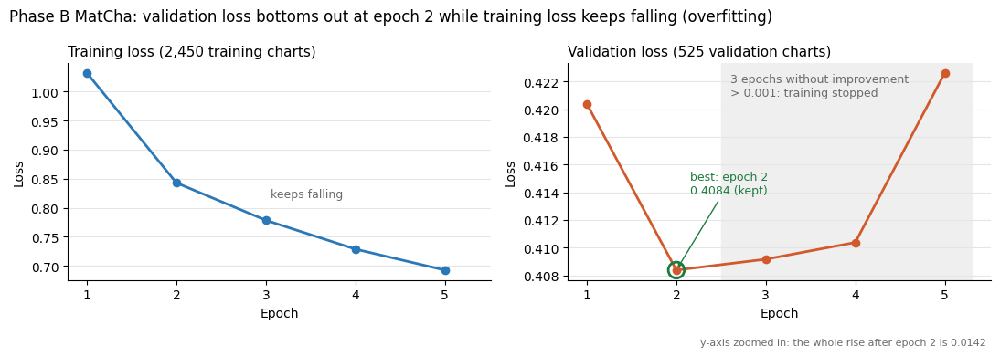

Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/phaseB_matcha_seed42/phaseB_loss_curves.png


In [6]:
output_banner("9d loss curves")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

PB_DIR = WORK_DRIVE / "phaseB_matcha_seed42"
h = pd.read_csv(PB_DIR / "phaseB_training_history.csv")
curve = (h.groupby("epoch")[["loss", "eval_loss"]].first().reset_index()
           .rename(columns={"loss": "training loss", "eval_loss": "validation loss"}))
curve["epoch"] = curve["epoch"].astype(int)
best = curve.loc[curve["validation loss"].idxmin()]
display(curve.round(4))

C_TRAIN, C_VAL, C_BEST, C_MUTED = "#2a78b8", "#d1592b", "#1d7a3e", "#6b6b6b"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)

ax1.plot(curve["epoch"], curve["training loss"], "-o", color=C_TRAIN, lw=2)
ax1.set_title("Training loss (2,450 training charts)", loc="left", fontsize=11)
ax1.text(3.05, curve["training loss"].iloc[2] + 0.04, "keeps falling", color=C_MUTED, fontsize=9)

ax2.plot(curve["epoch"], curve["validation loss"], "-o", color=C_VAL, lw=2)
ax2.scatter([best["epoch"]], [best["validation loss"]], s=160, facecolors="none", edgecolors=C_BEST, lw=2, zorder=3)
ax2.annotate(f"best: epoch {int(best['epoch'])}\n{best['validation loss']:.4f} (kept)",
             xy=(best["epoch"], best["validation loss"]), xytext=(best["epoch"] + 0.15, best["validation loss"] + 0.0055),
             color=C_BEST, fontsize=9, arrowprops=dict(arrowstyle="->", color=C_BEST))
after = curve[curve["epoch"] > best["epoch"]]
ax2.axvspan(best["epoch"] + 0.5, curve["epoch"].max() + 0.3, color="#efefef", zorder=0)
ax2.text(best["epoch"] + 0.6, curve["validation loss"].max(),
         f"{len(after)} epochs without improvement\n> 0.001: training stopped", va="top", color=C_MUTED, fontsize=9)
ax2.set_title("Validation loss (525 validation charts)", loc="left", fontsize=11)
rise = curve["validation loss"].iloc[-1] - best["validation loss"]
ax2.text(0.99, -0.3, f"y-axis zoomed in: the whole rise after epoch 2 is {rise:.4f}", transform=ax2.transAxes,
         ha="right", color=C_MUTED, fontsize=8)

for ax in (ax1, ax2):
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Phase B MatCha: validation loss bottoms out at epoch 2 while training loss keeps falling (overfitting)",
             fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(PB_DIR / "phaseB_loss_curves.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", PB_DIR / "phaseB_loss_curves.png")

### Step 9 result: checkpoint choice and its limitation

**Chosen checkpoint: epoch 2.** It is kept on Drive at `checkpoints/phaseB_matcha_seed42/best_model` and is the model
used for the single held-out test run.

**Why epoch 2.**

1. The selection rule was fixed before Phase B training: the lowest teacher-forced validation loss on all 525
   validation charts.
2. Epoch 2 had the lowest validation loss (0.4084).
3. After epoch 2, validation loss rose (0.4092, 0.4104, 0.4226) while training loss kept falling. That is
   overfitting, and early stopping ended training after epoch 5.
4. On validation, epoch 2 scores 0.8602 on the 64 real charts and 0.9651 on the 461 generated charts (strict
   Benetech-style score, against full-precision answers).
5. With the presentation on Nov 11, the OCR baseline, the test run and the error analysis came first. The selection
   was decided on Nov 6 and the rule was not changed.

**Limitation.** Teacher-forced validation loss measures how well the model predicts each target token when it is
given the correct previous tokens. The project metric scores the whole generated table and gives zero for a wrong row
count. The two can disagree. Only epoch 2 was scored with the strict metric, so we **do not claim** that epoch 2
has the best Benetech score of the five epochs. We only claim that it has the lowest validation loss, which was the
rule set in advance. Epochs 3 and 4 were within 0.002 of epoch 2 on loss.

## Step 10 — OpenCV + OCR baseline (midterm slide 11)

**Why.** Midterm slide 11 promised "Build the OpenCV + OCR baseline", and the final rubric asks for the results to
be compared with a baseline. This baseline is a classic pipeline: hand-written image-processing rules plus an
off-the-shelf OCR engine. **Nothing in it is trained on our data.** It is not a "no pretrained model" baseline,
though: Tesseract's text recogniser is itself a pretrained neural network (an LSTM trained by its developers on
general printed text). We use it as is.

**How it reads one chart.**

1. **Find the bars (OpenCV).**
   * Mark the pixels that differ from the background and are coloured or a grey fill. Black ink (text, outlines) is
     left out.
   * Remove long thin lines (axes, gridlines).
   * Keep solid rectangles with the typical bar width.
   * Join pieces of one bar that a gridline or printed number split apart.
   * Sort the bars left to right.
2. **Read the y-axis (Tesseract).** Read the numbers left of the first bar, upright or turned 90°. Fit a straight line
   from pixel height to value; a robust fit ignores one misread number. Each bar's value is that line at the bar's
   top.
3. **Fallback.** If there is no readable y-axis, use numbers printed on or just above the bars.
4. **Read the x labels (Tesseract).** OCR the strip under the axis at 0°, 45° and 90°, keep the angle that reads the
   most text, and give each word to the bar it sits under.
5. **Write** `label | value` rows, the same table format as MatCha. The same scorer applies, against full-precision
   answers.

The annotations are used only for scoring, never as input. It runs on CPU only; a GPU runtime would not make it
faster.

**Development and tuning use validation charts only.** The rules were developed on the pilot charts, which are
validation charts. The settings are tuned in 10b on validation charts. The test set is run once, in Step 12.

**Before running Step 10 after a restart:** 1a–1d (CPU runtime is fine).

### 10a — The baseline, shown on 4 validation charts (CPU, seconds)

**What happens.** Defines the baseline functions, then runs them with the default settings on 2 real and 2
generated validation charts. Each chart is drawn with the detected bars outlined in red. Under it are the table
the baseline wrote, the true table and the strict score.

**Expected output:** 4 annotated charts with their tables and scores.

Tesseract 5.3.4 | OpenCV 4.14.0


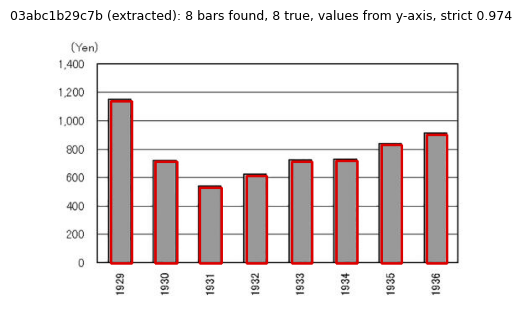

baseline: 1929 | 1141 / 1930 | 714.4 / 1931 | 530.8 / 1932 | 613.7 / 1933 | 714.4 / 1934 | 720.4 / 1935 | 832.9 / 1936 | 904
true    : 1929 | 1160 / 1930 | 728 / 1931 | 551 / 1932 | 634 / 1933 | 734 / 1934 | 740 / 1935 | 846 / 1936 | 923


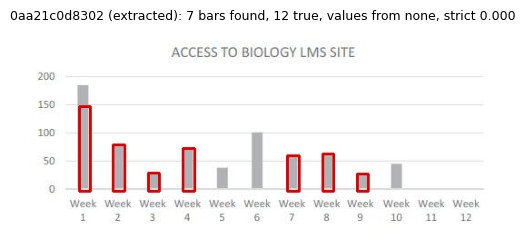

baseline: (no table)
true    : Week

1 | 183 / Week

2 | 81 / Week

3 | 32 / Week

4 | 75 / Week

5 | 38 / Week

6 | 100 / Week

7 | 62 / Week

8 | 64 / Week

9 | 30 / Week

10 | 46 / Week

11 | 3 / Week

12 | 3


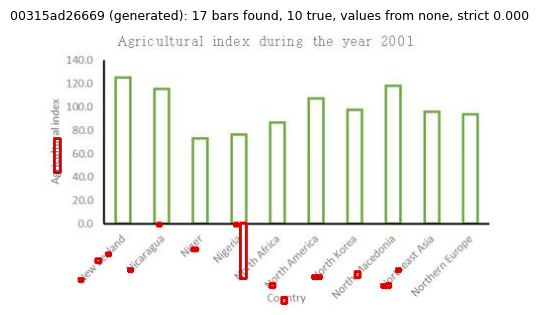

baseline: (no table)
true    : New Zealand | 125.4 / Nicaragua | 116.1 / Niger | 74.06 / Nigeria | 76.59 / North Africa | 87.53 / North America | 107.7 / North Korea | 97.63 / North Macedonia | 118.7 / Northeast Asia | 96.79 / Northern Europe | 94.26


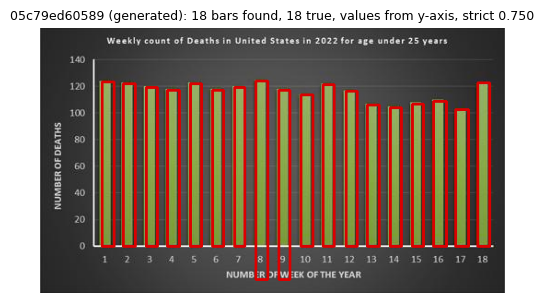

baseline:  | 123.6 /  | 122.2 /  | 119.4 /  | 117.3 /  | 122.2 /  | 117.3 /  | 119.4 /  | 124.3 /  | 117.3 /  | 113.9 /  | 121.5 /  | 116.6 /  | 106.2 /  | 104.1 /  | 106.9 /  | 109 /  | 102.8 /  | 122.9
true    : 1 | 123.5 / 2 | 122.1 / 3 | 119.4 / 4 | 117.3 / 5 | 122.1 / 6 | 117.3 / 7 | 119.4 / 8 | 124.2 / 9 | 117.3 / 10 | 113.2 / 11 | 121.4 / 12 | 115.9 / 13 | 106.3 / 14 | 104.3 / 15 | 107.7 / 16 | 109.8 / 17 | 102.2 / 18 | 121.4


In [12]:
output_banner("10a OpenCV + OCR baseline")

import os, re, io, zipfile, numpy as np, cv2, pytesseract
from PIL import Image
import matplotlib.pyplot as plt
os.environ["OMP_THREAD_LIMIT"] = "1"                 # one thread per Tesseract call (parallel workers in 10b)
print("Tesseract", pytesseract.get_tesseract_version(), "| OpenCV", cv2.__version__)


OCR_DEFAULTS = dict(bg_tol=30, min_sat=40, dark_max=110, min_fill=0.7, min_w=4, min_h=3, line_frac=0.3, line_px=3, width_tol=0.35, upscale=2, min_conf=30, label_angles=(0, 45, 90), grey_bars=True, grey_min=70, tall_frac=0.1, tick_upscale=3, label_gap=30, min_label_share=0.5)
NUM_RE = re.compile(r"^[-−]?\d[\d,]*\.?\d*%?$")

def _num(t):
    t = t.replace("−", "-").replace(",", "").rstrip("%")
    try:
        return float(t)
    except ValueError:
        return None

def find_bars(img, p):
    '''Bars = solid rectangles of non-background colour with a common width, left to right.'''
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    bg = np.median(img.reshape(-1, 3), axis=0)
    diff = np.abs(img.astype(int) - bg).max(axis=2)
    colour = hsv[..., 1] > p["min_sat"]                       # coloured fills
    grey = (gray > p["grey_min"]) & (hsv[..., 1] <= p["min_sat"])  # grey fills; excludes black ink (text, outlines)
    fill = (colour | grey) if p["grey_bars"] else (colour | (gray < p["dark_max"]))
    mask = (diff > p["bg_tol"]) & fill
    # remove axis and grid lines: rows / columns that are mostly "ink" across the plot
    mask = mask.astype(np.uint8)
    H, W = mask.shape
    # long thin lines only: a long horizontal run that is at most line_px thick (a wide bar region is kept)
    hl = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((1, max(3, int(p["line_frac"] * W))), np.uint8))
    thick_h = cv2.morphologyEx(hl, cv2.MORPH_OPEN, np.ones((p["line_px"] + 1, 1), np.uint8))
    vl = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((max(3, int(p["line_frac"] * H)), 1), np.uint8))
    thick_v = cv2.morphologyEx(vl, cv2.MORPH_OPEN, np.ones((1, p["line_px"] + 1), np.uint8))
    mask[(hl > 0) & (thick_h == 0)] = 0
    mask[(vl > 0) & (thick_v == 0)] = 0
    k = 2
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((k, k), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=4)
    cands = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if w < p["min_w"] or h < p["min_h"] or area / (w * h) < p["min_fill"]:
            continue
        if w > W * 0.5 or y + h < H * 0.4:              # backgrounds, legends and titles are not bars
            continue
        cands.append((x, y, w, h))
    if not cands:
        return []
    # bars in one chart share a width; keep candidates close to the median width
    tall = [c[2] for c in cands if c[3] >= p["tall_frac"] * H] or [c[2] for c in cands]
    med = np.median(tall)                                   # reference width from the clearly bar-like boxes
    bars = [c for c in cands if abs(c[2] - med) <= p["width_tol"] * med]
    # merge pieces of one bar split by gridlines or value labels: same column, similar width
    bars = sorted(bars, key=lambda c: (c[0], c[1])); merged = []
    for c in bars:
        for i, m in enumerate(merged):
            ov = min(c[0] + c[2], m[0] + m[2]) - max(c[0], m[0])
            if ov >= 0.7 * min(c[2], m[2]):
                x0, y0 = min(c[0], m[0]), min(c[1], m[1])
                merged[i] = (x0, y0, max(c[0] + c[2], m[0] + m[2]) - x0, max(c[1] + c[3], m[1] + m[3]) - y0)
                break
        else:
            merged.append(c)
    bars = merged
    # drop boxes whose x-range overlaps a taller box
    bars = sorted(bars, key=lambda c: -c[3]); keep = []
    for c in bars:
        if all(c[0] + c[2] <= k_[0] or k_[0] + k_[2] <= c[0] for k_ in keep):
            keep.append(c)
    bars = keep
    return sorted(bars, key=lambda c: c[0])

def ocr_words(img, p):
    up = p["upscale"]
    big = cv2.resize(img, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    d = pytesseract.image_to_data(big, config="--psm 11", output_type=pytesseract.Output.DICT)
    out = []
    for t, x, y, w, h, c in zip(d["text"], d["left"], d["top"], d["width"], d["height"], d["conf"]):
        t = t.strip()
        if t and float(c) > 0:
            out.append({"text": t, "x0": x / up, "x1": (x + w) / up, "y0": y / up, "y1": (y + h) / up,
                        "xc": (x + w / 2) / up, "yc": (y + h / 2) / up})
    return out

def y_tick_points(img, bars, p):
    '''Read the numbers left of the leftmost bar (the y-axis tick labels) as (pixel y, value) pairs.
    Tries upright text first, then text rotated 90 degrees.'''
    left = int(min(b[0] for b in bars))
    strip = img[:, :max(left - 1, 1)]
    up = p["tick_upscale"]
    cfg = "--psm 11 -c tessedit_char_whitelist=0123456789.,-%"
    best = []
    for rot in (None, cv2.ROTATE_90_CLOCKWISE):
        im = strip if rot is None else cv2.rotate(strip, rot)
        big = cv2.resize(im, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
        d = pytesseract.image_to_data(big, config=cfg, output_type=pytesseract.Output.DICT)
        pts = []
        for t, x, y, w, h in zip(d["text"], d["left"], d["top"], d["width"], d["height"]):
            t = t.strip()
            v = _num(t) if t and NUM_RE.match(t) else None
            if v is None:
                continue
            if rot is None:
                pts.append(((y + h / 2) / up, v))
            else:                      # rotated clockwise: original y = rotated x
                pts.append((strip.shape[0] - 1 - (x + w / 2) / up, v))
        if len(pts) > len(best):
            best = pts
        if len(best) >= 3:
            break
    return best

def y_calibration(img, bars, p):
    '''Fit value = a * pixel_y + b from the y-axis tick labels, robust to a misread tick.'''
    pts = y_tick_points(img, bars, p)
    if len(pts) < 2:
        return None
    ys, vs = np.array(pts).T
    best, best_in = None, 0
    for i in range(len(pts)):                               # small RANSAC over point pairs
        for j in range(i + 1, len(pts)):
            if ys[i] == ys[j]:
                continue
            a = (vs[j] - vs[i]) / (ys[j] - ys[i]); b = vs[i] - a * ys[i]
            if a >= 0:                                      # values must grow upwards
                continue
            res = np.abs(a * ys + b - vs)
            inl = res <= 0.02 * (np.ptp(vs) + 1e-9)
            if inl.sum() > best_in:
                best_in, best = inl.sum(), inl
    if best is None or best_in < 2:
        return None
    a, b = np.polyfit(ys[best], vs[best], 1)
    return a, b

def _ocr(img, up, psm=11):
    big = cv2.resize(img, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    return pytesseract.image_to_data(big, config=f"--psm {psm}", output_type=pytesseract.Output.DICT)

def rotated_label_words(img, bars, p):
    '''OCR the strip under the x-axis at 0, 45 and 90 degrees; keep the angle that reads the most text.
    Each word is anchored at its end nearest the axis, mapped back to original x.'''
    base = max(b[1] + b[3] for b in bars)
    strip = img[base + 1:, :]
    if strip.shape[0] < 5:
        return []
    best, best_q = [], -1
    h, w = strip.shape[:2]
    for ang in p["label_angles"]:
        M = cv2.getRotationMatrix2D((w / 2, h / 2), -ang, 1.0)          # rotate clockwise by ang
        cos, sin = abs(M[0, 0]), abs(M[0, 1])
        nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
        M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
        rot = cv2.warpAffine(strip, M, (nw, nh), borderValue=(255, 255, 255))
        d = _ocr(rot, p["upscale"], psm=11)
        Minv = cv2.invertAffineTransform(M)
        words = []
        for t, x, y, ww, hh, c in zip(d["text"], d["left"], d["top"], d["width"], d["height"], d["conf"]):
            t = t.strip()
            if not t or float(c) < p["min_conf"] or not re.search(r"[A-Za-z0-9]", t):
                continue
            up = p["upscale"]
            # end of the word nearest the axis: right end, top in rotated frame
            ax, ay = (x + ww) / up, (y + hh / 2) / up
            if ang == 0:
                ax = (x + ww / 2) / up
            ox, oy = Minv @ np.array([ax, ay, 1.0])
            words.append({"text": t, "x": ox, "y": oy, "line": round(y / up / 6), "x0": x / up, "conf": float(c)})
        q = sum(len(wd["text"]) * wd["conf"] for wd in words)
        if q > best_q:
            best, best_q = words, q
    return best

def x_labels(img, bars, p):
    words = rotated_label_words(img, bars, p)
    labels = []
    for i, (x, y, w, h) in enumerate(bars):
        lo = (bars[i - 1][0] + bars[i - 1][2] + x) / 2 if i else x - w
        hi = (x + w + bars[i + 1][0]) / 2 if i + 1 < len(bars) else x + 2 * w
        mine = sorted((t for t in words if lo <= t["x"] < hi), key=lambda t: (t["line"], t["x0"]))
        labels.append(" ".join(t["text"] for t in mine))
    return labels

def bar_value_labels(img, bars, p):
    '''Numbers printed on or just above each bar (data labels), or None for a bar without one.'''
    words = [w for w in ocr_words(img, p) if NUM_RE.match(w["text"]) and _num(w["text"]) is not None]
    out = []
    for x, y, w, h in bars:
        near = [t for t in words if x - 0.25 * w <= t["xc"] <= x + 1.25 * w and y - p["label_gap"] <= t["yc"] <= y + 0.5 * h]
        near.sort(key=lambda t: abs(t["yc"] - y))
        out.append(_num(near[0]["text"]) if near else None)
    return out

def ocr_baseline(img, params=None):
    p = {**OCR_DEFAULTS, **(params or {})}
    bars = find_bars(img, p)
    if not bars:
        return "", {"bars": 0, "calibrated": False, "value_source": "none"}
    labels = x_labels(img, bars, p)
    cal = y_calibration(img, bars, p)
    source = "y-axis"
    if cal is not None:
        values = [cal[0] * y + cal[1] for (x, y, w, h) in bars]
    else:
        # no readable y-axis: fall back to numbers printed on the bars, and fit a scale from those
        dl = bar_value_labels(img, bars, p)
        pairs = [(b[1], v) for b, v in zip(bars, dl) if v is not None]
        if len(pairs) < 2 or len(pairs) < p["min_label_share"] * len(bars):
            return "", {"bars": len(bars), "calibrated": False, "value_source": "none"}
        ys, vs = np.array(pairs, dtype=float).T
        a, b = np.polyfit(ys, vs, 1) if np.ptp(ys) > 0 else (0.0, float(np.median(vs)))
        values = [v if v is not None else a * bb[1] + b for bb, v in zip(bars, dl)]
        source = "bar labels"
    rows = [f"{lab} | {v:.4g}" for lab, v in zip(labels, values)]
    return "\n".join(rows), {"bars": len(bars), "calibrated": True, "value_source": source}


SUBSET_DIR = RESULTS_DIR / "subset_3500"
va = pd.read_csv(SUBSET_DIR / "validation_subset3500.csv")
OCR_SETS = {"real64": va[va["source"] == "extracted"].reset_index(drop=True),
            "gen64": va[va["source"] == "generated"].sample(64, random_state=42).sort_values("chart_id").reset_index(drop=True)}
OCR_DIR = WORK_DRIVE / "ocr_baseline"; (OCR_DIR / "predictions").mkdir(parents=True, exist_ok=True)

def load_chart(z, row):
    img = np.array(Image.open(io.BytesIO(z.read(row["image_member"]))).convert("RGB"))
    x, y = tp.ce.ground_truth_from_annotation(z.read(row["annotation_member"]))
    return img, x, y

demo = pd.concat([OCR_SETS["real64"].head(2), OCR_SETS["gen64"].head(2)])
with zipfile.ZipFile(KAGGLE_ZIP) as z:
    for _, row in demo.iterrows():
        img, x, y = load_chart(z, row)
        p = {**OCR_DEFAULTS}
        txt, info = ocr_baseline(img, p)
        res = tp.ce.evaluate_chart(x, y, txt, header_mode="none")
        shown = img.copy()
        for bx, by, bw, bh in find_bars(img, p):
            cv2.rectangle(shown, (int(bx), int(by)), (int(bx + bw), int(by + bh)), (220, 0, 0), 2)
        plt.figure(figsize=(6, 3.6)); plt.imshow(shown); plt.axis("off")
        plt.title(f"{row['chart_id']} ({row['source']}): {info['bars']} bars found, {len(x)} true, "
                  f"values from {info['value_source']}, strict {res.strict_score:.3f}", fontsize=9)
        plt.show()
        print("baseline:", txt.replace("\n", " / ")[:300] or "(no table)")
        print("true    :", " / ".join(f"{a} | {b:.4g}" for a, b in zip(x, y))[:300])

### 10b — Tune 4 settings on 128 validation charts (CPU, about 15 to 30 minutes)

**What happens.** Runs the baseline with 16 setting combinations (2 × 2 × 2 × 2) on the same 128 validation charts
as Step 8: the 64 real charts and the fixed 64-chart generated sample. It runs several charts at once, one per CPU
core. No test chart is used.

**The 4 settings, in plain language** (code name in brackets, the two values tried):

* **Background tolerance** (`bg_tol`: 20 or 35). The baseline takes the chart's most common colour as the
  background. A pixel only counts as a possible bar if it differs from the background by more than this amount on
  at least one colour channel (0–255 scale). Higher ignores faint shading and soft edges.
* **Minimum fill** (`min_fill`: 0.6 or 0.8). For each shape found, the baseline draws the smallest box around it.
  The shape must fill at least this share of its box (60% or 80%) to count as a bar. Text and odd shapes fill their
  box poorly, so this drops them.
* **Width tolerance** (`width_tol`: 0.25 or 0.40). Bars in one chart are usually the same width. The baseline takes
  the median width and keeps only shapes within ±25% or ±40% of it, dropping tick marks, legend boxes and the like.
* **Grey bars** (`grey_bars`: yes or no). This is a swap, not an on/off switch for grey:
  * *yes:* coloured bars plus light-to-mid grey fills. Anything darker counts as black ink (text, outlines) and is
    dropped, so dark grey and black bars are lost.
  * *no:* coloured bars plus dark fills. Light grey bars are lost.
  * Allowing both at once would also pick up text, axis lines and gridlines and merge them into fake bars.

**The choice rule, fixed before running.** Pick the setting with the highest average of the real-64 and
generated-64 strict scores (equal weight). Ties go to the higher real-chart score. Fixing the rule first means the
setting can't be picked by eye after seeing the results.

**Expected output:** the 16-row grid table, sorted best first, and the chosen settings, saved as
`step10b_grid.csv`. Re-running reuses the saved grid.

In [8]:
output_banner("10b tune the baseline on validation")

import itertools, json, time, threading
from concurrent.futures import ThreadPoolExecutor

GRID = {"bg_tol": [20, 35], "min_fill": [0.6, 0.8], "width_tol": [0.25, 0.40], "grey_bars": [True, False]}
combos = [dict(zip(GRID, v)) for v in itertools.product(*GRID.values())]
TUNE = pd.concat([OCR_SETS["real64"], OCR_SETS["gen64"]], ignore_index=True)

_tls = threading.local()
def _score_one(job):
    # threads work in parallel here: Tesseract runs as a separate program and OpenCV releases the Python lock
    if not hasattr(_tls, "z"):
        _tls.z = zipfile.ZipFile(KAGGLE_ZIP)          # one open zip per worker thread
    row, params = job
    img, x, y = load_chart(_tls.z, row)
    try:
        txt, info = ocr_baseline(img, params)
    except Exception as exc:                          # a crash on one chart counts as "no table"
        txt, info = "", {"bars": 0, "calibrated": False, "value_source": f"error {type(exc).__name__}"}
    res = tp.ce.evaluate_chart(x, y, txt, header_mode="none")
    return {"chart_id": row["chart_id"], "source": row["source"], "strict": res.strict_score,
            "row_count_match": res.row_count_match, "n_true": len(x), "bars": info["bars"],
            "value_source": info["value_source"], "prediction_text": txt}

grid_csv = OCR_DIR / "step10b_grid.csv"
if grid_csv.is_file():
    grid = pd.read_csv(grid_csv)
    print("Grid already run; loaded", grid_csv)
else:
    n_proc = os.cpu_count() or 2
    print(f"{len(combos)} settings x {len(TUNE)} charts on {n_proc} CPU workers")
    rows, t0 = [], time.time()
    with ThreadPoolExecutor(n_proc) as pool:
        for i, c in enumerate(combos, 1):
            params = {**OCR_DEFAULTS, **c}
            res = pd.DataFrame(list(pool.map(_score_one, [(r, params) for r in TUNE.to_dict("records")])))
            real, gen = res[res["source"] == "extracted"], res[res["source"] == "generated"]
            rows.append({**c, "real64": real["strict"].mean(), "gen64": gen["strict"].mean(),
                         "objective": (real["strict"].mean() + gen["strict"].mean()) / 2,
                         "real zeros": int((real["strict"] == 0).sum()), "gen zeros": int((gen["strict"] == 0).sum())})
            print(f"  {i:2d}/{len(combos)} {c} -> real {rows[-1]['real64']:.4f}, generated {rows[-1]['gen64']:.4f} "
                  f"({(time.time() - t0) / 60:.1f} min)")
    grid = pd.DataFrame(rows)
    grid.to_csv(grid_csv, index=False)

grid = grid.sort_values(["objective", "real64"], ascending=False).reset_index(drop=True)
display(grid.round(4))
OCR_BEST = {k: (bool(grid.loc[0, k]) if k == "grey_bars" else grid.loc[0, k].item()) for k in GRID}
tp.save_json(OCR_BEST, OCR_DIR / "step10b_chosen_settings.json")
print("Chosen settings:", OCR_BEST)

16 settings x 128 charts on 2 CPU workers
   1/16 {'bg_tol': 20, 'min_fill': 0.6, 'width_tol': 0.25, 'grey_bars': True} -> real 0.2640, generated 0.2163 (2.2 min)
   2/16 {'bg_tol': 20, 'min_fill': 0.6, 'width_tol': 0.25, 'grey_bars': False} -> real 0.2846, generated 0.5511 (4.0 min)
   3/16 {'bg_tol': 20, 'min_fill': 0.6, 'width_tol': 0.4, 'grey_bars': True} -> real 0.2500, generated 0.1815 (6.1 min)
   4/16 {'bg_tol': 20, 'min_fill': 0.6, 'width_tol': 0.4, 'grey_bars': False} -> real 0.2884, generated 0.5728 (8.0 min)
   5/16 {'bg_tol': 20, 'min_fill': 0.8, 'width_tol': 0.25, 'grey_bars': True} -> real 0.2786, generated 0.3849 (10.2 min)
   6/16 {'bg_tol': 20, 'min_fill': 0.8, 'width_tol': 0.25, 'grey_bars': False} -> real 0.2381, generated 0.5120 (11.8 min)
   7/16 {'bg_tol': 20, 'min_fill': 0.8, 'width_tol': 0.4, 'grey_bars': True} -> real 0.2676, generated 0.3730 (13.9 min)
   8/16 {'bg_tol': 20, 'min_fill': 0.8, 'width_tol': 0.4, 'grey_bars': False} -> real 0.2495, generated 0.54

,bg_tol,min_fill,width_tol,grey_bars,real64,gen64,objective,real zeros,gen zeros
0,35,0.6,0.40,False,0.2884,0.6544,0.4714,42,16
1,35,0.6,0.25,False,0.2846,0.6179,0.4512,42,19
2,35,0.8,0.40,False,0.2495,0.6142,0.4318,45,19
3,20,0.6,0.40,False,0.2884,0.5728,0.4306,42,22
4,20,0.6,0.25,False,0.2846,0.5511,0.4178,42,23
5,35,0.8,0.25,False,0.2381,0.5890,0.4135,46,21
6,20,0.8,0.40,False,0.2495,0.5461,0.3978,45,23
7,20,0.8,0.25,False,0.2381,0.5120,0.3750,46,27
8,35,0.8,0.25,True,0.3198,0.4236,0.3717,39,31
9,35,0.8,0.40,True,0.2941,0.4230,0.3585,42,31


Chosen settings: {'bg_tol': 35, 'min_fill': 0.6, 'width_tol': 0.4, 'grey_bars': False}


### 10c — Score the tuned baseline on all 525 validation charts (CPU, about 5 to 10 minutes)

**What happens.** Runs the baseline with the chosen settings on all 525 validation charts. It writes predictions
in the same CSV format as MatCha and scores them with the same scorer. It reports real (64) and generated (461)
charts separately, next to Phase B MatCha (epoch 2). It also shows why the zero-score charts failed:

* no bars found
* no value scale (no readable y-axis and no bar labels)
* too few bars
* too many bars
* right count but still zero

**Expected output:** the comparison table and the failure counts, saved as `step10c_validation_scores.csv`.

In [9]:
output_banner("10c score the tuned baseline on validation")

OCR_BEST = json.loads((OCR_DIR / "step10b_chosen_settings.json").read_text())
params = {**OCR_DEFAULTS, **OCR_BEST}
parts = {"real (64)": va[va["source"] == "extracted"], "generated (461)": va[va["source"] == "generated"]}
rows10, fails = [], []
with ThreadPoolExecutor(os.cpu_count() or 2) as pool:
    for label, df in parts.items():
        exp = "ocr_baseline__val_" + ("real" if label.startswith("real") else "generated")
        pred_csv = OCR_DIR / "predictions" / f"{exp}.csv"
        if not pred_csv.is_file():
            res = pd.DataFrame(list(pool.map(_score_one, [(r, params) for r in df.to_dict("records")])))
            out = res.assign(n_generated_tokens=0, hit_token_limit=False, model=exp, timestamp=tp._now())
            out[["chart_id", "source", "prediction_text", "n_generated_tokens", "hit_token_limit", "model",
                 "value_source", "bars", "timestamp"]].to_csv(pred_csv, index=False)
        preds = pd.read_csv(pred_csv, keep_default_na=False)
        scored = tp.score_predictions(pred_csv, df, KAGGLE_ZIP, header_mode="none", out_prefix=OCR_DIR / exp)
        pc = scored["per_chart"].merge(preds[["chart_id", "bars", "value_source"]], on="chart_id")
        rows10.append({"system": "OCR baseline (tuned)", "charts": label,
                       "strict score": pc["strict_score"].mean(),
                       "zero-score charts": int((pc["strict_score"] == 0).sum()),
                       "row count right": pc["row_count_match"].mean()})
        z = pc[pc["strict_score"] == 0]
        fails.append({"charts": label, "no bars found": int((z["bars"] == 0).sum()),
                      "no value scale": int(((z["bars"] > 0) & (z["value_source"] == "none")).sum()),
                      "too few bars": int(((z["value_source"] != "none") & (z["bars"] < z["n_true"])).sum()),
                      "too many bars": int(((z["value_source"] != "none") & (z["bars"] > z["n_true"])).sum()),
                      "right count, still zero": int(((z["value_source"] != "none") & (z["bars"] == z["n_true"])).sum())})

mb = pd.read_csv(WORK_DRIVE / "phaseB_matcha_seed42" / "step9c_validation_scores.csv")
mb = mb[mb["model"] == "Phase B (best epoch)"].head(2)
for (_, r), label in zip(mb.iterrows(), parts):
    rows10.append({"system": "MatCha Phase B (epoch 2)", "charts": label, "strict score": r["strict score"],
                   "zero-score charts": int(r["zero-score charts"]), "row count right": r["row count right"]})
tab10 = pd.DataFrame(rows10)
tab10.to_csv(OCR_DIR / "step10c_validation_scores.csv", index=False)
print("Validation, strict score against full-precision answers")
display(tab10.round(4))
print("\nWhy the baseline's zero-score charts failed")
display(pd.DataFrame(fails))
print("Settings used:", OCR_BEST)

Validation, strict score against full-precision answers


,system,charts,strict score,zero-score charts,row count right
0,OCR baseline (tuned),real (64),0.2884,42,0.3438
1,OCR baseline (tuned),generated (461),0.5948,144,0.6876
2,MatCha Phase B (epoch 2),real (64),0.8602,7,0.8906
3,MatCha Phase B (epoch 2),generated (461),0.9651,7,0.9848



Why the baseline's zero-score charts failed


,charts,no bars found,no value scale,too few bars,too many bars,"right count, still zero"
0,real (64),13,14,12,3,0
1,generated (461),88,3,52,1,0


Settings used: {'bg_tol': 35, 'min_fill': 0.6, 'width_tol': 0.4, 'grey_bars': False}


### 10d — Step 10 in graphs (CPU, seconds)

**What it shows.** Three graphs made from the files 10b and 10c saved. Nothing is re-run.

1. **Strict score, baseline vs MatCha** on the 64 real and 461 generated validation charts.
2. **What happened on each chart** for the baseline: scored above zero, or which failure made it zero (no bars
   found, no value scale, too few bars, too many bars).
3. **The 16 tuning settings** plotted as real-chart score against generated-chart score. It shows the grey-bars
   trade-off: "grey bars: yes" helps real charts a little and hurts generated charts a lot.

It also prints, for the charts the baseline scored above zero, its mean score on labels and on values separately.

**Expected output:** two figures, saved as `step10_scores_and_failures.png` and `step10_tuning_grid.png`.

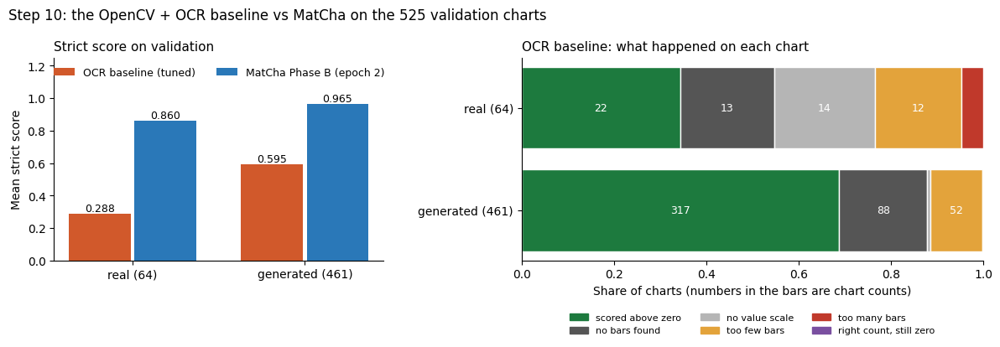

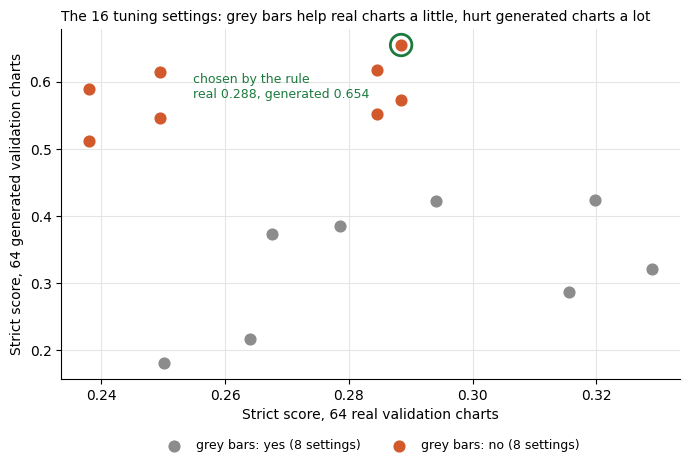

Baseline on the charts it scored above zero


,charts,scored above zero,mean strict,labels (x score),values (y score)
0,real (64),22,0.8391,0.7981,0.8802
1,generated (461),317,0.8650,0.7941,0.9358


Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/ocr_baseline/step10_scores_and_failures.png and /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/ocr_baseline/step10_tuning_grid.png


In [7]:
output_banner("10d Step 10 graphs")

import matplotlib.pyplot as plt

C_OCR, C_MATCHA, C_MUTED = "#d1592b", "#2a78b8", "#6b6b6b"
tab10 = pd.read_csv(OCR_DIR / "step10c_validation_scores.csv")
GROUPS = [("real (64)", "real"), ("generated (461)", "generated")]

# per-chart outcome for the baseline, from the saved scores and predictions
pcs = {}
for label, short in GROUPS:
    exp = f"ocr_baseline__val_{short}"
    pc = pd.read_csv(OCR_DIR / f"{exp}_per_chart.csv")
    pr = pd.read_csv(OCR_DIR / "predictions" / f"{exp}.csv", keep_default_na=False)
    pc = pc.merge(pr[["chart_id", "bars", "value_source"]], on="chart_id")
    zero = pc["strict_score"] == 0
    pc["outcome"] = "scored above zero"
    pc.loc[zero & (pc["bars"] == 0), "outcome"] = "no bars found"
    pc.loc[zero & (pc["bars"] > 0) & (pc["value_source"] == "none"), "outcome"] = "no value scale"
    pc.loc[zero & (pc["value_source"] != "none") & (pc["bars"] < pc["n_true"]), "outcome"] = "too few bars"
    pc.loc[zero & (pc["value_source"] != "none") & (pc["bars"] > pc["n_true"]), "outcome"] = "too many bars"
    pc.loc[zero & (pc["value_source"] != "none") & (pc["bars"] == pc["n_true"]), "outcome"] = "right count, still zero"
    pcs[label] = pc

OUTCOMES = ["scored above zero", "no bars found", "no value scale", "too few bars", "too many bars",
            "right count, still zero"]
O_COL = ["#1d7a3e", "#555555", "#b5b5b5", "#e3a33b", "#c0392b", "#7a4fa0"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.4]})

# 1. strict score, baseline vs MatCha
xs = range(len(GROUPS))
for k, (system, col) in enumerate([("OCR baseline (tuned)", C_OCR), ("MatCha Phase B (epoch 2)", C_MATCHA)]):
    vals = [tab10[(tab10["system"] == system) & (tab10["charts"] == g)]["strict score"].iloc[0] for g, _ in GROUPS]
    pos = [x + (k - 0.5) * 0.38 for x in xs]
    ax1.bar(pos, vals, width=0.36, color=col, label=system)
    for p, v in zip(pos, vals):
        ax1.text(p, v + 0.015, f"{v:.3f}", ha="center", fontsize=9)
ax1.set_xticks(list(xs), [g for g, _ in GROUPS])
ax1.set_ylim(0, 1.25)
ax1.set_ylabel("Mean strict score")
ax1.set_title("Strict score on validation", loc="left", fontsize=11)
ax1.legend(frameon=False, fontsize=9, loc="upper center", ncol=2)

# 2. what happened on each chart (share of charts)
for i, (label, _) in enumerate(GROUPS):
    pc = pcs[label]
    left = 0.0
    for o, col in zip(OUTCOMES, O_COL):
        n = int((pc["outcome"] == o).sum())
        share = n / len(pc)
        if n:
            ax2.barh(i, share, left=left, color=col, edgecolor="white")
            if share >= 0.05:
                ax2.text(left + share / 2, i, str(n), ha="center", va="center", color="white", fontsize=9)
        left += share
ax2.set_yticks(range(len(GROUPS)), [g for g, _ in GROUPS])
ax2.invert_yaxis()
ax2.set_xlim(0, 1)
ax2.set_xlabel("Share of charts (numbers in the bars are chart counts)")
ax2.set_title("OCR baseline: what happened on each chart", loc="left", fontsize=11)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in O_COL]
ax2.legend(handles, OUTCOMES, frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Step 10: the OpenCV + OCR baseline vs MatCha on the 525 validation charts", fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OCR_DIR / "step10_scores_and_failures.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. the 16 tuning settings
grid = pd.read_csv(OCR_DIR / "step10b_grid.csv")
best = json.loads((OCR_DIR / "step10b_chosen_settings.json").read_text())
fig, ax = plt.subplots(figsize=(7, 4.8))
for grey, col, name in [(True, "#8c8c8c", "grey bars: yes"), (False, C_OCR, "grey bars: no")]:
    g = grid[grid["grey_bars"] == grey]
    ax.scatter(g["real64"], g["gen64"], s=60, color=col, label=f"{name} ({len(g)} settings)", zorder=3)
chosen = grid[(grid["bg_tol"] == best["bg_tol"]) & (grid["min_fill"] == best["min_fill"]) &
              (grid["width_tol"] == best["width_tol"]) & (grid["grey_bars"] == best["grey_bars"])].iloc[0]
ax.scatter([chosen["real64"]], [chosen["gen64"]], s=240, facecolors="none", edgecolors="#1d7a3e", lw=2, zorder=4)
ax.annotate(f"chosen by the rule\nreal {chosen['real64']:.3f}, generated {chosen['gen64']:.3f}",
            xy=(chosen["real64"], chosen["gen64"]), xytext=(-150, -38), textcoords="offset points",
            color="#1d7a3e", fontsize=9)
ax.set_xlabel("Strict score, 64 real validation charts")
ax.set_ylabel("Strict score, 64 generated validation charts")
ax.set_title("The 16 tuning settings: grey bars help real charts a little, hurt generated charts a lot",
             loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.14))
ax.grid(color="#e5e5e5", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OCR_DIR / "step10_tuning_grid.png", dpi=200, bbox_inches="tight")
plt.show()

# labels vs values on the charts the baseline got above zero
rows = []
for label, _ in GROUPS:
    ok = pcs[label][pcs[label]["strict_score"] > 0]
    rows.append({"charts": label, "scored above zero": len(ok), "mean strict": ok["strict_score"].mean(),
                 "labels (x score)": ok["x_score"].mean(), "values (y score)": ok["y_score"].mean()})
print("Baseline on the charts it scored above zero")
display(pd.DataFrame(rows).round(4))
print("Saved:", OCR_DIR / "step10_scores_and_failures.png", "and", OCR_DIR / "step10_tuning_grid.png")

### Step 10 result: the OpenCV + OCR baseline

**What the baseline is.** A classic pipeline: OpenCV finds the bars, and Tesseract OCR reads the axis numbers and
the labels. Tesseract is a pretrained OCR engine; nothing in the baseline was trained on our charts. Four settings
were tuned on 128 validation charts with a choice rule fixed before running. The test set was not used.

**Chosen settings:** background tolerance 35, minimum fill 0.6, width tolerance 0.4, grey bars no. They had the best
average of the real-64 score (0.2884) and the generated-64 score (0.6544).

**Validation result (strict score against full-precision answers):**

| Charts | OCR baseline | MatCha Phase B (epoch 2) |
|---|---|---|
| Real (64) | 0.2884, 42 zero-score charts | 0.8602, 7 zero-score charts |
| Generated (461) | 0.5948, 144 zero-score charts | 0.9651, 7 zero-score charts |

**Why the baseline scores zero.** Every zero-score chart either had no value scale or the wrong number of bars;
none had the right bar count.

| Charts | No bars found | No value scale | Too few bars | Too many bars |
|---|---|---|---|---|
| Real (64) | 13 | 14 | 12 | 3 |
| Generated (461) | 88 | 3 | 52 | 1 |

**What this means.**

* MatCha beats the baseline by 0.57 on real charts and 0.37 on generated charts.
* The baseline mostly fails at the first step, finding the bars and the scale. When it gets past that, it is
  fairly accurate: on the charts it scored above zero (22 of 64 real, 317 of 461 generated) its mean strict score is
  0.839 (real) and 0.865 (generated). Values are read better than labels there: value score 0.880 / 0.936, label
  score 0.798 / 0.794 (10d).
* Grey bars are a trade-off for this baseline (10d, third graph): the "yes" settings raise the real-chart score to
  at most 0.329 but cut the generated-chart score to 0.18–0.42.

**Limits to state.** It is a simple baseline built in a day, not a state-of-the-art system. It handles vertical bar
charts only, and it fails when the y-axis is unreadable and the bars are not labelled, on stacked or grouped bars,
and on very dense charts. Suspected but not checked: many of the 88 generated "no bars found" charts have light
grey bars, which the chosen setting skips.

**Next:** Step 12 runs MatCha (epoch 2) and this baseline once on the 525 held-out test charts.

## Step 11 — Token-limit audit before the test run

**Why.** The midterm set two limits from an audit of the full dataset: a training target limit of 1,152 tokens (the
longest target then was 1,145 tokens) and a generation cap of 864 new tokens. Phase B now uses the 3,500-chart split
and rounded targets, so before the single test run we check that both limits still fit. Only training and
validation charts are used; the test targets are not measured.

**Decision rule, set before running (Nov 7):**

* If the validation predictions that hit the 864-token cap are repetition loops, and nothing shows the cap cutting
  off valid tables, **keep 864**.
* If a cap hit is a valid long table that was cut off, a separate cell regenerates only those validation charts at
  1,152 and compares the outputs and strict scores. 1,152 is not adopted on a tiny score change alone; the actual
  predictions are examined.
* If any training target is longer than 1,152 tokens, those charts are listed so the impact can be judged. No
  retraining is planned.
* The epoch-2 checkpoint, all existing results and the test set are not changed.

### 11a — Token audit and the cap-hit predictions (CPU, a few minutes)

**What happens.**

1. **Target lengths.** Builds every target exactly as Phase B training did (same serializer, row separator, rounded
   values) and counts tokens with the MatCha tokenizer. Counts include the end-of-sequence token `</s>` that the
   tokenizer adds, because the model must also write that token before 864 new tokens run out.
   * Training: 2,450 charts, rounded targets (what training saw). The 1,152 limit applies here: anything longer was
     cut short in training.
   * Validation: 525 charts, rounded and also the original full-precision tables, real and generated separately.
   * For each: maximum, mean, 50th / 90th / 99th percentiles, and how many are over 864 and over 1,152.
2. **Cap hits.** Every Phase B validation prediction (9c) that used all 864 new tokens is checked:
   * rows written vs true rows, and how many of the written rows are distinct
   * whether the end of the output repeats the same pattern 5 or more times (a loop)
   * whether the true rounded table would fit in 864 tokens
   * a verdict: **loop**, **valid table cut off**, or **other failure**
   * the start and end of the output, so the verdict can be checked by eye

**Before running after a restart:** 1a–1d only. It works on a CPU runtime: it loads only the MatCha tokenizer (no
model, no GPU) and reads the row separator and generation cap that 4a saved on Drive. The rounding rule is the same
code as 6c-i.

**Expected output:** two length tables, the list of training targets over 1,152 (expected empty), a cap-hit table
with verdicts, and the text of each cap-hit output. Saved as `step11a_token_lengths.csv` and
`step11a_cap_hits.csv`.

In [19]:
output_banner("11a token audit")

import re, zipfile, json, math, numbers
import numpy as np
from decimal import Decimal, ROUND_HALF_EVEN

# self-contained on a CPU runtime: needs only 1a-1d. Settings are read from the files earlier steps saved.
setup4a = json.loads((WORK_DRIVE / "pilot_seed42" / "step4a_pilot_setup.json").read_text())
ROW_SEPARATOR = setup4a["row_separator"]
CAP_NEW, CAP_TRAIN = int(setup4a["generation_cap"]["max_new_tokens"]), int(tp.V332["MAX_TARGET_LENGTH"])
TOK = tp.load_processor(tp.MODEL_CONFIGS["MatCha"]).tokenizer
SUBSET_DIR = RESULTS_DIR / "subset_3500"
pb = {s: pd.read_csv(SUBSET_DIR / f"{s}_subset3500.csv") for s in ("train", "validation")}
assert len(pb["train"]) == 2450 and len(pb["validation"]) == 525
PB_DIR = WORK_DRIVE / "phaseB_matcha_seed42"

def round4_policy(v):
    # identical to 6c-i (the rule Phase B trained with): exact integers unchanged; others -> 4 significant digits
    if isinstance(v, bool) or not isinstance(v, numbers.Real):
        return v
    if isinstance(v, numbers.Integral):
        return str(int(v))
    f = float(v)
    if not math.isfinite(f) or f.is_integer():
        return str(f)
    d = Decimal(repr(f))
    r = d.quantize(Decimal(1).scaleb(d.adjusted() - 3), rounding=ROUND_HALF_EVEN)
    s = format(r, "f")
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s in ("-0", "") else s
assert [round4_policy(v) for v in (92.33333333333333, 12.0, 12345, 0.000123456)] == ["92.33", "12.0", "12345", "0.0001235"]
print(f"row separator {ROW_SEPARATOR!r} (from 4a) | 2,450 train / 525 validation charts")
T11_DIR = WORK_DRIVE / "token_audit"; T11_DIR.mkdir(parents=True, exist_ok=True)
print(f"generation cap (max_new_tokens): {CAP_NEW} | training target limit: {CAP_TRAIN}")
_eos = TOK("1", add_special_tokens=True)["input_ids"][-1]
print(f"tokenizer adds end-of-sequence token: {_eos == TOK.eos_token_id} (counted in every length below)")

def target_text(z, row, rounded):
    return tp.ce.build_linearized_target(z.read(row["annotation_member"]), row_separator=ROW_SEPARATOR,
                                         sanitize_labels=False, y_format=round4_policy if rounded else None)

def n_tokens(text):
    return len(TOK(text, add_special_tokens=True, truncation=False)["input_ids"])

rows = []
with zipfile.ZipFile(KAGGLE_ZIP) as z:
    for split, forms in (("train", (True,)), ("validation", (True, False))):
        for r in pb[split].to_dict("records"):
            for rounded in forms:
                t = target_text(z, r, rounded)
                rows.append({"split": split, "source": r["source"], "chart_id": r["chart_id"],
                             "form": "rounded" if rounded else "full precision", "tokens": n_tokens(t),
                             "rows": len(t.split(ROW_SEPARATOR))})
L = pd.DataFrame(rows)
L.to_csv(T11_DIR / "step11a_token_lengths.csv", index=False)

def stats(d):
    s = d["tokens"]
    return pd.Series({"charts": len(s), "max": s.max(), "mean": round(s.mean(), 1), "p50": s.quantile(0.5),
                      "p90": s.quantile(0.9), "p99": s.quantile(0.99),
                      f"> {CAP_NEW}": int((s > CAP_NEW).sum()), f"> {CAP_TRAIN}": int((s > CAP_TRAIN).sum())})

L["charts_group"] = L["split"] + " " + L["source"].map({"extracted": "real", "generated": "generated"})
tab = L.groupby(["charts_group", "form"])[["tokens"]].apply(stats).reset_index()
tab_all = L.groupby(["split", "form"])[["tokens"]].apply(stats).reset_index().rename(columns={"split": "charts_group"})
tab_all["charts_group"] = tab_all["charts_group"] + " (all)"
print("\nTarget length in tokens (including </s>)")
tab = pd.concat([tab_all, tab], ignore_index=True)
for c in ("charts", "max", f"> {CAP_NEW}", f"> {CAP_TRAIN}"):
    tab[c] = tab[c].astype(int)
display(tab)

over = L[(L["split"] == "train") & (L["tokens"] > CAP_TRAIN)]
print(f"\nTraining targets cut short by the {CAP_TRAIN}-token limit: {len(over)}")
if len(over):
    display(over[["chart_id", "source", "tokens", "rows"]])
longest = L[L["split"] == "train"].nlargest(5, "tokens")[["chart_id", "source", "tokens", "rows"]]
print("Five longest training targets:")
display(longest)

# --- the cap-hit predictions from 9c ---
def loop_at_end(text, min_repeats=5, min_span=40):
    # longest stretch in the last 600 characters where one short pattern repeats back to back
    tail, best = text[-600:], (None, 0, 0)
    for m in re.finditer(r"(.{1,60}?)\1{" + str(min_repeats - 1) + r",}", tail, flags=re.S):
        if len(m.group(0)) >= min_span and len(m.group(0)) > best[2]:
            best = (m.group(1), len(m.group(0)) // len(m.group(1)), len(m.group(0)))
    return best[0], best[1]

cap_rows, texts = [], {}
for short, label in (("real", "real (64)"), ("generated", "generated (461)")):
    exp = f"phaseB_matcha__val_{short}"
    pr = pd.read_csv(PB_DIR / "predictions" / f"{exp}.csv", keep_default_na=False)
    pc = pd.read_csv(PB_DIR / f"{exp}_per_chart.csv")
    hits = pr[(pr["n_generated_tokens"].astype(int) >= CAP_NEW) |
              pr["hit_token_limit"].astype(str).isin(["True", "true", "1"])]
    print(f"\n{label}: {len(hits)} of {len(pr)} predictions used all {CAP_NEW} new tokens")
    for _, h in hits.iterrows():
        cid, text = h["chart_id"], h["prediction_text"]
        s = pc[pc["chart_id"] == cid].iloc[0]
        written = [ln for ln in re.split(r"\n|" + re.escape(ROW_SEPARATOR), text) if ln.strip()]  # rows, either separator
        unit, reps = loop_at_end(text)
        true_tok = int(L[(L["chart_id"] == cid) & (L["form"] == "rounded")]["tokens"].iloc[0])
        if reps >= 5:
            verdict = "loop"
        elif true_tok > CAP_NEW and len(written) < int(s["n_true"]):
            verdict = "valid table cut off"
        else:
            verdict = "other failure"
        cap_rows.append({"charts": label, "chart_id": cid, "true rows": int(s["n_true"]),
                         "rows written": len(written), "distinct rows": len(set(written)),
                         "true table tokens (rounded)": true_tok, "repeating unit": repr(unit) if unit else "",
                         "repeats at end": reps, "strict score": round(float(s["strict_score"]), 4),
                         "verdict": verdict})
        texts[cid] = text
caps = pd.DataFrame(cap_rows)
caps.to_csv(T11_DIR / "step11a_cap_hits.csv", index=False)
print("\nPredictions that hit the cap")
display(caps)
for cid, text in texts.items():
    print(f"\n--- {cid}: first 300 and last 300 characters of the output ---")
    print(text[:300].replace(ROW_SEPARATOR, " / ").replace("\n", " / "))
    print("   ...")
    print(text[-300:].replace(ROW_SEPARATOR, " / ").replace("\n", " / "))

print("\nDecision rule: keep", CAP_NEW, "unless a cap hit is a valid table cut off.")
print("Valid tables cut off:", int((caps["verdict"] == "valid table cut off").sum()) if len(caps) else 0,
      "| loops:", int((caps["verdict"] == "loop").sum()) if len(caps) else 0,
      "| other:", int((caps["verdict"] == "other failure").sum()) if len(caps) else 0)

row separator '<0x0A>' (from 4a) | 2,450 train / 525 validation charts
generation cap (max_new_tokens): 864 | training target limit: 1152
tokenizer adds end-of-sequence token: True (counted in every length below)

Target length in tokens (including </s>)


,charts_group,form,charts,max,mean,p50,p90,p99,> 864,> 1152
0,train (all),rounded,2450,502,132.2,129.0,177.0,254.00,0,0
1,validation (all),full precision,525,1145,272.4,239.0,365.6,553.76,1,0
2,validation (all),rounded,525,647,131.8,123.0,176.6,259.32,0,0
3,train generated,rounded,2163,300,139.0,142.0,178.0,241.00,0,0
4,train real,rounded,287,502,81.3,64.0,142.0,274.84,0,0
5,validation generated,full precision,461,571,290.5,249.0,367.0,508.00,0,0
6,validation generated,rounded,461,277,137.3,138.0,177.0,244.00,0,0
7,validation real,full precision,64,1145,142.2,82.0,300.2,831.26,1,0
8,validation real,rounded,64,647,92.1,63.5,153.6,573.29,0,0



Training targets cut short by the 1152-token limit: 0
Five longest training targets:


,chart_id,source,tokens,rows
1579,a4dfb7b483fd,extracted,502,50
1226,7ed44e4f56a3,extracted,305,19
16,0186992254f9,generated,300,23
1610,a7fb93fdc39c,generated,300,23
2284,eca6af6bcd15,generated,300,23



real (64): 2 of 64 predictions used all 864 new tokens

generated (461): 0 of 461 predictions used all 864 new tokens

Predictions that hit the cap


,charts,chart_id,true rows,rows written,distinct rows,true table tokens (rounded),repeating unit,repeats at end,strict score,verdict
0,real (64),9d7688ae52b6,3,124,2,34,'0288<0x0A>0.',50,0.0,loop
1,real (64),bea7273e8cfb,37,108,1,647,'00<0x0A>19500',46,0.0,loop



--- 9d7688ae52b6: first 300 and last 300 characters of the output ---
0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 
   ...
0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.0288 / 0.

--- bea7273e8cfb: first 300 and last 300 characters of the output ---
1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1
   ...
0 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 1950000 / 195000

### 11b — Target lengths in a graph (CPU, seconds)

**What it shows.** The token length of every target from 11a, read from `step11a_token_lengths.csv` (nothing is
re-measured), in three panels:

1. the 2,450 training targets, rounded (what training saw)
2. the 525 validation targets, rounded
3. the same 525 validation targets in the original full precision

Each panel marks the 864-token generation cap and the 1,152-token training limit. Rounding roughly halves the
length, and with rounding every target sits well under both limits.

**Before running after a restart:** 1a–1d only (11a must have been run once).

**Expected output:** the figure, saved as `step11b_token_lengths.png`.

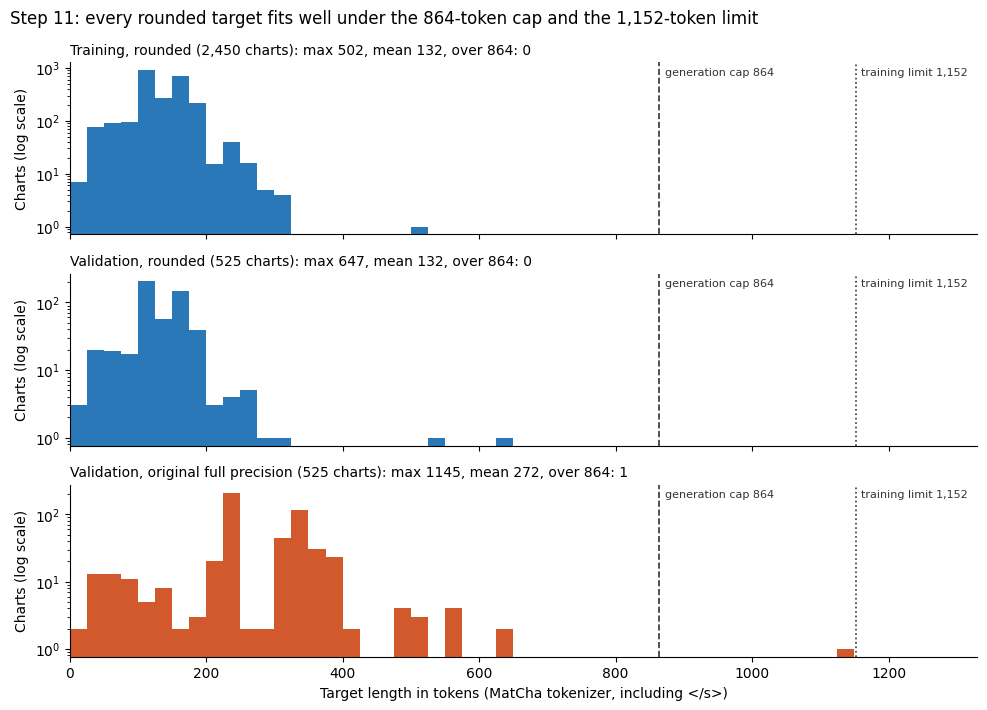

Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/token_audit/step11b_token_lengths.png


In [20]:
output_banner("11b target lengths graph")

import matplotlib.pyplot as plt
import numpy as np

T11_DIR = WORK_DRIVE / "token_audit"
L = pd.read_csv(T11_DIR / "step11a_token_lengths.csv")
CAP_NEW, CAP_TRAIN = 864, int(tp.V332["MAX_TARGET_LENGTH"])
panels = [("Training, rounded (2,450 charts)", (L["split"] == "train") & (L["form"] == "rounded"), "#2a78b8"),
          ("Validation, rounded (525 charts)", (L["split"] == "validation") & (L["form"] == "rounded"), "#2a78b8"),
          ("Validation, original full precision (525 charts)",
           (L["split"] == "validation") & (L["form"] == "full precision"), "#d1592b")]
bins = np.arange(0, 1201, 25)
fig, axes = plt.subplots(3, 1, figsize=(10, 7.2), sharex=True)
for ax, (title, sel, col) in zip(axes, panels):
    s = L.loc[sel, "tokens"]
    ax.hist(s, bins=bins, color=col)
    ax.set_yscale("log")
    for x, name, ls in ((CAP_NEW, "generation cap 864", "--"), (CAP_TRAIN, "training limit 1,152", ":")):
        ax.axvline(x, color="#333333", ls=ls, lw=1.2)
        ax.text(x + 8, 0.97, name, transform=ax.get_xaxis_transform(), va="top", fontsize=8, color="#333333")
    ax.set_title(f"{title}: max {s.max()}, mean {s.mean():.0f}, over 864: {(s > CAP_NEW).sum()}",
                 loc="left", fontsize=10)
    ax.set_ylabel("Charts (log scale)")
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlim(0, 1330)
axes[-1].set_xlabel("Target length in tokens (MatCha tokenizer, including </s>)")
fig.suptitle("Step 11: every rounded target fits well under the 864-token cap and the 1,152-token limit",
             fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(T11_DIR / "step11b_token_lengths.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", T11_DIR / "step11b_token_lengths.png")

## Step 12 — The single held-out test run

**Why.** Everything so far used only training and validation charts: the model, the recipe, the checkpoint, the
token cap and the baseline settings. Step 12 scores the 525 held-out test charts (69 real, 456 generated) once, with
those settings frozen. The test set was not used for training, model selection, parameter tuning or performance
scoring before this step. The only earlier use was the Step 2 cross-split leakage check, which compared test images
and annotations with the other splits to find duplicates, for data integrity; nothing was scored.

**What is compared.**

* **MatCha Phase B (epoch 2):** approach C, standard sampling, seed 42, greedy decoding, `max_new_tokens=864`,
  batch 8, fp16, no repetition penalty.
* **OpenCV + OCR baseline:** the settings chosen on validation in 10b (Tesseract is pretrained; nothing is trained
  on our charts). It has no token limit.
* **One scorer for both:** chart_eval strict score against the original full-precision test tables.

**Safeguards (Nov 7).**

1. **12a** writes a freeze manifest (checkpoint hash, tokenizer, image processor, preprocessing, decoding, baseline
   settings, scorer code hashes, software versions, the 525 test IDs) and runs a preflight on 8 **validation**
   charts. The test run cannot start until the preflight passes.
2. **Write-once.** 12b and 12c refuse to run if the manifest changed. After a disconnect they resume only the
   unfinished charts with identical settings, never overwriting finished ones.
3. Before scoring, each system must have exactly one prediction for every test chart: no missing, duplicate or extra
   IDs. Empty or malformed predictions stay in and score 0.
4. Nothing measured on test changes any model, setting or threshold. Step 13 describes the failures; it fixes
   nothing.

**Order:** run 12a, check that the preflight passed, then 12b, 12c, 12d.

### 12a — Freeze manifest and preflight on validation (T4 GPU, about 5 minutes)

**What happens.**

1. **Freeze manifest.** Collects every setting that decides the test result and saves it as
   `step12_frozen_settings.json`, with a hash of the whole manifest:
   * MatCha: checkpoint path and SHA-256 of `model.safetensors` and `config.json`, base model, decoding settings,
     task prompt, max patches, row separator
   * tokenizer (class, vocabulary size, hash of its full definition) and image processor settings (with a hash)
   * baseline: every OpenCV/Tesseract parameter and a hash of the baseline functions' source code
   * scorer: chart_eval and t4_pipeline versions and file hashes, header mode, strict score
   * the 525 test IDs (count, real/generated split, hash) and the bootstrap settings (10,000 resamples, seed 42)
   * software versions: Python, torch, transformers, OpenCV, Tesseract, GPU

   If a manifest already exists, the new one must match it exactly (apart from its creation time), or the cell stops.
2. **Preflight on 8 validation charts** (the first 8 real validation charts, which were the first batch in 9c). No
   test chart is used. It runs the exact Step 12 code path and checks:
   * the checkpoint loads; both systems write one prediction per chart in the standard CSV format
   * the one-prediction-per-chart check passes on good files and catches a duplicate and a missing ID
   * scoring works and the files are saved and can be read back from Drive
   * the outputs match the saved 9c (MatCha) and 10c (baseline) predictions for the same charts (reported; MatCha
     is expected to match because it is the same batch on the same GPU type)

**Before running after a restart:** switch to the **T4 GPU** runtime, then run 1a–1d and 10a (10a defines the
baseline functions).

**Expected output:** the manifest summary with its hash, a preflight table with PASS/FAIL per check, and
`PREFLIGHT PASSED`. Saved in `V3_4_7_work/test_run/`.

In [13]:
output_banner("12a freeze manifest and preflight")

import hashlib, inspect, json, os, platform, sys, zipfile, io, shutil, threading, time
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import torch, transformers, cv2, pytesseract
from PIL import Image
assert torch.cuda.is_available(), "Step 12 needs the T4 GPU runtime: switch runtime, run 1a-1d and 10a, then 12a."
assert "ocr_baseline" in globals() and "OCR_DEFAULTS" in globals(), "Run 10a first (it defines the baseline)."

T12 = WORK_DRIVE / "test_run"
T12_PRED = T12 / "predictions"
T12_PRE = T12 / "preflight"
for p in (T12, T12_PRED, T12_PRE):
    p.mkdir(parents=True, exist_ok=True)
FREEZE = T12 / "step12_frozen_settings.json"
PREFLIGHT_OK = T12 / "PREFLIGHT_PASSED.json"
MATCHA_TEST = T12_PRED / "matcha_phaseB__test.csv"
OCR_TEST = T12_PRED / "ocr_baseline__test.csv"

def sha_bytes(b):
    return hashlib.sha256(b).hexdigest()

def sha_text(t):
    return sha_bytes(t.encode("utf-8"))

# --- what is frozen ---
SUBSET_DIR = RESULTS_DIR / "subset_3500"
TEST_CSV = SUBSET_DIR / "test_subset3500.csv"
te = pd.read_csv(TEST_CSV)
assert len(te) == 525 and te["chart_id"].is_unique
va = pd.read_csv(SUBSET_DIR / "validation_subset3500.csv")
setup4a = json.loads((WORK_DRIVE / "pilot_seed42" / "step4a_pilot_setup.json").read_text())
ROW_SEPARATOR = setup4a["row_separator"]
CAP_NEW = int(setup4a["generation_cap"]["max_new_tokens"])
assert CAP_NEW == 864, CAP_NEW
PB_BEST = CKPT_DIR / "phaseB_matcha_seed42" / "best_model"
assert (PB_BEST / "model.safetensors").is_file(), PB_BEST
PROC = tp.load_processor(tp.MODEL_CONFIGS["MatCha"])
OCR_BEST = json.loads((WORK_DRIVE / "ocr_baseline" / "step10b_chosen_settings.json").read_text())
assert OCR_BEST == {"bg_tol": 35, "min_fill": 0.6, "width_tol": 0.4, "grey_bars": False}, OCR_BEST
OCR_PARAMS = {**OCR_DEFAULTS, **OCR_BEST}
DECODING = dict(max_new_tokens=CAP_NEW, num_beams=1, do_sample=False, repetition_penalty=None, batch_size=8,
                fp16=True, max_patches=int(tp.V332["MAX_PATCHES"]))

try:
    tok_def = sha_text(PROC.tokenizer.backend_tokenizer.to_str())
except Exception as exc:
    tok_def = f"unavailable ({type(exc).__name__})"
img_cfg = PROC.image_processor.to_dict()
try:
    base_src = "\n".join(inspect.getsource(f) for f in (find_bars, ocr_words, y_tick_points, y_calibration, _ocr,
                                                         rotated_label_words, x_labels, bar_value_labels,
                                                         ocr_baseline, _num))
    base_hash = sha_text(base_src)
except Exception as exc:
    base_hash = f"unavailable ({type(exc).__name__})"

print("Hashing the checkpoint (about 1 GB, under a minute)...")
manifest = {
    "matcha": {"checkpoint": str(PB_BEST), "model_safetensors_sha256": tp.file_sha256(PB_BEST / "model.safetensors"),
               "config_json_sha256": tp.file_sha256(PB_BEST / "config.json"),
               "base_model": tp.MODEL_CONFIGS["MatCha"], "epoch": 2, "recipe": "approach C (rounded targets), "
               "standard sampling, seed 42", "decoding": DECODING, "task_prompt": tp.TASK_PROMPT,
               "row_separator": ROW_SEPARATOR},
    "tokenizer": {"class": type(PROC.tokenizer).__name__, "vocab_size": len(PROC.tokenizer),
                  "eos_token_id": PROC.tokenizer.eos_token_id, "pad_token_id": PROC.tokenizer.pad_token_id,
                  "definition_sha256": tok_def},
    "image_processor": {"class": type(PROC.image_processor).__name__,
                        "config": json.loads(json.dumps(img_cfg, default=str)),
                        "config_sha256": sha_text(json.dumps(img_cfg, sort_keys=True, default=str))},
    "baseline": {"params": OCR_PARAMS, "chosen_on_validation": OCR_BEST, "source_sha256": base_hash,
                 "image_loading": "PIL RGB, no resizing"},
    "scorer": {"chart_eval_version": tp.ce.__version__, "chart_eval_sha256": tp.file_sha256(tp.ce.__file__),
               "t4_pipeline_version": tp.__version__, "t4_pipeline_sha256": tp.file_sha256(tp.__file__),
               "header_mode": "none", "score": "strict", "answers": "original full-precision annotations"},
    "test_set": {"manifest_file": str(TEST_CSV), "manifest_sha256": tp.file_sha256(TEST_CSV), "n": len(te),
                 "n_real": int((te["source"] == "extracted").sum()), "n_generated": int((te["source"] == "generated").sum()),
                 "ids_sha256": sha_text("\n".join(sorted(te["chart_id"])))},
    "bootstrap": {"resamples": 10000, "seed": 42, "statistic": "mean paired difference MatCha - baseline"},
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "transformers": transformers.__version__, "opencv": cv2.__version__,
                 "tesseract": str(pytesseract.get_tesseract_version()), "numpy": np.__version__,
                 "pandas": pd.__version__, "gpu": torch.cuda.get_device_name(0)},
}
manifest_hash = sha_text(json.dumps(manifest, sort_keys=True, default=str))

if FREEZE.is_file():
    old = json.loads(FREEZE.read_text())
    old_hash = old.pop("manifest_sha256"); old.pop("created", None)
    if old_hash != manifest_hash:
        diff = [k for k in manifest if json.dumps(manifest[k], sort_keys=True, default=str)
                != json.dumps(old.get(k), sort_keys=True, default=str)]
        raise RuntimeError(f"Settings differ from the saved freeze manifest in: {diff}. Stop and check the settings; "
                           "do not delete the manifest.")
    print("Freeze manifest already saved; current settings match it exactly.")
else:
    tp.save_json({**manifest, "manifest_sha256": manifest_hash, "created": tp._now()}, FREEZE)
    print("Freeze manifest saved:", FREEZE)
print(f"manifest hash {manifest_hash[:16]}... | checkpoint sha256 {manifest['matcha']['model_safetensors_sha256'][:16]}..."
      f" | test charts {len(te)} ({manifest['test_set']['n_real']} real, {manifest['test_set']['n_generated']} generated)")
print("versions:", manifest["versions"])

# --- shared helpers used by 12b-12d ---
def check_predictions(pred_csv, df, name):
    # exactly one prediction for every chart in df: no missing, duplicate or extra IDs
    p = pd.read_csv(pred_csv, keep_default_na=False)
    dup = p["chart_id"][p["chart_id"].duplicated()].unique().tolist()
    missing = sorted(set(df["chart_id"]) - set(p["chart_id"]))
    extra = sorted(set(p["chart_id"]) - set(df["chart_id"]))
    if dup or missing or extra:
        raise ValueError(f"{name}: {len(missing)} missing, {len(dup)} duplicated, {len(extra)} extra IDs "
                         f"(first few: missing {missing[:3]}, duplicated {dup[:3]}, extra {extra[:3]})")
    empty = int((p["prediction_text"].str.strip() == "").sum())
    return {"rows": len(p), "empty predictions (score 0)": empty}

def run_baseline(df, out_csv, label, chunk=25):
    # resumable: appends after every chunk, never rewrites finished charts
    done = set(pd.read_csv(out_csv, usecols=["chart_id"])["chart_id"]) if Path(out_csv).is_file() else set()
    todo = df[~df["chart_id"].isin(done)].to_dict("records")
    print(f"[{label}] {len(done)} charts already done, {len(todo)} to run")
    tls = threading.local()
    def one(row):
        if not hasattr(tls, "z"):
            tls.z = zipfile.ZipFile(KAGGLE_ZIP)               # one open zip per worker thread
        img = np.array(Image.open(io.BytesIO(tls.z.read(row["image_member"]))).convert("RGB"))
        try:
            txt, info = ocr_baseline(img, OCR_PARAMS)
        except Exception as exc:                       # a crash on one chart is recorded as an empty prediction
            txt, info = "", {"bars": 0, "value_source": f"error {type(exc).__name__}"}
        return {"chart_id": row["chart_id"], "source": row["source"], "prediction_text": txt,
                "n_generated_tokens": 0, "hit_token_limit": False, "model": label,
                "value_source": info["value_source"], "bars": info["bars"], "timestamp": tp._now()}
    with ThreadPoolExecutor(os.cpu_count() or 2) as pool:
        for i in range(0, len(todo), chunk):
            out = pd.DataFrame(list(pool.map(one, todo[i:i + chunk])))
            out.to_csv(out_csv, mode="a", header=not Path(out_csv).is_file(), index=False)
    return {"n_done": len(done) + len(todo), "n_total": len(df)}

# --- preflight on 8 validation charts ---
pre_df = va[va["source"] == "extracted"].reset_index(drop=True).head(8)
for f in T12_PRE.glob("*"):
    f.unlink()                                             # the preflight folder holds only preflight files
checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

model = tp.load_model(PB_BEST)
check("checkpoint loads on GPU", next(model.parameters()).is_cuda, str(PB_BEST.name))
pre_m = T12_PRE / "matcha_preflight.csv"
st = tp.generate_predictions(model, PROC, pre_df, KAGGLE_ZIP, pre_m, "matcha_preflight",
                             max_new_tokens=CAP_NEW, batch_size=8, max_minutes=10)
del model; torch.cuda.empty_cache()
check("MatCha writes predictions", st["status"] == "complete", f"{st['n_done']}/{st['n_total']}")
pre_o = T12_PRE / "ocr_preflight.csv"
run_baseline(pre_df, pre_o, "ocr_preflight")
for name, f in (("MatCha", pre_m), ("baseline", pre_o)):
    try:
        info = check_predictions(f, pre_df, name)
        check(f"one prediction per chart ({name})", True, str(info))
    except ValueError as exc:
        check(f"one prediction per chart ({name})", False, str(exc))
bad = pd.read_csv(pre_m, keep_default_na=False)
bad = pd.concat([bad.iloc[1:], bad.iloc[[1]]])            # first chart missing, second chart twice
bad.to_csv(T12_PRE / "bad_ids.csv", index=False)
try:
    check_predictions(T12_PRE / "bad_ids.csv", pre_df, "deliberately broken file")
    check("ID check catches a duplicate and a missing ID", False, "it did not raise")
except ValueError as exc:
    check("ID check catches a duplicate and a missing ID", "1 missing, 1 duplicated" in str(exc), str(exc)[:90])
(T12_PRE / "bad_ids.csv").unlink()

sc_m = tp.score_predictions(pre_m, pre_df, KAGGLE_ZIP, header_mode="none", out_prefix=T12_PRE / "matcha_preflight")
sc_o = tp.score_predictions(pre_o, pre_df, KAGGLE_ZIP, header_mode="none", out_prefix=T12_PRE / "ocr_preflight")
check("scoring complete (both)", sc_m["summary"]["complete"] and sc_o["summary"]["complete"],
      f"MatCha {sc_m['per_chart']['strict_score'].mean():.4f}, baseline {sc_o['per_chart']['strict_score'].mean():.4f}")
reread = [pd.read_csv(T12_PRE / f) for f in ("matcha_preflight_per_chart.csv", "ocr_preflight_per_chart.csv")]
check("results saved to Drive and read back", all(len(r) == 8 for r in reread), str(T12_PRE))

old_m = pd.read_csv(WORK_DRIVE / "phaseB_matcha_seed42" / "predictions" / "phaseB_matcha__val_real.csv",
                    keep_default_na=False).set_index("chart_id")
new_m = pd.read_csv(pre_m, keep_default_na=False).set_index("chart_id")
same_m = sum(new_m.loc[c, "prediction_text"] == old_m.loc[c, "prediction_text"] for c in pre_df["chart_id"])
old_s = pd.read_csv(WORK_DRIVE / "phaseB_matcha_seed42" / "phaseB_matcha__val_real_per_chart.csv").set_index("chart_id")
d_m = float(np.abs(sc_m["per_chart"].set_index("chart_id")["strict_score"]
                   - old_s.loc[pre_df["chart_id"], "strict_score"]).max())
check("MatCha matches the saved 9c predictions", same_m == 8, f"{same_m}/8 identical text, max score difference {d_m:.4f}")
old_o = pd.read_csv(WORK_DRIVE / "ocr_baseline" / "predictions" / "ocr_baseline__val_real.csv",
                    keep_default_na=False).set_index("chart_id")
new_o = pd.read_csv(pre_o, keep_default_na=False).set_index("chart_id")
same_o = sum(new_o.loc[c, "prediction_text"] == old_o.loc[c, "prediction_text"] for c in pre_df["chart_id"])
check("baseline matches the saved 10c predictions", same_o == 8, f"{same_o}/8 identical text")
check("test set untouched so far", not MATCHA_TEST.is_file() and not OCR_TEST.is_file(),
      "no test prediction files exist yet" if not (MATCHA_TEST.is_file() or OCR_TEST.is_file())
      else "test prediction files already exist (a resumed run)")

pf = pd.DataFrame(checks)
pd.set_option("display.max_colwidth", 110)
display(pf)
pf.to_csv(T12 / "step12a_preflight.csv", index=False)
required = pf[~pf["check"].isin(["MatCha matches the saved 9c predictions", "test set untouched so far"])]
if (required["result"] == "PASS").all():
    tp.save_json({"manifest_sha256": manifest_hash, "passed": tp._now(), "checks": checks}, PREFLIGHT_OK)
    print("\nPREFLIGHT PASSED. 12b can run now.")
else:
    print("\nPREFLIGHT FAILED: do not run 12b. Check the failed checks above.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/249 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.89k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.62k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.27M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (4 outputs left out)

[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 19.1 s -> projected total ~0.3 min for 8 charts (upper bound if later batches stop earlier at EOS)
  done in 0.3 min
[ocr_preflight] 0 charts already done, 8 to run


,check,result,detail
0,checkpoint loads on GPU,PASS,best_model
1,MatCha writes predictions,PASS,8/8
2,one prediction per chart (MatCha),PASS,"{'rows': 8, 'empty predictions (score 0)': 0}"
3,one prediction per chart (baseline),PASS,"{'rows': 8, 'empty predictions (score 0)': 7}"
4,ID check catches a duplicate and a missing ID,PASS,"deliberately broken file: 1 missing, 1 duplicated, 0 extra IDs (first few: missing ['03abc"
5,scoring complete (both),PASS,"MatCha 0.8574, baseline 0.1223"
6,results saved to Drive and read back,PASS,/content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/test_run/preflight
7,MatCha matches the saved 9c predictions,PASS,"8/8 identical text, max score difference 0.0000"
8,baseline matches the saved 10c predictions,PASS,8/8 identical text
9,test set untouched so far,PASS,no test prediction files exist yet



PREFLIGHT PASSED. Show this output to Claude before running 12b.


### 12b — MatCha on the 525 test charts (T4 GPU, about 25 to 35 minutes)

**What happens.** Checks that the freeze manifest is unchanged and the preflight passed, then generates one table
per test chart with the frozen settings (greedy, `max_new_tokens=864`, batch 8, fp16, no penalty). Predictions are
appended to Drive after every batch. If Colab disconnects, re-run 1a–1d, 10a, 12a, then 12b: it continues with the
unfinished charts only. It refuses to continue a file written with different settings.

**Expected output:** progress lines and `MatCha test predictions complete: 525/525`.

In [14]:
output_banner("12b MatCha on the test set")

ok = json.loads(PREFLIGHT_OK.read_text()) if PREFLIGHT_OK.is_file() else {}
assert ok.get("manifest_sha256") == manifest_hash, "Preflight has not passed for these exact settings: run 12a."
if MATCHA_TEST.is_file():
    prev = pd.read_csv(MATCHA_TEST, keep_default_na=False)
    assert set(prev["max_new_tokens"].astype(int)) <= {CAP_NEW} and set(prev["model"]) <= {"matcha_phaseB__test"}, \
        "Existing test predictions were written with other settings: stop and check the settings."
    assert prev["chart_id"].is_unique and set(prev["chart_id"]) <= set(te["chart_id"])
model = tp.load_model(PB_BEST)
with tp.step_log(REPORT_FILE, "Step 12b - MatCha test predictions"):
    st = tp.generate_predictions(model, PROC, te, KAGGLE_ZIP, MATCHA_TEST, "matcha_phaseB__test",
                                 max_new_tokens=CAP_NEW, batch_size=8, max_minutes=150)
del model; torch.cuda.empty_cache()
n = len(pd.read_csv(MATCHA_TEST, usecols=["chart_id"]))
print(f"MatCha test predictions {'complete' if n == len(te) else 'PARTIAL: re-run 12b to resume'}: {n}/{len(te)}")

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[matcha_phaseB__test] 0 charts already done, 525 to generate (max_new_tokens=864, batch=8, fp16=True)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  first batch: 24.7 s -> projected total ~27.1 min for 525 charts (upper bound if later batches stop earlier at EOS)


[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=864) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  done in 21.0 min
MatCha test predictions complete: 525/525


### 12c — The OCR baseline on the 525 test charts (CPU work, about 5 to 10 minutes)

**What happens.** Runs the baseline with the frozen settings on every test chart, several charts at a time, and
appends to Drive after every 25 charts. Re-running continues with unfinished charts only. A chart that crashes the
baseline is recorded as an empty prediction (score 0), not skipped. The baseline never reads the annotations.

**Expected output:** `Baseline test predictions complete: 525/525`.

In [15]:
output_banner("12c OCR baseline on the test set")

ok = json.loads(PREFLIGHT_OK.read_text()) if PREFLIGHT_OK.is_file() else {}
assert ok.get("manifest_sha256") == manifest_hash, "Preflight has not passed for these exact settings: run 12a."
if OCR_TEST.is_file():
    prev = pd.read_csv(OCR_TEST, keep_default_na=False)
    assert set(prev["model"]) <= {"ocr_baseline__test"}, "Existing baseline file has another label: stop and check the settings."
    assert prev["chart_id"].is_unique and set(prev["chart_id"]) <= set(te["chart_id"])
t0 = time.time()
run_baseline(te, OCR_TEST, "ocr_baseline__test")
n = len(pd.read_csv(OCR_TEST, usecols=["chart_id"]))
print(f"Baseline test predictions {'complete' if n == len(te) else 'PARTIAL: re-run 12c'}: {n}/{len(te)} "
      f"({(time.time() - t0) / 60:.1f} min)")

[ocr_baseline__test] 0 charts already done, 525 to run
Baseline test predictions complete: 525/525 (5.8 min)


### 12d — Score the test set and compare (CPU, about a minute)

**What happens.**

1. Checks that each system has exactly one prediction for every one of the 525 test charts (stops otherwise).
2. Scores both with the same strict scorer against the original full-precision tables.
3. Reports, for all 525, the 69 real and the 456 generated charts: mean strict score, zero-score charts, row-count
   accuracy, and MatCha's cap hits.
4. Paired comparison per chart (MatCha minus baseline): mean difference with a paired bootstrap 95% interval
   (10,000 resamples, seed 42), and how many charts each system wins, loses and ties.
5. Shows the validation results next to the test results, to see whether they hold on unseen charts.

**Expected output:** three tables, saved as `step12_test_scores.csv`, `step12_paired_bootstrap.csv` and
`step12_val_vs_test.csv`, plus per-chart files for Step 13, and `TEST_RUN_DONE.json`.

In [16]:
output_banner("12d score the test set")

info = {name: check_predictions(f, te, name) for name, f in (("MatCha", MATCHA_TEST), ("baseline", OCR_TEST))}
print("Prediction files:", info)
sc = {}
for name, f, prefix in (("MatCha Phase B (epoch 2)", MATCHA_TEST, "matcha_phaseB__test"),
                        ("OCR baseline (tuned)", OCR_TEST, "ocr_baseline__test")):
    out = tp.score_predictions(f, te, KAGGLE_ZIP, header_mode="none", out_prefix=T12 / prefix)
    assert out["summary"]["complete"] and len(out["per_chart"]) == len(te), f"{name}: scoring incomplete"
    sc[name] = out["per_chart"].set_index("chart_id").loc[te["chart_id"]].reset_index()

GROUPS = {"all (525)": te["source"].notna(), "real (69)": te["source"] == "extracted",
          "generated (456)": te["source"] == "generated"}
rows = []
for name, pc in sc.items():
    for g, m in GROUPS.items():
        d = pc[m.values]
        rows.append({"system": name, "charts": g, "strict score": d["strict_score"].mean(),
                     "zero-score charts": int((d["strict_score"] == 0).sum()),
                     "row count right": d["row_count_match"].mean(),
                     "hit the cap (loops)": int(d["hit_token_limit"].sum()) if name.startswith("MatCha") else None})
scores = pd.DataFrame(rows)
scores.to_csv(T12 / "step12_test_scores.csv", index=False)
print("\nTEST SET, strict score against full-precision answers")
display(scores.round(4))

rng = np.random.default_rng(42)
diff_all = sc["MatCha Phase B (epoch 2)"]["strict_score"].values - sc["OCR baseline (tuned)"]["strict_score"].values
brows = []
for g, m in GROUPS.items():
    d = diff_all[m.values]
    boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(10000)])
    brows.append({"charts": g, "MatCha - baseline": d.mean(), "95% CI low": np.percentile(boot, 2.5),
                  "95% CI high": np.percentile(boot, 97.5), "MatCha better": int((d > 0).sum()),
                  "baseline better": int((d < 0).sum()), "tied": int((d == 0).sum())})
boot_tab = pd.DataFrame(brows)
boot_tab.to_csv(T12 / "step12_paired_bootstrap.csv", index=False)
print("\nPaired comparison per chart (bootstrap: 10,000 resamples, seed 42)")
display(boot_tab.round(4))

v9 = pd.read_csv(WORK_DRIVE / "phaseB_matcha_seed42" / "step9c_validation_scores.csv")
v9 = v9[v9["model"] == "Phase B (best epoch)"].head(2)
v10 = pd.read_csv(WORK_DRIVE / "ocr_baseline" / "step10c_validation_scores.csv")
v10 = v10[v10["system"] == "OCR baseline (tuned)"]
vt = []
for name, vdf, col in (("MatCha Phase B (epoch 2)", v9, "strict score"), ("OCR baseline (tuned)", v10, "strict score")):
    vr, vg = vdf[col].iloc[0], vdf[col].iloc[1]
    t = scores[scores["system"] == name].set_index("charts")["strict score"]
    vt.append({"system": name, "validation real (64)": vr, "test real (69)": t["real (69)"],
               "validation generated (461)": vg, "test generated (456)": t["generated (456)"],
               "validation all (525)": (64 * vr + 461 * vg) / 525, "test all (525)": t["all (525)"]})
vt = pd.DataFrame(vt)
vt.to_csv(T12 / "step12_val_vs_test.csv", index=False)
print("\nValidation vs test")
display(vt.round(4))
tp.save_json({"finished": tp._now(), "manifest_sha256": manifest_hash, "prediction_files": info}, T12 / "TEST_RUN_DONE.json")
print("Saved in", T12)

Prediction files: {'MatCha': {'rows': 525, 'empty predictions (score 0)': 0}, 'baseline': {'rows': 525, 'empty predictions (score 0)': 130}}

TEST SET, strict score against full-precision answers


,system,charts,strict score,zero-score charts,row count right,hit the cap (loops)
0,MatCha Phase B (epoch 2),all (525),0.9651,6,0.9886,0.0
1,MatCha Phase B (epoch 2),real (69),0.9363,2,0.9710,0.0
2,MatCha Phase B (epoch 2),generated (456),0.9694,4,0.9912,0.0
3,OCR baseline (tuned),all (525),0.5231,212,0.5962,NaN
4,OCR baseline (tuned),real (69),0.3490,41,0.4058,NaN
5,OCR baseline (tuned),generated (456),0.5495,171,0.6250,NaN



Paired comparison per chart (bootstrap: 10,000 resamples, seed 42)


,charts,MatCha - baseline,95% CI low,95% CI high,MatCha better,baseline better,tied
0,all (525),0.4419,0.4047,0.4804,498,23,4
1,real (69),0.5873,0.4807,0.6933,62,5,2
2,generated (456),0.4199,0.3800,0.4596,436,18,2



Validation vs test


,system,validation real (64),test real (69),validation generated (461),test generated (456),validation all (525),test all (525)
0,MatCha Phase B (epoch 2),0.8602,0.9363,0.9651,0.9694,0.9523,0.9651
1,OCR baseline (tuned),0.2884,0.3490,0.5948,0.5495,0.5574,0.5231


Saved in /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/test_run


### Step 12 result: the held-out test set

**What was run.** MatCha Phase B (epoch 2) and the OpenCV + OCR baseline, once each, on the 525 held-out test charts
(69 real, 456 generated), with every setting frozen on validation (manifest hash `da502cf5…`, checkpoint SHA-256
`c219e0a7…`). The preflight on 8 validation charts passed all 10 checks and reproduced 9c and 10c exactly. Both
systems wrote exactly one prediction per test chart. Scored with the same strict scorer against the original
full-precision tables.

**Test results (strict score):**

| Charts | MatCha Phase B (epoch 2) | OCR baseline (tuned) |
|---|---|---|
| All (525) | **0.9651**, 6 zero-score charts, row count right 98.9% | **0.5231**, 212 zero-score charts, row count right 59.6% |
| Real (69) | **0.9363**, 2 zero-score charts, row count right 97.1% | **0.3490**, 41 zero-score charts, row count right 40.6% |
| Generated (456) | **0.9694**, 4 zero-score charts, row count right 99.1% | **0.5495**, 171 zero-score charts, row count right 62.5% |

MatCha hit the 864-token cap on **0** test charts (no loops). The baseline wrote no table at all on 130 charts.

**MatCha minus baseline, per chart (paired bootstrap, 10,000 resamples, seed 42):**

| Charts | Mean difference | 95% interval | MatCha better / baseline better / tied |
|---|---|---|---|
| All (525) | +0.442 | +0.405 to +0.480 | 498 / 23 / 4 |
| Real (69) | +0.587 | +0.481 to +0.693 | 62 / 5 / 2 |
| Generated (456) | +0.420 | +0.380 to +0.460 | 436 / 18 / 2 |

All three intervals are far above zero: MatCha is better on the test set, on real and on generated charts.

**Validation vs test:**

| System | Real: validation → test | Generated: validation → test |
|---|---|---|
| MatCha | 0.8602 → 0.9363 | 0.9651 → 0.9694 |
| Baseline | 0.2884 → 0.3490 | 0.5948 → 0.5495 |

* On generated charts MatCha's validation result held almost exactly on test.
* On real charts **both** systems scored higher on test than on validation (MatCha +0.076, baseline +0.061). A
  shared rise suggests the 69 real test charts are easier than the 64 real validation charts (for example, the
  validation set included the two long-integer and bad-annotation loop charts). That is an interpretation, not
  tested. With only 64 and 69 real charts, differences of this size are within normal sample variation (the real
  test interval above is ±0.11 wide).
* Nothing was tuned on test, so the higher real-chart score is not a selection effect.

**Limits to state.**

* One training seed for Phase B; the checkpoint was chosen by validation loss, not by the Benetech score.
* 69 real test charts give wide intervals on real-chart results.
* The test runtime had newer Colab libraries than Step 1 recorded (torch 2.14.1 vs 2.11.0, OpenCV 4.14.0). The
  preflight reproduced the saved validation outputs exactly, so no effect was seen, and the manifest records the
  versions used.
* The baseline is a simple one-day pipeline using a pretrained OCR engine, not a state-of-the-art system.

**Next:** Step 13 describes the test failures (MatCha's 6 zero-score charts and the baseline's 212) without changing
anything.

## Step 13 — Error analysis on the test predictions (descriptive only)

**Why.** The rubric's Results section asks for error analysis, and the professor's midterm comment #2 asked us to
explain zero-score charts. Step 13 does that for the single test run.

**Rule.** It only reads the files Step 12 saved (predictions and per-chart scores). Nothing is re-run or re-scored,
and nothing here changes any model, setting or threshold. Each failure is described as what was observed; a cause is
called *suspected* unless the output shows it directly.

**Before running after a restart:** 1a only (CPU runtime is enough). 12d must have been run once.

### 13a — Failure categories for both systems (CPU, seconds)

**What happens.** Every test chart gets exactly one category per system, checked in this order:

1. **No usable table:** nothing in the output parses as a `label | value` row.
2. **Too few rows** than the true table.
3. **Too many rows.**
4. **High-scoring (≥ 0.8):** right row count and a strict score of at least 0.8.
5. **Right rows, labels weaker:** right row count, score under 0.8, and the label score is lower than the value score.
6. **Right rows, values weaker:** the rest (right row count, score under 0.8, value score lower or equal).

0.8 is a **descriptive cut-off for this table only**. It is not tuned and
changes no result. To show that the picture does not depend on it, the cell also counts high-scoring charts at 0.7,
0.8 and 0.9.

It then splits the **baseline's zero-score charts** by what its own recorded fields show: no bars found, bars found
but no value scale, too few bars, too many bars.

**Expected output:** the category table (real and generated per system), the cut-off table, the baseline zero
causes, and `step13_categories.csv` saved in `V3_4_7_work/test_run/`.

In [3]:
output_banner("13a failure categories")

import numpy as np
import pandas as pd

T12 = WORK_DRIVE / "test_run"
assert (T12 / "TEST_RUN_DONE.json").is_file(), "Run 12d first (Step 13 only reads its saved files)."
HIGH = 0.8                                                   # descriptive cut-off only
SYS13 = {"MatCha": "matcha_phaseB__test", "Baseline": "ocr_baseline__test"}
pc13 = {k: pd.read_csv(T12 / f"{v}_per_chart.csv") for k, v in SYS13.items()}
pred13 = {k: pd.read_csv(T12 / "predictions" / f"{v}.csv", keep_default_na=False) for k, v in SYS13.items()}
for k in SYS13:
    assert len(pc13[k]) == 525 and pc13[k]["chart_id"].is_unique, f"{k}: expected 525 scored charts"

ORDER = ["High-scoring (≥ 0.8)", "No usable table", "Too few rows", "Too many rows",
         "Right rows, labels weaker", "Right rows, values weaker"]

def category(d):
    c = pd.Series("", index=d.index, dtype=object)
    c[(d["n_pred"] == 0) | (~d["parse_ok"].astype(bool))] = "No usable table"
    c[(c == "") & (d["n_pred"] < d["n_true"])] = "Too few rows"
    c[(c == "") & (d["n_pred"] > d["n_true"])] = "Too many rows"
    c[(c == "") & (d["strict_score"] >= HIGH)] = "High-scoring (≥ 0.8)"
    c[(c == "") & (d["x_score"] < d["y_score"])] = "Right rows, labels weaker"
    c[c == ""] = "Right rows, values weaker"
    return c

SRC = {"extracted": "real (69)", "generated": "generated (456)"}
cols = {}
for k, d in pc13.items():
    d["category"] = category(d)
    for s, lab in SRC.items():
        cols[(k, lab)] = d[d["source"] == s]["category"].value_counts().reindex(ORDER, fill_value=0)
cat_table = pd.DataFrame(cols)
cat_table.loc["Total"] = cat_table.sum()
print("TEST SET: one category per chart and system (real / generated)")
display(cat_table)

rows = []
for t in (0.7, 0.8, 0.9):
    r = {"cut-off": f"≥ {t}"}
    for k, d in pc13.items():
        for s, lab in SRC.items():
            r[f"{k} {lab}"] = int((d[d["source"] == s]["strict_score"] >= t).sum())
    rows.append(r)
print("\nHigh-scoring charts at three cut-offs (the picture does not depend on 0.8)")
display(pd.DataFrame(rows).set_index("cut-off"))

# baseline zero-score charts, split by the baseline's own recorded fields
ob = pc13["Baseline"].merge(pred13["Baseline"][["chart_id", "bars", "value_source"]], on="chart_id")
oz = ob[ob["strict_score"] == 0].copy()
oz["cause"] = np.select(
    [oz["bars"] == 0, oz["value_source"] == "none", oz["bars"] < oz["n_true"], oz["bars"] > oz["n_true"]],
    ["No bars found", "No value scale", "Too few bars", "Too many bars"], "Right bar count, still zero")
print("\nWhy the baseline scored zero (from its recorded bar count and value source)")
display(pd.crosstab(oz["cause"], oz["source"].map(SRC), margins=True, margins_name="Total"))

mz = pc13["MatCha"]
nz = mz[mz["strict_score"] > 0]
print(f"\nMatCha on the {len(nz)} charts it scored above zero: label score {nz['x_score'].mean():.4f}, "
      f"value score {nz['y_score'].mean():.4f}")
dense = mz[mz["n_true"] > 20]
print(f"Dense charts (more than 20 bars): {len(dense)} test charts, MatCha mean strict {dense['strict_score'].mean():.3f}")

out = pc13["MatCha"][["chart_id", "source", "strict_score", "category"]].merge(
    pc13["Baseline"][["chart_id", "strict_score", "category"]], on="chart_id", suffixes=("_matcha", "_baseline"))
out.to_csv(T12 / "step13_categories.csv", index=False)
print("Saved:", T12 / "step13_categories.csv")

TEST SET: one category per chart and system (real / generated)


MatCha                  Baseline                
                          real (69) generated (456) real (69) generated (456)
category                                                                     
High-scoring (≥ 0.8)             65             443        20             229
No usable table                   1               0        26             104
Too few rows                      1               3        12              64
Too many rows                     0               1         3               3
Right rows, labels weaker         0               0         5              45
Right rows, values weaker         2               9         3              11
Total                            69             456        69             456


High-scoring charts at three cut-offs (the picture does not depend on 0.8)


,MatCha real (69),MatCha generated (456),Baseline real (69),Baseline generated (456)
cut-off,,,,
≥ 0.7,65,446,25,275
≥ 0.8,65,443,20,229
≥ 0.9,60,435,15,139



Why the baseline scored zero (from its recorded bar count and value source)


source,generated (456),real (69),Total
cause,,,
No bars found,99,15,114
No value scale,5,11,16
Too few bars,64,12,76
Too many bars,3,3,6
Total,171,41,212



MatCha on the 519 charts it scored above zero: label score 0.9946, value score 0.9578
Dense charts (more than 20 bars): 6 test charts, MatCha mean strict 0.636
Saved: /content/drive/MyDrive/Working-Final Presentation and report/V3_4_7_work/test_run/step13_categories.csv


### 13b — MatCha's zero-score test charts, and where the baseline won (CPU, under a minute)

**What it shows.**

* **13b:** every test chart where MatCha scored 0, with the chart image, the true table, MatCha's table and the
  baseline's table, and the row counts. Charts where both systems failed come first.
* **13c:** the 3 test charts with the largest baseline-minus-MatCha difference that are not already shown above,
  picked by that fixed rule, to show honestly where the classic pipeline wins.

The images are read from the Kaggle zip (the local copy if 1d ran, otherwise the one on Drive).

**Expected output:** one row per chart: image on the left, the three tables on the right.


13b: MatCha's zero-score test charts (both systems failed first): 6 charts


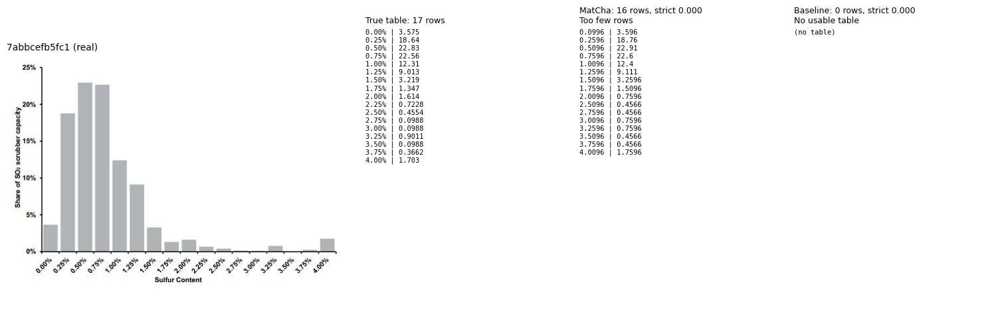

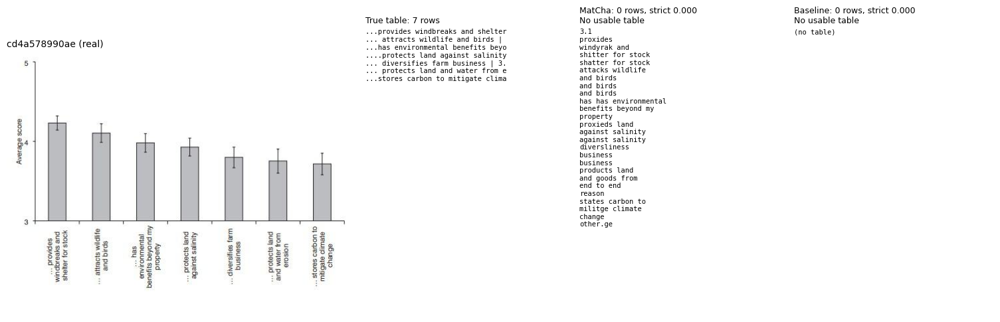

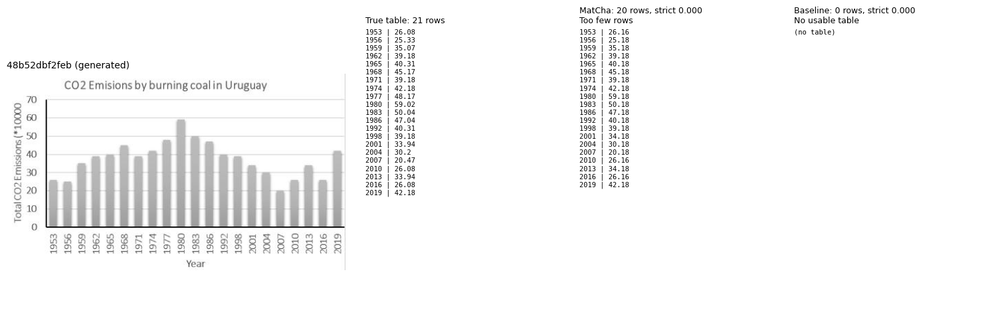

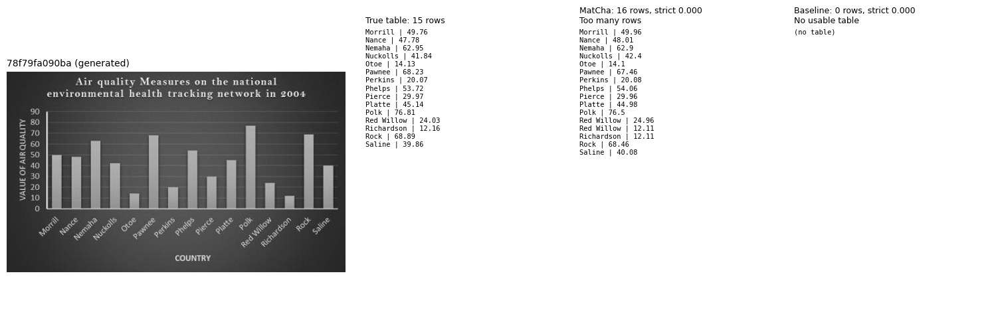

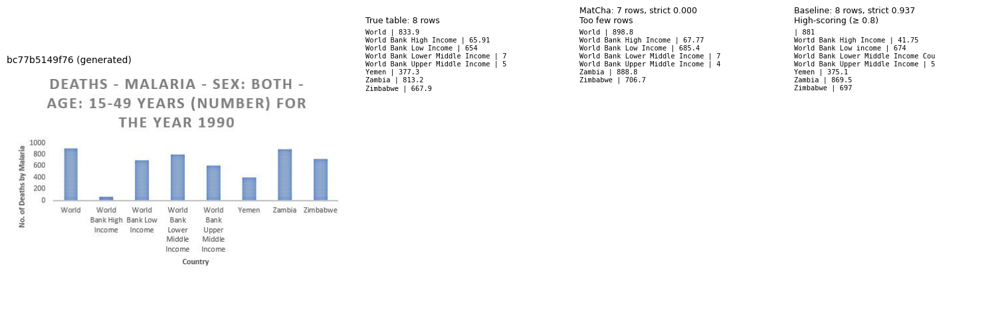

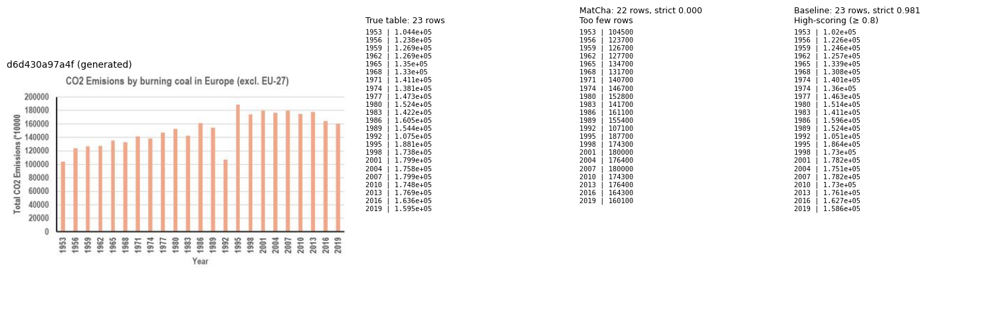


13c: largest baseline-minus-MatCha difference, not shown above: 3 charts


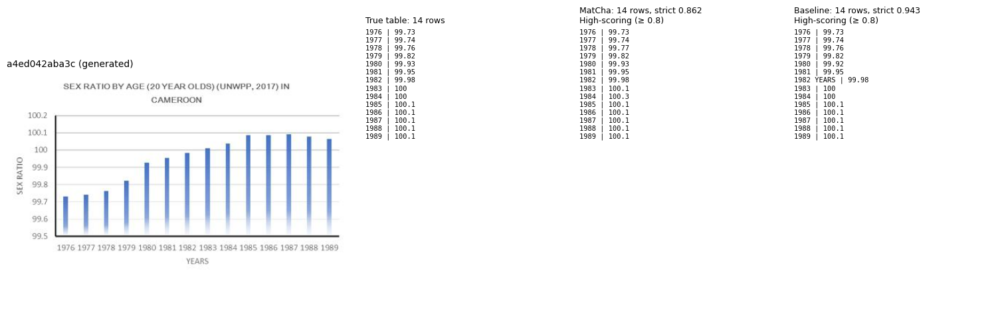

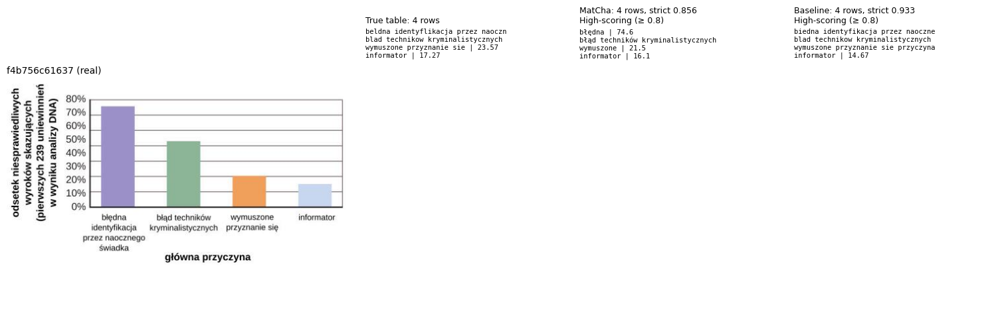

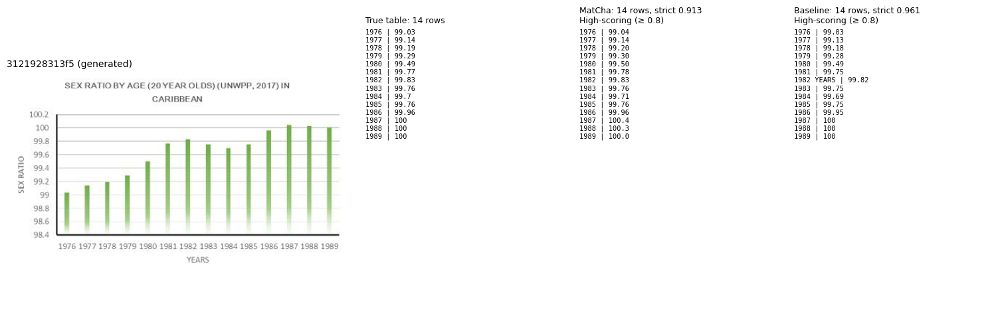


Baseline better than MatCha on 23 of 525 test charts.


In [4]:
output_banner("13b and 13c chart gallery")

import io, json, zipfile
import matplotlib.pyplot as plt
from PIL import Image

assert "pc13" in globals(), "Run 13a first."
te13 = pd.read_csv(RESULTS_DIR / "subset_3500" / "test_subset3500.csv").set_index("chart_id")
ZIP13 = KAGGLE_ZIP if KAGGLE_ZIP.is_file() else KAGGLE_ZIP_DRIVE

def rows_of(text, n=40):
    lines = [l.strip() for l in str(text).replace("<0x0A>", "\n").split("\n") if l.strip()]
    return lines[:n], len(lines)

def true_rows(z, member):
    ann = json.loads(z.read(member))
    return [f"{p['x']} | {p['y']:.4g}" if isinstance(p["y"], (int, float)) else f"{p['x']} | {p['y']}"
            for p in ann["data-series"]]

m13 = pc13["MatCha"].set_index("chart_id"); o13 = pc13["Baseline"].set_index("chart_id")
mt = pred13["MatCha"].set_index("chart_id"); ot = pred13["Baseline"].set_index("chart_id")

def show(ids, title):
    print(f"\n{title}: {len(ids)} charts")
    with zipfile.ZipFile(ZIP13) as z:
        for cid in ids:
            r = te13.loc[cid]
            img = Image.open(io.BytesIO(z.read(r["image_member"]))).convert("RGB")
            tr = true_rows(z, r["annotation_member"])
            mr, mn = rows_of(mt.loc[cid, "prediction_text"]); orow, on = rows_of(ot.loc[cid, "prediction_text"])
            fig = plt.figure(figsize=(18, 8.5))
            ax = fig.add_axes([0.0, 0.0, 0.42, 0.92]); ax.imshow(img); ax.axis("off")
            src = "real" if r["source"] == "extracted" else "generated"
            ax.set_title(f"{cid} ({src})", fontsize=14, loc="left")
            for j, (head, lines) in enumerate([
                    (f"True table: {len(tr)} rows", tr),
                    (f"MatCha: {m13.loc[cid, 'n_pred']} rows, strict {m13.loc[cid, 'strict_score']:.3f}\n"
                     f"{m13.loc[cid, 'category']}", mr),
                    (f"Baseline: {o13.loc[cid, 'n_pred']} rows, strict {o13.loc[cid, 'strict_score']:.3f}\n"
                     f"{o13.loc[cid, 'category']}", orow or ["(no table)"])]):
                tx = fig.add_axes([0.44 + j * 0.19, 0.0, 0.18, 0.92]); tx.axis("off")
                tx.set_title(head, fontsize=12, loc="left")
                tx.text(0, 1, "\n".join(l[:26] for l in lines[:26]) + ("\n…" if len(lines) > 26 else ""),
                        va="top", family="monospace", fontsize=11)
            plt.show()

zeros = m13[m13["strict_score"] == 0].copy()
zeros["baseline_score"] = o13.loc[zeros.index, "strict_score"]
zeros = zeros.sort_values(["baseline_score", "source"])          # both failed first
show(list(zeros.index), "13b: MatCha's zero-score test charts (both systems failed first)")

diff = (o13["strict_score"] - m13["strict_score"]).drop(zeros.index)
contrast = list(diff[diff > 0].sort_values(ascending=False).head(3).index)
show(contrast, "13c: largest baseline-minus-MatCha difference, not shown above")
print(f"\nBaseline better than MatCha on {int(((o13['strict_score'] - m13['strict_score']) > 0).sum())} of 525 test charts.")

### Step 13 result: where each system fails on the test set

**Categories (real / generated test charts):**

| Category | MatCha | Baseline |
|---|---|---|
| High-scoring (≥ 0.8) | **65 / 443** | 20 / 229 |
| No usable table | 1 / 0 | 26 / 104 |
| Too few rows | 1 / 3 | 12 / 64 |
| Too many rows | 0 / 1 | 3 / 3 |
| Right rows, labels weaker | 0 / 0 | 5 / 45 |
| Right rows, values weaker | 2 / 9 | 3 / 11 |

The cut-off does not change the picture: MatCha has 65 / 446 high-scoring charts at 0.7 and 60 / 435 at 0.9; the
baseline has 25 / 275 and 15 / 139.

**What was observed.**

* **MatCha's failures are row-count errors, not reading errors.** On the 519 charts it scored above zero, its label
  score is 0.9946 and its value score 0.9578, so labels are almost always right and values are slightly weaker.
  Of its 6 zero-score charts, 5 are off by exactly one row: two generated charts with long year axes skipped the
  year 1977, one generated chart wrote the label "Red Willow" twice, one real histogram with numeric bins wrote 16
  of 17 rows, and one generated chart wrote 7 of 8. The sixth, a real chart with long text labels, produced
  fragments with no table. No test chart hit the 864-token cap.
* **One real chart shows a symbol misread.** On the real histogram `7abbcefb5fc1`, MatCha wrote every "%" in the
  labels as the digits "96" (for example "0.25%" became "0.2596"), and it left out the 2.25% bin. From the 1.50% bin
  on, some values also end in "96" (for example 3.2596 where the true value is 3.219). Suspected, not tested: the
  model confuses the "%" sign with "96".
* **The baseline mostly fails before it reads anything.** Of its 212 zero-score charts, 114 had no bars found, 16
  had no value scale, 76 had too few bars and 6 too many. None of them had the right bar count.
* **Where the baseline wins.** It beat MatCha on 23 of 525 charts. The two largest wins are MatCha's off-by-one
  charts (baseline 0.981 and 0.937, MatCha 0). Outside MatCha's zeros, the baseline's largest wins are under 0.09.
* **Dense charts.** The 6 test charts with more than 20 bars average 0.636 for MatCha, well below its overall
  0.965.

**What is suspected, not tested.** Skipping a year on a long consecutive axis may come from the model losing its
place in a long, repetitive sequence. Real charts may defeat the baseline's rules because of more varied colours,
gridlines and fonts. Neither was tested.

**Nothing in Step 13 changed any model, setting or result.** The categories are descriptive, and 0.8 is a display
cut-off only.